# Online Retail II — Retail Sales & Customer Analytics

**Notebook 01 | Data exploration, customer segmentation, and clustering experiments**

This notebook analyzes the UCI Online Retail II transaction dataset. It documents the data-quality investigation, construction of the analytical dataset, sales and customer exploration, RFM scoring and segmentation, purchase-timing and purchase-behavior features, and comparative K-Means experiments.

## How to run this notebook

1. Create a `data/` folder in the repository root.
2. Place the original workbook at `data/online_retail_II.xlsx`.
3. Install the dependencies with `pip install -r requirements.txt`.
4. Run the notebook from top to bottom. The raw workbook is read-only; generated tables are written to `retail_final_outputs/`.

**Dependencies:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `openpyxl`, and Jupyter.

```bash
pip install -r requirements.txt
```

## Analytical workflow

1. Inspect the source worksheets and investigate data-quality issues.
2. Reconcile overlapping invoices and construct the analytical dataset.
3. Explore monthly sales and customer-level metrics.
4. Calculate and validate RFM scores, then define rule-based customer segments.
5. Evaluate RFM, Customer Value, Purchase Timing, and Purchase Behavior clustering perspectives.
6. Build and validate a customer master table and export analysis-ready files.

> **Reproducibility note:** The source workbook is not embedded in this notebook. Download it separately and keep it in the expected `data/` location. Generated exports are not required to rerun the analysis.

## 0. Environment and Source Data

The project root is detected so that the notebook can be run from either the repository root or the `notebooks/` directory. The workbook is loaded once; later sections reuse the two in-memory worksheets.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.preprocessing import RobustScaler, StandardScaler

# Locate the repository root from either the repository root or notebooks/.
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir():
            return candidate
    return start.parent if start.name.lower() == "notebooks" else start


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data"
DATA_PATH = DATA_DIR / "online_retail_II.xlsx"
OUTPUT_DIR = PROJECT_ROOT / "retail_final_outputs"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Download the UCI Online Retail II workbook and "
        f"place it at: {DATA_PATH.relative_to(PROJECT_ROOT)}"
    )

with pd.ExcelFile(DATA_PATH) as workbook:
    sheet_names = workbook.sheet_names
    if len(sheet_names) < 2:
        raise ValueError(
            "The Online Retail II workbook is expected to contain two worksheets."
        )
    sheet1 = pd.read_excel(workbook, sheet_name=0)
    sheet2 = pd.read_excel(workbook, sheet_name=1)

# Keep the original first-period frame as the starting point for initial inspection.
df = sheet1.copy()

print(f"Dataset loaded from: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Period 1 shape: {sheet1.shape}")
print(f"Period 2 shape: {sheet2.shape}")
print(f"Worksheet names: {sheet_names}")

Dataset loaded from: data\online_retail_II.xlsx
Period 1 shape: (525461, 8)
Period 2 shape: (541910, 8)
Worksheet names: ['Year 2009-2010', 'Year 2010-2011']


## 1. Initial Data Exploration

Inspect the first worksheet's structure, data types, missing values, duplicates, and transaction-value distributions.

In [2]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
df.shape

(525461, 8)

In [4]:
df.columns.tolist()

['Invoice',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'Price',
 'Customer ID',
 'Country']

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [6]:
missing_values = df.isna().sum()

print("Missing values per column:")
print(missing_values)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values per column:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Duplicate rows: 6865

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


In [7]:
df[["Quantity", "Price"]].describe()

,Quantity,Price
count,525461.000000,525461.000000
mean,10.337667,4.688834
std,107.424110,146.126914
min,-9600.000000,-53594.360000
25%,1.000000,1.250000
50%,3.000000,2.100000
75%,10.000000,4.210000
max,19152.000000,25111.090000


In [8]:
negative_price = df[df["Price"] < 0]

print("Rows with negative price:", len(negative_price))

negative_price.head(10)

Rows with negative price: 3


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [9]:
negative_quantity = df[df["Quantity"] < 0]

print("Rows with negative quantity:", len(negative_quantity))

negative_quantity.head(10)

Rows with negative quantity: 12326


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [10]:
cancelled_invoice = df[
    df["Invoice"].astype(str).str.startswith("C")
]

print("Rows with invoice starting C:", len(cancelled_invoice))

cancelled_invoice.head(10)

Rows with invoice starting C: 10206


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [11]:
quality_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (
        df.isna().mean() * 100
    ).round(2),
    "Data_Type": df.dtypes.astype(str)
})

quality_report

,Missing_Count,Missing_Percent,Data_Type
Invoice,0,0.00,object
StockCode,0,0.00,object
Description,2928,0.56,object
Quantity,0,0.00,int64
InvoiceDate,0,0.00,datetime64[us]
Price,0,0.00,float64
Customer ID,107927,20.54,float64
Country,0,0.00,str


In [12]:
negative_price = df["Price"] < 0

negative_quantity = df["Quantity"] < 0

cancelled_invoice = df["Invoice"].astype(str).str.startswith("C")

diagnostic_summary = pd.DataFrame({
    "Category": [
        "Negative price",
        "Negative quantity",
        "Invoice starts with C"
    ],
    "Row_Count": [
        negative_price.sum(),
        negative_quantity.sum(),
        cancelled_invoice.sum()
    ],
    "Percentage": [
        round(negative_price.mean() * 100, 2),
        round(negative_quantity.mean() * 100, 2),
        round(cancelled_invoice.mean() * 100, 2)
    ]
})

diagnostic_summary

,Category,Row_Count,Percentage
0,Negative price,3,0.00
1,Negative quantity,12326,2.35
2,Invoice starts with C,10206,1.94


In [13]:
df.loc[
    df["Price"] < 0,
    ["Invoice", "StockCode", "Description", "Quantity", "Price"]
]["Description"].value_counts(dropna=False)

Description
Adjust bad debt    3
Name: count, dtype: int64

In [14]:
diagnostic_comparison = pd.DataFrame({
    "Condition": [
        "Negative quantity AND invoice starts with C",
        "Negative quantity AND invoice does not start with C",
        "Non-negative quantity AND invoice starts with C",
        "Negative price"
    ],
    "Row_Count": [
        (negative_quantity & cancelled_invoice).sum(),
        (negative_quantity & ~cancelled_invoice).sum(),
        ((~negative_quantity) & cancelled_invoice).sum(),
        (df["Price"] < 0).sum()
    ]
})

diagnostic_comparison

,Condition,Row_Count
0,Negative quantity AND invoice starts with C,10205
1,Negative quantity AND invoice does not start w...,2121
2,Non-negative quantity AND invoice starts with C,1
3,Negative price,3


In [15]:
def profile_sheet(data, sheet_name):
    print(f"\n--- {sheet_name} ---")
    print("Shape:", data.shape)
    print("\nMissing values:")
    print(data.isna().sum())
    print("\nDuplicate rows:", data.duplicated().sum())
    print("\nNegative quantities:", (data["Quantity"] < 0).sum())
    print("Negative prices:", (data["Price"] < 0).sum())
    print(
        "Invoices starting with C:",
        data["Invoice"].astype(str).str.startswith("C").sum()
    )

profile_sheet(sheet1, "Sheet 1")
profile_sheet(sheet2, "Sheet 2")


--- Sheet 1 ---
Shape: (525461, 8)

Missing values:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Duplicate rows: 6865

Negative quantities: 12326
Negative prices: 3
Invoices starting with C: 10206

--- Sheet 2 ---
Shape: (541910, 8)

Missing values:
Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

Duplicate rows: 5268

Negative quantities: 10624
Negative prices: 2
Invoices starting with C: 9288


## 2. Duplicate and Cancellation Investigation

Examine exact duplicates, repeated invoice–product combinations, cancellation-marked invoices, and candidate links between positive and negative transaction lines. The goal is to understand the records before deciding how to build the analytical dataset.

In [16]:
duplicates_1 = sheet1[
    sheet1.duplicated(keep=False)
].sort_values(
    by=["Invoice", "StockCode", "InvoiceDate"]
)

display(duplicates_1.head(20))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [17]:
duplicates_2 = sheet2[
    sheet2.duplicated(keep=False)
].sort_values(
    by=["Invoice", "StockCode", "InvoiceDate"]
)

display(duplicates_2.head(20))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [18]:
for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]:
    print(f"\n{name}")

    same_invoice_product = data.duplicated(
        subset=["Invoice", "StockCode"],
        keep=False
    )

    print(
        "Rows sharing Invoice + StockCode:",
        same_invoice_product.sum()
    )

    unique_pairs = data[
        ["Invoice", "StockCode"]
    ].drop_duplicates().shape[0]

    print("Unique Invoice-StockCode pairs:", unique_pairs)


Period 1
Rows sharing Invoice + StockCode: 25399
Unique Invoice-StockCode pairs: 512126

Period 2
Rows sharing Invoice + StockCode: 20378
Unique Invoice-StockCode pairs: 531226


In [19]:
for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]:
    print(f"\n{name}")

    repeated = data[
        data.duplicated(
            subset=["Invoice", "StockCode"],
            keep=False
        )
    ]

    repeated_pairs = repeated[
        ["Invoice", "StockCode"]
    ].drop_duplicates().shape[0]

    print("Repeated Invoice-StockCode combinations:", repeated_pairs)

    variation = repeated.groupby(
        ["Invoice", "StockCode"]
    ).agg(
        row_count=("Quantity", "size"),
        quantity_variants=("Quantity", "nunique"),
        price_variants=("Price", "nunique"),
        description_variants=("Description", "nunique"),
        customer_variants=("Customer ID", "nunique")
    )

    print(
        "Combinations with different quantities:",
        (variation["quantity_variants"] > 1).sum()
    )

    print(
        "Combinations with different prices:",
        (variation["price_variants"] > 1).sum()
    )

    print(
        "Combinations with different descriptions:",
        (variation["description_variants"] > 1).sum()
    )

    print(
        "Combinations with different customer IDs:",
        (variation["customer_variants"] > 1).sum()
    )


Period 1
Repeated Invoice-StockCode combinations: 12064
Combinations with different quantities: 6138
Combinations with different prices: 430
Combinations with different descriptions: 0
Combinations with different customer IDs: 0

Period 2
Repeated Invoice-StockCode combinations: 9694
Combinations with different quantities: 5084
Combinations with different prices: 528
Combinations with different descriptions: 2
Combinations with different customer IDs: 0


In [20]:
for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]:
    print(f"\n{name}")

    repeated = data[
        data.duplicated(
            subset=["Invoice", "StockCode"],
            keep=False
        )
    ]

    variation = repeated.groupby(
        ["Invoice", "StockCode"]
    ).agg(
        quantity_variants=("Quantity", "nunique"),
        price_variants=("Price", "nunique"),
        description_variants=("Description", "nunique")
    )

    interesting_pairs = variation[
        (variation["price_variants"] > 1)
        | (variation["description_variants"] > 1)
    ].index

    sample = (
        repeated.set_index(["Invoice", "StockCode"])
        .loc[interesting_pairs]
        .reset_index()
    )

    print(sample.head(15).to_string(index=False))


Period 1
Invoice StockCode                       Description  Quantity         InvoiceDate  Price  Customer ID        Country
 489560     35955  SMALL FOLKART CHRISTMAS TREE DEC        33 2009-12-01 12:56:00   0.42      13526.0 United Kingdom
 489560     35955  SMALL FOLKART CHRISTMAS TREE DEC        96 2009-12-01 12:56:00   0.19      13526.0 United Kingdom
 489597     22111      SCOTTIE DOG HOT WATER BOTTLE         1 2009-12-01 14:28:00   8.65          NaN United Kingdom
 489597     22111      SCOTTIE DOG HOT WATER BOTTLE         4 2009-12-01 14:28:00  11.26          NaN United Kingdom
 489856     22111      SCOTTIE DOG HOT WATER BOTTLE         5 2009-12-02 14:36:00   8.65          NaN United Kingdom
 489856     22111      SCOTTIE DOG HOT WATER BOTTLE         5 2009-12-02 14:36:00  11.26          NaN United Kingdom
 490074     22111      SCOTTIE DOG HOT WATER BOTTLE         1 2009-12-03 14:39:00   8.65          NaN United Kingdom
 490074     22111      SCOTTIE DOG HOT WATER BOTTLE   

In [21]:
for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]:
    print(f"\n{name}")

    repeated = data[
        data.duplicated(
            subset=["Invoice", "StockCode"],
            keep=False
        )
    ].copy()

    variation = repeated.groupby(
        ["Invoice", "StockCode"]
    ).agg(
        price_variants=("Price", "nunique"),
        description_variants=("Description", "nunique")
    )

    interesting_pairs = variation[
        (variation["price_variants"] > 1)
        | (variation["description_variants"] > 1)
    ].index

    sample = (
        repeated.set_index(["Invoice", "StockCode"])
        .loc[interesting_pairs]
        .reset_index()
    )

    sample["LineValue"] = sample["Quantity"] * sample["Price"]

    print(
        sample[
            [
                "Invoice",
                "StockCode",
                "Quantity",
                "Price",
                "LineValue",
                "Customer ID"
            ]
        ].head(20).to_string(index=False)
    )


Period 1
Invoice StockCode  Quantity  Price  LineValue  Customer ID
 489560     35955        33   0.42      13.86      13526.0
 489560     35955        96   0.19      18.24      13526.0
 489597     22111         1   8.65       8.65          NaN
 489597     22111         4  11.26      45.04          NaN
 489856     22111         5   8.65      43.25          NaN
 489856     22111         5  11.26      56.30          NaN
 490074     22111         1   8.65       8.65          NaN
 490074     22111         4  11.26      45.04          NaN
 490074     22111         2   8.65      17.30          NaN
 490149     22111         2   8.65      17.30          NaN
 490149     22111         1   8.65       8.65          NaN
 490149     22111         5  11.26      56.30          NaN
 490300         M         1   0.85       0.85      12970.0
 490300         M         1   0.21       0.21      12970.0
 490488     21488         7   3.95      27.65      16718.0
 490488     21488        24   3.45      82.80 

In [22]:
for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]:
    print(f"\n{name}")

    duplicate_mask = data.duplicated(keep=False)

    duplicates = data[duplicate_mask].copy()

    cancelled_mask = (
        duplicates["Invoice"]
        .astype(str)
        .str.startswith("C")
    )

    print("Rows belonging to exact-duplicate groups:", len(duplicates))
    print("Rows in cancellation invoices:", cancelled_mask.sum())
    print(
        "Rows in non-cancellation invoices:",
        (~cancelled_mask).sum()
    )

    print("\nSample exact duplicates:")
    print(
        data[data.duplicated(keep=False)]
        .sort_values(["Invoice", "StockCode"])
        .head(10)
        .to_string(index=False)
    )


Period 1
Rows belonging to exact-duplicate groups: 13283
Rows in cancellation invoices: 47
Rows in non-cancellation invoices: 13236

Sample exact duplicates:
Invoice StockCode                      Description  Quantity         InvoiceDate  Price  Customer ID        Country
 489517     21491  SET OF THREE VINTAGE GIFT WRAPS         1 2009-12-01 11:34:00   1.95      16329.0 United Kingdom
 489517     21491  SET OF THREE VINTAGE GIFT WRAPS         1 2009-12-01 11:34:00   1.95      16329.0 United Kingdom
 489517     21821 GLITTER STAR GARLAND WITH BELLS          1 2009-12-01 11:34:00   3.75      16329.0 United Kingdom
 489517     21821 GLITTER STAR GARLAND WITH BELLS          1 2009-12-01 11:34:00   3.75      16329.0 United Kingdom
 489517     21912         VINTAGE SNAKES & LADDERS         1 2009-12-01 11:34:00   3.75      16329.0 United Kingdom
 489517     21912         VINTAGE SNAKES & LADDERS         1 2009-12-01 11:34:00   3.75      16329.0 United Kingdom
 489517     21912         VIN

In [23]:
for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]:
    print(f"\n{name}")

    original_value = (data["Quantity"] * data["Price"]).sum()


    deduplicated = data.drop_duplicates()

    deduplicated_value = (
        deduplicated["Quantity"] * deduplicated["Price"]
    ).sum()

    print("Original rows:", len(data))
    print("Rows after hypothetical deduplication:", len(deduplicated))
    print("Rows that would be removed:", len(data) - len(deduplicated))

    print("Original net line value:", round(original_value, 2))
    print("Net line value after deduplication:", round(deduplicated_value, 2))
    print(
        "Difference in net line value:",
        round(original_value - deduplicated_value, 2)

    )


Period 1
Original rows: 525461
Rows after hypothetical deduplication: 518596
Rows that would be removed: 6865
Original net line value: 9539484.63
Net line value after deduplication: 9505775.56
Difference in net line value: 33709.07

Period 2
Original rows: 541910
Rows after hypothetical deduplication: 536642
Rows that would be removed: 5268
Original net line value: 9747765.93
Net line value after deduplication: 9726024.95
Difference in net line value: 21740.98


In [24]:
sample_invoices = {
    "Period 1": ["489517"],
    "Period 2": ["536409"]
}

for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]:
    print(f"\n{'=' * 60}")
    print(name)

    selected_invoices = sample_invoices[name]

    subset = data[
        data["Invoice"].astype(str).isin(selected_invoices)
    ].copy()

    subset["LineValue"] = subset["Quantity"] * subset["Price"]

    exact_groups = (
        subset.groupby(
            list(data.columns),
            dropna=False
        )
        .size()
        .reset_index(name="Occurrences")
    )

    repeated_groups = exact_groups[
        exact_groups["Occurrences"] > 1
    ].copy()

    repeated_groups["LineValueEach"] = (
        repeated_groups["Quantity"] * repeated_groups["Price"]
    )

    repeated_groups["ExtraRows"] = (
        repeated_groups["Occurrences"] - 1
    )

    repeated_groups["ExtraValue"] = (
        repeated_groups["LineValueEach"]
        * repeated_groups["ExtraRows"]
    )

    print("Total invoice rows:", len(subset))
    print(
        "Exact duplicate groups:",
        len(repeated_groups)
    )
    print(
        "Extra repeated rows:",
        repeated_groups["ExtraRows"].sum()
    )
    print(
        "Total invoice line value:",
        round(subset["LineValue"].sum(), 2)
    )
    print(
        "Value of extra identical occurrences:",
        round(repeated_groups["ExtraValue"].sum(), 2)
    )

    print("\nRepeated groups:")
    if len(repeated_groups) > 0:
        print(
            repeated_groups[
                [
                    "Invoice",
                    "StockCode",
                    "Description",
                    "Quantity",
                    "Price",
                    "Occurrences",
                    "ExtraRows",
                    "ExtraValue"
                ]
            ].to_string(index=False)
        )
    else:
        print("No exact duplicate groups found.")


Period 1
Total invoice rows: 38
Exact duplicate groups: 7
Extra repeated rows: 8
Total invoice line value: 282.46
Value of extra identical occurrences: 32.4

Repeated groups:
 Invoice StockCode                       Description  Quantity  Price  Occurrences  ExtraRows  ExtraValue
  489517     21491   SET OF THREE VINTAGE GIFT WRAPS         1   1.95            2          1        1.95
  489517     21821  GLITTER STAR GARLAND WITH BELLS          1   3.75            2          1        3.75
  489517     21912          VINTAGE SNAKES & LADDERS         1   3.75            3          2        7.50
  489517     21913    VINTAGE SEASIDE JIGSAW PUZZLES         1   3.75            2          1        3.75
  489517     22130  PARTY CONE CHRISTMAS DECORATION          6   0.85            2          1        5.10
  489517     22319 HAIRCLIPS FORTIES FABRIC ASSORTED        12   0.65            2          1        7.80
  489517    84951A   S/4 PISTACHIO LOVEBIRD COASTERS         1   2.55            2

In [25]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

for name, data in periods:
    # Scenario A: original data
    original_rows = len(data)
    original_invoices = data["Invoice"].nunique()
    original_value = (data["Quantity"] * data["Price"]).sum()

    scenario_b = data.drop_duplicates().copy()

    cleaned_rows = len(scenario_b)
    cleaned_invoices = scenario_b["Invoice"].nunique()
    cleaned_value = (
        scenario_b["Quantity"] * scenario_b["Price"]
    ).sum()

    print(f"\n{'=' * 55}")
    print(name)

    print("\nScenario A - Original data")
    print("Rows:", original_rows)
    print("Unique invoices:", original_invoices)
    print("Net line value:", round(original_value, 2))

    print("\nScenario B - Hypothetical deduplication")
    print("Rows:", cleaned_rows)
    print("Unique invoices:", cleaned_invoices)
    print("Net line value:", round(cleaned_value, 2))

    print("\nDifference (A - B)")
    print("Rows removed:", original_rows - cleaned_rows)
    print("Invoice count difference:",
          original_invoices - cleaned_invoices)
    print("Net line value difference:",
          round(original_value - cleaned_value, 2))


Period 1

Scenario A - Original data
Rows: 525461
Unique invoices: 28816
Net line value: 9539484.63

Scenario B - Hypothetical deduplication
Rows: 518596
Unique invoices: 28816
Net line value: 9505775.56

Difference (A - B)
Rows removed: 6865
Invoice count difference: 0
Net line value difference: 33709.07

Period 2

Scenario A - Original data
Rows: 541910
Unique invoices: 25900
Net line value: 9747765.93

Scenario B - Hypothetical deduplication
Rows: 536642
Unique invoices: 25900
Net line value: 9726024.95

Difference (A - B)
Rows removed: 5268
Invoice count difference: 0
Net line value difference: 21740.98


In [26]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

def analyze_scenario(data):
    df = data.copy()

    invoice_text = df["Invoice"].astype(str)
    is_cancelled = invoice_text.str.startswith("C")

    line_value = df["Quantity"] * df["Price"]

    positive_qty = df["Quantity"] > 0
    negative_qty = df["Quantity"] < 0
    zero_qty = df["Quantity"] == 0

    return {
        "Rows": len(df),
        "Positive quantity rows": int(positive_qty.sum()),
        "Negative quantity rows": int(negative_qty.sum()),
        "Zero quantity rows": int(zero_qty.sum()),

        "Cancellation-marked invoice rows": int(is_cancelled.sum()),
        "Unique cancellation-marked invoices": int(
            df.loc[is_cancelled, "Invoice"].nunique()
        ),

        "Positive quantity line value": round(
            line_value[positive_qty].sum(), 2
        ),
        "Negative quantity line value": round(
            line_value[negative_qty].sum(), 2
        ),
        "Zero quantity line value": round(
            line_value[zero_qty].sum(), 2
        ),
        "Net line value": round(line_value.sum(), 2),

        "Cancellation-marked invoice line value": round(
            line_value[is_cancelled].sum(), 2
        ),
        "Other invoice line value": round(
            line_value[~is_cancelled].sum(), 2
        )
    }


for period_name, data in periods:
    original = analyze_scenario(data)

    deduplicated_data = data.drop_duplicates().copy()
    deduplicated = analyze_scenario(deduplicated_data)

    print("\n" + "=" * 65)
    print(period_name)

    for metric in original:
        value_a = original[metric]
        value_b = deduplicated[metric]

        print(f"\n{metric}")
        print(f"  Scenario A - Original: {value_a}")
        print(f"  Scenario B - Deduplicated: {value_b}")

        if isinstance(value_a, (int, float)):
            print(f"  Difference (A - B): {round(value_a - value_b, 2)}")

    print("\nRows removed:", len(data) - len(deduplicated_data))


Period 1

Rows
  Scenario A - Original: 525461
  Scenario B - Deduplicated: 518596
  Difference (A - B): 6865

Positive quantity rows
  Scenario A - Original: 513135
  Scenario B - Deduplicated: 506294
  Difference (A - B): 6841

Negative quantity rows
  Scenario A - Original: 12326
  Scenario B - Deduplicated: 12302
  Difference (A - B): 24

Zero quantity rows
  Scenario A - Original: 0
  Scenario B - Deduplicated: 0
  Difference (A - B): 0

Cancellation-marked invoice rows
  Scenario A - Original: 10206
  Scenario B - Deduplicated: 10182
  Difference (A - B): 24

Unique cancellation-marked invoices
  Scenario A - Original: 4592
  Scenario B - Deduplicated: 4592
  Difference (A - B): 0

Positive quantity line value
  Scenario A - Original: 10169713.57
  Scenario B - Deduplicated: 10135584.21
  Difference (A - B): 34129.36

Negative quantity line value
  Scenario A - Original: -630228.94
  Scenario B - Deduplicated: -629808.65
  Difference (A - B): -420.29

Zero quantity line value
  

In [27]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

for period_name, data in periods:
    print("\n" + "=" * 70)
    print(period_name)


    scenarios = {
        "A - Original": data,
        "B - Deduplicated": data.drop_duplicates().copy()
    }

    results = {}

    for scenario_name, df in scenarios.items():
        line_value = df["Quantity"] * df["Price"]

        positive_rows = df["Quantity"] > 0

        results[scenario_name] = {
            "rows": len(df),
            "customers": df["Customer ID"].nunique(),
            "products": df["StockCode"].nunique(),
            "value": line_value.sum()
        }

        print(f"\n{scenario_name}")
        print("Rows:", results[scenario_name]["rows"])
        print("Unique customers:", results[scenario_name]["customers"])
        print("Unique products:", results[scenario_name]["products"])

        product_sales = (
            df.loc[positive_rows]
            .assign(LineValue=line_value[positive_rows])
            .groupby("StockCode", dropna=False)
            .agg(
                PositiveQuantity=("Quantity", "sum"),
                PositiveLineValue=("LineValue", "sum")
            )
            .sort_values("PositiveLineValue", ascending=False)
        )

        print("\nTop 10 products by positive line value:")
        print(product_sales.head(10).round(2).to_string())

    print("\nScenario differences (A - B)")
    print(
        "Unique customer difference:",
        results["A - Original"]["customers"]
        - results["B - Deduplicated"]["customers"]
    )
    print(
        "Unique product difference:",
        results["A - Original"]["products"]
        - results["B - Deduplicated"]["products"]
    )


Period 1

A - Original
Rows: 525461
Unique customers: 4383
Unique products: 4632

Top 10 products by positive line value:
           PositiveQuantity  PositiveLineValue
StockCode                                     
M                      2828          262979.58
22423                 13704          170078.51
85123A                58488          158590.87
DOT                    1233          116408.71
85099B                49878           89114.78
84879                 45356           73092.99
22086                 17255           58189.25
47566                 10127           49682.72
POST                   3910           49477.54
84347                 23162           47985.09

B - Deduplicated
Rows: 518596
Unique customers: 4383
Unique products: 4632

Top 10 products by positive line value:
           PositiveQuantity  PositiveLineValue
StockCode                                     
M                      2766          262950.93
22423                 13691          169912.76
85123A  

In [28]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

special_codes = ["M", "POST", "DOT", "D", "C2"]

for period_name, data in periods:
    print("\n" + "=" * 70)
    print(period_name)

    for code in special_codes:
        subset = data[
            data["StockCode"].astype(str).str.strip().str.upper() == code
        ]

        if subset.empty:
            print(f"\n{code}: No rows found")
            continue

        line_value = subset["Quantity"] * subset["Price"]

        print(f"\nStockCode: {code}")
        print("Rows:", len(subset))
        print("Descriptions:")
        print(subset["Description"].value_counts(dropna=False).head(10))
        print("Total quantity:", subset["Quantity"].sum())
        print("Unique invoices:", subset["Invoice"].nunique())
        print("Unique customers:", subset["Customer ID"].nunique())
        print("Net line value:", round(line_value.sum(), 2))
        print("Positive-quantity line value:", round(
            line_value[subset["Quantity"] > 0].sum(), 2
        ))
        print("Negative-quantity rows:", int(
            (subset["Quantity"] < 0).sum()
        ))


Period 1

StockCode: M
Rows: 854
Descriptions:
Description
Manual    854
Name: count, dtype: int64
Total quantity: 1447
Unique invoices: 792
Unique customers: 367
Net line value: -14109.63
Positive-quantity line value: 262992.08
Negative-quantity rows: 293

StockCode: POST
Rows: 865
Descriptions:
Description
POSTAGE    862
NaN          3
Name: count, dtype: int64
Total quantity: 3754
Unique invoices: 865
Unique customers: 278
Net line value: 46092.36
Positive-quantity line value: 49477.54
Negative-quantity rows: 103

StockCode: DOT
Rows: 736
Descriptions:
Description
DOTCOM POSTAGE    735
NaN                 1
Name: count, dtype: int64
Total quantity: 1231
Unique invoices: 736
Unique customers: 0
Net line value: 116401.99
Positive-quantity line value: 116408.71
Negative-quantity rows: 2

StockCode: D
Rows: 100
Descriptions:
Description
Discount    100
Name: count, dtype: int64
Total quantity: -1678
Unique invoices: 90
Unique customers: 43
Net line value: -7788.32
Positive-quantity lin

In [29]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

special_codes = ["M", "POST", "DOT", "D", "C2"]

sample_columns = [
    "Invoice",
    "InvoiceDate",
    "StockCode",
    "Description",
    "Quantity",
    "Price",
    "Customer ID"
]

for period_name, data in periods:
    print("\n" + "=" * 90)
    print(period_name)

    df = data.copy()

    df["StockCode"] = (
        df["StockCode"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    df["InvoiceText"] = df["Invoice"].astype(str)
    df["LineValue"] = df["Quantity"] * df["Price"]

    df["InvoiceType"] = "Regular"
    df.loc[
        df["InvoiceText"].str.startswith("C"),
        "InvoiceType"
    ] = "Cancellation-marked"

    for code in special_codes:
        subset = df.loc[df["StockCode"] == code].copy()

        if subset.empty:
            print(f"\n{code}: No rows found")
            continue

        print("\n" + "-" * 70)
        print(f"StockCode: {code} | Total rows: {len(subset)}")

        categories = {
            "Positive quantity": subset["Quantity"] > 0,
            "Negative quantity": subset["Quantity"] < 0,
            "Cancellation-marked invoice": (
                subset["InvoiceText"].str.startswith("C")
            ),
            "Missing customer ID": subset["Customer ID"].isna()
        }

        for category_name, mask in categories.items():
            sample = subset.loc[mask]

            if sample.empty:
                print(f"\n{category_name}: No samples found")
                continue

            sample = (
                sample
                .drop_duplicates(subset=["Invoice"])
                .head(2)
            )

            print(f"\n{category_name}:")
            print(
                sample[
                    sample_columns + ["LineValue", "InvoiceType"]
                ].to_string(index=False)
            )


Period 1

----------------------------------------------------------------------
StockCode: M | Total rows: 854

Positive quantity:
Invoice         InvoiceDate StockCode Description  Quantity  Price  Customer ID  LineValue InvoiceType
 489609 2009-12-01 14:50:00         M      Manual         1   4.00          NaN       4.00     Regular
 490300 2009-12-04 14:19:00         M      Manual         1   0.85      12970.0       0.85     Regular

Negative quantity:
Invoice         InvoiceDate StockCode Description  Quantity  Price  Customer ID  LineValue         InvoiceType
C489651 2009-12-01 16:48:00         M      Manual        -1   5.10      17804.0      -5.10 Cancellation-marked
C489859 2009-12-02 14:45:00         M      Manual        -1  69.57          NaN     -69.57 Cancellation-marked

Cancellation-marked invoice:
Invoice         InvoiceDate StockCode Description  Quantity  Price  Customer ID  LineValue         InvoiceType
C489651 2009-12-01 16:48:00         M      Manual        -1   5.

In [30]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

selected_invoices = {
    "Period 1": {
        "M": ["489609", "C489651"],
        "POST": ["489439", "C489538"],
        "DOT": ["489597", "C516128"],
        "D": ["504700", "C489535"],
        "C2": ["490127", "C500494"]
    },
    "Period 2": {
        "M": ["536569", "C537610"],
        "POST": ["536370", "C537414"],
        "DOT": ["536544", "C542540"],
        "D": ["C536379"],
        "C2": ["536540", "C540164"]
    }
}

display_columns = [
    "Invoice",
    "InvoiceDate",
    "StockCode",
    "Description",
    "Quantity",
    "Price",
    "Customer ID"
]

for period_name, data in periods:
    print("\n" + "=" * 100)
    print(period_name)

    df = data.copy()
    df["InvoiceText"] = df["Invoice"].astype(str).str.strip()
    df["LineValue"] = df["Quantity"] * df["Price"]

    for code, invoice_list in selected_invoices[period_name].items():
        for invoice_id in invoice_list:
            invoice_rows = df.loc[
                df["InvoiceText"] == invoice_id
            ].copy()

            print("\n" + "-" * 80)
            print(f"StockCode: {code} | Invoice: {invoice_id}")

            if invoice_rows.empty:
                print("Invoice not found.")
                continue

            invoice_rows["IsTargetCode"] = (
                invoice_rows["StockCode"]
                .astype("string")
                .str.strip()
                .str.upper()
                .eq(code)
            )

            print("Total invoice rows:", len(invoice_rows))
            print(
                "Target code rows:",
                int(invoice_rows["IsTargetCode"].sum())
            )
            print(
                invoice_rows[
                    display_columns + ["LineValue", "IsTargetCode"]
                ].to_string(index=False)
            )

            print(
                "Invoice net line value:",
                round(invoice_rows["LineValue"].sum(), 2)
            )


Period 1

--------------------------------------------------------------------------------
StockCode: M | Invoice: 489609
Total invoice rows: 37
Target code rows: 1
Invoice         InvoiceDate StockCode                         Description  Quantity  Price  Customer ID  LineValue  IsTargetCode
 489609 2009-12-01 14:50:00     79072        TEATIME CAKE TIN WITH HANDLE         1  17.35          NaN      17.35         False
 489609 2009-12-01 14:50:00    84029G KNITTED UNION FLAG HOT WATER BOTTLE         1   7.78          NaN       7.78         False
 489609 2009-12-01 14:50:00     84347 ROTATING SILVER ANGELS T-LIGHT HLDR         2   5.17          NaN      10.34         False
 489609 2009-12-01 14:50:00    84796b   BLUE SAVANNAH PICNIC HAMPER FOR 2         1   8.65          NaN       8.65         False
 489609 2009-12-01 14:50:00    84873a       FUNKY FLOWER PICNIC BAG FOR 4         1  11.26          NaN      11.26         False
 489609 2009-12-01 14:50:00    85040a     S/4 PINK FLOWER CA

In [31]:
invoices_to_check = [
    ("Period 1", sheet1, "489597"),
    ("Period 2", sheet2, "536544")
]

for period_name, data, invoice_id in invoices_to_check:
    df = data.copy()
    df["InvoiceText"] = df["Invoice"].astype(str).str.strip()
    df["LineValue"] = df["Quantity"] * df["Price"]

    invoice = df.loc[df["InvoiceText"] == invoice_id].copy()

    print("\n" + "=" * 70)
    print("Period:", period_name)
    print("Invoice:", invoice_id)
    print("Rows:", len(invoice))
    print("Unique stock codes:", invoice["StockCode"].nunique())
    print("Unique descriptions:", invoice["Description"].nunique())
    print("Unique customer IDs:", invoice["Customer ID"].nunique())
    print("Missing customer IDs:", int(invoice["Customer ID"].isna().sum()))
    print("Positive quantity rows:", int((invoice["Quantity"] > 0).sum()))
    print("Negative quantity rows:", int((invoice["Quantity"] < 0).sum()))
    print("Net line value:", round(invoice["LineValue"].sum(), 2))

    print("\nMost frequent descriptions:")
    print(
        invoice["Description"]
        .value_counts(dropna=False)
        .head(10)
        .to_string()
    )

    print("\nTarget code rows:")
    print(
        invoice.loc[
            invoice["StockCode"].astype(str).str.strip().str.upper().isin(
                ["M", "POST", "DOT", "D", "C2"]
            ),
            ["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID", "LineValue"]
        ].to_string(index=False)
    )


Period: Period 1
Invoice: 489597
Rows: 502
Unique stock codes: 501
Unique descriptions: 501
Unique customer IDs: 0
Missing customer IDs: 502
Positive quantity rows: 502
Negative quantity rows: 0
Net line value: 5097.82

Most frequent descriptions:
Description
SCOTTIE DOG HOT WATER BOTTLE           2
ORIGAMI VANILLA INCENSE/CANDLE SET     1
CLEAR COLOUR GLASS GEMS IN BAG         1
CHERRY BLOSSOM PASSPORT COVER          1
QUEEN OF THE SKIES PASSPORT COVER      1
BLUE SPOTTY LUGGAGE TAG                1
FIRST CLASS LUGGAGE TAG                1
QUEEN OF SKIES LUGGAGE TAG             1
ECONOMY LUGGAGE TAG                    1
GREEN SPOTTY BOWL                      1

Target code rows:
Invoice StockCode    Description  Quantity  Price  Customer ID  LineValue
 489597       DOT DOTCOM POSTAGE         1 647.19          NaN     647.19

Period: Period 2
Invoice: 536544
Rows: 527
Unique stock codes: 523
Unique descriptions: 522
Unique customer IDs: 0
Missing customer IDs: 527
Positive quantity ro

In [32]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

invoice_sets = {}

for period_name, data in periods:
    invoice_text = data["Invoice"].astype("string").str.strip()
    invoice_sets[period_name] = set(invoice_text.dropna())

period_1_invoices = invoice_sets["Period 1"]
period_2_invoices = invoice_sets["Period 2"]

common_invoices = period_1_invoices & period_2_invoices

print("Period 1 unique invoice numbers:", len(period_1_invoices))
print("Period 2 unique invoice numbers:", len(period_2_invoices))
print("Invoice numbers appearing in both periods:", len(common_invoices))

print("\nSample overlapping invoice numbers:")
print(sorted(common_invoices)[:30])

Period 1 unique invoice numbers: 28816
Period 2 unique invoice numbers: 25900
Invoice numbers appearing in both periods: 1088

Sample overlapping invoice numbers:
['536365', '536366', '536367', '536368', '536369', '536370', '536371', '536372', '536373', '536374', '536375', '536376', '536377', '536378', '536380', '536381', '536382', '536384', '536385', '536386', '536387', '536388', '536389', '536390', '536392', '536393', '536394', '536395', '536396', '536397']


In [33]:
def summarize_invoices(data, invoice_numbers, period_name):
    df = data.copy()
    df["InvoiceText"] = df["Invoice"].astype("string").str.strip()
    df["LineValue"] = df["Quantity"] * df["Price"]

    result = (
        df[df["InvoiceText"].isin(invoice_numbers)]
        .groupby("InvoiceText", dropna=False)
        .agg(
            Rows=("InvoiceText", "size"),
            FirstDate=("InvoiceDate", "min"),
            LastDate=("InvoiceDate", "max"),
            UniqueStockCodes=("StockCode", "nunique"),
            MissingCustomerID=("Customer ID", lambda x: x.isna().sum()),
            NetLineValue=("LineValue", "sum")
        )
        .reset_index()
    )

    result["Period"] = period_name
    return result


summary_1 = summarize_invoices(sheet1, common_invoices, "Period 1")
summary_2 = summarize_invoices(sheet2, common_invoices, "Period 2")

overlap_details = pd.concat(
    [summary_1, summary_2],
    ignore_index=True
)

print("Overlapping invoice details:")
print(
    overlap_details
    .sort_values(["InvoiceText", "Period"])
    .head(100)
    .round({"NetLineValue": 2})
    .to_string(index=False)
)

Overlapping invoice details:
InvoiceText  Rows           FirstDate            LastDate  UniqueStockCodes  MissingCustomerID  NetLineValue   Period
     536365     7 2010-12-01 08:26:00 2010-12-01 08:26:00                 7                  0        139.12 Period 1
     536365     7 2010-12-01 08:26:00 2010-12-01 08:26:00                 7                  0        139.12 Period 2
     536366     2 2010-12-01 08:28:00 2010-12-01 08:28:00                 2                  0         22.20 Period 1
     536366     2 2010-12-01 08:28:00 2010-12-01 08:28:00                 2                  0         22.20 Period 2
     536367    12 2010-12-01 08:34:00 2010-12-01 08:34:00                12                  0        278.73 Period 1
     536367    12 2010-12-01 08:34:00 2010-12-01 08:34:00                12                  0        278.73 Period 2
     536368     4 2010-12-01 08:34:00 2010-12-01 08:34:00                 4                  0         70.05 Period 1
     536368     4 2010-12-0

In [34]:
def find_large_invoices(data, period_name, top_n=20):
    df = data.copy()

    df["InvoiceText"] = df["Invoice"].astype("string").str.strip()
    df["LineValue"] = df["Quantity"] * df["Price"]
    df["IsCancellation"] = df["InvoiceText"].str.startswith("C", na=False)

    summary = (
        df.groupby("InvoiceText", dropna=False)
        .agg(
            Rows=("InvoiceText", "size"),
            InvoiceDate=("InvoiceDate", "min"),
            UniqueStockCodes=("StockCode", "nunique"),
            MissingCustomerID=("Customer ID", lambda x: x.isna().sum()),
            PositiveQuantityRows=("Quantity", lambda x: (x > 0).sum()),
            NegativeQuantityRows=("Quantity", lambda x: (x < 0).sum()),
            NetLineValue=("LineValue", "sum"),
            AbsoluteLineValue=("LineValue", lambda x: x.abs().sum()),
            IsCancellation=("IsCancellation", "max")
        )
        .reset_index()
    )

    print("\n" + "=" * 80)
    print(period_name, "- Top invoices by row count")
    print(
        summary.sort_values("Rows", ascending=False)
        .head(top_n)
        .round({"NetLineValue": 2, "AbsoluteLineValue": 2})
        .to_string(index=False)
    )

    print("\n" + "=" * 80)
    print(period_name, "- Top invoices by absolute net line value")
    print(
        summary.assign(AbsoluteNetValue=summary["NetLineValue"].abs())
        .sort_values("AbsoluteNetValue", ascending=False)
        .head(top_n)
        .round({"NetLineValue": 2, "AbsoluteLineValue": 2,
                "AbsoluteNetValue": 2})
        .to_string(index=False)
    )

    return summary


summary_period_1 = find_large_invoices(sheet1, "Period 1")
summary_period_2 = find_large_invoices(sheet2, "Period 2")


Period 1 - Top invoices by row count
InvoiceText  Rows         InvoiceDate  UniqueStockCodes  MissingCustomerID  PositiveQuantityRows  NegativeQuantityRows  NetLineValue  AbsoluteLineValue  IsCancellation
     537434   675 2010-12-06 16:57:00               674                675                   675                     0       8223.40            8223.40           False
     538071   652 2010-12-09 14:09:00               648                652                   652                     0       7268.65            7268.65           False
     537638   601 2010-12-07 15:28:00               601                601                   601                     0       6293.86            6293.86           False
     537237   597 2010-12-06 09:58:00               595                597                   597                     0       7335.45            7335.45           False
     536876   593 2010-12-03 11:36:00               586                593                   593                     0    

In [35]:
comparison_columns = [
    "Invoice",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "Price",
    "Customer ID",
    "Country"
]

def count_invoice_lines(data, invoice_ids):
    df = data.copy()

    df["Invoice"] = df["Invoice"].astype("string").str.strip()
    invoice_ids = pd.Index(invoice_ids).astype("string").str.strip()

    df = df.loc[df["Invoice"].isin(invoice_ids), comparison_columns].copy()

    return (
        df.groupby(comparison_columns, dropna=False)
        .size()
        .rename("LineCount")
        .reset_index()
    )

period1_line_counts = count_invoice_lines(sheet1, common_invoices)
period2_line_counts = count_invoice_lines(sheet2, common_invoices)

comparison = period1_line_counts.merge(
    period2_line_counts,
    on=comparison_columns,
    how="outer",
    suffixes=("_P1", "_P2")
)

comparison[["LineCount_P1", "LineCount_P2"]] = (
    comparison[["LineCount_P1", "LineCount_P2"]]
    .fillna(0)
    .astype(int)
)

comparison["SameCount"] = (
    comparison["LineCount_P1"] == comparison["LineCount_P2"]
)

print("Shared invoice numbers:", len(common_invoices))
print("Distinct invoice-line patterns compared:", len(comparison))
print("Matching line patterns:", comparison["SameCount"].sum())
print("Mismatching line patterns:", (~comparison["SameCount"]).sum())

print("\nSample mismatches:")
print(
    comparison.loc[~comparison["SameCount"]]
    .head(20)
    .to_string(index=False)
)

Shared invoice numbers: 1088
Distinct invoice-line patterns compared: 22202
Matching line patterns: 22202
Mismatching line patterns: 0

Sample mismatches:
Empty DataFrame
Columns: [Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID, Country, LineCount_P1, LineCount_P2, SameCount]
Index: []


In [36]:
mismatching_lines = comparison.loc[~comparison["SameCount"]].copy()

mismatching_invoices = (
    mismatching_lines["Invoice"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

print("Invoices with line-level differences:", len(mismatching_invoices))
print("\nInvoice numbers with differences:")
print(mismatching_invoices.head(50).to_list())

Invoices with line-level differences: 0

Invoice numbers with differences:
[]


In [37]:
period1_invoice_ids = [
    "512771",
    "C512770",
    "A506401",
    "A516228",
    "A528059"
]

period2_invoice_ids = [
    "581483",
    "C581484",
    "541431",
    "C541433",
    "556444",
    "C556445"
]

def summarize_selected_invoices(data, invoice_ids, period_name):
    df = data.copy()
    df["InvoiceText"] = df["Invoice"].astype("string").str.strip()

    selected = df.loc[
        df["InvoiceText"].isin(invoice_ids)
    ].copy()

    selected["LineValue"] = selected["Quantity"] * selected["Price"]

    summary = (
        selected.groupby("InvoiceText", dropna=False)
        .agg(
            RowCount=("InvoiceText", "size"),
            DateMin=("InvoiceDate", "min"),
            DateMax=("InvoiceDate", "max"),
            UniqueStockCodes=("StockCode", "nunique"),
            QuantitySum=("Quantity", "sum"),
            NegativeQuantityRows=("Quantity", lambda s: s.lt(0).sum()),
            NegativePriceRows=("Price", lambda s: s.lt(0).sum()),
            MissingCustomerRows=("Customer ID", lambda s: s.isna().sum()),
            NetLineValue=("LineValue", "sum")
        )
        .reset_index()
        .rename(columns={"InvoiceText": "Invoice"})
    )

    summary.insert(0, "Period", period_name)
    return summary

period1_summary = summarize_selected_invoices(
    sheet1, period1_invoice_ids, "Period 1"
)

period2_summary = summarize_selected_invoices(
    sheet2, period2_invoice_ids, "Period 2"
)

invoice_summary = pd.concat(
    [period1_summary, period2_summary],
    ignore_index=True
)

print(invoice_summary.to_string(index=False))

  Period Invoice  RowCount             DateMin             DateMax  UniqueStockCodes  QuantitySum  NegativeQuantityRows  NegativePriceRows  MissingCustomerRows  NetLineValue
Period 1  512771         1 2010-06-17 16:53:00 2010-06-17 16:53:00                 1            1                     0                  0                    1      25111.09
Period 1 A506401         1 2010-04-29 13:36:00 2010-04-29 13:36:00                 1            1                     0                  1                    1     -53594.36
Period 1 A516228         1 2010-07-19 11:24:00 2010-07-19 11:24:00                 1            1                     0                  1                    1     -44031.79
Period 1 A528059         1 2010-10-20 12:04:00 2010-10-20 12:04:00                 1            1                     0                  1                    1     -38925.87
Period 1 C512770         1 2010-06-17 16:52:00 2010-06-17 16:52:00                 1           -1                     1           

In [38]:
def show_invoice_lines(data, invoice_ids, period_name):
    df = data.copy()
    df["InvoiceText"] = df["Invoice"].astype("string").str.strip()

    selected = df.loc[
        df["InvoiceText"].isin(invoice_ids),
        [
            "InvoiceText",
            "InvoiceDate",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "Customer ID",
            "Country"
        ]
    ].copy()

    selected["LineValue"] = selected["Quantity"] * selected["Price"]
    selected = selected.sort_values(
        ["InvoiceText", "InvoiceDate", "StockCode"]
    )

    print(f"\n{period_name}")
    print(selected.to_string(index=False))

show_invoice_lines(
    sheet1,
    ["512771", "C512770", "A506401", "A516228", "A528059"],
    "Period 1 Selected Invoice Lines"
)

show_invoice_lines(
    sheet2,
    ["581483", "C581484", "541431", "C541433", "556444", "C556445"],
    "Period 2 Selected Invoice Lines"
)


Period 1 Selected Invoice Lines
InvoiceText         InvoiceDate StockCode     Description  Quantity     Price  Customer ID        Country  LineValue
     512771 2010-06-17 16:53:00         M          Manual         1  25111.09          NaN United Kingdom   25111.09
    A506401 2010-04-29 13:36:00         B Adjust bad debt         1 -53594.36          NaN United Kingdom  -53594.36
    A516228 2010-07-19 11:24:00         B Adjust bad debt         1 -44031.79          NaN United Kingdom  -44031.79
    A528059 2010-10-20 12:04:00         B Adjust bad debt         1 -38925.87          NaN United Kingdom  -38925.87
    C512770 2010-06-17 16:52:00         M          Manual        -1  25111.09      17399.0 United Kingdom  -25111.09

Period 2 Selected Invoice Lines
InvoiceText         InvoiceDate StockCode                    Description  Quantity    Price  Customer ID        Country  LineValue
     541431 2011-01-18 10:01:00     23166 MEDIUM CERAMIC TOP STORAGE JAR     74215     1.04      1234

In [39]:
def identify_cancellation_candidates(data, period_name):
    df = data.copy()

    df["InvoiceText"] = df["Invoice"].astype("string").str.strip()
    df["LineValue"] = df["Quantity"] * df["Price"]

    cancellation_prefix = df["InvoiceText"].str.startswith(
        "C", na=False
    )

    negative_quantity = df["Quantity"].lt(0)
    negative_price = df["Price"].lt(0)

    result = df.loc[
        cancellation_prefix | negative_quantity,
        [
            "InvoiceText",
            "InvoiceDate",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "Customer ID",
            "Country",
            "LineValue"
        ]
    ].copy()

    result["Period"] = period_name
    result["Has_C_Prefix"] = result["InvoiceText"].str.startswith(
        "C", na=False
    )
    result["Has_Negative_Quantity"] = result["Quantity"].lt(0)
    result["Has_Negative_Price"] = result["Price"].lt(0)

    return result

candidates_p1 = identify_cancellation_candidates(
    sheet1, "Period 1"
)

candidates_p2 = identify_cancellation_candidates(
    sheet2, "Period 2"
)

cancellation_candidates = pd.concat(
    [candidates_p1, candidates_p2],
    ignore_index=True
)

print("Candidate rows:", len(cancellation_candidates))

print("\nCandidate categories:")
print(
    cancellation_candidates.groupby(
        [
            "Period",
            "Has_C_Prefix",
            "Has_Negative_Quantity",
            "Has_Negative_Price"
        ],
        dropna=False
    ).size().to_string()
)

print("\nSample candidate rows:")
print(cancellation_candidates.head(20).to_string(index=False))

Candidate rows: 22951

Candidate categories:
Period    Has_C_Prefix  Has_Negative_Quantity  Has_Negative_Price
Period 1  False         True                   False                  2121
          True          False                  False                     1
                        True                   False                 10205
Period 2  False         True                   False                  1336
          True          True                   False                  9288

Sample candidate rows:
InvoiceText         InvoiceDate StockCode                         Description  Quantity  Price  Customer ID        Country  LineValue   Period  Has_C_Prefix  Has_Negative_Quantity  Has_Negative_Price
    C489449 2009-12-01 10:33:00     22087            PAPER BUNTING WHITE LACE       -12   2.95      16321.0      Australia     -35.40 Period 1          True                   True               False
    C489449 2009-12-01 10:33:00    85206A        CREAM FELT EASTER EGG BASKET        -6   

In [40]:
def find_opposite_quantity_pairs(data, period_name, window_days=30):
    df = data.copy()

    df["InvoiceText"] = df["Invoice"].astype("string").str.strip()
    df["LineValue"] = df["Quantity"] * df["Price"]

    negative_rows = df.loc[df["Quantity"] < 0].copy()
    positive_rows = df.loc[df["Quantity"] > 0].copy()

    negative_rows["AbsQuantity"] = negative_rows["Quantity"].abs()
    positive_rows["AbsQuantity"] = positive_rows["Quantity"].abs()

    negative_rows["InvoiceDate"] = pd.to_datetime(
        negative_rows["InvoiceDate"]
    )
    positive_rows["InvoiceDate"] = pd.to_datetime(
        positive_rows["InvoiceDate"]
    )

    negative_rows["CustomerKey"] = (
        negative_rows["Customer ID"].astype("string")
    )
    positive_rows["CustomerKey"] = (
        positive_rows["Customer ID"].astype("string")
    )

    match_columns = [
        "StockCode",
        "Price",
        "AbsQuantity"
    ]

    pairs = negative_rows.merge(
        positive_rows,
        on=match_columns,
        how="inner",
        suffixes=("_NEG", "_POS")
    )

    pairs["TimeDifferenceHours"] = (
        pairs["InvoiceDate_NEG"] - pairs["InvoiceDate_POS"]
    ).abs().dt.total_seconds() / 3600

    pairs["SameCustomer"] = (
        pairs["CustomerKey_NEG"] == pairs["CustomerKey_POS"]
    )

    pairs["BothCustomersMissing"] = (
        pairs["Customer ID_NEG"].isna()
        & pairs["Customer ID_POS"].isna()
    )

    pairs["SameCustomerOrBothMissing"] = (
        pairs["SameCustomer"] | pairs["BothCustomersMissing"]
    )

    pairs["SameDescription"] = (
        pairs["Description_NEG"].fillna("<MISSING>").astype(str)
        == pairs["Description_POS"].fillna("<MISSING>").astype(str)
    )

    pairs["SameCountry"] = (
        pairs["Country_NEG"].fillna("<MISSING>").astype(str)
        == pairs["Country_POS"].fillna("<MISSING>").astype(str)
    )

    pairs["SameAbsoluteLineValue"] = (
        pairs["LineValue_NEG"].abs()
        == pairs["LineValue_POS"].abs()
    )

    pairs["Period"] = period_name

    pairs = pairs.loc[
        pairs["TimeDifferenceHours"] <= window_days * 24
    ].copy()

    output_columns = [
        "Period",
        "InvoiceText_NEG",
        "InvoiceDate_NEG",
        "InvoiceText_POS",
        "InvoiceDate_POS",
        "StockCode",
        "Description_NEG",
        "Description_POS",
        "Quantity_NEG",
        "Quantity_POS",
        "Price",
        "LineValue_NEG",
        "LineValue_POS",
        "TimeDifferenceHours",
        "SameCustomer",
        "BothCustomersMissing",
        "SameDescription",
        "SameCountry",
        "SameAbsoluteLineValue"
    ]

    return pairs[output_columns].sort_values(
        [
            "TimeDifferenceHours",
            "SameCustomer",
            "SameAbsoluteLineValue"
        ],
        ascending=[True, False, False]
    )

pairs_p1 = find_opposite_quantity_pairs(sheet1, "Period 1")
pairs_p2 = find_opposite_quantity_pairs(sheet2, "Period 2")

opposite_quantity_pairs = pd.concat(
    [pairs_p1, pairs_p2],
    ignore_index=True
)

print("Potential matching pairs:", len(opposite_quantity_pairs))

print("\nMatching pairs by period:")
print(opposite_quantity_pairs.groupby("Period").size().to_string())

print("\nFirst 30 potential pairs:")
print(opposite_quantity_pairs.head(30).to_string(index=False))

Potential matching pairs: 210256

Matching pairs by period:
Period
Period 1    113000
Period 2     97256

First 30 potential pairs:
  Period InvoiceText_NEG     InvoiceDate_NEG InvoiceText_POS     InvoiceDate_POS StockCode                    Description_NEG                    Description_POS  Quantity_NEG  Quantity_POS  Price  LineValue_NEG  LineValue_POS  TimeDifferenceHours  SameCustomer  BothCustomersMissing  SameDescription  SameCountry  SameAbsoluteLineValue
Period 1         C495516 2010-01-25 14:26:00          495514 2010-01-25 14:26:00     21663          VINTAGE GLASS SUGAR CADDY          VINTAGE GLASS SUGAR CADDY            -1             1   5.95          -5.95           5.95                  0.0          True                 False             True         True                   True
Period 1         C498358 2010-02-18 13:15:00          498357 2010-02-18 13:15:00     21100     CHARLIE AND LOLA CHARLOTTE BAG     CHARLIE AND LOLA CHARLOTTE BAG            -1             1   1.65 

In [41]:
def evaluate_pair_quality(data, period_name, window_days=30):
    df = data.copy().reset_index(drop=True)

    df["RowID"] = df.index
    df["InvoiceText"] = df["Invoice"].astype("string").str.strip()
    df["LineValue"] = df["Quantity"] * df["Price"]
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

    negative = df.loc[df["Quantity"] < 0].copy()
    positive = df.loc[df["Quantity"] > 0].copy()

    negative["AbsQuantity"] = negative["Quantity"].abs()
    positive["AbsQuantity"] = positive["Quantity"].abs()

    match_columns = ["StockCode", "Price", "AbsQuantity"]

    pairs = negative.merge(
        positive,
        on=match_columns,
        how="inner",
        suffixes=("_NEG", "_POS")
    )

    pairs["TimeDifferenceHours"] = (
        pairs["InvoiceDate_NEG"] - pairs["InvoiceDate_POS"]
    ).abs().dt.total_seconds() / 3600

    pairs = pairs.loc[
        pairs["TimeDifferenceHours"] <= window_days * 24
    ].copy()

    pairs["SameCustomer"] = (
        pairs["Customer ID_NEG"].notna()
        & pairs["Customer ID_POS"].notna()
        & (
            pairs["Customer ID_NEG"]
            == pairs["Customer ID_POS"]
        )
    )

    pairs["BothCustomersMissing"] = (
        pairs["Customer ID_NEG"].isna()
        & pairs["Customer ID_POS"].isna()
    )

    pairs["SameDescription"] = (
        pairs["Description_NEG"].fillna("<MISSING>").astype(str)
        == pairs["Description_POS"].fillna("<MISSING>").astype(str)
    )

    pairs["SameCountry"] = (
        pairs["Country_NEG"].fillna("<MISSING>").astype(str)
        == pairs["Country_POS"].fillna("<MISSING>").astype(str)
    )

    pairs["SameAbsoluteLineValue"] = (
        pairs["LineValue_NEG"].abs()
        == pairs["LineValue_POS"].abs()
    )

    pairs["SameInvoiceCustomerOrBothMissing"] = (
        pairs["SameCustomer"] | pairs["BothCustomersMissing"]
    )

    pairs["StrictMatch"] = (
        pairs["SameCustomer"]
        & pairs["SameDescription"]
        & pairs["SameCountry"]
        & pairs["SameAbsoluteLineValue"]
        & (pairs["TimeDifferenceHours"] <= 24)
    )

    summary = {
        "Period": period_name,
        "CandidatePairsWithinWindow": len(pairs),
        "UniqueNegativeRowsMatched": pairs["RowID_NEG"].nunique(),
        "UniquePositiveRowsMatched": pairs["RowID_POS"].nunique(),
        "UniqueInvoicePairs": pairs[
            ["InvoiceText_NEG", "InvoiceText_POS"]
        ].drop_duplicates().shape[0],
        "PairsWithin1Hour": (
            pairs["TimeDifferenceHours"] <= 1
        ).sum(),
        "PairsWithin24Hours": (
            pairs["TimeDifferenceHours"] <= 24
        ).sum(),
        "PairsSameKnownCustomer": pairs["SameCustomer"].sum(),
        "PairsSameDescription": pairs["SameDescription"].sum(),
        "PairsSameAbsoluteValue": pairs["SameAbsoluteLineValue"].sum(),
        "StrictMatchPairs": pairs["StrictMatch"].sum()
    }

    strict_pairs = pairs.loc[
        pairs["StrictMatch"],
        [
            "InvoiceText_NEG",
            "InvoiceDate_NEG",
            "InvoiceText_POS",
            "InvoiceDate_POS",
            "StockCode",
            "Description_NEG",
            "Quantity_NEG",
            "Quantity_POS",
            "Price",
            "LineValue_NEG",
            "LineValue_POS",
            "Customer ID_NEG",
            "TimeDifferenceHours"
        ]
    ].copy()

    return summary, pairs, strict_pairs


summary_p1, pairs_detail_p1, strict_p1 = evaluate_pair_quality(
    sheet1, "Period 1"
)

summary_p2, pairs_detail_p2, strict_p2 = evaluate_pair_quality(
    sheet2, "Period 2"
)

quality_summary = pd.DataFrame([summary_p1, summary_p2])

print(quality_summary.to_string(index=False))

print("\nStrict matches - Period 1:")
print(strict_p1.head(15).to_string(index=False))

print("\nStrict matches - Period 2:")
print(strict_p2.head(15).to_string(index=False))

  Period  CandidatePairsWithinWindow  UniqueNegativeRowsMatched  UniquePositiveRowsMatched  UniqueInvoicePairs  PairsWithin1Hour  PairsWithin24Hours  PairsSameKnownCustomer  PairsSameDescription  PairsSameAbsoluteValue  StrictMatchPairs
Period 1                      113000                       7541                      63980               99988              1881                6377                    3420                111755                  113000              1188
Period 2                       97256                       6840                      63315               82589              1343                5285                    3168                 96867                   97256              1076

Strict matches - Period 1:
InvoiceText_NEG     InvoiceDate_NEG InvoiceText_POS     InvoiceDate_POS StockCode                   Description_NEG  Quantity_NEG  Quantity_POS  Price  LineValue_NEG  LineValue_POS  Customer ID_NEG  TimeDifferenceHours
        C489449 2009-12-01 10:33:00       

In [42]:
def summarize_match_ambiguity(pairs, period_name):
    if pairs.empty:
        return {
            "Period": period_name,
            "NegativeRowsWithMatches": 0,
            "RowsWithOnePositiveInvoice": 0,
            "RowsWithMultiplePositiveInvoices": 0,
            "MaximumPositiveInvoicesForOneNegativeRow": 0
        }

    candidates_per_negative_row = (
        pairs.groupby("RowID_NEG")
        .agg(
            PositiveInvoiceCount=("InvoiceText_POS", "nunique"),
            PositiveRowCount=("RowID_POS", "nunique")
        )
        .reset_index()
    )

    return {
        "Period": period_name,
        "NegativeRowsWithMatches": len(candidates_per_negative_row),
        "RowsWithOnePositiveInvoice": (
            candidates_per_negative_row["PositiveInvoiceCount"] == 1
        ).sum(),
        "RowsWithMultiplePositiveInvoices": (
            candidates_per_negative_row["PositiveInvoiceCount"] > 1
        ).sum(),
        "MaximumPositiveInvoicesForOneNegativeRow": (
            candidates_per_negative_row["PositiveInvoiceCount"].max()
        )
    }


ambiguity_summary = pd.DataFrame([
    summarize_match_ambiguity(pairs_detail_p1, "Period 1"),
    summarize_match_ambiguity(pairs_detail_p2, "Period 2")
])

print(ambiguity_summary.to_string(index=False))

  Period  NegativeRowsWithMatches  RowsWithOnePositiveInvoice  RowsWithMultiplePositiveInvoices  MaximumPositiveInvoicesForOneNegativeRow
Period 1                     7541                        1118                              6423                                       187
Period 2                     6840                         982                              5858                                       163


In [43]:
def show_ambiguous_matches(pairs, period_name, limit=20):
    candidate_counts = (
        pairs.groupby("RowID_NEG")["InvoiceText_POS"]
        .nunique()
        .rename("PositiveInvoiceCount")
    )

    ambiguous_ids = candidate_counts[
        candidate_counts > 1
    ].index

    ambiguous = pairs.loc[
        pairs["RowID_NEG"].isin(ambiguous_ids)
    ].copy()

    ambiguous = ambiguous.sort_values(
        ["RowID_NEG", "TimeDifferenceHours"]
    )

    columns = [
        "InvoiceText_NEG",
        "InvoiceDate_NEG",
        "InvoiceText_POS",
        "InvoiceDate_POS",
        "StockCode",
        "Quantity_NEG",
        "Quantity_POS",
        "Price",
        "Customer ID_NEG",
        "Customer ID_POS",
        "TimeDifferenceHours"
    ]

    print(f"\n{period_name}: Ambiguous match examples")
    print(ambiguous[columns].head(limit).to_string(index=False))


show_ambiguous_matches(pairs_detail_p1, "Period 1")
show_ambiguous_matches(pairs_detail_p2, "Period 2")


Period 1: Ambiguous match examples
InvoiceText_NEG     InvoiceDate_NEG InvoiceText_POS     InvoiceDate_POS StockCode  Quantity_NEG  Quantity_POS  Price  Customer ID_NEG  Customer ID_POS  TimeDifferenceHours
        C489449 2009-12-01 10:33:00          489450 2009-12-01 10:36:00     22087           -12            12   2.95          16321.0          16321.0             0.050000
        C489449 2009-12-01 10:33:00          489894 2009-12-02 17:18:00     22087           -12            12   2.95          16321.0          17716.0            30.750000
        C489449 2009-12-01 10:33:00          490298 2009-12-04 14:13:00     22087           -12            12   2.95          16321.0          15382.0            75.666667
        C489449 2009-12-01 10:33:00          489450 2009-12-01 10:36:00     21895            -4             4   4.25          16321.0          16321.0             0.050000
        C489449 2009-12-01 10:33:00          489586 2009-12-01 13:50:00     21895            -4         

In [44]:
def build_invoice_pair_summary(pairs, data, period_name):
    if pairs.empty:
        return pd.DataFrame()

    detail = pairs.copy()

    detail["SameKnownCustomer"] = (
        detail["Customer ID_NEG"].notna()
        & detail["Customer ID_POS"].notna()
        & (
            detail["Customer ID_NEG"]
            == detail["Customer ID_POS"]
        )
    )

    detail["SameDescription"] = (
        detail["Description_NEG"]
        == detail["Description_POS"]
        if "Description_NEG" in detail.columns
        and "Description_POS" in detail.columns
        else False
    )

    group_columns = [
        "InvoiceText_NEG",
        "InvoiceText_POS"
    ]

    summary = (
        detail.groupby(group_columns, dropna=False)
        .agg(
            MatchedLinePairs=("RowID_NEG", "size"),
            MatchedNegativeRows=("RowID_NEG", "nunique"),
            MatchedPositiveRows=("RowID_POS", "nunique"),
            MatchedProducts=("StockCode", "nunique"),
            SameCustomerPairs=("SameKnownCustomer", "sum"),
            SameDescriptionPairs=("SameDescription", "sum"),
            MinimumTimeDifferenceHours=(
                "TimeDifferenceHours", "min"
            ),
            MaximumTimeDifferenceHours=(
                "TimeDifferenceHours", "max"
            )
        )
        .reset_index()
    )

    summary["Period"] = period_name

    summary["SameCustomerPairRate"] = (
        summary["SameCustomerPairs"]
        / summary["MatchedLinePairs"]
    )

    summary["SameDescriptionPairRate"] = (
        summary["SameDescriptionPairs"]
        / summary["MatchedLinePairs"]
    )

    source = data.copy()
    source["InvoiceText"] = source["Invoice"].astype(str)
    source["LineValue"] = source["Quantity"] * source["Price"]

    negative_rows = source.loc[source["Quantity"] < 0]

    negative_counts = (
        negative_rows.groupby("InvoiceText")
        .size()
        .rename("TotalNegativeRowsInInvoice")
    )

    summary = summary.merge(
        negative_counts,
        left_on="InvoiceText_NEG",
        right_index=True,
        how="left"
    )

    summary["NegativeRowCoverage"] = (
        summary["MatchedNegativeRows"]
        / summary["TotalNegativeRowsInInvoice"]
    )

    invoice_values = (
        source.groupby("InvoiceText")["LineValue"]
        .sum()
        .rename("InvoiceNetValue")
    )

    summary = summary.merge(
        invoice_values.rename("NegativeInvoiceNetValue"),
        left_on="InvoiceText_NEG",
        right_index=True,
        how="left"
    )

    summary = summary.merge(
        invoice_values.rename("PositiveInvoiceNetValue"),
        left_on="InvoiceText_POS",
        right_index=True,
        how="left"
    )

    summary["AbsoluteValueDifference"] = (
        summary["NegativeInvoiceNetValue"].abs()
        - summary["PositiveInvoiceNetValue"].abs()
    ).abs()

    denominator = summary[
        "PositiveInvoiceNetValue"
    ].abs()

    summary["InvoiceValueSimilarity"] = np.where(
        denominator > 0,
        1 - (
            summary["AbsoluteValueDifference"]
            / denominator
        ),
        np.nan
    )

    summary["InvoiceValueSimilarity"] = (
        summary["InvoiceValueSimilarity"].clip(lower=0, upper=1)
    )

    return summary.sort_values(
        [
            "MatchedProducts",
            "NegativeRowCoverage",
            "SameCustomerPairRate",
            "MinimumTimeDifferenceHours"
        ],
        ascending=[False, False, False, True]
    )


invoice_pairs_p1 = build_invoice_pair_summary(
    pairs_detail_p1, sheet1, "Period 1"
)

invoice_pairs_p2 = build_invoice_pair_summary(
    pairs_detail_p2, sheet2, "Period 2"
)

print("Period 1: Top invoice-pair candidates")
print(
    invoice_pairs_p1.head(20).to_string(index=False)
)

print("\nPeriod 2: Top invoice-pair candidates")
print(
    invoice_pairs_p2.head(20).to_string(index=False)
)

Period 1: Top invoice-pair candidates
InvoiceText_NEG InvoiceText_POS  MatchedLinePairs  MatchedNegativeRows  MatchedPositiveRows  MatchedProducts  SameCustomerPairs  SameDescriptionPairs  MinimumTimeDifferenceHours  MaximumTimeDifferenceHours   Period  SameCustomerPairRate  SameDescriptionPairRate  TotalNegativeRowsInInvoice  NegativeRowCoverage  NegativeInvoiceNetValue  PositiveInvoiceNetValue  AbsoluteValueDifference  InvoiceValueSimilarity
        C524235          524174                44                   44                   44               44                  0                    44                   18.533333                   18.533333 Period 1                   0.0                      1.0                          45             0.977778                -11880.84                 11880.84             0.000000e+00                1.000000
        C509015          508998                40                   40                   40               40                 40               

In [45]:
def rank_invoice_candidates(invoice_pairs):
    if invoice_pairs.empty:
        return invoice_pairs.copy()

    result = invoice_pairs.copy()

    result["TimeScore"] = 1 / (
        1 + result["MinimumTimeDifferenceHours"]
    )

    result["EvidenceScore"] = (
        0.30 * result["SameCustomerPairRate"].fillna(0)
        + 0.25 * result["NegativeRowCoverage"].fillna(0)
        + 0.25 * result["InvoiceValueSimilarity"].fillna(0)
        + 0.20 * result["TimeScore"].fillna(0)
    )

    result["PositiveCandidateCount"] = (
        result.groupby("InvoiceText_NEG")["InvoiceText_POS"]
        .transform("nunique")
    )

    result["CandidateRank"] = (
        result.groupby("InvoiceText_NEG")["EvidenceScore"]
        .rank(method="dense", ascending=False)
    )

    return result.sort_values(
        [
            "InvoiceText_NEG",
            "EvidenceScore",
            "MinimumTimeDifferenceHours"
        ],
        ascending=[True, False, True]
    )


ranked_p1 = rank_invoice_candidates(invoice_pairs_p1)
ranked_p2 = rank_invoice_candidates(invoice_pairs_p2)


def show_candidate_ambiguity(ranked, period_name):
    if ranked.empty:
        print(f"{period_name}: No candidate pairs found.")
        return

    invoice_summary = (
        ranked.groupby("InvoiceText_NEG")
        .agg(
            PositiveCandidateCount=("InvoiceText_POS", "nunique"),
            BestCandidateScore=("EvidenceScore", "max"),
            BestCandidateTimeHours=(
                "MinimumTimeDifferenceHours", "min"
            )
        )
        .reset_index()
    )

    print(f"\n{period_name}: Candidate ambiguity summary")
    print(
        invoice_summary["PositiveCandidateCount"]
        .value_counts()
        .sort_index()
        .rename_axis("NumberOfPositiveCandidates")
        .reset_index(name="NumberOfNegativeInvoices")
        .to_string(index=False)
    )

    ambiguous_ids = invoice_summary.loc[
        invoice_summary["PositiveCandidateCount"] > 1,
        "InvoiceText_NEG"
    ]

    examples = ranked[
        ranked["InvoiceText_NEG"].isin(ambiguous_ids)
    ].sort_values(
        ["InvoiceText_NEG", "CandidateRank"]
    )

    columns = [
        "InvoiceText_NEG",
        "InvoiceText_POS",
        "CandidateRank",
        "PositiveCandidateCount",
        "EvidenceScore",
        "MatchedProducts",
        "NegativeRowCoverage",
        "SameCustomerPairRate",
        "InvoiceValueSimilarity",
        "MinimumTimeDifferenceHours"
    ]

    print(f"\n{period_name}: Top competing candidates")
    print(examples[columns].head(30).to_string(index=False))


show_candidate_ambiguity(ranked_p1, "Period 1")
show_candidate_ambiguity(ranked_p2, "Period 2")


Period 1: Candidate ambiguity summary
 NumberOfPositiveCandidates  NumberOfNegativeInvoices
                          1                       450
                          2                       223
                          3                       185
                          4                       141
                          5                       141
                          6                       105
                          7                        91
                          8                        88
                          9                        84
                         10                        89
                         11                        85
                         12                        80
                         13                        68
                         14                        73
                         15                        52
                         16                        56
                         17                

In [46]:
def rank_cancellation_invoice_candidates(invoice_pairs):
    if invoice_pairs.empty:
        return invoice_pairs.copy()

    result = invoice_pairs.copy()

    result = result[
        result["InvoiceText_NEG"].astype(str).str.startswith("C")
        & ~result["InvoiceText_POS"].astype(str).str.startswith("C")
    ].copy()

    result["PositiveCandidateCount"] = (
        result.groupby("InvoiceText_NEG")["InvoiceText_POS"]
        .transform("nunique")
    )

    result = result.sort_values(
        [
            "InvoiceText_NEG",
            "SameCustomerPairRate",
            "NegativeRowCoverage",
            "MatchedProducts",
            "MinimumTimeDifferenceHours"
        ],
        ascending=[True, False, False, False, True]
    )

    result["CandidateRank"] = (
        result.groupby("InvoiceText_NEG").cumcount() + 1
    )

    return result


c_candidates_p1 = rank_cancellation_invoice_candidates(
    invoice_pairs_p1
)

c_candidates_p2 = rank_cancellation_invoice_candidates(
    invoice_pairs_p2
)


def show_cancellation_candidate_summary(candidates, period_name):
    print(f"\n{period_name}")

    if candidates.empty:
        print("No candidate pairs found.")
        return

    invoice_counts = (
        candidates.groupby("InvoiceText_NEG")["InvoiceText_POS"]
        .nunique()
    )

    print("Cancellation invoices with candidates:", len(invoice_counts))
    print("Cancellation invoices with one candidate:",
          int((invoice_counts == 1).sum()))
    print("Cancellation invoices with multiple candidates:",
          int((invoice_counts > 1).sum()))

    columns = [
        "InvoiceText_NEG",
        "InvoiceText_POS",
        "CandidateRank",
        "PositiveCandidateCount",
        "MatchedProducts",
        "NegativeRowCoverage",
        "SameCustomerPairRate",
        "MinimumTimeDifferenceHours",
        "InvoiceValueSimilarity"
    ]

    print("\nTop-ranked candidates:")
    print(
        candidates[candidates["CandidateRank"] <= 3][columns]
        .head(30)
        .to_string(index=False)
    )


show_cancellation_candidate_summary(
    c_candidates_p1, "Period 1"
)

show_cancellation_candidate_summary(
    c_candidates_p2, "Period 2"
)


Period 1
Cancellation invoices with candidates: 3541
Cancellation invoices with one candidate: 399
Cancellation invoices with multiple candidates: 3142

Top-ranked candidates:
InvoiceText_NEG InvoiceText_POS  CandidateRank  PositiveCandidateCount  MatchedProducts  NegativeRowCoverage  SameCustomerPairRate  MinimumTimeDifferenceHours  InvoiceValueSimilarity
        C489449          489450              1                      77                9             1.000000                   1.0                    0.050000                1.000000
        C489449          490298              2                      77                2             0.222222                   0.0                   75.666667                0.128742
        C489449          490957              3                      77                2             0.222222                   0.0                  172.650000                0.051655
        C489459          489462              1                       2               13    

In [47]:
def classify_cancellation_invoice_pairs(
    pairs,
    period_name,
    max_hours=1
):
    if pairs.empty:
        return pd.DataFrame()

    detail = pairs.copy()

    # Keep explicit cancellation invoices and positive invoices.
    detail = detail[
        detail["InvoiceText_NEG"].astype(str).str.startswith("C")
        & ~detail["InvoiceText_POS"].astype(str).str.startswith("C")
    ].copy()

    # Keep only candidate line matches within the selected time window.
    detail = detail[
        detail["TimeDifferenceHours"].abs() <= max_hours
    ].copy()

    if detail.empty:
        return pd.DataFrame()

    # Customer identity must be present and equal on both sides.
    detail["SameKnownCustomer"] = (
        detail["Customer ID_NEG"].notna()
        & detail["Customer ID_POS"].notna()
        & (
            detail["Customer ID_NEG"]
            == detail["Customer ID_POS"]
        )
    )

    summary = (
        detail.groupby(
            ["InvoiceText_NEG", "InvoiceText_POS"],
            dropna=False
        )
        .agg(
            MatchedLinePairs=("RowID_NEG", "size"),
            MatchedNegativeRows=("RowID_NEG", "nunique"),
            MatchedPositiveRows=("RowID_POS", "nunique"),
            MatchedProducts=("StockCode", "nunique"),
            SameCustomerPairRate=("SameKnownCustomer", "mean"),
            MinimumTimeDifferenceHours=(
                "TimeDifferenceHours", "min"
            ),
            MaximumTimeDifferenceHours=(
                "TimeDifferenceHours", "max"
            )
        )
        .reset_index()
    )

    summary["Period"] = period_name

    summary["EvidenceClass"] = np.where(
        (summary["MatchedProducts"] >= 1)
        & (summary["SameCustomerPairRate"] == 1.0),
        "Strong evidence",
        "Needs review"
    )

    summary["PositiveCandidateCount"] = (
        summary.groupby("InvoiceText_NEG")["InvoiceText_POS"]
        .transform("nunique")
    )

    summary["HasCompetingCandidates"] = (
        summary["PositiveCandidateCount"] > 1
    )

    return summary.sort_values(
        [
            "EvidenceClass",
            "SameCustomerPairRate",
            "MatchedProducts",
            "MinimumTimeDifferenceHours"
        ],
        ascending=[True, False, False, True]
    )


classified_p1 = classify_cancellation_invoice_pairs(
    pairs_detail_p1, "Period 1", max_hours=1
)

classified_p2 = classify_cancellation_invoice_pairs(
    pairs_detail_p2, "Period 2", max_hours=1
)


def report_cancellation_candidates(classified, period_name):
    print(f"\n{period_name}")

    if classified.empty:
        print("No candidate pairs found within the selected time window.")
        return

    print("Candidate invoice pairs:", len(classified))
    print(
        classified["EvidenceClass"]
        .value_counts()
        .to_string()
    )

    print("\nCancellation invoices by candidate ambiguity:")
    ambiguity = (
        classified.groupby("InvoiceText_NEG")[
            "InvoiceText_POS"
        ]
        .nunique()
    )

    print("Cancellation invoices with candidates:", len(ambiguity))
    print("One positive candidate:", int((ambiguity == 1).sum()))
    print("Multiple positive candidates:", int((ambiguity > 1).sum()))

    columns = [
        "InvoiceText_NEG",
        "InvoiceText_POS",
        "EvidenceClass",
        "MatchedProducts",
        "MatchedNegativeRows",
        "MatchedPositiveRows",
        "SameCustomerPairRate",
        "MinimumTimeDifferenceHours",
        "PositiveCandidateCount",
        "HasCompetingCandidates"
    ]

    strong = classified[
        classified["EvidenceClass"] == "Strong evidence"
    ]

    review = classified[
        classified["EvidenceClass"] == "Needs review"
    ]

    print("\nTop strong-evidence candidates:")
    print(
        strong.sort_values(
            [
                "HasCompetingCandidates",
                "MatchedProducts",
                "MinimumTimeDifferenceHours"
            ],
            ascending=[True, False, True]
        )[columns].head(20).to_string(index=False)
    )

    print("\nTop candidates needing review:")
    print(
        review.sort_values(
            [
                "MatchedProducts",
                "MinimumTimeDifferenceHours"
            ],
            ascending=[False, True]
        )[columns].head(20).to_string(index=False)
    )


report_cancellation_candidates(classified_p1, "Period 1")
report_cancellation_candidates(classified_p2, "Period 2")


Period 1
Candidate invoice pairs: 1013
EvidenceClass
Needs review       645
Strong evidence    368

Cancellation invoices by candidate ambiguity:
Cancellation invoices with candidates: 813
One positive candidate: 661
Multiple positive candidates: 152

Top strong-evidence candidates:
InvoiceText_NEG InvoiceText_POS   EvidenceClass  MatchedProducts  MatchedNegativeRows  MatchedPositiveRows  SameCustomerPairRate  MinimumTimeDifferenceHours  PositiveCandidateCount  HasCompetingCandidates
        C518544          518543 Strong evidence               23                   23                   23                   1.0                    0.000000                       1                   False
        C534717          534716 Strong evidence               13                   13                   13                   1.0                    0.066667                       1                   False
        C489459          489462 Strong evidence               13                   13               

In [48]:
def validate_cancellation_pairs(
    data,
    period_name,
    max_hours=1
):
    source = data.copy().reset_index(drop=True)
    source["RowID"] = np.arange(len(source))
    source["InvoiceText"] = source["Invoice"].astype(str)
    source["InvoiceDate"] = pd.to_datetime(
        source["InvoiceDate"],
        errors="coerce"
    )
    source["StockCode"] = source["StockCode"].astype(str)
    source["Price"] = pd.to_numeric(
        source["Price"],
        errors="coerce"
    )
    source["Quantity"] = pd.to_numeric(
        source["Quantity"],
        errors="coerce"
    )

    negative = source[
        source["InvoiceText"].str.startswith("C")
        & (source["Quantity"] < 0)
    ].copy()

    positive = source[
        ~source["InvoiceText"].str.startswith("C")
        & (source["Quantity"] > 0)
    ].copy()

    negative["AbsQuantity"] = negative["Quantity"].abs()
    positive["AbsQuantity"] = positive["Quantity"].abs()

    negative["LineValue"] = negative["Quantity"] * negative["Price"]
    positive["LineValue"] = positive["Quantity"] * positive["Price"]

    negative["NegativeInvoiceRowCount"] = (
        negative.groupby("InvoiceText")["RowID"].transform("size")
    )
    negative["NegativeInvoiceProductCount"] = (
        negative.groupby("InvoiceText")["StockCode"].transform("nunique")
    )

    merge_columns = ["StockCode", "Price", "AbsQuantity"]

    negative_columns = [
        "RowID", "InvoiceText", "InvoiceDate", "StockCode",
        "Price", "AbsQuantity", "Quantity", "Description",
        "Customer ID", "Country", "LineValue",
        "NegativeInvoiceRowCount", "NegativeInvoiceProductCount"
    ]

    positive_columns = [
        "RowID", "InvoiceText", "InvoiceDate", "StockCode",
        "Price", "AbsQuantity", "Quantity", "Description",
        "Customer ID", "Country", "LineValue"
    ]

    negative_match = negative[negative_columns].rename(
        columns={
            "RowID": "NegativeRowID",
            "InvoiceText": "CancellationInvoice",
            "InvoiceDate": "NegativeDate",
            "Quantity": "NegativeQuantity",
            "Description": "NegativeDescription",
            "Customer ID": "NegativeCustomerID",
            "Country": "NegativeCountry",
            "LineValue": "NegativeLineValue"
        }
    )

    positive_match = positive[positive_columns].rename(
        columns={
            "RowID": "PositiveRowID",
            "InvoiceText": "PositiveInvoice",
            "InvoiceDate": "PositiveDate",
            "Quantity": "PositiveQuantity",
            "Description": "PositiveDescription",
            "Customer ID": "PositiveCustomerID",
            "Country": "PositiveCountry",
            "LineValue": "PositiveLineValue"
        }
    )

    matched = negative_match.merge(
        positive_match,
        on=merge_columns,
        how="inner",
        suffixes=("_NEG", "_POS")
    )

    matched["TimeDifferenceHours"] = (
        (
            matched["NegativeDate"] - matched["PositiveDate"]
        ).abs().dt.total_seconds() / 3600
    )

    matched = matched[
        matched["TimeDifferenceHours"] <= max_hours
    ].copy()

    if matched.empty:
        empty = pd.DataFrame()
        return {
            "matched_rows": matched,
            "pair_summary": empty,
            "invoice_summary": empty
        }

    matched["BothCustomersKnownAndSame"] = (
        matched["NegativeCustomerID"].notna()
        & matched["PositiveCustomerID"].notna()
        & (
            matched["NegativeCustomerID"]
            == matched["PositiveCustomerID"]
        )
    )

    matched["SameDescription"] = (
        matched["NegativeDescription"]
        == matched["PositiveDescription"]
    )

    matched["SameCountry"] = (
        matched["NegativeCountry"]
        == matched["PositiveCountry"]
    )

    matched["PositiveRowsForNegativeRow"] = (
        matched.groupby(
            ["CancellationInvoice", "PositiveInvoice", "NegativeRowID"]
        )["PositiveRowID"].transform("nunique")
    )

    matched["NegativeRowsForPositiveRow"] = (
        matched.groupby(
            ["CancellationInvoice", "PositiveInvoice", "PositiveRowID"]
        )["NegativeRowID"].transform("nunique")
    )

    matched["UniqueRowMapping"] = (
        (matched["PositiveRowsForNegativeRow"] == 1)
        & (matched["NegativeRowsForPositiveRow"] == 1)
    )

    pair_summary = (
        matched.groupby(
            ["CancellationInvoice", "PositiveInvoice"],
            as_index=False
        )
        .agg(
            MatchedLineCombinations=("NegativeRowID", "size"),
            MatchedNegativeRows=("NegativeRowID", "nunique"),
            MatchedPositiveRows=("PositiveRowID", "nunique"),
            MatchedProducts=("StockCode", "nunique"),
            NegativeInvoiceRowCount=("NegativeInvoiceRowCount", "first"),
            NegativeInvoiceProductCount=(
                "NegativeInvoiceProductCount", "first"
            ),
            SameCustomerPairRate=("BothCustomersKnownAndSame", "mean"),
            AllMatchedRowsSameCustomer=(
                "BothCustomersKnownAndSame", "all"
            ),
            SameDescriptionRate=("SameDescription", "mean"),
            SameCountryRate=("SameCountry", "mean"),
            MinimumTimeDifferenceHours=("TimeDifferenceHours", "min"),
            MaximumTimeDifferenceHours=("TimeDifferenceHours", "max"),
            UniqueRowMappingRate=("UniqueRowMapping", "mean")
        )
    )

    pair_summary["NegativeRowCoverage"] = (
        pair_summary["MatchedNegativeRows"]
        / pair_summary["NegativeInvoiceRowCount"]
    )

    pair_summary["ProductCoverage"] = (
        pair_summary["MatchedProducts"]
        / pair_summary["NegativeInvoiceProductCount"]
    )

    pair_summary["CompleteNegativeCoverage"] = (
        pair_summary["NegativeRowCoverage"] == 1.0
    )

    pair_summary["UniqueRowMapping"] = (
        pair_summary["UniqueRowMappingRate"] == 1.0
    )

    pair_summary["PositiveCandidateCount"] = (
        pair_summary.groupby("CancellationInvoice")[
            "PositiveInvoice"
        ].transform("nunique")
    )

    pair_summary["HasCompetingCandidates"] = (
        pair_summary["PositiveCandidateCount"] > 1
    )

    pair_summary["StrongEvidence"] = (
        pair_summary["CompleteNegativeCoverage"]
        & pair_summary["UniqueRowMapping"]
        & pair_summary["AllMatchedRowsSameCustomer"]
        & (pair_summary["MatchedProducts"] >= 1)
        & (pair_summary["MaximumTimeDifferenceHours"] <= max_hours)
        & ~pair_summary["HasCompetingCandidates"]
    )

    pair_summary["EvidenceClass"] = np.where(
        pair_summary["StrongEvidence"],
        "Complete and unambiguous",
        "Incomplete or ambiguous"
    )

    invoice_summary = (
        negative.groupby("InvoiceText", as_index=False)
        .agg(
            TotalNegativeRows=("RowID", "nunique"),
            TotalNegativeProducts=("StockCode", "nunique"),
            NegativeInvoiceValue=("LineValue", "sum")
        )
        .rename(columns={"InvoiceText": "CancellationInvoice"})
    )

    candidate_counts = (
        pair_summary.groupby("CancellationInvoice", as_index=False)
        .agg(
            PositiveCandidateCount=("PositiveInvoice", "nunique"),
            BestCandidateCoverage=("NegativeRowCoverage", "max"),
            HasAnyCompleteCandidate=("CompleteNegativeCoverage", "any"),
            HasAnyStrongCandidate=("StrongEvidence", "any")
        )
    )

    invoice_summary = invoice_summary.merge(
        candidate_counts,
        on="CancellationInvoice",
        how="left"
    )

    invoice_summary["PositiveCandidateCount"] = (
        invoice_summary["PositiveCandidateCount"]
        .fillna(0)
        .astype(int)
    )

    invoice_summary["HasCompetingCandidates"] = (
        invoice_summary["PositiveCandidateCount"] > 1
    )

    no_candidate = (
        invoice_summary["PositiveCandidateCount"]
        .eq(0)
        .to_numpy(dtype=bool)
    )

    has_strong_candidate = (
        invoice_summary["HasAnyStrongCandidate"]
        .fillna(False)
        .astype(bool)
        .to_numpy(dtype=bool)
    )

    has_complete_candidate = (
        invoice_summary["HasAnyCompleteCandidate"]
        .fillna(False)
        .astype(bool)
        .to_numpy(dtype=bool)
    )

    invoice_summary["CandidateStatus"] = np.select(
        [
            no_candidate,
            has_strong_candidate,
            has_complete_candidate
        ],
        [
            "No candidate found",
            "Has complete unambiguous candidate",
            "Has complete candidate but needs review"
        ],
        default="Incomplete candidate coverage"
    )

    pair_summary["Period"] = period_name
    invoice_summary["Period"] = period_name

    return {
        "matched_rows": matched,
        "pair_summary": pair_summary.sort_values(
            [
                "StrongEvidence",
                "NegativeRowCoverage",
                "MatchedProducts",
                "MaximumTimeDifferenceHours"
            ],
            ascending=[False, False, False, True]
        ),
        "invoice_summary": invoice_summary
    }


validation_p1 = validate_cancellation_pairs(
    sheet1, "Period 1", max_hours=1
)

validation_p2 = validate_cancellation_pairs(
    sheet2, "Period 2", max_hours=1
)

print("Validation completed.")
print("Period 1 candidate pairs:", len(validation_p1["pair_summary"]))
print("Period 2 candidate pairs:", len(validation_p2["pair_summary"]))

Validation completed.
Period 1 candidate pairs: 1013
Period 2 candidate pairs: 736


In [49]:
def report_validation_results(result, period_name):
    pairs = result["pair_summary"]
    invoices = result["invoice_summary"]

    print(f"\n{period_name}")
    print("=" * 60)

    print("Cancellation invoices:", len(invoices))
    print(
        "Cancellation invoices with candidates:",
        int((invoices["PositiveCandidateCount"] > 0).sum())
    )
    print(
        "Cancellation invoices with competing candidates:",
        int(invoices["HasCompetingCandidates"].sum())
    )
    print(
        "Cancellation invoices with no candidate:",
        int((invoices["PositiveCandidateCount"] == 0).sum())
    )

    if pairs.empty:
        print("No candidate pairs found.")
        return

    print("\nCandidate invoice-pair classification:")
    print(pairs["EvidenceClass"].value_counts().to_string())

    print("\nCoverage distribution:")
    print(
        pairs["NegativeRowCoverage"]
        .describe()
        .round(3)
        .to_string()
    )

    display_columns = [
        "CancellationInvoice",
        "PositiveInvoice",
        "EvidenceClass",
        "NegativeInvoiceRowCount",
        "MatchedNegativeRows",
        "NegativeRowCoverage",
        "NegativeInvoiceProductCount",
        "MatchedProducts",
        "ProductCoverage",
        "AllMatchedRowsSameCustomer",
        "UniqueRowMappingRate",
        "PositiveCandidateCount",
        "MaximumTimeDifferenceHours"
    ]

    print("\nTop complete and unambiguous candidates:")
    print(
        pairs[pairs["StrongEvidence"]]
        [display_columns]
        .head(20)
        .to_string(index=False)
    )

    print("\nCandidates needing review:")
    print(
        pairs[~pairs["StrongEvidence"]]
        .sort_values(
            [
                "NegativeRowCoverage",
                "MatchedProducts",
                "MaximumTimeDifferenceHours"
            ],
            ascending=[False, False, True]
        )[display_columns]
        .head(20)
        .to_string(index=False)
    )


report_validation_results(validation_p1, "Period 1")
report_validation_results(validation_p2, "Period 2")


Period 1
Cancellation invoices: 4591
Cancellation invoices with candidates: 813
Cancellation invoices with competing candidates: 152
Cancellation invoices with no candidate: 3778

Candidate invoice-pair classification:
EvidenceClass
Incomplete or ambiguous     832
Complete and unambiguous    181

Coverage distribution:
count    1013.000
mean        0.696
std         0.366
min         0.025
25%         0.333
50%         1.000
75%         1.000
max         1.000

Top complete and unambiguous candidates:
CancellationInvoice PositiveInvoice            EvidenceClass  NegativeInvoiceRowCount  MatchedNegativeRows  NegativeRowCoverage  NegativeInvoiceProductCount  MatchedProducts  ProductCoverage  AllMatchedRowsSameCustomer  UniqueRowMappingRate  PositiveCandidateCount  MaximumTimeDifferenceHours
            C534717          534716 Complete and unambiguous                       13                   13                  1.0                           13               13              1.0         

In [50]:
def inspect_cancellation_invoice(data, validation, cancellation_invoice):
    source = data.copy()
    source["_OriginalIndex"] = source.index
    source["_InvoiceText"] = source["Invoice"].astype(str)
    source["LineValue"] = source["Quantity"] * source["Price"]

    pair_summary = validation["pair_summary"].copy()

    selected_pairs = pair_summary[
        pair_summary["CancellationInvoice"].astype(str)
        == str(cancellation_invoice)
    ].copy()

    print("=" * 100)
    print(f"Cancellation invoice: {cancellation_invoice}")
    print("=" * 100)

    cancellation_rows = source[
        source["_InvoiceText"] == str(cancellation_invoice)
    ].copy()

    if cancellation_rows.empty:
        print("Cancellation invoice was not found.")
        return

    print("\nCANCELLATION INVOICE DETAILS")
    print(f"Rows: {len(cancellation_rows)}")
    print(f"Distinct products: {cancellation_rows['StockCode'].nunique()}")
    print(f"Customer IDs: {cancellation_rows['Customer ID'].dropna().unique().tolist()}")
    print(f"Invoice value: {cancellation_rows['LineValue'].sum():,.2f}")

    detail_columns = [
        "_OriginalIndex",
        "Invoice",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "LineValue",
        "Customer ID",
        "Country",
    ]

    print("\nCANCELLATION ROWS")
    display(
        cancellation_rows[detail_columns]
        .sort_values(["StockCode", "InvoiceDate"])
        .reset_index(drop=True)
    )

    if selected_pairs.empty:
        print("\nNo positive invoice candidates were found.")
        return

    summary_columns = [
        "CancellationInvoice",
        "PositiveInvoice",
        "EvidenceClass",
        "NegativeInvoiceRowCount",
        "MatchedNegativeRows",
        "NegativeRowCoverage",
        "NegativeInvoiceProductCount",
        "MatchedProducts",
        "ProductCoverage",
        "AllMatchedRowsSameCustomer",
        "UniqueRowMappingRate",
        "PositiveCandidateCount",
        "MaximumTimeDifferenceHours",
    ]

    available_summary_columns = [
        col for col in summary_columns if col in selected_pairs.columns
    ]

    print("\nALL POSITIVE INVOICE CANDIDATES")
    display(
        selected_pairs[available_summary_columns]
        .sort_values(
            ["NegativeRowCoverage", "MaximumTimeDifferenceHours"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    candidate_invoices = (
        selected_pairs["PositiveInvoice"]
        .dropna()
        .astype(str)
        .drop_duplicates()
        .tolist()
    )

    for positive_invoice in candidate_invoices:
        positive_rows = source[
            source["_InvoiceText"] == positive_invoice
        ].copy()

        print("\n" + "-" * 100)
        print(f"POSITIVE CANDIDATE INVOICE: {positive_invoice}")
        print(f"Rows: {len(positive_rows)}")
        print(f"Distinct products: {positive_rows['StockCode'].nunique()}")
        print(
            "Customer IDs:",
            positive_rows["Customer ID"].dropna().unique().tolist(),
        )
        print(f"Invoice value: {positive_rows['LineValue'].sum():,.2f}")

        display(
            positive_rows[detail_columns]
            .sort_values(["StockCode", "InvoiceDate"])
            .reset_index(drop=True)
        )


inspect_cancellation_invoice(
    sheet1,
    validation_p1,
    "C534717",
)

inspect_cancellation_invoice(
    sheet1,
    validation_p1,
    "C509015",
)

inspect_cancellation_invoice(
    sheet2,
    validation_p2,
    "C571695",
)

inspect_cancellation_invoice(
    sheet2,
    validation_p2,
    "C560409",
)

Cancellation invoice: C534717

CANCELLATION INVOICE DETAILS
Rows: 13
Distinct products: 13
Customer IDs: [16684.0]
Invoice value: -3,013.00

CANCELLATION ROWS


,_OriginalIndex,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,LineValue,Customer ID,Country
0,484180,C534717,2010-11-23 17:47:00,20952,PORCELAIN CHERUB BELL SMALL,-248,0.42,-104.16,16684.0,United Kingdom
1,484185,C534717,2010-11-23 17:47:00,22170,PICTURE FRAME WOOD TRIPLE PORTRAIT,-12,5.95,-71.40,16684.0,United Kingdom
2,484191,C534717,2010-11-23 17:47:00,22171,3 HOOK PHOTO SHELF ANTIQUE WHITE,-24,7.65,-183.60,16684.0,United Kingdom
3,484190,C534717,2010-11-23 17:47:00,22178,VICTORIAN GLASS HANGING T-LIGHT,-288,1.06,-305.28,16684.0,United Kingdom
4,484186,C534717,2010-11-23 17:47:00,22187,GREEN CHRISTMAS TREE CARD HOLDER,-24,3.75,-90.00,16684.0,United Kingdom
5,484187,C534717,2010-11-23 17:47:00,22470,HEART OF WICKER LARGE,-320,2.55,-816.00,16684.0,United Kingdom
6,484189,C534717,2010-11-23 17:47:00,22694,WICKER STAR,-120,1.85,-222.00,16684.0,United Kingdom
7,484184,C534717,2010-11-23 17:47:00,82482,WOODEN PICTURE FRAME WHITE FINISH,-96,2.10,-201.60,16684.0,United Kingdom
8,484192,C534717,2010-11-23 17:47:00,84879,ASSORTED COLOUR BIRD ORNAMENT,-160,1.45,-232.00,16684.0,United Kingdom
9,484188,C534717,2010-11-23 17:47:00,85175,CACTI T-LIGHT CANDLES,-256,0.36,-92.16,16684.0,United Kingdom



ALL POSITIVE INVOICE CANDIDATES


,CancellationInvoice,PositiveInvoice,EvidenceClass,NegativeInvoiceRowCount,MatchedNegativeRows,NegativeRowCoverage,NegativeInvoiceProductCount,MatchedProducts,ProductCoverage,AllMatchedRowsSameCustomer,UniqueRowMappingRate,PositiveCandidateCount,MaximumTimeDifferenceHours
0,C534717,534716,Complete and unambiguous,13,13,1.0,13,13,1.0,True,1.0,1,0.066667



----------------------------------------------------------------------------------------------------
POSITIVE CANDIDATE INVOICE: 534716
Rows: 13
Distinct products: 13
Customer IDs: [16684.0]
Invoice value: 3,013.00


,_OriginalIndex,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,LineValue,Customer ID,Country
0,484161,534716,2010-11-23 17:43:00,20952,PORCELAIN CHERUB BELL SMALL,248,0.42,104.16,16684.0,United Kingdom
1,484157,534716,2010-11-23 17:43:00,22170,PICTURE FRAME WOOD TRIPLE PORTRAIT,12,5.95,71.40,16684.0,United Kingdom
2,484168,534716,2010-11-23 17:43:00,22171,3 HOOK PHOTO SHELF ANTIQUE WHITE,24,7.65,183.60,16684.0,United Kingdom
3,484165,534716,2010-11-23 17:43:00,22178,VICTORIAN GLASS HANGING T-LIGHT,288,1.06,305.28,16684.0,United Kingdom
4,484158,534716,2010-11-23 17:43:00,22187,GREEN CHRISTMAS TREE CARD HOLDER,24,3.75,90.00,16684.0,United Kingdom
5,484159,534716,2010-11-23 17:43:00,22470,HEART OF WICKER LARGE,320,2.55,816.00,16684.0,United Kingdom
6,484164,534716,2010-11-23 17:43:00,22694,WICKER STAR,120,1.85,222.00,16684.0,United Kingdom
7,484167,534716,2010-11-23 17:43:00,82482,WOODEN PICTURE FRAME WHITE FINISH,96,2.10,201.60,16684.0,United Kingdom
8,484169,534716,2010-11-23 17:43:00,84879,ASSORTED COLOUR BIRD ORNAMENT,160,1.45,232.00,16684.0,United Kingdom
9,484160,534716,2010-11-23 17:43:00,85175,CACTI T-LIGHT CANDLES,256,0.36,92.16,16684.0,United Kingdom


... (22 outputs left out)


----------------------------------------------------------------------------------------------------
POSITIVE CANDIDATE INVOICE: 560394
Rows: 39
Distinct products: 39
Customer IDs: [14390.0]
Invoice value: 556.58


,_OriginalIndex,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,LineValue,Customer ID,Country
0,268212,560394,2011-07-18 13:35:00,20668,DISCO BALL CHRISTMAS DECORATION,24,0.12,2.88,14390.0,United Kingdom
1,268234,560394,2011-07-18 13:35:00,20717,STRAWBERRY SHOPPER BAG,10,1.25,12.50,14390.0,United Kingdom
2,268230,560394,2011-07-18 13:35:00,20718,RED RETROSPOT SHOPPER BAG,10,1.25,12.50,14390.0,United Kingdom
3,268229,560394,2011-07-18 13:35:00,20725,LUNCH BAG RED RETROSPOT,10,1.65,16.50,14390.0,United Kingdom
4,268233,560394,2011-07-18 13:35:00,20727,LUNCH BAG BLACK SKULL.,5,1.65,8.25,14390.0,United Kingdom
5,268232,560394,2011-07-18 13:35:00,20728,LUNCH BAG CARS BLUE,5,1.65,8.25,14390.0,United Kingdom
6,268215,560394,2011-07-18 13:35:00,21179,NO JUNK MAIL METAL SIGN,1,0.39,0.39,14390.0,United Kingdom
7,268224,560394,2011-07-18 13:35:00,21463,MIRRORED DISCO BALL,2,5.95,11.90,14390.0,United Kingdom
8,268211,560394,2011-07-18 13:35:00,21464,DISCO BALL ROTATOR BATTERY OPERATED,2,4.25,8.50,14390.0,United Kingdom
9,268202,560394,2011-07-18 13:35:00,21506,"FANCY FONT BIRTHDAY CARD,",12,0.42,5.04,14390.0,United Kingdom



----------------------------------------------------------------------------------------------------
POSITIVE CANDIDATE INVOICE: 560397
Rows: 21
Distinct products: 21
Customer IDs: [17652.0]
Invoice value: 364.14


,_OriginalIndex,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,LineValue,Customer ID,Country
0,268247,560397,2011-07-18 14:04:00,20725,LUNCH BAG RED RETROSPOT,10,1.65,16.50,17652.0,United Kingdom
1,268266,560397,2011-07-18 14:04:00,20914,SET/5 RED RETROSPOT LID GLASS BOWLS,10,2.95,29.50,17652.0,United Kingdom
2,268248,560397,2011-07-18 14:04:00,21155,RED RETROSPOT PEG BAG,6,2.55,15.30,17652.0,United Kingdom
3,268249,560397,2011-07-18 14:04:00,21535,RED RETROSPOT SMALL MILK JUG,6,2.55,15.30,17652.0,United Kingdom
4,268251,560397,2011-07-18 14:04:00,21559,STRAWBERRY LUNCH BOX WITH CUTLERY,12,2.55,30.60,17652.0,United Kingdom
5,268256,560397,2011-07-18 14:04:00,22197,POPCORN HOLDER,12,0.85,10.20,17652.0,United Kingdom
6,268257,560397,2011-07-18 14:04:00,22352,LUNCH BOX WITH CUTLERY RETROSPOT,6,2.55,15.30,17652.0,United Kingdom
7,268255,560397,2011-07-18 14:04:00,22457,NATURAL SLATE HEART CHALKBOARD,6,2.95,17.70,17652.0,United Kingdom
8,268258,560397,2011-07-18 14:04:00,22554,PLASTERS IN TIN WOODLAND ANIMALS,12,1.65,19.80,17652.0,United Kingdom
9,268246,560397,2011-07-18 14:04:00,22652,TRAVEL SEWING KIT,20,1.65,33.00,17652.0,United Kingdom


In [51]:
investigation_data = sheet1.copy()

investigation_data["InvoiceText"] = (
    investigation_data["Invoice"].astype(str).str.strip()
)
investigation_data["LineValue"] = (
    investigation_data["Quantity"] * investigation_data["Price"]
)

target_invoice = "C509015"
candidate_invoices = ["508998", "509001", "508999"]
target_customer_id = 14598

target_rows = investigation_data.loc[
    investigation_data["InvoiceText"].eq(target_invoice)
].copy()

target_time = target_rows["InvoiceDate"].min()
target_products = set(target_rows["StockCode"].dropna())
target_value = target_rows["LineValue"].sum()

print("TARGET INVOICE SUMMARY")
print(f"Invoice: {target_invoice}")
print(f"Timestamp: {target_time}")
print(f"Rows: {len(target_rows)}")
print(f"Distinct products: {target_rows['StockCode'].nunique()}")
print(f"Customer IDs: {target_rows['Customer ID'].dropna().unique().tolist()}")
print(f"Net line value: {target_value:.2f}")

TARGET INVOICE SUMMARY
Invoice: C509015
Timestamp: 2010-05-19 13:36:00
Rows: 40
Distinct products: 40
Customer IDs: [14598.0]
Net line value: -162.07


In [52]:
invoice_summary = (
    investigation_data
    .groupby("InvoiceText", dropna=False)
    .agg(
        InvoiceDate=("InvoiceDate", "min"),
        RowCount=("InvoiceText", "size"),
        DistinctProducts=("StockCode", "nunique"),
        NetValue=("LineValue", "sum"),
        CustomerIDs=(
            "Customer ID",
            lambda values: sorted(values.dropna().unique().tolist())
        ),
        Countries=(
            "Country",
            lambda values: sorted(values.dropna().unique().tolist())
        )
    )
    .reset_index()
)

customer_history = invoice_summary.loc[
    invoice_summary["CustomerIDs"].apply(
        lambda ids: target_customer_id in ids
    )
].sort_values("InvoiceDate")

print("CUSTOMER 14598: INVOICE HISTORY")
print(f"Invoice count: {len(customer_history)}")
print(
    customer_history[
        ["InvoiceText", "InvoiceDate", "RowCount",
         "DistinctProducts", "NetValue", "CustomerIDs"]
    ].to_string(index=False)
)

CUSTOMER 14598: INVOICE HISTORY
Invoice count: 2
InvoiceText         InvoiceDate  RowCount  DistinctProducts  NetValue CustomerIDs
     508998 2010-05-19 13:07:00        40                40    162.07   [14598.0]
    C509015 2010-05-19 13:36:00        40                40   -162.07   [14598.0]


In [53]:
window_start = target_time - pd.Timedelta(hours=1)
window_end = target_time + pd.Timedelta(hours=1)

nearby_invoices = invoice_summary.loc[
    invoice_summary["InvoiceDate"].between(
        window_start, window_end, inclusive="both"
    )
].copy()

nearby_invoices["MinutesFromCancellation"] = (
    (nearby_invoices["InvoiceDate"] - target_time)
    .dt.total_seconds() / 60
)

nearby_invoices = nearby_invoices.sort_values(
    "MinutesFromCancellation"
)

print("INVOICES WITHIN ONE HOUR OF C509015")
print(
    nearby_invoices[
        ["InvoiceText", "InvoiceDate", "MinutesFromCancellation",
         "RowCount", "DistinctProducts", "NetValue", "CustomerIDs"]
    ].to_string(index=False)
)

INVOICES WITHIN ONE HOUR OF C509015
InvoiceText         InvoiceDate  MinutesFromCancellation  RowCount  DistinctProducts  NetValue CustomerIDs
     508994 2010-05-19 12:40:00                    -56.0        21                21    353.14   [17490.0]
     508995 2010-05-19 12:47:00                    -49.0        16                16    395.58   [15544.0]
     508996 2010-05-19 12:52:00                    -44.0        12                12    311.65   [13982.0]
     508997 2010-05-19 13:04:00                    -32.0        54                46    216.90   [16059.0]
     508998 2010-05-19 13:07:00                    -29.0        40                40    162.07   [14598.0]
     508999 2010-05-19 13:16:00                    -20.0        34                32    156.59   [17897.0]
     509000 2010-05-19 13:21:00                    -15.0        21                21    403.30   [14210.0]
     509001 2010-05-19 13:22:00                    -14.0        40                40    162.07   [15581.0]
 

In [54]:
for invoice_id in candidate_invoices:
    candidate_rows = investigation_data.loc[
        investigation_data["InvoiceText"].eq(invoice_id)
    ].copy()

    candidate_products = set(
        candidate_rows["StockCode"].dropna()
    )

    print("-" * 70)
    print(f"Candidate invoice: {invoice_id}")
    print(f"Timestamp: {candidate_rows['InvoiceDate'].min()}")
    print(
        "Customer IDs: "
        f"{candidate_rows['Customer ID'].dropna().unique().tolist()}"
    )
    print(f"Rows: {len(candidate_rows)}")
    print(f"Distinct products: {len(candidate_products)}")
    print(
        "Products shared with cancellation: "
        f"{len(target_products & candidate_products)}"
    )
    print(
        "Products only in candidate: "
        f"{len(candidate_products - target_products)}"
    )
    print(
        "Products only in cancellation: "
        f"{len(target_products - candidate_products)}"
    )
    print(f"Net line value: {candidate_rows['LineValue'].sum():.2f}")

    print("Products only in candidate:")
    print(sorted(candidate_products - target_products, key=str))

    print("Products only in cancellation:")
    print(sorted(target_products - candidate_products, key=str))

----------------------------------------------------------------------
Candidate invoice: 508998
Timestamp: 2010-05-19 13:07:00
Customer IDs: [14598.0]
Rows: 40
Distinct products: 40
Products shared with cancellation: 40
Products only in candidate: 0
Products only in cancellation: 0
Net line value: 162.07
Products only in candidate:
[]
Products only in cancellation:
[]
----------------------------------------------------------------------
Candidate invoice: 509001
Timestamp: 2010-05-19 13:22:00
Customer IDs: [15581.0]
Rows: 40
Distinct products: 40
Products shared with cancellation: 40
Products only in candidate: 0
Products only in cancellation: 0
Net line value: 162.07
Products only in candidate:
[]
Products only in cancellation:
[]
----------------------------------------------------------------------
Candidate invoice: 508999
Timestamp: 2010-05-19 13:16:00
Customer IDs: [17897.0]
Rows: 34
Distinct products: 32
Products shared with cancellation: 2
Products only in candidate: 30
Produ

In [55]:
validation_24h_p1 = validate_cancellation_pairs(
    sheet1,
    "Period 1",
    max_hours=24
)

validation_24h_p2 = validate_cancellation_pairs(
    sheet2,
    "Period 2",
    max_hours=24
)

print("24-HOUR VALIDATION COMPLETED")

24-HOUR VALIDATION COMPLETED


In [56]:
for period_name, result in [
    ("Period 1 - 24 Hours", validation_24h_p1),
    ("Period 2 - 24 Hours", validation_24h_p2),
]:
    print("\n" + "=" * 70)
    print(period_name)

    print("\nPair classification:")
    print(result["pair_summary"]["EvidenceClass"].value_counts(dropna=False))

    print("\nInvoice summary:")
    print(result["invoice_summary"].head(10).to_string(index=False))


Period 1 - 24 Hours

Pair classification:
EvidenceClass
Incomplete or ambiguous     4726
Complete and unambiguous     177
Name: count, dtype: int64

Invoice summary:
CancellationInvoice  TotalNegativeRows  TotalNegativeProducts  NegativeInvoiceValue  PositiveCandidateCount  BestCandidateCoverage HasAnyCompleteCandidate HasAnyStrongCandidate  HasCompetingCandidates                         CandidateStatus   Period
            C489449                  9                      9               -196.10                       7               1.000000                    True                 False                    True Has complete candidate but needs review Period 1
            C489459                 13                     13               -148.30                       1               1.000000                    True                  True                   False      Has complete unambiguous candidate Period 1
            C489476                  1                      1                -12.60

## 3. Build the Analytical Dataset

Compare invoice IDs across the two worksheets, retain Period 1 when invoice IDs overlap, and construct a separate analytical dataset without modifying the source worksheets.

In [57]:
period1 = sheet1.copy()
period2 = sheet2.copy()

invoice_key_1 = period1["Invoice"].astype("string").str.strip()
invoice_key_2 = period2["Invoice"].astype("string").str.strip()

invoices_period1 = set(invoice_key_1.dropna())
invoices_period2 = set(invoice_key_2.dropna())

shared_invoices = invoices_period1.intersection(invoices_period2)

period1["SourceSheet"] = "Period 1"
period2["SourceSheet"] = "Period 2"

keep_period2 = ~invoice_key_2.isin(shared_invoices)
period2_filtered = period2.loc[keep_period2].copy()

analysis_data = pd.concat(
    [period1, period2_filtered],
    ignore_index=True
)

remaining_invoice_keys = (
    analysis_data["Invoice"].astype("string").str.strip()
)

remaining_period1 = set(
    analysis_data.loc[
        analysis_data["SourceSheet"] == "Period 1",
        "Invoice"
    ].astype("string").str.strip().dropna()
)

remaining_period2 = set(
    analysis_data.loc[
        analysis_data["SourceSheet"] == "Period 2",
        "Invoice"
    ].astype("string").str.strip().dropna()
)

print("Period 1 original rows:", len(sheet1))
print("Period 2 original rows:", len(sheet2))
print("Shared invoice numbers:", len(shared_invoices))
print(
    "Rows excluded from Period 2:",
    len(period2) - len(period2_filtered)
)
print("Analytical dataset rows:", len(analysis_data))
print(
    "Remaining shared invoice numbers:",
    len(remaining_period1.intersection(remaining_period2))
)
print("Original Period 1 unchanged:", len(sheet1) == len(period1))
print("Original Period 2 unchanged:", len(sheet2) == len(period2))

assert len(remaining_period1.intersection(remaining_period2)) == 0
assert len(analysis_data) == len(sheet1) + len(period2_filtered)

Period 1 original rows: 525461
Period 2 original rows: 541910
Shared invoice numbers: 1088
Rows excluded from Period 2: 22523
Analytical dataset rows: 1044848
Remaining shared invoice numbers: 0
Original Period 1 unchanged: True
Original Period 2 unchanged: True


In [58]:
business_columns = [
    column for column in analysis_data.columns
    if column != "SourceSheet"
]

duplicate_mask = analysis_data.duplicated(
    subset=business_columns,
    keep="first"
)

duplicate_group_mask = analysis_data.duplicated(
    subset=business_columns,
    keep=False
)

duplicate_check = analysis_data.copy()
duplicate_check["LineValue"] = (
    duplicate_check["Quantity"] * duplicate_check["Price"]
)

hypothetical_deduplicated = analysis_data.drop_duplicates(
    subset=business_columns,
    keep="first"
).copy()

hypothetical_deduplicated["LineValue"] = (
    hypothetical_deduplicated["Quantity"]
    * hypothetical_deduplicated["Price"]
)

print("Analytical dataset rows:", len(analysis_data))
print("Exact duplicate rows beyond first occurrence:", int(duplicate_mask.sum()))
print("Rows belonging to duplicate groups:", int(duplicate_group_mask.sum()))
print("Rows after hypothetical deduplication:", len(hypothetical_deduplicated))

print(
    "Original net line value:",
    round(duplicate_check["LineValue"].sum(), 2)
)
print(
    "Hypothetical net line value:",
    round(hypothetical_deduplicated["LineValue"].sum(), 2)
)
print(
    "Net line value difference:",
    round(
        duplicate_check["LineValue"].sum()
        - hypothetical_deduplicated["LineValue"].sum(),
        2
    )
)

print(
    "Analytical dataset unchanged:",
    len(analysis_data) == 1044848
)

Analytical dataset rows: 1044848
Exact duplicate rows beyond first occurrence: 11812
Rows belonging to duplicate groups: 22813
Rows after hypothetical deduplication: 1033036
Original net line value: 18909762.12
Hypothetical net line value: 18855533.7
Net line value difference: 54228.42
Analytical dataset unchanged: True


In [59]:
duplicate_groups = (
    analysis_data
    .groupby(business_columns, dropna=False)
    .size()
    .rename("Occurrences")
    .reset_index()
)

duplicate_groups = duplicate_groups.loc[
    duplicate_groups["Occurrences"] > 1
].copy()

duplicate_groups["ExtraOccurrences"] = (
    duplicate_groups["Occurrences"] - 1
)

duplicate_groups["LineValue"] = (
    duplicate_groups["Quantity"] * duplicate_groups["Price"]
)

duplicate_groups["PotentialExtraValue"] = (
    duplicate_groups["ExtraOccurrences"]
    * duplicate_groups["LineValue"]
)

invoice_text = (
    duplicate_groups["Invoice"]
    .astype("string")
    .str.strip()
)

duplicate_groups["Has_C_Prefix"] = (
    invoice_text.str.startswith("C", na=False)
)

duplicate_groups["Has_Negative_Quantity"] = (
    duplicate_groups["Quantity"] < 0
)

duplicate_groups["Has_Negative_Price"] = (
    duplicate_groups["Price"] < 0
)

duplicate_groups["SourceSheet"] = (
    duplicate_groups["SourceSheet"]
    if "SourceSheet" in duplicate_groups.columns
    else "Unknown"
)

duplicate_groups["DuplicateCategory"] = "Other"
duplicate_groups.loc[
    duplicate_groups["Has_C_Prefix"],
    "DuplicateCategory"
] = "C-prefixed invoice"

duplicate_groups.loc[
    duplicate_groups["Has_Negative_Quantity"],
    "DuplicateCategory"
] = "Negative quantity"

duplicate_groups.loc[
    duplicate_groups["Has_Negative_Price"],
    "DuplicateCategory"
] = "Negative price"

print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Extra occurrences across groups:",
    int(duplicate_groups["ExtraOccurrences"].sum())
)

print("\nDuplicate groups by source sheet:")
print(
    duplicate_groups.groupby("SourceSheet")[
        ["Occurrences", "ExtraOccurrences", "PotentialExtraValue"]
    ].sum().round(2)
)

print("\nDuplicate groups by category:")
print(
    duplicate_groups.groupby("DuplicateCategory")[
        ["Occurrences", "ExtraOccurrences", "PotentialExtraValue"]
    ].sum().round(2)
)

print("\nTop 15 groups by absolute potential extra value:")
display(
    duplicate_groups.assign(
        AbsolutePotentialExtraValue=lambda df: (
            df["PotentialExtraValue"].abs()
        )
    )
    .sort_values("AbsolutePotentialExtraValue", ascending=False)
    [[
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Occurrences",
        "ExtraOccurrences",
        "PotentialExtraValue",
        "SourceSheet",
        "DuplicateCategory"
    ]]
    .head(15)
)

print(
    "\nAnalytical dataset unchanged:",
    len(analysis_data) == 1044848
)

Exact duplicate groups: 11001
Extra occurrences across groups: 11812

Duplicate groups by source sheet:
             Occurrences  ExtraOccurrences  PotentialExtraValue
SourceSheet                                                    
Unknown            22813             11812             54228.42

Duplicate groups by category:
                   Occurrences  ExtraOccurrences  PotentialExtraValue
DuplicateCategory                                                    
Negative quantity          116                61             -3253.05
Other                    22697             11751             57481.47

Top 15 groups by absolute potential extra value:


,Invoice,StockCode,Description,Quantity,Price,Occurrences,ExtraOccurrences,PotentialExtraValue,SourceSheet,DuplicateCategory
1030910,C570556,20971,PINK BLUE FELT CRAFT TRINKET BOX,-1296,1.06,2,1,-1373.76,Unknown,Negative quantity
1030915,C570556,22568,FELTCRAFT CUSHION OWL,-144,3.39,2,1,-488.16,Unknown,Negative quantity
1030909,C570556,20969,RED FLORAL FELTCRAFT SHOULDER BAG,-144,3.39,2,1,-488.16,Unknown,Negative quantity
889647,572344,M,Manual,48,1.50,6,5,360.00,Unknown,Other
338585,523391,79321,CHILLI LIGHTS,72,4.25,2,1,306.00,Unknown,Other
763597,561873,84568,GIRLS ALPHABET IRON ON PATCHES,1440,0.17,2,1,244.80,Unknown,Other
20717,491093,21843,RETRO SPOT CAKE STAND,24,9.95,2,1,238.80,Unknown,Other
518127,539092,22423,REGENCY CAKESTAND 3 TIER,16,10.95,2,1,175.20,Unknown,Other
790389,564327,85099B,JUMBO BAG RED RETROSPOT,100,1.74,2,1,174.00,Unknown,Other
783321,563589,48187,DOORMAT NEW ENGLAND,20,8.00,2,1,160.00,Unknown,Other



Analytical dataset unchanged: True


In [60]:
group_columns = analysis_data.columns.tolist()

duplicate_groups_checked = (
    analysis_data
    .groupby(group_columns, dropna=False)
    .size()
    .rename("Occurrences")
    .reset_index()
)

duplicate_groups_checked = duplicate_groups_checked.loc[
    duplicate_groups_checked["Occurrences"] > 1
].copy()

duplicate_groups_checked["ExtraOccurrences"] = (
    duplicate_groups_checked["Occurrences"] - 1
)

duplicate_groups_checked["LineValue"] = (
    duplicate_groups_checked["Quantity"]
    * duplicate_groups_checked["Price"]
)

duplicate_groups_checked["PotentialExtraValue"] = (
    duplicate_groups_checked["ExtraOccurrences"]
    * duplicate_groups_checked["LineValue"]
)

invoice_text = (
    duplicate_groups_checked["Invoice"]
    .astype("string")
    .str.strip()
)

duplicate_groups_checked["Has_C_Prefix"] = (
    invoice_text.str.startswith("C", na=False)
)

duplicate_groups_checked["Has_Negative_Quantity"] = (
    duplicate_groups_checked["Quantity"] < 0
)

duplicate_groups_checked["Has_Negative_Price"] = (
    duplicate_groups_checked["Price"] < 0
)

duplicate_groups_checked["DuplicateCategory"] = "Other"

duplicate_groups_checked.loc[
    duplicate_groups_checked["Has_C_Prefix"],
    "DuplicateCategory"
] = "C-prefixed invoice"

duplicate_groups_checked.loc[
    duplicate_groups_checked["Has_Negative_Quantity"],
    "DuplicateCategory"
] = "Negative quantity"

duplicate_groups_checked.loc[
    duplicate_groups_checked["Has_Negative_Price"],
    "DuplicateCategory"
] = "Negative price"

print("EXACT DUPLICATE SUMMARY")
print("-" * 50)
print("Duplicate groups:", len(duplicate_groups_checked))
print(
    "Extra occurrences:",
    int(duplicate_groups_checked["ExtraOccurrences"].sum())
)
print(
    "Potential extra net value:",
    round(duplicate_groups_checked["PotentialExtraValue"].sum(), 2)
)

print("\nDUPLICATES BY SOURCE SHEET")
display(
    duplicate_groups_checked
    .groupby("SourceSheet")
    .agg(
        DuplicateGroups=("Occurrences", "size"),
        ExtraOccurrences=("ExtraOccurrences", "sum"),
        PotentialExtraValue=("PotentialExtraValue", "sum")
    )
    .round(2)
)

print("\nDUPLICATES BY PRIMARY CATEGORY")
display(
    duplicate_groups_checked
    .groupby("DuplicateCategory")
    .agg(
        DuplicateGroups=("Occurrences", "size"),
        ExtraOccurrences=("ExtraOccurrences", "sum"),
        PotentialExtraValue=("PotentialExtraValue", "sum")
    )
    .sort_values("ExtraOccurrences", ascending=False)
    .round(2)
)

print("\nINDEPENDENT FLAG COUNTS")

flags = [
    "Has_C_Prefix",
    "Has_Negative_Quantity",
    "Has_Negative_Price"
]

for flag in flags:
    flagged = duplicate_groups_checked.loc[
        duplicate_groups_checked[flag]
    ]

    print(
        f"{flag} | "
        f"Groups: {len(flagged)} | "
        f"Extra occurrences: {int(flagged['ExtraOccurrences'].sum())} | "
        f"Potential extra value: "
        f"{flagged['PotentialExtraValue'].sum():.2f}"
    )

print("\nTOP 10 INVOICES BY ABSOLUTE POTENTIAL EXTRA VALUE")

invoice_summary = (
    duplicate_groups_checked
    .groupby(["SourceSheet", "Invoice"], dropna=False)
    .agg(
        DuplicateGroups=("Occurrences", "size"),
        ExtraOccurrences=("ExtraOccurrences", "sum"),
        PotentialExtraValue=("PotentialExtraValue", "sum")
    )
    .reset_index()
)

invoice_summary["AbsolutePotentialExtraValue"] = (
    invoice_summary["PotentialExtraValue"].abs()
)

display(
    invoice_summary
    .sort_values(
        "AbsolutePotentialExtraValue",
        ascending=False
    )
    .head(10)
    .round(2)
)

print("\nTOP 15 DUPLICATE GROUPS BY ABSOLUTE POTENTIAL EXTRA VALUE")

duplicate_group_details = duplicate_groups_checked.copy()

duplicate_group_details["AbsolutePotentialExtraValue"] = (
    duplicate_group_details["PotentialExtraValue"].abs()
)

display(
    duplicate_group_details
    .sort_values(
        "AbsolutePotentialExtraValue",
        ascending=False
    )[
        [
            "SourceSheet",
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "Occurrences",
            "ExtraOccurrences",
            "PotentialExtraValue",
            "Has_C_Prefix",
            "Has_Negative_Quantity",
            "Has_Negative_Price"
        ]
    ]
    .head(15)
    .round(2)
)

print("\nDATA INTEGRITY CHECK")
print("Analytical dataset rows:", len(analysis_data))
print(
    "Analytical dataset row count unchanged:",
    len(analysis_data) == 1044848
)

EXACT DUPLICATE SUMMARY
--------------------------------------------------
Duplicate groups: 11001
Extra occurrences: 11812
Potential extra net value: 54228.42

DUPLICATES BY SOURCE SHEET


,DuplicateGroups,ExtraOccurrences,PotentialExtraValue
SourceSheet,,,
Period 1,6418,6865,33709.07
Period 2,4583,4947,20519.35



DUPLICATES BY PRIMARY CATEGORY


,DuplicateGroups,ExtraOccurrences,PotentialExtraValue
DuplicateCategory,,,
Other,10946,11751,57481.47
Negative quantity,55,61,-3253.05



INDEPENDENT FLAG COUNTS
Has_C_Prefix | Groups: 55 | Extra occurrences: 61 | Potential extra value: -3253.05
Has_Negative_Quantity | Groups: 55 | Extra occurrences: 61 | Potential extra value: -3253.05
Has_Negative_Price | Groups: 0 | Extra occurrences: 0 | Potential extra value: 0.00

TOP 10 INVOICES BY ABSOLUTE POTENTIAL EXTRA VALUE


,SourceSheet,Invoice,DuplicateGroups,ExtraOccurrences,PotentialExtraValue,AbsolutePotentialExtraValue
4380,Period 2,C570556,3,3,-2350.08,2350.08
166,Period 1,492445,5,5,474.36,474.36
3784,Period 2,572344,1,5,360.00,360.00
1649,Period 1,523391,1,1,306.00,306.00
4114,Period 2,577482,26,26,294.14,294.14
81,Period 1,491093,2,2,248.88,248.88
3338,Period 2,561873,1,1,244.80,244.80
816,Period 1,506100,4,5,229.20,229.20
2673,Period 2,541975,4,4,208.80,208.80
3804,Period 2,572861,7,18,207.00,207.00



TOP 15 DUPLICATE GROUPS BY ABSOLUTE POTENTIAL EXTRA VALUE


,SourceSheet,Invoice,StockCode,Description,Quantity,Price,Occurrences,ExtraOccurrences,PotentialExtraValue,Has_C_Prefix,Has_Negative_Quantity,Has_Negative_Price
1030910,Period 2,C570556,20971,PINK BLUE FELT CRAFT TRINKET BOX,-1296,1.06,2,1,-1373.76,True,True,False
1030915,Period 2,C570556,22568,FELTCRAFT CUSHION OWL,-144,3.39,2,1,-488.16,True,True,False
1030909,Period 2,C570556,20969,RED FLORAL FELTCRAFT SHOULDER BAG,-144,3.39,2,1,-488.16,True,True,False
889647,Period 2,572344,M,Manual,48,1.50,6,5,360.00,False,False,False
338585,Period 1,523391,79321,CHILLI LIGHTS,72,4.25,2,1,306.00,False,False,False
763597,Period 2,561873,84568,GIRLS ALPHABET IRON ON PATCHES,1440,0.17,2,1,244.80,False,False,False
20717,Period 1,491093,21843,RETRO SPOT CAKE STAND,24,9.95,2,1,238.80,False,False,False
518127,Period 2,539092,22423,REGENCY CAKESTAND 3 TIER,16,10.95,2,1,175.20,False,False,False
790389,Period 2,564327,85099B,JUMBO BAG RED RETROSPOT,100,1.74,2,1,174.00,False,False,False
783321,Period 2,563589,48187,DOORMAT NEW ENGLAND,20,8.00,2,1,160.00,False,False,False



DATA INTEGRITY CHECK
Analytical dataset rows: 1044848
Analytical dataset row count unchanged: True


In [61]:
invoices_to_review = ["C570556", "572344"]

for invoice_id in invoices_to_review:
    print(f"\nINVOICE: {invoice_id}")
    print("-" * 80)

    invoice_rows = analysis_data.loc[
        analysis_data["Invoice"].astype("string").str.strip()
        == invoice_id
    ].copy()

    invoice_rows["LineValue"] = (
        invoice_rows["Quantity"] * invoice_rows["Price"]
    )

    display(
        invoice_rows.sort_values(
            ["StockCode", "Quantity", "Price"]
        )[
            [
                "SourceSheet",
                "Invoice",
                "InvoiceDate",
                "Customer ID",
                "StockCode",
                "Description",
                "Quantity",
                "Price",
                "LineValue"
            ]
        ]
    )

    print("Rows:", len(invoice_rows))
    print(
        "Unique stock codes:",
        invoice_rows["StockCode"].nunique(dropna=False)
    )
    print(
        "Net line value:",
        round(invoice_rows["LineValue"].sum(), 2)
    )
    print(
        "Customer IDs:",
        invoice_rows["Customer ID"].dropna().unique().tolist()
    )


INVOICE: C570556
--------------------------------------------------------------------------------


,SourceSheet,Invoice,InvoiceDate,Customer ID,StockCode,Description,Quantity,Price,LineValue
893483,Period 2,C570556,2011-10-11 11:10:00,16029.0,20969,RED FLORAL FELTCRAFT SHOULDER BAG,-144,3.39,-488.16
893487,Period 2,C570556,2011-10-11 11:10:00,16029.0,20969,RED FLORAL FELTCRAFT SHOULDER BAG,-144,3.39,-488.16
893482,Period 2,C570556,2011-10-11 11:10:00,16029.0,20971,PINK BLUE FELT CRAFT TRINKET BOX,-1296,1.06,-1373.76
893486,Period 2,C570556,2011-10-11 11:10:00,16029.0,20971,PINK BLUE FELT CRAFT TRINKET BOX,-1296,1.06,-1373.76
893481,Period 2,C570556,2011-10-11 11:10:00,16029.0,22147,FELTCRAFT BUTTERFLY HEARTS,-840,1.25,-1050.00
893480,Period 2,C570556,2011-10-11 11:10:00,16029.0,22149,FELTCRAFT 6 FLOWER FRIENDS,-600,1.85,-1110.00
893479,Period 2,C570556,2011-10-11 11:10:00,16029.0,22273,FELTCRAFT DOLL MOLLY,-720,2.30,-1656.00
893485,Period 2,C570556,2011-10-11 11:10:00,16029.0,22273,FELTCRAFT DOLL MOLLY,-720,2.55,-1836.00
893478,Period 2,C570556,2011-10-11 11:10:00,16029.0,22568,FELTCRAFT CUSHION OWL,-144,3.39,-488.16
893484,Period 2,C570556,2011-10-11 11:10:00,16029.0,22568,FELTCRAFT CUSHION OWL,-144,3.39,-488.16


Rows: 12
Unique stock codes: 8
Net line value: -11816.64
Customer IDs: [16029.0]

INVOICE: 572344
--------------------------------------------------------------------------------


,SourceSheet,Invoice,InvoiceDate,Customer ID,StockCode,Description,Quantity,Price,LineValue
917077,Period 2,572344,2011-10-24 10:43:00,14607.0,M,Manual,48,1.5,72.0
917078,Period 2,572344,2011-10-24 10:43:00,14607.0,M,Manual,48,1.5,72.0
917079,Period 2,572344,2011-10-24 10:43:00,14607.0,M,Manual,48,1.5,72.0
917080,Period 2,572344,2011-10-24 10:43:00,14607.0,M,Manual,48,1.5,72.0
917081,Period 2,572344,2011-10-24 10:43:00,14607.0,M,Manual,48,1.5,72.0
917082,Period 2,572344,2011-10-24 10:43:00,14607.0,M,Manual,48,1.5,72.0
917076,Period 2,572344,2011-10-24 10:43:00,14607.0,M,Manual,456,1.5,684.0


Rows: 7
Unique stock codes: 1
Net line value: 1116.0
Customer IDs: [14607.0]


In [62]:
target_invoice = "C570556"

cancellation = analysis_data.loc[
    analysis_data["Invoice"].astype("string").str.strip()
    == target_invoice
].copy()

target_customer = cancellation["Customer ID"].dropna().unique()

target_date = cancellation["InvoiceDate"].min()

target_products = (
    cancellation.groupby(
        ["StockCode", "Price"],
        dropna=False
    )["Quantity"]
    .sum()
    .reset_index(name="CancellationQuantity")
)

print("Target invoice:", target_invoice)
print("Customer IDs:", target_customer.tolist())
print("Cancellation date:", target_date)
print("Cancellation rows:", len(cancellation))

if len(target_customer) == 1:
    customer_id = target_customer[0]

    customer_sales = analysis_data.loc[
        (analysis_data["Customer ID"] == customer_id)
        & (analysis_data["Quantity"] > 0)
        & (
            analysis_data["InvoiceDate"] <= target_date
        )
        & (
            ~analysis_data["Invoice"].astype("string")
            .str.strip()
            .str.startswith("C", na=False)
        )
    ].copy()

    print("\nEarlier positive invoices for this customer:")
    display(
        customer_sales.groupby(
            ["Invoice", "InvoiceDate"],
            dropna=False
        ).agg(
            Rows=("StockCode", "size"),
            UniqueProducts=("StockCode", "nunique"),
            PositiveValue=(
                "Quantity",
                lambda x: 0
            )
        ).reset_index().sort_values(
            "InvoiceDate",
            ascending=False
        ).head(20)
    )

    print("\nCancellation product details:")
    display(target_products)
else:
    print("A unique customer could not be identified.")

Target invoice: C570556
Customer IDs: [16029.0]
Cancellation date: 2011-10-11 11:10:00
Cancellation rows: 12

Earlier positive invoices for this customer:


,Invoice,InvoiceDate,Rows,UniqueProducts,PositiveValue
103,570522,2011-10-11 10:46:00,7,7,0
102,570338,2011-10-10 12:25:00,1,1,0
101,570097,2011-10-07 12:05:00,8,8,0
100,570094,2011-10-07 11:56:00,4,4,0
99,570092,2011-10-07 11:51:00,6,6,0
98,569649,2011-10-05 12:42:00,4,4,0
97,567456,2011-09-20 12:16:00,6,6,0
96,567455,2011-09-20 12:14:00,3,3,0
95,565794,2011-09-07 09:45:00,4,4,0
94,565793,2011-09-07 09:40:00,1,1,0



Cancellation product details:


,StockCode,Price,CancellationQuantity
0,20969,3.39,-288
1,20971,1.06,-2592
2,22147,1.25,-840
3,22149,1.85,-600
4,22273,2.30,-720
5,22273,2.55,-720
6,22568,3.39,-288
7,22569,3.39,-192
8,22570,3.39,-240


In [63]:
target_invoice = "C570556"
customer_id = 16029
cancellation_date = pd.Timestamp("2011-10-11 11:10:00")

invoice_text = (
    analysis_data["Invoice"]
    .astype("string")
    .str.strip()
)

customer_rows = analysis_data.loc[
    (analysis_data["Customer ID"] == customer_id)
    & (analysis_data["InvoiceDate"] < cancellation_date)
    & (analysis_data["Quantity"] > 0)
    & (~invoice_text.str.startswith("C", na=False))
].copy()

customer_rows["InvoiceKey"] = (
    customer_rows["Invoice"].astype("string").str.strip()
)

cancellation_rows = analysis_data.loc[
    invoice_text.eq(target_invoice)
].copy()

cancellation_pattern = (
    cancellation_rows
    .groupby(["StockCode", "Price"], dropna=False)
    .agg(CancellationQuantity=("Quantity", "sum"))
    .reset_index()
)

cancellation_pattern["ExpectedQuantity"] = (
    cancellation_pattern["CancellationQuantity"].abs()
)

purchase_pattern = (
    customer_rows
    .groupby(
        ["InvoiceKey", "InvoiceDate", "StockCode", "Price"],
        dropna=False
    )
    .agg(PurchasedQuantity=("Quantity", "sum"))
    .reset_index()
)

comparison = purchase_pattern.merge(
    cancellation_pattern[
        ["StockCode", "Price", "ExpectedQuantity"]
    ],
    on=["StockCode", "Price"],
    how="inner"
)

comparison["MatchedQuantity"] = comparison[
    ["PurchasedQuantity", "ExpectedQuantity"]
].min(axis=1)

comparison["QuantityDifference"] = (
    comparison["PurchasedQuantity"]
    - comparison["ExpectedQuantity"]
)

invoice_comparison = (
    comparison
    .groupby(["InvoiceKey", "InvoiceDate"])
    .agg(
        MatchedProductPriceLines=("StockCode", "size"),
        MatchedQuantity=("MatchedQuantity", "sum"),
        PurchasedQuantity=("PurchasedQuantity", "sum"),
        ExpectedCancellationQuantity=("ExpectedQuantity", "sum"),
        QuantityDifference=("QuantityDifference", "sum")
    )
    .reset_index()
)

invoice_comparison["QuantityMatchRate"] = (
    invoice_comparison["MatchedQuantity"]
    / invoice_comparison["ExpectedCancellationQuantity"]
)

invoice_comparison = invoice_comparison.sort_values(
    ["QuantityMatchRate", "MatchedProductPriceLines", "InvoiceDate"],
    ascending=[False, False, False]
)

print("CANCELLATION PATTERN")
display(cancellation_pattern.sort_values(["StockCode", "Price"]))

print("\nBEST CANDIDATE PRIOR INVOICES")
candidate_display = invoice_comparison.head(20).copy()
candidate_numeric_columns = candidate_display.select_dtypes(include="number").columns
candidate_display[candidate_numeric_columns] = candidate_display[candidate_numeric_columns].round(3)
display(candidate_display)

CANCELLATION PATTERN


,StockCode,Price,CancellationQuantity,ExpectedQuantity
0,20969,3.39,-288,288
1,20971,1.06,-2592,2592
2,22147,1.25,-840,840
3,22149,1.85,-600,600
4,22273,2.30,-720,720
5,22273,2.55,-720,720
6,22568,3.39,-288,288
7,22569,3.39,-192,192
8,22570,3.39,-240,240



BEST CANDIDATE PRIOR INVOICES


,InvoiceKey,InvoiceDate,MatchedProductPriceLines,MatchedQuantity,PurchasedQuantity,ExpectedCancellationQuantity,QuantityDifference,QuantityMatchRate
2,570097,2011-10-07 12:05:00,8,4176,4176,5760,-1584,0.725
1,570094,2011-10-07 11:56:00,4,2304,2304,3888,-1584,0.593
0,563563,2011-08-17 14:03:00,7,2624,2624,5568,-2944,0.471


In [64]:
prior_purchase_totals = (
    customer_rows
    .groupby(["StockCode", "Price"], dropna=False)
    .agg(
        TotalPriorQuantity=("Quantity", "sum"),
        NumberOfInvoices=("InvoiceKey", "nunique"),
        FirstPurchaseDate=("InvoiceDate", "min"),
        LastPurchaseDate=("InvoiceDate", "max")
    )
    .reset_index()
)

multi_invoice_comparison = cancellation_pattern.merge(
    prior_purchase_totals,
    on=["StockCode", "Price"],
    how="left"
)

multi_invoice_comparison["TotalPriorQuantity"] = (
    multi_invoice_comparison["TotalPriorQuantity"].fillna(0)
)

multi_invoice_comparison["QuantityCovered"] = (
    multi_invoice_comparison[
        ["ExpectedQuantity", "TotalPriorQuantity"]
    ].min(axis=1)
)

multi_invoice_comparison["QuantityUncovered"] = (
    multi_invoice_comparison["ExpectedQuantity"]
    - multi_invoice_comparison["QuantityCovered"]
)

multi_invoice_comparison["FullyCovered"] = (
    multi_invoice_comparison["TotalPriorQuantity"]
    >= multi_invoice_comparison["ExpectedQuantity"]
)

print("PRIOR PURCHASE COVERAGE BY PRODUCT AND PRICE")

display(
    multi_invoice_comparison[
        [
            "StockCode",
            "Price",
            "ExpectedQuantity",
            "TotalPriorQuantity",
            "NumberOfInvoices",
            "QuantityCovered",
            "QuantityUncovered",
            "FullyCovered"
        ]
    ].sort_values(["StockCode", "Price"])
)

print("\nOVERALL COVERAGE")

print(
    "Total expected cancellation quantity:",
    int(multi_invoice_comparison["ExpectedQuantity"].sum())
)

print(
    "Total quantity covered by prior purchases:",
    int(multi_invoice_comparison["QuantityCovered"].sum())
)

print(
    "Total quantity not covered:",
    int(multi_invoice_comparison["QuantityUncovered"].sum())
)

print(
    "Fully covered product-price lines:",
    int(multi_invoice_comparison["FullyCovered"].sum()),
    "out of",
    len(multi_invoice_comparison)
)

PRIOR PURCHASE COVERAGE BY PRODUCT AND PRICE


,StockCode,Price,ExpectedQuantity,TotalPriorQuantity,NumberOfInvoices,QuantityCovered,QuantityUncovered,FullyCovered
0,20969,3.39,288,576,3,288,0,True
1,20971,1.06,2592,3168,3,2592,0,True
2,22147,1.25,840,1240,2,840,0,True
3,22149,1.85,600,1000,2,600,0,True
4,22273,2.30,720,720,1,720,0,True
5,22273,2.55,720,1200,2,720,0,True
6,22568,3.39,288,528,3,288,0,True
7,22569,3.39,192,192,1,192,0,True
8,22570,3.39,240,480,2,240,0,True



OVERALL COVERAGE
Total expected cancellation quantity: 6480
Total quantity covered by prior purchases: 6480
Total quantity not covered: 0
Fully covered product-price lines: 9 out of 9


In [65]:
prior_invoice_lines = (
    customer_rows
    .groupby(
        ["InvoiceKey", "InvoiceDate", "StockCode", "Price"],
        dropna=False
    )
    .agg(PurchasedQuantity=("Quantity", "sum"))
    .reset_index()
)

prior_invoice_lines = prior_invoice_lines.sort_values(
    "InvoiceDate",
    ascending=False
)

allocations = []
unmatched_lines = []

for _, cancel_line in cancellation_pattern.iterrows():
    remaining_quantity = int(cancel_line["ExpectedQuantity"])

    matching_purchases = prior_invoice_lines.loc[
        (prior_invoice_lines["StockCode"] == cancel_line["StockCode"])
        & (prior_invoice_lines["Price"] == cancel_line["Price"])
    ].sort_values("InvoiceDate", ascending=False)

    for _, purchase_line in matching_purchases.iterrows():
        if remaining_quantity <= 0:
            break

        allocated_quantity = min(
            remaining_quantity,
            int(purchase_line["PurchasedQuantity"])
        )

        if allocated_quantity > 0:
            allocations.append({
                "InvoiceKey": purchase_line["InvoiceKey"],
                "InvoiceDate": purchase_line["InvoiceDate"],
                "StockCode": cancel_line["StockCode"],
                "Price": cancel_line["Price"],
                "AllocatedQuantity": allocated_quantity,
                "DaysBeforeCancellation": (
                    cancellation_date - purchase_line["InvoiceDate"]
                ).total_seconds() / 86400
            })

            remaining_quantity -= allocated_quantity

    unmatched_lines.append({
        "StockCode": cancel_line["StockCode"],
        "Price": cancel_line["Price"],
        "ExpectedQuantity": int(cancel_line["ExpectedQuantity"]),
        "UnmatchedQuantity": remaining_quantity
    })

allocation_details = pd.DataFrame(allocations)
unmatched_summary = pd.DataFrame(unmatched_lines)

print("QUANTITY ALLOCATION BY PRIOR INVOICE")

if not allocation_details.empty:
    invoice_allocation_summary = (
        allocation_details
        .groupby(["InvoiceKey", "InvoiceDate"], as_index=False)
        .agg(
            MatchedProductPriceLines=("StockCode", "size"),
            AllocatedQuantity=("AllocatedQuantity", "sum"),
            LatestDaysBeforeCancellation=("DaysBeforeCancellation", "min"),
            EarliestDaysBeforeCancellation=("DaysBeforeCancellation", "max")
        )
        .sort_values("InvoiceDate", ascending=False)
    )

    summary_display = invoice_allocation_summary.copy()
    summary_numeric_columns = summary_display.select_dtypes(include="number").columns
    summary_display[summary_numeric_columns] = summary_display[summary_numeric_columns].round(2)
    display(summary_display)

    print("\nDETAILED PRODUCT ALLOCATION")
    allocation_display = allocation_details.sort_values(
        ["InvoiceDate", "StockCode"],
        ascending=[False, True]
    ).copy()
    allocation_numeric_columns = allocation_display.select_dtypes(include="number").columns
    allocation_display[allocation_numeric_columns] = allocation_display[allocation_numeric_columns].round(2)
    display(allocation_display)

print("\nUNMATCHED QUANTITIES BY PRODUCT AND PRICE")
display(unmatched_summary)

print("\nFINAL CHECK")
print(
    "Total cancellation quantity:",
    int(cancellation_pattern["ExpectedQuantity"].sum())
)
print(
    "Total allocated quantity:",
    int(allocation_details["AllocatedQuantity"].sum())
    if not allocation_details.empty else 0
)
print(
    "Total unmatched quantity:",
    int(unmatched_summary["UnmatchedQuantity"].sum())
)

QUANTITY ALLOCATION BY PRIOR INVOICE


,InvoiceKey,InvoiceDate,MatchedProductPriceLines,AllocatedQuantity,LatestDaysBeforeCancellation,EarliestDaysBeforeCancellation
1,570097,2011-10-07 12:05:00,8,4176,3.96,3.96
0,570094,2011-10-07 11:56:00,4,2304,3.97,3.97



DETAILED PRODUCT ALLOCATION


,InvoiceKey,InvoiceDate,StockCode,Price,AllocatedQuantity,DaysBeforeCancellation
0,570097,2011-10-07 12:05:00,20969.0,3.39,144,3.96
2,570097,2011-10-07 12:05:00,20971.0,1.06,1296,3.96
4,570097,2011-10-07 12:05:00,22147.0,1.25,840,3.96
5,570097,2011-10-07 12:05:00,22149.0,1.85,600,3.96
6,570097,2011-10-07 12:05:00,22273.0,2.30,720,3.96
8,570097,2011-10-07 12:05:00,22568.0,3.39,144,3.96
10,570097,2011-10-07 12:05:00,22569.0,3.39,192,3.96
11,570097,2011-10-07 12:05:00,22570.0,3.39,240,3.96
1,570094,2011-10-07 11:56:00,20969.0,3.39,144,3.97
3,570094,2011-10-07 11:56:00,20971.0,1.06,1296,3.97



UNMATCHED QUANTITIES BY PRODUCT AND PRICE


,StockCode,Price,ExpectedQuantity,UnmatchedQuantity
0,20969.0,3.39,288,0
1,20971.0,1.06,2592,0
2,22147.0,1.25,840,0
3,22149.0,1.85,600,0
4,22273.0,2.30,720,0
5,22273.0,2.55,720,0
6,22568.0,3.39,288,0
7,22569.0,3.39,192,0
8,22570.0,3.39,240,0



FINAL CHECK
Total cancellation quantity: 6480
Total allocated quantity: 6480
Total unmatched quantity: 0


In [66]:
quality_summary = []

for period_name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2),
    ("Analytical Dataset", analysis_data)
]:
    invoice_text = (
        data["Invoice"]
        .astype("string")
        .str.strip()
    )

    cancellation_invoice = invoice_text.str.startswith(
        "C",
        na=False
    )

    quality_summary.append({
        "Dataset": period_name,
        "Rows": len(data),
        "Missing Customer ID": data["Customer ID"].isna().sum(),
        "Missing Description": data["Description"].isna().sum(),
        "Negative Quantity Rows": (data["Quantity"] < 0).sum(),
        "Negative Price Rows": (data["Price"] < 0).sum(),
        "C-Prefixed Invoice Rows": cancellation_invoice.sum(),
        "Unique Invoices": invoice_text.nunique()
    })

quality_report = pd.DataFrame(quality_summary)

display(quality_report)

,Dataset,Rows,Missing Customer ID,Missing Description,Negative Quantity Rows,Negative Price Rows,C-Prefixed Invoice Rows,Unique Invoices
0,Period 1,525461,107927,2928,12326,3,10206,28816
1,Period 2,541910,135080,1454,10624,2,9288,25900
2,Analytical Dataset,1044848,235287,4275,22557,5,19165,53628


In [67]:
missing_summary = pd.DataFrame({
    "Missing Customer ID": analysis_data["Customer ID"].isna(),
    "Missing Description": analysis_data["Description"].isna(),
    "Missing StockCode": analysis_data["StockCode"].isna()
})

print("MISSING VALUES SUMMARY")
print("-" * 50)

for column in missing_summary.columns:
    count = int(missing_summary[column].sum())
    percentage = count / len(analysis_data) * 100

    print(
        f"{column}: {count:,} rows ({percentage:.2f}%)"
    )

print("\nMISSINGNESS COMBINATIONS")
print("-" * 50)

display(
    missing_summary
    .value_counts()
    .rename("Row Count")
    .reset_index()
    .sort_values("Row Count", ascending=False)
)

MISSING VALUES SUMMARY
--------------------------------------------------
Missing Customer ID: 235,287 rows (22.52%)
Missing Description: 4,275 rows (0.41%)
Missing StockCode: 0 rows (0.00%)

MISSINGNESS COMBINATIONS
--------------------------------------------------


,Missing Customer ID,Missing Description,Missing StockCode,Row Count
0,False,False,False,809561
1,True,False,False,231012
2,True,True,False,4275


In [68]:
quantity = analysis_data["Quantity"]
price = analysis_data["Price"]

financial_checks = pd.DataFrame({
    "Check": [
        "Zero Quantity",
        "Negative Quantity",
        "Positive Quantity",
        "Zero Price",
        "Negative Price",
        "Positive Price"
    ],
    "Row Count": [
        (quantity == 0).sum(),
        (quantity < 0).sum(),
        (quantity > 0).sum(),
        (price == 0).sum(),
        (price < 0).sum(),
        (price > 0).sum()
    ]
})

financial_checks["Percentage"] = (
    financial_checks["Row Count"]
    / len(analysis_data)
    * 100
)

display(financial_checks.round(3))

,Check,Row Count,Percentage
0,Zero Quantity,0,0.000
1,Negative Quantity,22557,2.159
2,Positive Quantity,1022291,97.841
3,Zero Price,6024,0.577
4,Negative Price,5,0.000
5,Positive Price,1038819,99.423


In [69]:
analysis_data = analysis_data.copy()

analysis_data["LineValue"] = (
    analysis_data["Quantity"] * analysis_data["Price"]
)

print("LINE VALUE SUMMARY")
print("-" * 50)

display(
    analysis_data["LineValue"]
    .describe()
    .to_frame("LineValue")
    .round(2)
)

print("\nLINE VALUE BY QUANTITY SIGN")

analysis_data["QuantityType"] = "Positive"
analysis_data.loc[
    analysis_data["Quantity"] < 0,
    "QuantityType"
] = "Negative"

display(
    analysis_data
    .groupby("QuantityType")
    .agg(
        Rows=("LineValue", "size"),
        TotalLineValue=("LineValue", "sum"),
        AverageLineValue=("LineValue", "mean")
    )
    .round(2)
)

LINE VALUE SUMMARY
--------------------------------------------------


,LineValue
count,1044848.00
mean,18.10
std,294.02
min,-168469.60
25%,3.75
50%,9.90
75%,17.70
max,168469.60



LINE VALUE BY QUANTITY SIGN


,Rows,TotalLineValue,AverageLineValue
QuantityType,,,
Negative,22557,-1465677.23,-64.98
Positive,1022291,20375439.35,19.93


In [70]:
columns_to_check = [
    "Quantity",
    "Price",
    "LineValue"
]

outlier_results = []

for column in columns_to_check:
    values = analysis_data[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (values < lower_bound)
        | (values > upper_bound)
    )

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Median": values.median(),
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": int(outliers.sum()),
        "Outlier Percentage": outliers.mean() * 100
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report.round(3))

,Column,Q1,Median,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,Quantity,1.00,3.0,10.00,9.00,-12.500,23.500,114673,10.975
1,Price,1.25,2.1,4.13,2.88,-3.070,8.450,82978,7.942
2,LineValue,3.75,9.9,17.70,13.95,-17.175,38.625,89105,8.528


In [71]:
column = "LineValue"
values = analysis_data[column]

q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (values < lower_bound)
    | (values > upper_bound)
)

outlier_values = values.loc[outlier_mask]
regular_values = values.loc[~outlier_mask]

comparison = pd.DataFrame({
    "Group": ["Potential Outliers", "Within IQR Bounds"],
    "Rows": [
        len(outlier_values),
        len(regular_values)
    ],
    "Net Line Value": [
        outlier_values.sum(),
        regular_values.sum()
    ],
    "Absolute Line Value": [
        outlier_values.abs().sum(),
        regular_values.abs().sum()
    ]
})

display(comparison.round(2))

print(
    "Share of rows flagged:",
    round(outlier_mask.mean() * 100, 2),
    "%"
)

,Group,Rows,Net Line Value,Absolute Line Value
0,Potential Outliers,89105,9097124.64,12152395.70
1,Within IQR Bounds,955743,9812637.48,10006073.16


Share of rows flagged: 8.53 %


In [72]:
line_value = analysis_data["LineValue"]

q1 = line_value.quantile(0.25)
q3 = line_value.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (line_value < lower_bound)
    | (line_value > upper_bound)
)

outlier_data = analysis_data.loc[outlier_mask].copy()

outlier_data["ValueType"] = "Zero"

outlier_data.loc[
    outlier_data["LineValue"] > 0,
    "ValueType"
] = "Positive"

outlier_data.loc[
    outlier_data["LineValue"] < 0,
    "ValueType"
] = "Negative"

display(
    outlier_data
    .groupby("ValueType")
    .agg(
        Rows=("LineValue", "size"),
        NetLineValue=("LineValue", "sum"),
        AbsoluteLineValue=(
            "LineValue",
            lambda values: values.abs().sum()
        ),
        AverageLineValue=("LineValue", "mean")
    )
    .round(2)
)

,Rows,NetLineValue,AbsoluteLineValue,AverageLineValue
ValueType,,,,
Negative,5113,-1527635.53,1527635.53,-298.77
Positive,83992,10624760.17,10624760.17,126.50


In [73]:
quality_summary = []

for name, data in [
    ("Period 1", sheet1),
    ("Period 2", sheet2),
    ("Combined Analytical Data", analysis_data)
]:
    quality_summary.append({
        "Dataset": name,
        "Rows": len(data),
        "Missing Customer ID": data["Customer ID"].isna().sum(),
        "Missing Description": data["Description"].isna().sum(),
        "Exact Duplicate Rows": data.duplicated().sum(),
        "Zero Quantity": (data["Quantity"] == 0).sum(),
        "Negative Quantity": (data["Quantity"] < 0).sum(),
        "Zero Price": (data["Price"] == 0).sum(),
        "Negative Price": (data["Price"] < 0).sum()
    })

quality_report = pd.DataFrame(quality_summary)

display(quality_report)

,Dataset,Rows,Missing Customer ID,Missing Description,Exact Duplicate Rows,Zero Quantity,Negative Quantity,Zero Price,Negative Price
0,Period 1,525461,107927,2928,6865,0,12326,3687,3
1,Period 2,541910,135080,1454,5268,0,10624,2515,2
2,Combined Analytical Data,1044848,235287,4275,11812,0,22557,6024,5


In [74]:
scenario_a = analysis_data.copy()

scenario_b = analysis_data.drop_duplicates().copy()


def summarize_data(data):
    invoice_text = data["Invoice"].astype("string").str.strip()
    line_value = data["Quantity"] * data["Price"]

    return {
        "Rows": len(data),
        "Unique invoices": data["Invoice"].nunique(),
        "Unique customers": data["Customer ID"].nunique(),
        "Negative quantity rows": (data["Quantity"] < 0).sum(),
        "Cancellation-marked rows": (
            invoice_text.str.startswith("C", na=False).sum()
        ),
        "Net line value": line_value.sum()
    }


summary_a = summarize_data(scenario_a)
summary_b = summarize_data(scenario_b)

comparison = pd.DataFrame({
    "Scenario A - Keep duplicates": summary_a,
    "Scenario B - Remove exact duplicates": summary_b
})

comparison["Difference (A - B)"] = (
    comparison["Scenario A - Keep duplicates"]
    - comparison["Scenario B - Remove exact duplicates"]
)

display(comparison.round(2))

print("\nDuplicate rows that would be removed:",
      scenario_a.duplicated().sum())

print("Original analysis_data rows:", len(analysis_data))
print("Scenario A rows:", len(scenario_a))
print("Scenario B rows:", len(scenario_b))

,Scenario A - Keep duplicates,Scenario B - Remove exact duplicates,Difference (A - B)
Rows,1044848.00,1033036.0,11812.00
Unique invoices,53628.00,53628.0,0.00
Unique customers,5942.00,5942.0,0.00
Negative quantity rows,22557.00,22496.0,61.00
Cancellation-marked rows,19165.00,19104.0,61.00
Net line value,18909762.12,18855533.7,54228.42



Duplicate rows that would be removed: 11812
Original analysis_data rows: 1044848
Scenario A rows: 1044848
Scenario B rows: 1033036


In [75]:
df = analysis_data.copy()

invoice_text = df["Invoice"].astype("string").str.strip()
is_c_invoice = invoice_text.str.startswith("C", na=False)

is_negative_qty = df["Quantity"] < 0

df["CancellationQuantityGroup"] = "Non-C invoice + Positive or zero quantity"

df.loc[
    is_c_invoice & is_negative_qty,
    "CancellationQuantityGroup"
] = "C invoice + Negative quantity"

df.loc[
    is_c_invoice & ~is_negative_qty,
    "CancellationQuantityGroup"
] = "C invoice + Positive or zero quantity"

df.loc[
    ~is_c_invoice & is_negative_qty,
    "CancellationQuantityGroup"
] = "Non-C invoice + Negative quantity"

summary = (
    df.groupby("CancellationQuantityGroup")
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        UniqueCustomers=("Customer ID", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        NetLineValue=("LineValue", "sum")
    )
    .round(2)
)

display(summary)

,Rows,UniqueInvoices,UniqueCustomers,TotalQuantity,NetLineValue
CancellationQuantityGroup,,,,,
C invoice + Negative quantity,19164,8291,2572,-478964,-1465677.23
C invoice + Positive or zero quantity,1,1,0,1,373.57
Non-C invoice + Negative quantity,3393,3393,0,-569314,0.00
Non-C invoice + Positive or zero quantity,1022290,41943,5881,11490121,20375065.78


In [76]:
df = analysis_data.copy()

invoice_text = df["Invoice"].astype("string").str.strip()

mask = (
    ~invoice_text.str.startswith("C", na=False)
    & (df["Quantity"] < 0)
)

negative_non_c = df.loc[mask].copy()

negative_non_c["LineValue"] = (
    negative_non_c["Quantity"] * negative_non_c["Price"]
)

summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Unique invoices",
        "Total quantity",
        "Net line value",
        "Absolute line value",
        "Zero price rows",
        "Negative price rows",
        "Missing customer rows"
    ],
    "Value": [
        len(negative_non_c),
        negative_non_c["Invoice"].nunique(),
        negative_non_c["Quantity"].sum(),
        negative_non_c["LineValue"].sum(),
        negative_non_c["LineValue"].abs().sum(),
        (negative_non_c["Price"] == 0).sum(),
        (negative_non_c["Price"] < 0).sum(),
        negative_non_c["Customer ID"].isna().sum()
    ]
})

display(summary)

,Metric,Value
0,Rows,3393.0
1,Unique invoices,3393.0
2,Total quantity,-569314.0
3,Net line value,0.0
4,Absolute line value,0.0
5,Zero price rows,3393.0
6,Negative price rows,0.0
7,Missing customer rows,3393.0


In [77]:
df = analysis_data.copy()

df["LineValue"] = df["Quantity"] * df["Price"]

zero_price = df[df["Price"] == 0].copy()

zero_price["QuantityType"] = "Positive"
zero_price.loc[zero_price["Quantity"] < 0, "QuantityType"] = "Negative"
zero_price.loc[zero_price["Quantity"] == 0, "QuantityType"] = "Zero"

zero_price["CustomerIDStatus"] = "Present"
zero_price.loc[
    zero_price["Customer ID"].isna(),
    "CustomerIDStatus"
] = "Missing"

zero_price["InvoiceType"] = "Non-C"
invoice_text = zero_price["Invoice"].astype("string").str.strip()

zero_price.loc[
    invoice_text.str.startswith("C", na=False),
    "InvoiceType"
] = "C"

zero_price_summary = (
    zero_price
    .groupby(
        ["QuantityType", "CustomerIDStatus", "InvoiceType"],
        dropna=False
    )
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        NetLineValue=("LineValue", "sum")
    )
    .reset_index()
)

display(zero_price_summary)

,QuantityType,CustomerIDStatus,InvoiceType,Rows,UniqueInvoices,TotalQuantity,NetLineValue
0,Negative,Missing,Non-C,3393,3393,-569314,0.0
1,Positive,Missing,Non-C,2561,1925,236017,0.0
2,Positive,Present,Non-C,70,61,14753,0.0


In [78]:
df = analysis_data.copy()

zero_price_with_customer = df[
    (df["Price"] == 0)
    & (df["Customer ID"].notna())
].copy()

summary = (
    zero_price_with_customer
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        UniqueCustomers=("Customer ID", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values("Rows", ascending=False)
    .reset_index()
)

print("Total rows:", len(zero_price_with_customer))
print("Unique customers:", zero_price_with_customer["Customer ID"].nunique())
print("Unique products:", zero_price_with_customer["StockCode"].nunique())

display(summary.head(20))

Total rows: 70
Unique customers: 51
Unique products: 61


,StockCode,Description,Rows,UniqueInvoices,UniqueCustomers,TotalQuantity
0,M,Manual,7,7,7,7
1,22423,REGENCY CAKESTAND 3 TIER,2,2,2,15
2,22065,CHRISTMAS PUDDING TRINKET POT,2,2,2,13
3,TEST001,This is a test product.,2,2,2,10
4,21143,ANTIQUE GLASS HEART DECORATION,1,1,1,12
5,21662,VINTAGE GLASS COFFEE CADDY,1,1,1,1
6,21765,HANGING METAL BIRD BATH,1,1,1,1
7,21843,RED RETROSPOT CAKE STAND,1,1,1,2
8,21786,POLKADOT RAIN HAT,1,1,1,144
9,22055,MINI CAKE STAND HANGING STRAWBERY,1,1,1,5


In [79]:
df = analysis_data.copy()

zero_price_with_customer = df[
    (df["Price"] == 0)
    & (df["Customer ID"].notna())
].copy()

summary = (
    zero_price_with_customer
    .groupby(["SourceSheet", "StockCode", "Description"], dropna=False)
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        UniqueCustomers=("Customer ID", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .reset_index()
    .sort_values(["SourceSheet", "Rows"], ascending=[True, False])
)

display(summary)

,SourceSheet,StockCode,Description,Rows,UniqueInvoices,UniqueCustomers,TotalQuantity
29,Period 1,TEST001,This is a test product.,2,2,2,10
0,Period 1,20914,SET/5 RED SPOTTY LID GLASS BOWLS,1,1,1,2
1,Period 1,21143,ANTIQUE GLASS HEART DECORATION,1,1,1,12
2,Period 1,21533,RETRO SPOT LARGE MILK JUG,1,1,1,12
3,Period 1,21662,VINTAGE GLASS COFFEE CADDY,1,1,1,1
...,...,...,...,...,...,...,...
58,Period 2,23480,MINI LIGHTS WOODLAND MUSHROOMS,1,1,1,1
59,Period 2,47566,PARTY BUNTING,1,1,1,4
60,Period 2,84826,ASSTD DESIGN 3D PAPER STICKERS,1,1,1,12540
61,Period 2,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,1,1,1,16


In [80]:
df = analysis_data.copy()

zero_price = df[df["Price"] == 0].copy()

zero_price_summary = (
    zero_price
    .groupby("SourceSheet")
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        Customers=("Customer ID", "nunique"),
        Products=("StockCode", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .reset_index()
)

display(zero_price_summary)

,SourceSheet,Rows,UniqueInvoices,Customers,Products,TotalQuantity
0,Period 1,3687,3346,24,2195,-186472
1,Period 2,2337,2033,30,1357,-132072


In [81]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

results = []

for period_name, data in periods:
    zero_price_rows = (data["Price"] == 0).sum()

    results.append({
        "Period": period_name,
        "TotalRows": len(data),
        "ZeroPriceRows": int(zero_price_rows),
        "ZeroPricePercentage": round(
            zero_price_rows / len(data) * 100, 2
        )
    })

zero_price_comparison = pd.DataFrame(results)

display(zero_price_comparison)

,Period,TotalRows,ZeroPriceRows,ZeroPricePercentage
0,Period 1,525461,3687,0.70
1,Period 2,541910,2515,0.46


In [82]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

results = []

for period_name, data in periods:
    missing_customer = data["Customer ID"].isna()
    line_value = data["Quantity"] * data["Price"]

    missing_rows = data.loc[missing_customer]
    missing_value = line_value.loc[missing_customer].sum()

    results.append({
        "Period": period_name,
        "TotalRows": len(data),
        "MissingCustomerRows": int(missing_customer.sum()),
        "MissingCustomerPercentage": round(
            missing_customer.mean() * 100, 2
        ),
        "MissingCustomerInvoices": missing_rows["Invoice"].nunique(),
        "MissingCustomerNetLineValue": round(missing_value, 2),
        "TotalNetLineValue": round(line_value.sum(), 2)
    })

customer_missing_summary = pd.DataFrame(results)

display(customer_missing_summary)

,Period,TotalRows,MissingCustomerRows,MissingCustomerPercentage,MissingCustomerInvoices,MissingCustomerNetLineValue,TotalNetLineValue
0,Period 1,525461,107927,20.54,5229,1191276.06,9539484.63
1,Period 2,541910,135080,24.93,3710,1447682.12,9747765.93


In [83]:
df = analysis_data.copy()

df["LineValue"] = df["Quantity"] * df["Price"]
df["CustomerIDStatus"] = df["Customer ID"].isna()

results = []

for period_name, data in df.groupby("SourceSheet"):
    missing = data["CustomerIDStatus"]

    total_value = data["LineValue"].sum()
    missing_value = data.loc[missing, "LineValue"].sum()

    results.append({
        "Period": period_name,
        "TotalRows": len(data),
        "MissingCustomerRows": int(missing.sum()),
        "MissingCustomerPercentage": round(
            missing.mean() * 100, 2
        ),
        "MissingCustomerNetLineValue": round(missing_value, 2),
        "TotalNetLineValue": round(total_value, 2),
        "MissingCustomerValueSharePct": round(
            missing_value / total_value * 100, 2
        ) if total_value != 0 else None
    })

analytical_missing_summary = pd.DataFrame(results)

display(analytical_missing_summary)

,Period,TotalRows,MissingCustomerRows,MissingCustomerPercentage,MissingCustomerNetLineValue,TotalNetLineValue,MissingCustomerValueSharePct
0,Period 1,525461,107927,20.54,1191276.06,9539484.63,12.49
1,Period 2,519387,127360,24.52,1374817.02,9370277.48,14.67


In [84]:
df = analysis_data.copy()

invoice_text = df["Invoice"].astype("string").str.strip()

df["CustomerIDStatus"] = "Present"
df.loc[df["Customer ID"].isna(), "CustomerIDStatus"] = "Missing"

df["InvoiceType"] = "Non-C"
df.loc[
    invoice_text.str.startswith("C", na=False),
    "InvoiceType"
] = "C"

df["LineValue"] = df["Quantity"] * df["Price"]

summary = (
    df.groupby(
        ["SourceSheet", "CustomerIDStatus", "InvoiceType"],
        dropna=False
    )
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        NetLineValue=("LineValue", "sum")
    )
    .reset_index()
)

summary["NetLineValue"] = summary["NetLineValue"].round(2)

display(summary)

,SourceSheet,CustomerIDStatus,InvoiceType,Rows,UniqueInvoices,NetLineValue
0,Period 1,Missing,C,367,220,-146060.67
1,Period 1,Missing,Non-C,107560,5009,1337336.73
2,Period 1,Present,C,9839,4372,-483794.70
3,Period 1,Present,Non-C,407695,19215,8832003.27
4,Period 2,Missing,C,352,171,-231360.85
5,Period 2,Missing,Non-C,127008,3352,1606177.87
6,Period 2,Present,C,8607,3529,-604087.44
7,Period 2,Present,Non-C,383420,17760,8599547.90


In [85]:
df = analysis_data.copy()

invoice_text = df["Invoice"].astype("string").str.strip()

df["CustomerIDStatus"] = df["Customer ID"].isna()

df["InvoiceType"] = "Non-C"
df.loc[
    invoice_text.str.startswith("C", na=False),
    "InvoiceType"
] = "C"

missing_id_rates = (
    df.groupby(["SourceSheet", "InvoiceType"])
    .agg(
        TotalRows=("Invoice", "size"),
        MissingCustomerRows=("CustomerIDStatus", "sum")
    )
    .reset_index()
)

missing_id_rates["MissingCustomerPercentage"] = (
    missing_id_rates["MissingCustomerRows"]
    / missing_id_rates["TotalRows"]
    * 100
).round(2)

display(missing_id_rates)

,SourceSheet,InvoiceType,TotalRows,MissingCustomerRows,MissingCustomerPercentage
0,Period 1,C,10206,367,3.60
1,Period 1,Non-C,515255,107560,20.88
2,Period 2,C,8959,352,3.93
3,Period 2,Non-C,510428,127008,24.88


In [86]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

results = []

for period_name, data in periods:
    dates = pd.to_datetime(data["InvoiceDate"], errors="coerce")

    results.append({
        "Period": period_name,
        "TotalRows": len(data),
        "MissingDateRows": int(data["InvoiceDate"].isna().sum()),
        "InvalidDateRows": int(
            (data["InvoiceDate"].notna() & dates.isna()).sum()
        ),
        "EarliestDate": dates.min(),
        "LatestDate": dates.max(),
        "UniqueInvoiceDates": dates.nunique()
    })

date_quality_summary = pd.DataFrame(results)

display(date_quality_summary)

,Period,TotalRows,MissingDateRows,InvalidDateRows,EarliestDate,LatestDate,UniqueInvoiceDates
0,Period 1,525461,0,0,2009-12-01 07:45:00,2010-12-09 20:01:00,25296
1,Period 2,541910,0,0,2010-12-01 08:26:00,2011-12-09 12:50:00,23260


In [87]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

results = []

for period_name, data in periods:
    dates = pd.to_datetime(data["InvoiceDate"], errors="coerce")
    daily_rows = dates.dt.date.value_counts()

    results.append({
        "Period": period_name,
        "ActiveDays": int(daily_rows.size),
        "AverageRowsPerActiveDay": round(daily_rows.mean(), 2),
        "MedianRowsPerActiveDay": round(daily_rows.median(), 2),
        "MinimumRowsPerDay": int(daily_rows.min()),
        "MaximumRowsPerDay": int(daily_rows.max())
    })

daily_coverage_summary = pd.DataFrame(results)

display(daily_coverage_summary)

,Period,ActiveDays,AverageRowsPerActiveDay,MedianRowsPerActiveDay,MinimumRowsPerDay,MaximumRowsPerDay
0,Period 1,307,1711.60,1568.0,294,4117
1,Period 2,305,1776.75,1577.0,279,5331


In [88]:
periods = [
    ("Period 1", sheet1),
    ("Period 2", sheet2)
]

results = []

for period_name, data in periods:
    invoice_text = data["Invoice"].astype("string").str.strip()

    missing_invoice = data["Invoice"].isna()
    blank_invoice = (
        data["Invoice"].notna()
        & invoice_text.eq("").fillna(False)
    )
    cancellation_marked = invoice_text.str.startswith(
        "C", na=False
    )

    results.append({
        "Period": period_name,
        "TotalRows": len(data),
        "MissingInvoiceRows": int(missing_invoice.sum()),
        "BlankInvoiceRows": int(blank_invoice.sum()),
        "UniqueInvoices": data["Invoice"].nunique(),
        "CancellationMarkedRows": int(cancellation_marked.sum()),
        "CancellationMarkedInvoices": data.loc[
            cancellation_marked, "Invoice"
        ].nunique()
    })

invoice_quality_summary = pd.DataFrame(results)

display(invoice_quality_summary)

,Period,TotalRows,MissingInvoiceRows,BlankInvoiceRows,UniqueInvoices,CancellationMarkedRows,CancellationMarkedInvoices
0,Period 1,525461,0,0,28816,10206,4592
1,Period 2,541910,0,0,25900,9288,3836


In [89]:
prepared_data = analysis_data.copy()

invoice_text = (
    prepared_data["Invoice"]
    .astype("string")
    .str.strip()
    .str.upper()
)

prepared_data["QuantityType"] = "Positive"
prepared_data.loc[
    prepared_data["Quantity"] < 0, "QuantityType"
] = "Negative"
prepared_data.loc[
    prepared_data["Quantity"] == 0, "QuantityType"
] = "Zero"

prepared_data["InvoiceType"] = "Non-C"
prepared_data.loc[
    invoice_text.str.startswith("C", na=False),
    "InvoiceType"
] = "C"

prepared_data["CustomerIDStatus"] = "Present"
prepared_data.loc[
    prepared_data["Customer ID"].isna(),
    "CustomerIDStatus"
] = "Missing"

prepared_data["PriceStatus"] = "Positive"
prepared_data.loc[
    prepared_data["Price"] == 0, "PriceStatus"
] = "Zero"
prepared_data.loc[
    prepared_data["Price"] < 0, "PriceStatus"
] = "Negative"

prepared_data["LineValue"] = (
    prepared_data["Quantity"] * prepared_data["Price"]
)

print("Original analytical rows:", len(analysis_data))
print("Prepared rows:", len(prepared_data))
print("Rows difference:", len(analysis_data) - len(prepared_data))

display(
    prepared_data[
        [
            "Invoice",
            "StockCode",
            "Quantity",
            "Price",
            "QuantityType",
            "InvoiceType",
            "CustomerIDStatus",
            "PriceStatus",
            "LineValue"
        ]
    ].head()
)

Original analytical rows: 1044848
Prepared rows: 1044848
Rows difference: 0


,Invoice,StockCode,Quantity,Price,QuantityType,InvoiceType,CustomerIDStatus,PriceStatus,LineValue
0,489434,85048,12,6.95,Positive,Non-C,Present,Positive,83.4
1,489434,79323P,12,6.75,Positive,Non-C,Present,Positive,81.0
2,489434,79323W,12,6.75,Positive,Non-C,Present,Positive,81.0
3,489434,22041,48,2.10,Positive,Non-C,Present,Positive,100.8
4,489434,21232,24,1.25,Positive,Non-C,Present,Positive,30.0


In [90]:
transaction_summary = (
    prepared_data
    .groupby(
        ["InvoiceType", "QuantityType"],
        dropna=False
    )
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        UniqueCustomers=("Customer ID", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        NetLineValue=("LineValue", "sum")
    )
    .reset_index()
)

transaction_summary["NetLineValue"] = (
    transaction_summary["NetLineValue"].round(2)
)

display(transaction_summary)

print("\nValidation checks")
print("Total rows:", transaction_summary["Rows"].sum())
print(
    "Total net line value:",
    round(transaction_summary["NetLineValue"].sum(), 2)
)
print(
    "Prepared data net line value:",
    round(prepared_data["LineValue"].sum(), 2)
)

,InvoiceType,QuantityType,Rows,UniqueInvoices,UniqueCustomers,TotalQuantity,NetLineValue
0,C,Negative,19164,8291,2572,-478964,-1465677.23
1,C,Positive,1,1,0,1,373.57
2,Non-C,Negative,3393,3393,0,-569314,0.00
3,Non-C,Positive,1022290,41943,5881,11490121,20375065.78



Validation checks
Total rows: 1044848
Total net line value: 18909762.12
Prepared data net line value: 18909762.12


In [91]:
quality_checks = pd.DataFrame([
    {
        "Check": "Missing Customer ID",
        "Rows": prepared_data["Customer ID"].isna().sum()
    },
    {
        "Check": "Zero Price",
        "Rows": (prepared_data["Price"] == 0).sum()
    },
    {
        "Check": "Negative Price",
        "Rows": (prepared_data["Price"] < 0).sum()
    },
    {
        "Check": "Negative Quantity",
        "Rows": (prepared_data["Quantity"] < 0).sum()
    },
    {
        "Check": "C Invoice",
        "Rows": (prepared_data["InvoiceType"] == "C").sum()
    },
    {
        "Check": "Exact Duplicate Rows",
        "Rows": prepared_data.duplicated().sum()
    }
])

display(quality_checks)

,Check,Rows
0,Missing Customer ID,235287
1,Zero Price,6024
2,Negative Price,5
3,Negative Quantity,22557
4,C Invoice,19165
5,Exact Duplicate Rows,11812


# Data Preparation Rules and Baseline

## Project objective

This section documents the preparation rules used in the Retail Sales & Customer Analytics project. The aim is to make the analytical dataset reproducible and transparent while preserving the original source data.

## Source data

The project uses the UCI Online Retail II dataset, supplied as an Excel workbook with two worksheets:

- **Period 1:** 525,461 rows
- **Period 2:** 541,910 rows

The original workbook is never modified. All transformations are applied to analytical copies.

## Analytical dataset

The two periods overlap in December 2010. A total of 1,088 invoice numbers are shared between the worksheets. After excluding rows associated with shared invoice numbers from Period 2, the analytical dataset contains 1,044,848 rows.

| Metric | Value |
|---|---:|
| Period 1 rows retained | 525,461 |
| Period 2 rows retained | 519,387 |
| Rows excluded from Period 2 | 22,523 |
| Total analytical rows | 1,044,848 |
| Unique invoices | 53,628 |
| Unique customers | 5,942 |

## Data quality findings

| Issue | Number of rows |
|---|---:|
| Missing Customer ID | 235,287 |
| Missing Description | 4,275 |
| Exact duplicate rows | 11,812 |
| Negative Quantity | 22,557 |
| Zero Price | 6,024 |
| Negative Price | 5 |
| Invoices beginning with C | 19,165 |

No missing or invalid invoice dates were found in the initial date checks. No missing or blank invoice numbers were found in either original worksheet. These findings are not automatically treated as data errors.

## Preparation rules

### Preserve the raw data

Keep the original Excel workbook unchanged. Perform all transformations on separate analytical copies.

### Handle overlapping invoices

Retain shared invoice numbers only once. Period 1 takes precedence over Period 2.

### Handle exact duplicates

Retain exact duplicate rows in the primary analytical dataset. A separate deduplicated scenario may be used to measure their impact, but duplicate rows are not assumed to be errors without supporting evidence.

### Classify transactions

- **Positive quantity:** Quantity greater than zero.
- **Negative quantity:** Quantity less than zero.
- **Zero quantity:** Quantity equal to zero.
- **Cancellation-marked invoice:** Invoice number begins with `C`.

The cancellation prefix is treated independently of Quantity: not every line on a cancellation-marked invoice necessarily has a negative quantity.

### Calculate line value

`LineValue = Quantity × Price`

Net line value is the sum of signed line values. Positive, negative, and net line values are reported separately where relevant. These are transaction values, not confirmed accounting revenue or profit.

### Missing IDs, descriptions, and unusual prices

- Retain rows with missing Customer ID for sales and product analysis; exclude them from customer-level metrics rather than inventing customer identifiers.
- Retain rows with missing Description; use StockCode for product grouping where appropriate.
- Retain and flag zero or negative prices for investigation rather than deleting them automatically.
- Retain potential outliers unless further investigation supports exclusion.

## Validation requirements

Before further analysis, verify the expected row count, reconcile transaction groups to the overall row count, reconcile grouped net line values to the total, and preserve the original source worksheets.

## Current baseline

The prepared dataset contains **1,044,848 rows** and has a net line value of **18,909,762.12** in the dataset's original currency units. It includes derived quantity, invoice, customer-ID, price-status, and line-value fields.

The next stages examine monthly trends, customer behavior, RFM segments, and alternative clustering perspectives. The preparation rules are intended to remain consistent across Python, PostgreSQL, and Power BI.

## 4. Exploratory Business Analysis

### Monthly sales trends

This section examines monthly transaction values over time. Positive and negative transaction values are separated, while net line value is retained to show the combined effect of both directions.

In [92]:
monthly_data = prepared_data.copy()

monthly_data["InvoiceDate"] = pd.to_datetime(
    monthly_data["InvoiceDate"],
    errors="coerce"
)

monthly_data["YearMonth"] = (
    monthly_data["InvoiceDate"].dt.to_period("M")
)

monthly_data["LineValue"] = (
    monthly_data["Quantity"] * monthly_data["Price"]
)

print("Total rows:", len(monthly_data))
print("Missing dates:", monthly_data["InvoiceDate"].isna().sum())
print("Number of months:", monthly_data["YearMonth"].nunique())

display(monthly_data.head())

Total rows: 1044848
Missing dates: 0
Number of months: 25


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet,LineValue,QuantityType,InvoiceType,CustomerIDStatus,PriceStatus,YearMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Period 1,83.4,Positive,Non-C,Present,Positive,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Period 1,81.0,Positive,Non-C,Present,Positive,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Period 1,81.0,Positive,Non-C,Present,Positive,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Period 1,100.8,Positive,Non-C,Present,Positive,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Period 1,30.0,Positive,Non-C,Present,Positive,2009-12


In [93]:
monthly_summary = (
    monthly_data
    .groupby("YearMonth")
    .agg(
        TotalRows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        PositiveLineValue=(
            "LineValue",
            lambda x: x[monthly_data.loc[x.index, "Quantity"] > 0].sum()
        ),
        NegativeLineValue=(
            "LineValue",
            lambda x: x[monthly_data.loc[x.index, "Quantity"] < 0].sum()
        ),
        NetLineValue=("LineValue", "sum")
    )
    .reset_index()
)

value_columns = [
    "PositiveLineValue",
    "NegativeLineValue",
    "NetLineValue"
]

monthly_summary[value_columns] = (
    monthly_summary[value_columns].round(2)
)

display(monthly_summary)

,YearMonth,TotalRows,UniqueInvoices,PositiveLineValue,NegativeLineValue,NetLineValue
0,2009-12,45228,2330,825685.76,-25838.65,799847.11
1,2010-01,31555,1633,652708.50,-28675.61,624032.89
2,2010-02,29388,1969,553713.31,-20621.88,533091.43
3,2010-03,41511,2367,833570.13,-67721.37,765848.76
4,2010-04,34057,1892,627934.63,-37354.20,590580.43
5,2010-05,35323,2418,659858.86,-44536.03,615322.83
6,2010-06,39983,2216,752270.14,-72483.53,679786.61
7,2010-07,33383,2017,606681.15,-31444.79,575236.36
8,2010-08,33306,1877,697274.91,-40498.57,656776.34
9,2010-09,42091,2375,924333.01,-70682.58,853650.43


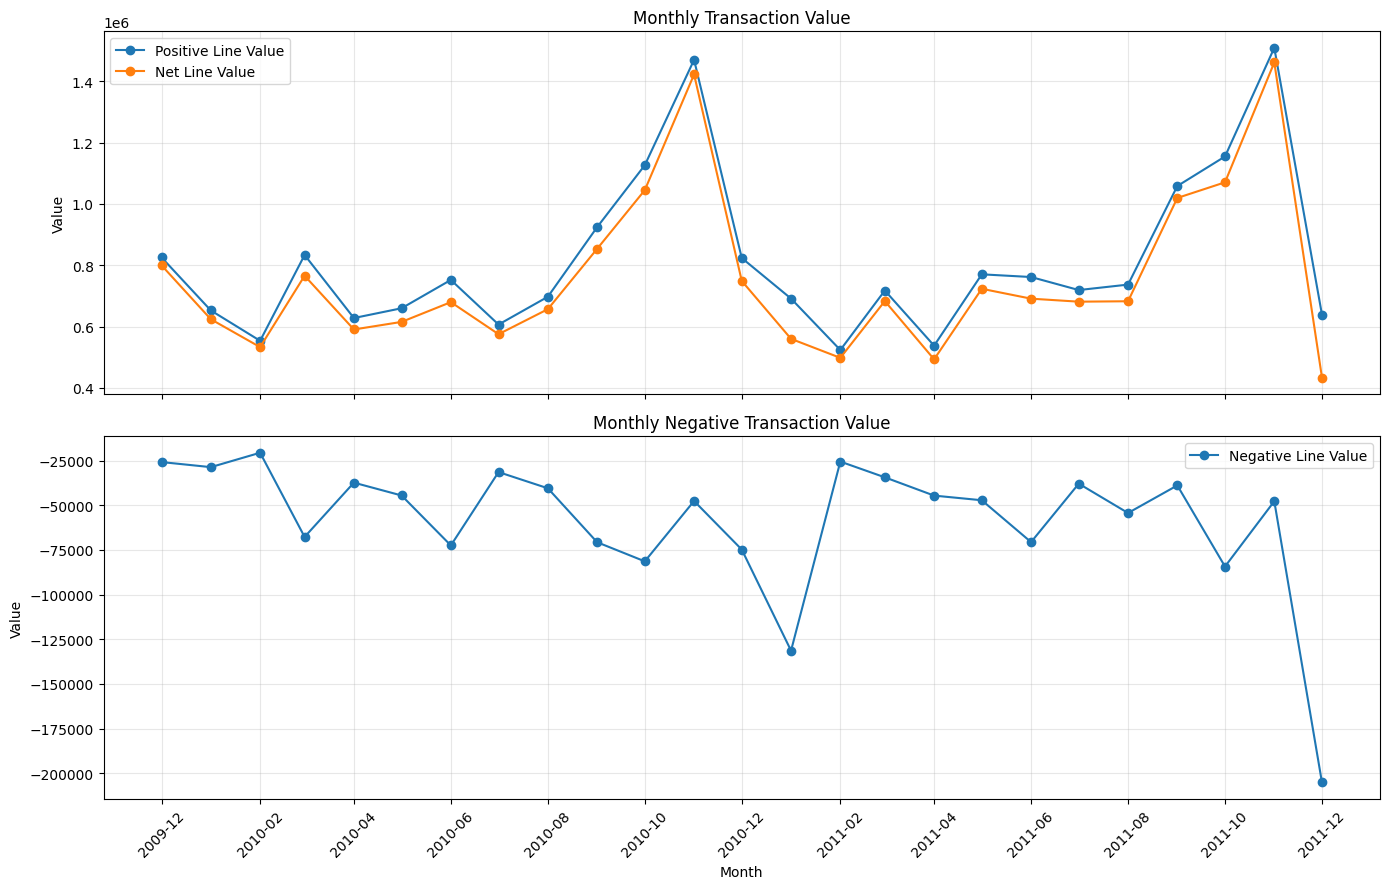

In [94]:
plot_data = monthly_summary.copy()

plot_data["MonthDate"] = (
    plot_data["YearMonth"]
    .dt.to_timestamp()
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True
)

axes[0].plot(
    plot_data["MonthDate"],
    plot_data["PositiveLineValue"],
    marker="o",
    label="Positive Line Value"
)

axes[0].plot(
    plot_data["MonthDate"],
    plot_data["NetLineValue"],
    marker="o",
    label="Net Line Value"
)

axes[0].set_title("Monthly Transaction Value")
axes[0].set_ylabel("Value")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    plot_data["MonthDate"],
    plot_data["NegativeLineValue"],
    marker="o",
    label="Negative Line Value"
)

axes[1].set_title("Monthly Negative Transaction Value")
axes[1].set_ylabel("Value")
axes[1].set_xlabel("Month")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [95]:
monthly_ranked = monthly_summary.sort_values(
    "NetLineValue",
    ascending=False
).copy()

print("Top 5 months by net line value:")
display(
    monthly_ranked[
        [
            "YearMonth",
            "TotalRows",
            "UniqueInvoices",
            "PositiveLineValue",
            "NegativeLineValue",
            "NetLineValue"
        ]
    ].head(5)
)

print("\nBottom 5 months by net line value:")
display(
    monthly_ranked[
        [
            "YearMonth",
            "TotalRows",
            "UniqueInvoices",
            "PositiveLineValue",
            "NegativeLineValue",
            "NetLineValue"
        ]
    ].tail(5)
)

Top 5 months by net line value:


,YearMonth,TotalRows,UniqueInvoices,PositiveLineValue,NegativeLineValue,NetLineValue
23,2011-11,84711,3462,1509496.33,-47740.08,1461756.25
11,2010-11,78015,3669,1470272.48,-47617.84,1422654.64
22,2011-10,60742,2637,1154979.30,-84274.63,1070704.67
10,2010-10,59098,2965,1126558.04,-81389.69,1045168.35
21,2011-09,50226,2327,1058590.17,-38902.55,1019687.62



Bottom 5 months by net line value:


,YearMonth,TotalRows,UniqueInvoices,PositiveLineValue,NegativeLineValue,NetLineValue
13,2011-01,35147,1476,691364.56,-131364.30,560000.26
2,2010-02,29388,1969,553713.31,-20621.88,533091.43
14,2011-02,27707,1393,523631.89,-25569.24,498062.65
16,2011-04,29916,1744,537808.62,-44601.50,493207.12
24,2011-12,25526,1015,638810.68,-205124.67,433686.01


In [96]:
yearly_comparison = monthly_summary.copy()

yearly_comparison["Year"] = (
    yearly_comparison["YearMonth"].dt.year
)

yearly_comparison["Month"] = (
    yearly_comparison["YearMonth"].dt.month
)

comparison = yearly_comparison[
    yearly_comparison["YearMonth"].astype(str).isin(
        [
            "2010-01", "2010-02", "2010-03", "2010-04",
            "2010-05", "2010-06", "2010-07", "2010-08",
            "2010-09", "2010-10", "2010-11",
            "2011-01", "2011-02", "2011-03", "2011-04",
            "2011-05", "2011-06", "2011-07", "2011-08",
            "2011-09", "2011-10", "2011-11"
        ]
    )
].copy()

yearly_pivot = comparison.pivot(
    index="Month",
    columns="Year",
    values="NetLineValue"
)

yearly_pivot["Change"] = (
    yearly_pivot[2011] - yearly_pivot[2010]
)

yearly_pivot["ChangePercent"] = (
    yearly_pivot["Change"] / yearly_pivot[2010] * 100
)

display(yearly_pivot.round(2))

Year,2010,2011,Change,ChangePercent
Month,,,,
1,624032.89,560000.26,-64032.63,-10.26
2,533091.43,498062.65,-35028.78,-6.57
3,765848.76,683267.08,-82581.68,-10.78
4,590580.43,493207.12,-97373.31,-16.49
5,615322.83,723333.51,108010.68,17.55
6,679786.61,691123.12,11336.51,1.67
7,575236.36,681300.11,106063.75,18.44
8,656776.34,682680.51,25904.17,3.94
9,853650.43,1019687.62,166037.19,19.45


In [97]:
print("prepared_data index is unique:",
      prepared_data.index.is_unique)

print("prepared_data has duplicate column names:",
      prepared_data.columns.has_duplicates)

print("monthly_data index is unique:",
      monthly_data.index.is_unique)

print("monthly_data has duplicate column names:",
      monthly_data.columns.has_duplicates)

print("monthly_summary index is unique:",
      monthly_summary.index.is_unique)

print("monthly_summary has duplicate column names:",
      monthly_summary.columns.has_duplicates)

prepared_data index is unique: True
prepared_data has duplicate column names: False
monthly_data index is unique: True
monthly_data has duplicate column names: False
monthly_summary index is unique: True
monthly_summary has duplicate column names: False


In [98]:
print("monthly_summary columns:")
print(monthly_summary.columns.tolist())

print("\nYearMonth data type:")
print(monthly_summary["YearMonth"].dtype)

print("\nDuplicate YearMonth values:")
print(
    monthly_summary.loc[
        monthly_summary["YearMonth"].duplicated(keep=False),
        "YearMonth"
    ]
)

print("\nMonthly summary shape:")
print(monthly_summary.shape)

monthly_summary columns:
['YearMonth', 'TotalRows', 'UniqueInvoices', 'PositiveLineValue', 'NegativeLineValue', 'NetLineValue']

YearMonth data type:
period[M]

Duplicate YearMonth values:
Series([], Name: YearMonth, dtype: period[M])

Monthly summary shape:
(25, 6)


In [99]:
yearly_comparison = monthly_summary.copy()

yearly_comparison["Year"] = (
    yearly_comparison["YearMonth"].dt.year
)

yearly_comparison["Month"] = (
    yearly_comparison["YearMonth"].dt.month
)

comparison = yearly_comparison[
    yearly_comparison["Year"].isin([2010, 2011])
    & yearly_comparison["Month"].between(1, 11)
].copy()

yearly_pivot = comparison.pivot(
    index="Month",
    columns="Year",
    values="NetLineValue"
)

yearly_pivot["Change"] = (
    yearly_pivot[2011] - yearly_pivot[2010]
)

yearly_pivot["ChangePercent"] = (
    yearly_pivot["Change"] / yearly_pivot[2010] * 100
)

display(yearly_pivot.round(2))

Year,2010,2011,Change,ChangePercent
Month,,,,
1,624032.89,560000.26,-64032.63,-10.26
2,533091.43,498062.65,-35028.78,-6.57
3,765848.76,683267.08,-82581.68,-10.78
4,590580.43,493207.12,-97373.31,-16.49
5,615322.83,723333.51,108010.68,17.55
6,679786.61,691123.12,11336.51,1.67
7,575236.36,681300.11,106063.75,18.44
8,656776.34,682680.51,25904.17,3.94
9,853650.43,1019687.62,166037.19,19.45


In [100]:
period_totals = (
    comparison.groupby("Year")
    .agg(
        TotalNetLineValue=("NetLineValue", "sum"),
        TotalPositiveLineValue=("PositiveLineValue", "sum"),
        TotalNegativeLineValue=("NegativeLineValue", "sum"),
        TotalRows=("TotalRows", "sum"),
        TotalUniqueInvoices=("UniqueInvoices", "sum")
    )
)

display(period_totals.round(2))

net_change = (
    period_totals.loc[2011, "TotalNetLineValue"]
    - period_totals.loc[2010, "TotalNetLineValue"]
)

net_change_percent = (
    net_change
    / period_totals.loc[2010, "TotalNetLineValue"]
    * 100
)

print("Net line value change:", round(net_change, 2))
print("Net line value change (%):", round(net_change_percent, 2))

,TotalNetLineValue,TotalPositiveLineValue,TotalNegativeLineValue,TotalRows,TotalUniqueInvoices
Year,,,,,
2010,8362149.07,8905175.16,-543026.09,457710,25398
2011,8565122.90,9182021.60,-616898.70,473903,22860


Net line value change: 202973.83
Net line value change (%): 2.43


## 5. Customer-Level Analysis

### Customer summary

This section aggregates transaction records at the customer level. Only records with a known `Customer ID` contribute to customer-level metrics. Transaction values are retained as recorded, including negative quantities.

### 5.1 Customer Metrics and RFM Inputs

Calculate customer-level purchase metrics and prepare the Recency, Frequency, and Monetary variables used by the RFM analysis.

In [101]:
customer_data = prepared_data[
    prepared_data["Customer ID"].notna()
].copy()

customer_data["InvoiceDate"] = pd.to_datetime(
    customer_data["InvoiceDate"],
    errors="coerce"
)

customer_data["LineValue"] = (
    customer_data["Quantity"] * customer_data["Price"]
)

customer_summary = (
    customer_data
    .groupby("Customer ID")
    .agg(
        InvoiceCount=("Invoice", "nunique"),
        PurchaseFrequency=("InvoiceDate", "nunique"),
        CustomerValue=("LineValue", "sum"),
        PositivePurchaseValue=(
            "LineValue",
            lambda values: values[
                customer_data.loc[values.index, "Quantity"] > 0
            ].sum()
        ),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max"),
        TransactionRows=("Invoice", "size")
    )
    .reset_index()
)

reference_date = customer_data["InvoiceDate"].max().normalize()

customer_summary["DaysSinceLastPurchase"] = (
    reference_date - customer_summary["LastPurchase"].dt.normalize()
).dt.days

print("Known customers:", customer_data["Customer ID"].nunique())
print("Customer summary rows:", len(customer_summary))
print("Duplicate customer IDs:", customer_summary["Customer ID"].duplicated().sum())
print("Reference date:", reference_date)

display(customer_summary.head())

Known customers: 5942
Customer summary rows: 5942
Duplicate customer IDs: 0
Reference date: 2011-12-09 00:00:00


,Customer ID,InvoiceCount,PurchaseFrequency,CustomerValue,PositivePurchaseValue,FirstPurchase,LastPurchase,TransactionRows,DaysSinceLastPurchase
0,12346.0,17,17,-64.68,77556.46,2009-12-14 08:34:00,2011-01-18 10:17:00,48,325
1,12347.0,8,8,4921.53,4921.53,2010-10-31 14:20:00,2011-12-07 15:52:00,222,2
2,12348.0,5,5,2019.40,2019.40,2010-09-27 14:59:00,2011-09-25 13:13:00,51,75
3,12349.0,5,5,4404.54,4428.69,2009-12-04 12:49:00,2011-11-21 09:51:00,180,18
4,12350.0,1,1,334.40,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00,17,310


In [102]:
customer_summary["RepeatCustomer"] = (
    customer_summary["InvoiceCount"] >= 2
)

print("Customer count:", len(customer_summary))

print("\nInvoice count distribution:")
display(
    customer_summary["InvoiceCount"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .to_frame("InvoiceCount")
)

print("\nRepeat customer overview:")
display(
    customer_summary["RepeatCustomer"]
    .value_counts()
    .rename_axis("RepeatCustomer")
    .to_frame("CustomerCount")
)

print("\nCustomer value distribution:")
display(
    customer_summary[
        ["CustomerValue", "PositivePurchaseValue", "DaysSinceLastPurchase"]
    ].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    ).round(2)
)

Customer count: 5942

Invoice count distribution:


,InvoiceCount
count,5942.000000
mean,7.552339
std,15.972262
min,1.000000
25%,2.000000
50%,4.000000
75%,8.000000
90%,17.000000
95%,26.000000
max,510.000000



Repeat customer overview:


,CustomerCount
RepeatCustomer,
True,4481
False,1461



Customer value distribution:


,CustomerValue,PositivePurchaseValue,DaysSinceLastPurchase
count,5942.00,5942.00,5942.00
mean,2750.53,2933.62,202.46
std,13679.48,14371.82,211.88
min,-25111.09,0.00,0.00
25%,322.51,333.76,24.00
50%,828.68,849.91,95.50
75%,2150.65,2239.96,381.00
90%,5154.47,5395.92,541.00
95%,8805.77,9275.02,628.00
max,570380.61,580987.04,738.00


In [103]:
customer_data = prepared_data[
    prepared_data["Customer ID"].notna()
].copy()

customer_data["InvoiceDate"] = pd.to_datetime(
    customer_data["InvoiceDate"],
    errors="coerce"
)

customer_data["InvoiceText"] = (
    customer_data["Invoice"]
    .astype("string")
    .str.strip()
    .str.upper()
)

customer_data["LineValue"] = (
    customer_data["Quantity"] * customer_data["Price"]
)

customer_data["IsPurchaseRow"] = (
    ~customer_data["InvoiceText"].str.startswith("C", na=False)
    & (customer_data["Quantity"] > 0)
)

customer_data["PurchaseInvoice"] = (
    customer_data["Invoice"]
    .where(customer_data["IsPurchaseRow"])
)

customer_data["PositivePurchaseValue"] = (
    customer_data["LineValue"]
    .where(customer_data["IsPurchaseRow"], 0)
)

customer_data["NegativeTransactionValue"] = (
    customer_data["LineValue"]
    .where(customer_data["LineValue"] < 0, 0)
)

customer_data["PurchaseDate"] = (
    customer_data["InvoiceDate"]
    .where(customer_data["IsPurchaseRow"])
)

customer_metrics = (
    customer_data.groupby("Customer ID")
    .agg(
        PurchaseInvoiceCount=("PurchaseInvoice", "nunique"),
        PositivePurchaseValue=("PositivePurchaseValue", "sum"),
        NegativeTransactionValue=("NegativeTransactionValue", "sum"),
        NetCustomerValue=("LineValue", "sum"),
        FirstPurchaseDate=("PurchaseDate", "min"),
        LastPurchaseDate=("PurchaseDate", "max"),
        TransactionRows=("Invoice", "size"),
        UniqueProducts=("StockCode", "nunique")
    )
    .reset_index()
)

reference_date = (
    customer_data["InvoiceDate"].max().normalize()
)

customer_metrics["DaysSinceLastPurchase"] = (
    reference_date
    - customer_metrics["LastPurchaseDate"].dt.normalize()
).dt.days

customer_metrics["RepeatCustomer"] = (
    customer_metrics["PurchaseInvoiceCount"] >= 2
)

print("Reference date:", reference_date.date())
print("Customer count:", len(customer_metrics))
print(
    "Repeat customers:",
    int(customer_metrics["RepeatCustomer"].sum())
)
print(
    "One-time customers:",
    int((customer_metrics["PurchaseInvoiceCount"] == 1).sum())
)
print(
    "Customers with no qualifying positive purchase:",
    int((customer_metrics["PurchaseInvoiceCount"] == 0).sum())
)

display(
    customer_metrics[
        [
            "PurchaseInvoiceCount",
            "PositivePurchaseValue",
            "NegativeTransactionValue",
            "NetCustomerValue",
            "DaysSinceLastPurchase",
            "UniqueProducts"
        ]
    ]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .round(2)
)

Reference date: 2011-12-09
Customer count: 5942
Repeat customers: 4255
One-time customers: 1626
Customers with no qualifying positive purchase: 61


,PurchaseInvoiceCount,PositivePurchaseValue,NegativeTransactionValue,NetCustomerValue,DaysSinceLastPurchase,UniqueProducts
count,5942.00,5942.00,5942.00,5942.00,5881.00,5942.00
mean,6.22,2933.62,-183.08,2750.53,200.99,81.32
std,12.96,14371.82,2697.63,13679.48,209.49,116.40
min,0.00,0.00,-168478.60,-25111.09,0.00,1.00
25%,1.00,333.76,-31.87,322.51,25.00,18.00
50%,3.00,849.91,0.00,828.68,95.00,44.00
75%,7.00,2239.96,0.00,2150.65,379.00,102.00
90%,13.00,5395.92,0.00,5154.47,535.00,197.00
95%,20.00,9275.02,0.00,8805.77,625.00,280.95
max,398.00,580987.04,0.00,570380.61,738.00,2557.00


In [104]:
no_purchase_ids = customer_metrics.loc[
    customer_metrics["PurchaseInvoiceCount"] == 0,
    "Customer ID"
]

no_purchase_data = customer_data[
    customer_data["Customer ID"].isin(no_purchase_ids)
].copy()

no_purchase_data["InvoiceType"] = np.where(
    no_purchase_data["InvoiceText"].str.startswith("C", na=False),
    "C",
    "Non-C"
)

no_purchase_data["QuantityType"] = np.select(
    [
        no_purchase_data["Quantity"] < 0,
        no_purchase_data["Quantity"] > 0
    ],
    [
        "Negative",
        "Positive"
    ],
    default="Zero"
)

cohort_summary = (
    no_purchase_data
    .groupby(
        ["InvoiceType", "QuantityType"],
        dropna=False
    )
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique"),
        NetLineValue=("LineValue", "sum"),
        ZeroPriceRows=("Price", lambda values: (values == 0).sum()),
        MissingDescriptionRows=("Description", lambda values: values.isna().sum())
    )
    .reset_index()
)

print("Customers without qualifying positive purchases:", len(no_purchase_ids))
print("Transaction rows:", len(no_purchase_data))

display(cohort_summary.round(2))

Customers without qualifying positive purchases: 61
Transaction rows: 128


,InvoiceType,QuantityType,Rows,UniqueInvoices,NetLineValue,ZeroPriceRows,MissingDescriptionRows
0,C,Negative,128,65,-61049.67,0,0


In [105]:
rfm_data = customer_metrics.loc[
    customer_metrics["PurchaseInvoiceCount"] > 0
].copy()

rfm = rfm_data[
    [
        "Customer ID",
        "DaysSinceLastPurchase",
        "PurchaseInvoiceCount",
        "PositivePurchaseValue"
    ]
].rename(
    columns={
        "DaysSinceLastPurchase": "Recency",
        "PurchaseInvoiceCount": "Frequency",
        "PositivePurchaseValue": "Monetary"
    }
)

print("Customers included in RFM:", len(rfm))
print("Missing Recency:", rfm["Recency"].isna().sum())
print("Missing Frequency:", rfm["Frequency"].isna().sum())
print("Missing Monetary:", rfm["Monetary"].isna().sum())

display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .round(2)
)

Customers included in RFM: 5881
Missing Recency: 0
Missing Frequency: 0
Missing Monetary: 0


,Recency,Frequency,Monetary
count,5881.00,5881.00,5881.00
mean,200.99,6.29,2964.05
std,209.49,13.01,14443.05
min,0.00,1.00,0.00
25%,25.00,1.00,344.00
50%,95.00,3.00,868.77
75%,379.00,7.00,2257.32
90%,535.00,13.00,5476.50
95%,625.00,21.00,9429.81
max,738.00,398.00,580987.04


,min,median,mean,max,nunique,skew,ZeroCount
Recency,0.0,95.00,200.99,738.00,593.0,0.89,35
Frequency,1.0,3.00,6.29,398.00,90.0,12.65,0
Monetary,0.0,868.77,2964.05,580987.04,5777.0,25.05,3



Recency quantiles:
0.0      0.0
0.1      8.0
0.2     19.0
0.4     58.0
0.5     95.0
0.6    189.0
0.8    410.0
0.9    535.0
1.0    738.0
Name: Recency, dtype: float64


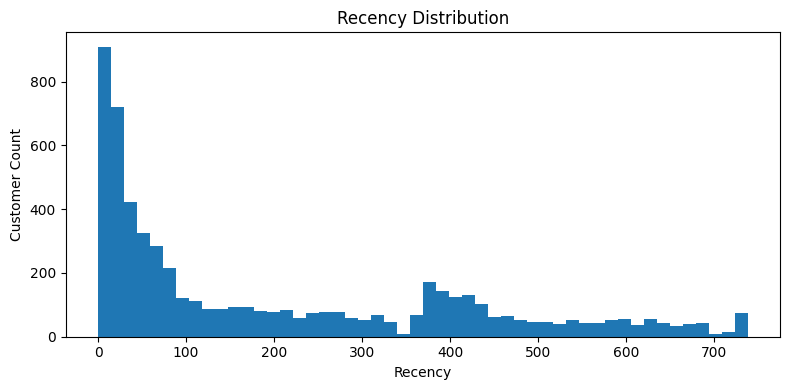


Frequency quantiles:
0.0      1.0
0.1      1.0
0.2      1.0
0.4      2.0
0.5      3.0
0.6      4.0
0.8      8.0
0.9     13.0
1.0    398.0
Name: Frequency, dtype: float64


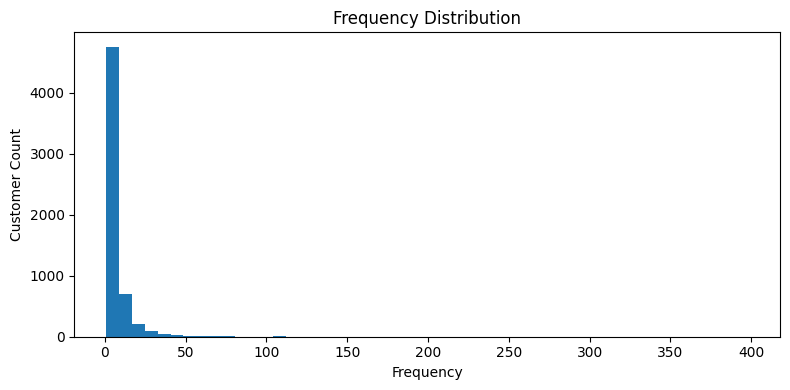


Monetary quantiles:
0.0         0.00
0.1       162.50
0.2       286.60
0.4       611.60
0.5       868.77
0.6      1231.38
0.8      2911.62
0.9      5476.50
1.0    580987.04
Name: Monetary, dtype: float64


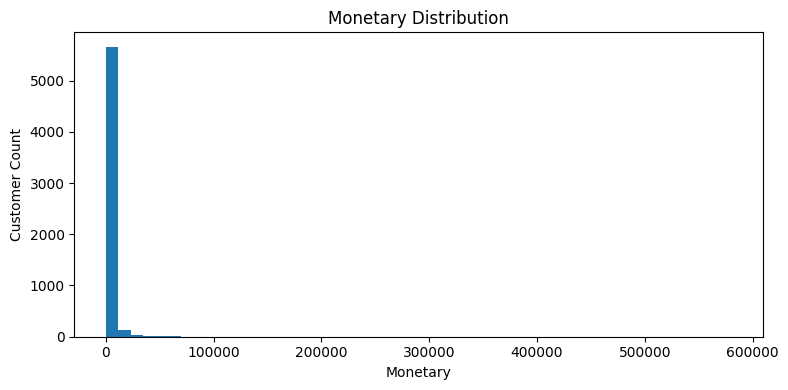

In [106]:
rfm_columns = ["Recency", "Frequency", "Monetary"]

distribution_summary = rfm[rfm_columns].agg(
    ["min", "median", "mean", "max", "nunique", "skew"]
).T

distribution_summary["ZeroCount"] = (
    rfm[rfm_columns].eq(0).sum()
)

display(distribution_summary.round(2))

for column in rfm_columns:
    print(f"\n{column} quantiles:")
    print(
        rfm[column]
        .quantile([0, 0.1, 0.2, 0.4, 0.5, 0.6, 0.8, 0.9, 1])
        .round(2)
    )

    plt.figure(figsize=(8, 4))
    plt.hist(rfm[column], bins=50)
    plt.title(f"{column} Distribution")
    plt.xlabel(column)
    plt.ylabel("Customer Count")
    plt.tight_layout()
    plt.show()

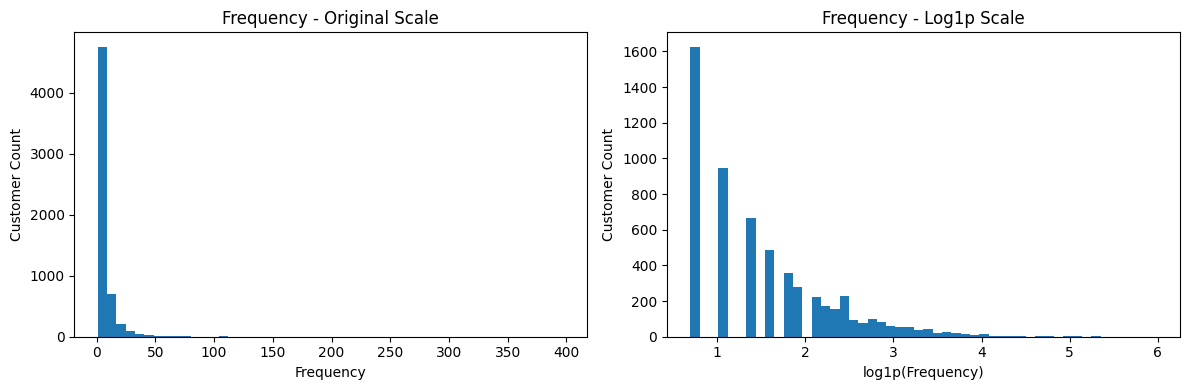


Frequency quantiles:


,Value
0.00,1.0
0.10,1.0
0.20,1.0
0.40,2.0
0.50,3.0
0.60,4.0
0.80,8.0
0.90,13.0
0.95,21.0
0.99,46.0


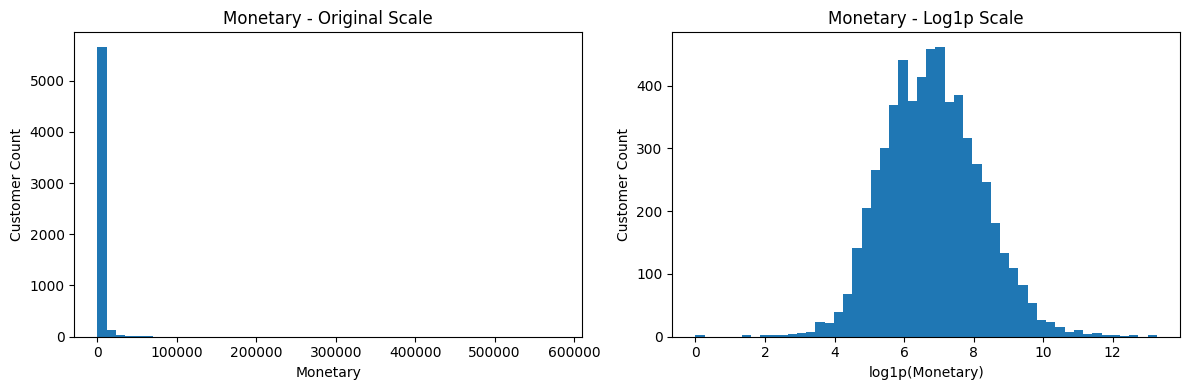


Monetary quantiles:


,Value
0.00,0.00
0.10,162.50
0.20,286.60
0.40,611.60
0.50,868.77
0.60,1231.38
0.80,2911.62
0.90,5476.50
0.95,9429.81
0.99,29181.40


In [107]:
for column in ["Frequency", "Monetary"]:
    values = rfm[column].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(values, bins=50)
    axes[0].set_title(f"{column} - Original Scale")
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Customer Count")

    axes[1].hist(np.log1p(values), bins=50)
    axes[1].set_title(f"{column} - Log1p Scale")
    axes[1].set_xlabel(f"log1p({column})")
    axes[1].set_ylabel("Customer Count")

    plt.tight_layout()
    plt.show()

    print(f"\n{column} quantiles:")
    display(
        values.quantile(
            [0, 0.1, 0.2, 0.4, 0.5, 0.6, 0.8, 0.9, 0.95, 0.99, 1]
        ).to_frame("Value").round(2)
    )

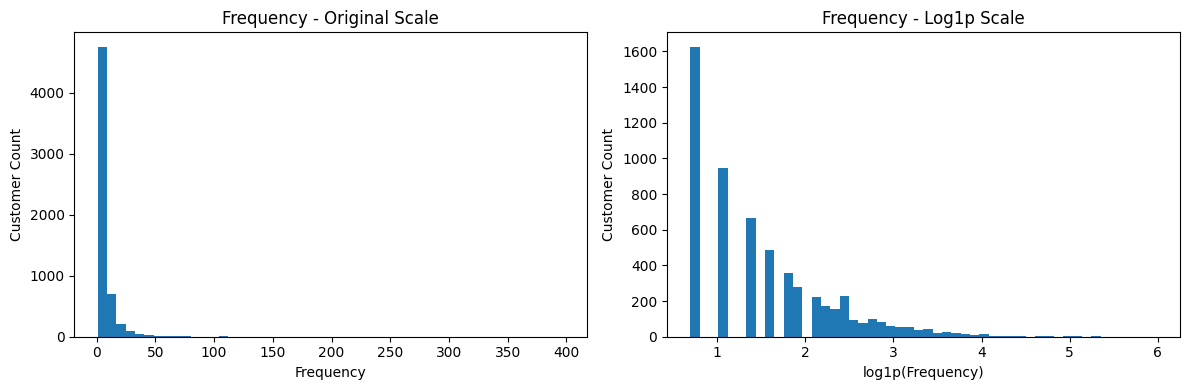

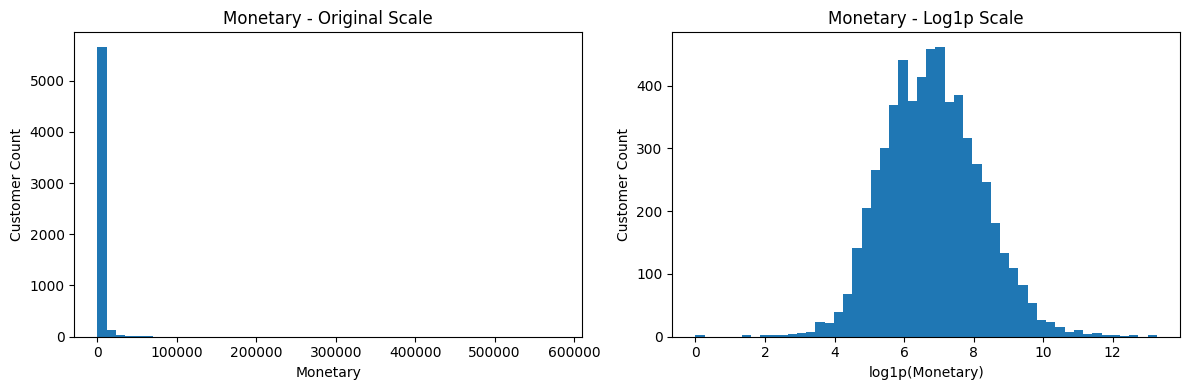

In [108]:
for column in ["Frequency", "Monetary"]:
    values = rfm[column].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(values, bins=50)
    axes[0].set_title(f"{column} - Original Scale")
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Customer Count")

    axes[1].hist(np.log1p(values), bins=50)
    axes[1].set_title(f"{column} - Log1p Scale")
    axes[1].set_xlabel(f"log1p({column})")
    axes[1].set_ylabel("Customer Count")

    plt.tight_layout()
    plt.show()

In [109]:
rfm_scored = rfm.copy()

rfm_scored["R_Score"] = (
    5 - pd.qcut(
        rfm_scored["Recency"].rank(method="first"),
        q=5,
        labels=False
    )
)

rfm_scored["F_Score"] = (
    pd.qcut(
        rfm_scored["Frequency"].rank(method="first"),
        q=5,
        labels=False
    ) + 1
)

rfm_scored["M_Score"] = (
    pd.qcut(
        rfm_scored["Monetary"].rank(method="first"),
        q=5,
        labels=False
    ) + 1
)

rfm_scored["RFM_Score"] = (
    rfm_scored["R_Score"].astype(str)
    + rfm_scored["F_Score"].astype(str)
    + rfm_scored["M_Score"].astype(str)
)

display(
    rfm_scored[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(10)
)

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,325.0,12,77556.46,2,5,5,255
1,12347.0,2.0,8,4921.53,5,4,5,545
2,12348.0,75.0,5,2019.40,3,4,4,344
3,12349.0,18.0,4,4428.69,5,3,5,535
4,12350.0,310.0,1,334.40,2,1,2,212
5,12351.0,375.0,1,300.93,2,1,2,212
6,12352.0,36.0,10,2849.84,4,5,4,454
7,12353.0,204.0,2,406.76,2,2,2,222
8,12354.0,232.0,1,1079.40,2,1,3,213
9,12355.0,214.0,2,947.61,2,2,3,223


In [110]:
print("=" * 55)
print("DATASET VALIDATION")
print("=" * 55)

print("\n1. Dataset sizes")
print("Analysis data:", analysis_data.shape)
print("Prepared data:", prepared_data.shape)
print("Customer metrics:", customer_metrics.shape)
print("RFM:", rfm.shape)
print("RFM scored:", rfm_scored.shape)

print("\n2. Customer metrics")
print("Unique customers:", customer_metrics["Customer ID"].nunique())
print("Repeat customers:", customer_metrics["RepeatCustomer"].sum())
print(
    "One-time customers:",
    (customer_metrics["PurchaseInvoiceCount"] == 1).sum()
)
print(
    "Customers without qualifying purchases:",
    (customer_metrics["PurchaseInvoiceCount"] == 0).sum()
)

print("\n3. RFM validation")
print("Missing values:")
print(rfm[["Recency", "Frequency", "Monetary"]].isna().sum())

print("\nRFM score ranges:")
print(rfm_scored[["R_Score", "F_Score", "M_Score"]].agg(["min", "max"]))

print("\n4. Financial reconciliation")
print(
    "Prepared data net line value:",
    round(
        (prepared_data["Quantity"] * prepared_data["Price"]).sum(),
        2
    )
)
print(
    "Customer net value total:",
    round(customer_metrics["NetCustomerValue"].sum(), 2)
)
print(
    "Positive purchase value total:",
    round(customer_metrics["PositivePurchaseValue"].sum(), 2)
)

print("\n5. Duplicate customer IDs in RFM:")
print(rfm["Customer ID"].duplicated().sum())

DATASET VALIDATION

1. Dataset sizes
Analysis data: (1044848, 11)
Prepared data: (1044848, 14)
Customer metrics: (5942, 11)
RFM: (5881, 4)
RFM scored: (5881, 8)

2. Customer metrics
Unique customers: 5942
Repeat customers: 4255
One-time customers: 1626
Customers without qualifying purchases: 61

3. RFM validation
Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

RFM score ranges:
     R_Score  F_Score  M_Score
min        1        1        1
max        5        5        5

4. Financial reconciliation
Prepared data net line value: 18909762.12
Customer net value total: 16343669.04
Positive purchase value total: 17431551.18

5. Duplicate customer IDs in RFM:
0


In [111]:
known_customer_value = prepared_data.loc[
    prepared_data["Customer ID"].notna(),
    "LineValue"
].sum()

print("Known customer transaction value:",
      round(known_customer_value, 2))

print("Customer metrics net value:",
      round(customer_metrics["NetCustomerValue"].sum(), 2))

Known customer transaction value: 16343669.04
Customer metrics net value: 16343669.04


In [112]:
rfm_columns = {
    "Recency": "R_Score",
    "Frequency": "F_Score",
    "Monetary": "M_Score"
}

for metric, score_column in rfm_columns.items():
    print("\n" + "=" * 60)
    print(metric)

    score_distribution = (
        rfm_scored[score_column]
        .value_counts()
        .sort_index()
    )

    tied_values = (
        rfm_scored.groupby(metric)[score_column]
        .nunique()
    )

    split_values = tied_values[tied_values > 1]

    print("\nCustomer count per score:")
    print(score_distribution.to_string())

    print("\nNumber of distinct metric values:", rfm_scored[metric].nunique())
    print("Metric values assigned to multiple scores:", len(split_values))
    print(
        "Customers affected by split values:",
        int(
            rfm_scored[rfm_scored[metric].isin(split_values.index)].shape[0]
        )
    )

    if not split_values.empty:
        print("\nExamples of values split across scores:")
        print(
            rfm_scored[
                rfm_scored[metric].isin(split_values.index)
            ][[metric, score_column]]
            .drop_duplicates()
            .sort_values(metric)
            .head(15)
            .to_string(index=False)
        )


Recency

Customer count per score:
R_Score
1    1176
2    1176
3    1176
4    1176
5    1177

Number of distinct metric values: 593
Metric values assigned to multiple scores: 4
Customers affected by split values: 107

Examples of values split across scores:
 Recency  R_Score
    19.0        5
    19.0        4
    58.0        3
    58.0        4
   189.0        2
   189.0        3
   410.0        2
   410.0        1

Frequency

Customer count per score:
F_Score
1    1177
2    1176
3    1176
4    1176
5    1176

Number of distinct metric values: 90
Metric values assigned to multiple scores: 4
Customers affected by split values: 3227

Examples of values split across scores:
 Frequency  F_Score
         1        1
         1        2
         2        3
         2        2
         4        4
         4        3
         8        4
         8        5

Monetary

Customer count per score:
M_Score
1    1177
2    1176
3    1176
4    1176
5    1176

Number of distinct metric values: 5777
Met

In [113]:
rfm_tie_preserved = rfm.copy()

recency_percentile = (
    rfm_tie_preserved["Recency"]
    .rank(method="average", pct=True)
)

rfm_tie_preserved["R_Score"] = (
    6 - np.ceil(recency_percentile * 5)
).clip(1, 5).astype(int)

frequency_percentile = (
    rfm_tie_preserved["Frequency"]
    .rank(method="average", pct=True)
)

rfm_tie_preserved["F_Score"] = (
    np.ceil(frequency_percentile * 5)
).clip(1, 5).astype(int)

monetary_percentile = (
    rfm_tie_preserved["Monetary"]
    .rank(method="average", pct=True)
)

rfm_tie_preserved["M_Score"] = (
    np.ceil(monetary_percentile * 5)
).clip(1, 5).astype(int)

rfm_tie_preserved["RFM_Score"] = (
    rfm_tie_preserved["R_Score"].astype(str)
    + rfm_tie_preserved["F_Score"].astype(str)
    + rfm_tie_preserved["M_Score"].astype(str)
)

display(rfm_tie_preserved.head(10))

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,325.0,12,77556.46,2,5,5,255
1,12347.0,2.0,8,4921.53,5,4,5,545
2,12348.0,75.0,5,2019.40,3,4,4,344
3,12349.0,18.0,4,4428.69,5,3,5,535
4,12350.0,310.0,1,334.40,2,1,2,212
5,12351.0,375.0,1,300.93,2,1,2,212
6,12352.0,36.0,10,2849.84,4,5,4,454
7,12353.0,204.0,2,406.76,2,2,2,222
8,12354.0,232.0,1,1079.40,2,1,3,213
9,12355.0,214.0,2,947.61,2,2,3,223


In [114]:
comparison_rows = []

for metric, score_column in [
    ("Recency", "R_Score"),
    ("Frequency", "F_Score"),
    ("Monetary", "M_Score")
]:
    current_counts = (
        rfm_scored[score_column]
        .value_counts()
        .reindex([1, 2, 3, 4, 5], fill_value=0)
    )

    tie_counts = (
        rfm_tie_preserved[score_column]
        .value_counts()
        .reindex([1, 2, 3, 4, 5], fill_value=0)
    )

    for score in range(1, 6):
        comparison_rows.append({
            "Metric": metric,
            "Score": score,
            "Current Method": current_counts.loc[score],
            "Tie-Preserved Method": tie_counts.loc[score]
        })

comparison_table = pd.DataFrame(comparison_rows)

display(
    comparison_table
    .set_index(["Metric", "Score"])
    .sort_index()
)

Current Method  Tie-Preserved Method
Metric    Score                                      
Frequency 1                1177                  1626
          2                1176                   944
          3                1176                  1150
          4                1176                  1033
          5                1176                  1128
Monetary  1                1177                  1176
          2                1176                  1176
          3                1176                  1176
          4                1176                  1176
          5                1176                  1177
Recency   1                1176                  1180
          2                1176                  1174
          3                1176                  1171
          4                1176                  1200
          5                1177                  1156

In [115]:
for metric, score_column in [
    ("Recency", "R_Score"),
    ("Frequency", "F_Score"),
    ("Monetary", "M_Score")
]:
    split_count = (
        rfm_tie_preserved.groupby(metric)[score_column]
        .nunique()
        .gt(1)
        .sum()
    )

    print(f"{metric} - Values split across scores: {split_count}")

Recency - Values split across scores: 0
Frequency - Values split across scores: 0
Monetary - Values split across scores: 0


In [116]:
score_boundaries = []

for metric, score_column in [
    ("Recency", "R_Score"),
    ("Frequency", "F_Score"),
    ("Monetary", "M_Score")
]:
    summary = (
        rfm_tie_preserved
        .groupby(score_column)[metric]
        .agg(
            CustomerCount="count",
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
        .rename(columns={score_column: "Score"})
    )

    summary.insert(0, "Metric", metric)
    score_boundaries.append(summary)

score_boundaries = pd.concat(
    score_boundaries,
    ignore_index=True
)

display(score_boundaries.round(2))

,Metric,Score,CustomerCount,Minimum,Maximum
0,Recency,1,1180,410.00,738.00
1,Recency,2,1174,189.00,409.00
2,Recency,3,1171,59.00,187.00
3,Recency,4,1200,19.00,58.00
4,Recency,5,1156,0.00,18.00
5,Frequency,1,1626,1.00,1.00
6,Frequency,2,944,2.00,2.00
7,Frequency,3,1150,3.00,4.00
8,Frequency,4,1033,5.00,8.00
9,Frequency,5,1128,9.00,398.00


In [117]:
rfm_combinations = (
    rfm_tie_preserved
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median")
    )
)

rfm_combinations["CustomerPercentage"] = (
    rfm_combinations["CustomerCount"]
    / rfm_tie_preserved["Customer ID"].nunique()
    * 100
)

rfm_combinations = rfm_combinations.sort_values(
    "CustomerCount",
    ascending=False
)

display(rfm_combinations.head(20).round(2))

,R_Score,F_Score,M_Score,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MedianMonetary,CustomerPercentage
112,5,5,5,457,7.19,29.12,17721.74,7773.80,7.77
0,1,1,1,447,573.70,1.00,148.61,146.56,7.60
23,2,1,1,248,321.32,1.00,153.88,154.68,4.22
90,4,5,5,248,33.73,17.02,8957.15,5604.40,4.22
1,1,1,2,218,565.43,1.00,389.37,366.41,3.71
62,3,4,4,154,108.38,6.19,1979.52,1944.78,2.62
86,4,4,4,147,35.40,6.27,1916.26,1840.86,2.50
24,2,1,2,133,323.38,1.00,398.19,364.80,2.26
107,5,4,4,131,8.18,6.37,1934.47,1838.85,2.23
68,3,5,5,131,96.19,14.37,6897.56,5523.69,2.23


In [118]:
print("Total customers:", rfm_tie_preserved["Customer ID"].nunique())
print("Customers across RFM combinations:", rfm_combinations["CustomerCount"].sum())
print("Number of occupied RFM combinations:", len(rfm_combinations))
print(
    "Percentage covered:",
    round(rfm_combinations["CustomerPercentage"].sum(), 2),
    "%"
)

Total customers: 5881
Customers across RFM combinations: 5881
Number of occupied RFM combinations: 113
Percentage covered: 100.0 %


In [119]:
customer_segments = rfm_tie_preserved.copy()

conditions = [
    (
        (customer_segments["R_Score"] >= 4)
        & (customer_segments["F_Score"] >= 4)
        & (customer_segments["M_Score"] >= 4)
    ),
    (
        (customer_segments["R_Score"] <= 2)
        & (customer_segments["F_Score"] >= 3)
        & (customer_segments["M_Score"] >= 4)
    ),
    (
        (customer_segments["R_Score"] >= 3)
        & (customer_segments["F_Score"] >= 4)
        & (customer_segments["M_Score"] >= 3)
    ),
    (
        (customer_segments["R_Score"] >= 4)
        & (customer_segments["F_Score"].isin([2, 3]))
    ),
    (
        (customer_segments["R_Score"] >= 4)
        & (customer_segments["F_Score"] == 1)
    ),
    (
        (customer_segments["R_Score"] <= 2)
        & (customer_segments["F_Score"] <= 2)
        & (customer_segments["M_Score"] <= 2)
    )
]

segment_names = [
    "Champions",
    "High-Value At Risk",
    "Loyal Customers",
    "Potential Loyalists",
    "New Customers",
    "Hibernating"
]

customer_segments["Segment"] = np.select(
    conditions,
    segment_names,
    default="Other Customers"
)

segment_summary = (
    customer_segments
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .reset_index()
)

segment_summary["CustomerPercentage"] = (
    segment_summary["CustomerCount"]
    / customer_segments["Customer ID"].nunique()
    * 100
)

segment_summary = segment_summary.sort_values(
    "CustomerCount",
    ascending=False
)

display(segment_summary.round(2))

,Segment,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MedianMonetary,TotalMonetary,CustomerPercentage
5,Other Customers,1391,242.32,2.65,922.04,730.86,1282556.10,23.65
1,Hibernating,1369,463.11,1.24,261.01,237.36,357317.43,23.28
0,Champions,1272,19.10,17.34,9301.48,4019.95,11831484.06,21.63
6,Potential Loyalists,711,24.88,2.88,1226.88,763.28,872311.12,12.09
3,Loyal Customers,583,86.50,8.45,3047.99,1998.00,1776975.54,9.91
2,High-Value At Risk,317,351.92,7.32,3879.86,2052.69,1229914.52,5.39
4,New Customers,238,29.40,1.00,340.30,242.20,80992.41,4.05


### 5.2 Develop RFM Segment Rules

Review score combinations and customer profiles before applying the final rule-based segment definitions.

In [120]:
other_customers = customer_segments[
    customer_segments["Segment"] == "Other Customers"
].copy()

other_combinations = (
    other_customers
    .groupby(["R_Score", "F_Score", "M_Score"], as_index=False)
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
)

other_combinations["CustomerPercentage"] = (
    other_combinations["CustomerCount"]
    / len(other_customers)
    * 100
)

other_combinations = other_combinations.sort_values(
    "CustomerCount",
    ascending=False
)

display(other_combinations.head(25).round(2))

print("Total Other Customers:", len(other_customers))
print(
    "Customers covered in displayed combinations:",
    other_combinations.head(25)["CustomerCount"].sum()
)

,R_Score,F_Score,M_Score,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MedianMonetary,TotalMonetary,CustomerPercentage
20,2,3,3,127,306.43,3.41,897.77,865.20,114017.29,9.13
24,3,1,1,126,110.06,1.00,156.17,156.16,19677.90,9.06
36,3,3,3,109,110.11,3.41,921.83,939.66,100479.18,7.84
25,3,1,2,85,99.07,1.00,402.67,394.14,34227.16,6.11
37,3,3,4,83,108.33,3.51,1744.36,1598.12,144781.81,5.97
15,2,2,3,69,306.71,2.00,818.08,819.45,56447.44,4.96
8,1,3,3,67,486.19,3.36,875.74,835.34,58674.52,4.82
19,2,3,2,66,313.06,3.30,470.21,461.90,31033.75,4.74
31,3,2,3,65,108.38,2.00,802.19,777.36,52142.30,4.67
30,3,2,2,64,113.91,2.00,453.42,470.22,29018.68,4.60


Total Other Customers: 1391
Customers covered in displayed combinations: 1302


In [121]:
display(
    other_combinations
    .iloc[25:]
    .sort_values("CustomerCount", ascending=False)
    .round(2)
)

print(
    "Remaining customers:",
    other_combinations.iloc[25:]["CustomerCount"].sum()
)

,R_Score,F_Score,M_Score,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MedianMonetary,TotalMonetary,CustomerPercentage
34,3,3,1,11,140.82,3.18,214.08,207.74,2354.91,0.79
21,2,4,2,11,300.00,5.27,489.18,501.39,5381.00,0.79
1,1,1,4,9,546.89,1.00,2003.54,1954.99,18031.90,0.65
6,1,3,1,8,538.00,3.12,251.30,269.02,2010.42,0.58
40,3,4,2,8,129.00,5.62,491.71,465.42,3933.64,0.58
45,5,4,2,6,7.00,5.67,530.38,528.68,3182.25,0.43
2,1,1,5,5,541.60,1.00,8234.36,10877.18,41171.79,0.36
18,2,3,1,5,302.60,3.40,175.48,192.55,877.40,0.36
5,1,2,5,5,579.00,2.00,6922.91,4387.08,34614.54,0.36
17,2,2,5,4,252.50,2.00,5248.48,3941.60,20993.92,0.29


Remaining customers: 89


In [122]:
customer_segments_v2 = rfm_tie_preserved.copy()

conditions = [
    (
        (customer_segments_v2["R_Score"] >= 4)
        & (customer_segments_v2["F_Score"] >= 4)
        & (customer_segments_v2["M_Score"] >= 4)
    ),

    (
        (customer_segments_v2["R_Score"] <= 2)
        & (customer_segments_v2["M_Score"] >= 4)
    ),

    (
        (customer_segments_v2["R_Score"] >= 3)
        & (customer_segments_v2["F_Score"] >= 4)
        & (customer_segments_v2["M_Score"] >= 3)
    ),

    (
        (customer_segments_v2["R_Score"] <= 2)
        & (customer_segments_v2["F_Score"] >= 3)
    ),

    (
        (customer_segments_v2["R_Score"] >= 4)
        & (customer_segments_v2["F_Score"].isin([2, 3]))
    ),

    (
        (customer_segments_v2["R_Score"] >= 4)
        & (customer_segments_v2["F_Score"] == 1)
    ),

    (
        (customer_segments_v2["R_Score"] >= 3)
        & (customer_segments_v2["F_Score"] >= 3)
        & (customer_segments_v2["M_Score"] >= 4)
    ),

    (
        (customer_segments_v2["R_Score"] <= 2)
        & (customer_segments_v2["F_Score"] <= 2)
        & (customer_segments_v2["M_Score"] <= 2)
    )
]

segment_names = [
    "Champions",
    "High-Value At Risk",
    "Loyal Customers",
    "At Risk",
    "Potential Loyalists",
    "New Customers",
    "Promising Customers",
    "Hibernating"
]

customer_segments_v2["Segment"] = np.select(
    conditions,
    segment_names,
    default="Needs Attention"
)

segment_summary_v2 = (
    customer_segments_v2
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .reset_index()
)

segment_summary_v2["CustomerPercentage"] = (
    segment_summary_v2["CustomerCount"]
    / customer_segments_v2["Customer ID"].nunique()
    * 100
)

segment_summary_v2 = segment_summary_v2.sort_values(
    "CustomerCount",
    ascending=False
)

display(segment_summary_v2.round(2))

print("\nVALIDATION")
print("Total RFM customers:", len(customer_segments_v2))
print(
    "Customers assigned to a segment:",
    customer_segments_v2["Segment"].notna().sum()
)
print(
    "Unassigned customers:",
    customer_segments_v2["Segment"].isna().sum()
)
print(
    "Unique customers:",
    customer_segments_v2["Customer ID"].nunique()
)
print(
    "Segment customer count total:",
    segment_summary_v2["CustomerCount"].sum()
)
print(
    "Number of segments:",
    customer_segments_v2["Segment"].nunique()
)

assert customer_segments_v2["Segment"].notna().all()
assert customer_segments_v2["Customer ID"].is_unique
assert (
    segment_summary_v2["CustomerCount"].sum()
    == len(customer_segments_v2)
)

,Segment,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MedianMonetary,TotalMonetary,CustomerPercentage
2,Hibernating,1369,463.11,1.24,261.01,237.36,357317.43,23.28
1,Champions,1272,19.10,17.34,9301.48,4019.95,11831484.06,21.63
5,Needs Attention,824,183.00,2.05,649.55,621.52,535225.79,14.01
7,Potential Loyalists,711,24.88,2.88,1226.88,763.28,872311.12,12.09
4,Loyal Customers,583,86.50,8.45,3047.99,1998.00,1776975.54,9.91
3,High-Value At Risk,392,365.27,6.23,3650.30,2014.25,1430918.89,6.67
0,At Risk,391,367.43,3.90,760.34,763.05,297294.19,6.65
6,New Customers,238,29.40,1.00,340.30,242.20,80992.41,4.05
8,Promising Customers,101,108.76,3.52,2465.66,1777.49,249031.75,1.72



VALIDATION
Total RFM customers: 5881
Customers assigned to a segment: 5881
Unassigned customers: 0
Unique customers: 5881
Segment customer count total: 5881
Number of segments: 9


In [123]:
needs_attention = customer_segments_v2[
    customer_segments_v2["Segment"] == "Needs Attention"
].copy()

needs_attention_combinations = (
    needs_attention
    .groupby(["R_Score", "F_Score", "M_Score"], as_index=False)
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
)

needs_attention_combinations["CustomerPercentage"] = (
    needs_attention_combinations["CustomerCount"]
    / len(needs_attention)
    * 100
)

needs_attention_combinations = (
    needs_attention_combinations
    .sort_values("CustomerCount", ascending=False)
)

display(needs_attention_combinations.round(2))

print("Needs Attention customers:", len(needs_attention))
print(
    "Customers represented:",
    needs_attention_combinations["CustomerCount"].sum()
)

,R_Score,F_Score,M_Score,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MedianMonetary,TotalMonetary,CustomerPercentage
4,3,1,1,126,110.06,1.00,156.17,156.16,19677.90,15.29
16,3,3,3,109,110.11,3.41,921.83,939.66,100479.18,13.23
5,3,1,2,85,99.07,1.00,402.67,394.14,34227.16,10.32
3,2,2,3,69,306.71,2.00,818.08,819.45,56447.44,8.37
11,3,2,3,65,108.38,2.00,802.19,777.36,52142.30,7.89
10,3,2,2,64,113.91,2.00,453.42,470.22,29018.68,7.77
1,1,2,3,63,515.24,2.00,838.81,823.40,52844.86,7.65
15,3,3,2,61,112.03,3.48,449.77,449.52,27436.01,7.40
0,1,1,3,40,532.00,1.00,868.06,866.86,34722.53,4.85
2,2,1,3,30,303.13,1.00,880.77,887.53,26423.06,3.64


Needs Attention customers: 824
Customers represented: 824


In [124]:
segment_value_analysis = (
    customer_segments_v2
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median")
    )
    .reset_index()
)

total_customer_value = (
    customer_segments_v2["Monetary"].sum()
)

segment_value_analysis["CustomerShare"] = (
    segment_value_analysis["CustomerCount"]
    / len(customer_segments_v2)
    * 100
)

segment_value_analysis["ValueShare"] = (
    segment_value_analysis["TotalMonetary"]
    / total_customer_value
    * 100
)

segment_value_analysis["ValuePerCustomer"] = (
    segment_value_analysis["TotalMonetary"]
    / segment_value_analysis["CustomerCount"]
)

segment_value_analysis = segment_value_analysis.sort_values(
    "TotalMonetary",
    ascending=False
)

display(segment_value_analysis.round(2))

print("Total customer monetary value:", round(total_customer_value, 2))
print(
    "Value shares total:",
    round(segment_value_analysis["ValueShare"].sum(), 2)
)

,Segment,CustomerCount,TotalMonetary,AverageMonetary,MedianMonetary,CustomerShare,ValueShare,ValuePerCustomer
1,Champions,1272,11831484.06,9301.48,4019.95,21.63,67.87,9301.48
4,Loyal Customers,583,1776975.54,3047.99,1998.00,9.91,10.19,3047.99
3,High-Value At Risk,392,1430918.89,3650.30,2014.25,6.67,8.21,3650.30
7,Potential Loyalists,711,872311.12,1226.88,763.28,12.09,5.00,1226.88
5,Needs Attention,824,535225.79,649.55,621.52,14.01,3.07,649.55
2,Hibernating,1369,357317.43,261.01,237.36,23.28,2.05,261.01
0,At Risk,391,297294.19,760.34,763.05,6.65,1.71,760.34
8,Promising Customers,101,249031.75,2465.66,1777.49,1.72,1.43,2465.66
6,New Customers,238,80992.41,340.30,242.20,4.05,0.46,340.30


Total customer monetary value: 17431551.18
Value shares total: 100.0


In [125]:
rfm_validation = (
    customer_segments_v2
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        MedianRecency=("Recency", "median"),
        AvgFrequency=("Frequency", "mean"),
        MedianFrequency=("Frequency", "median"),
        AvgMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        AvgRScore=("R_Score", "mean"),
        AvgFScore=("F_Score", "mean"),
        AvgMScore=("M_Score", "mean")
    )
    .round(2)
    .sort_values("AvgMonetary", ascending=False)
)

display(rfm_validation)

,CustomerCount,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,AvgRScore,AvgFScore,AvgMScore
Segment,,,,,,,,,,
Champions,1272,19.10,16.0,17.34,11.0,9301.48,4019.95,4.57,4.68,4.65
High-Value At Risk,392,365.27,371.5,6.23,5.0,3650.30,2014.25,1.64,3.40,4.28
Loyal Customers,583,86.50,79.0,8.45,7.0,3047.99,1998.00,3.33,4.33,3.99
Promising Customers,101,108.76,100.0,3.52,4.0,2465.66,1777.49,3.00,3.00,4.18
Potential Loyalists,711,24.88,23.0,2.88,3.0,1226.88,763.28,4.40,2.62,2.82
At Risk,391,367.43,373.0,3.90,3.0,760.34,763.05,1.69,3.23,2.65
Needs Attention,824,183.00,127.0,2.05,2.0,649.55,621.52,2.65,1.89,2.37
New Customers,238,29.40,29.0,1.00,1.0,340.30,242.20,4.30,1.00,1.57
Hibernating,1369,463.11,436.0,1.24,1.0,261.01,237.36,1.41,1.24,1.42


In [126]:
score_distribution = (
    customer_segments_v2
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MinRScore=("R_Score", "min"),
        MaxRScore=("R_Score", "max"),
        MinFScore=("F_Score", "min"),
        MaxFScore=("F_Score", "max"),
        MinMScore=("M_Score", "min"),
        MaxMScore=("M_Score", "max"),
        MinRFMScore=("RFM_Score", "min"),
        MaxRFMScore=("RFM_Score", "max")
    )
    .sort_values("CustomerCount", ascending=False)
)

display(score_distribution)

,CustomerCount,MinRScore,MaxRScore,MinFScore,MaxFScore,MinMScore,MaxMScore,MinRFMScore,MaxRFMScore
Segment,,,,,,,,,
Hibernating,1369,1,2,1,2,1,2,111,222
Champions,1272,4,5,4,5,4,5,444,555
Needs Attention,824,1,5,1,5,1,5,113,552
Potential Loyalists,711,4,5,2,3,1,5,421,535
Loyal Customers,583,3,5,4,5,3,5,343,553
High-Value At Risk,392,1,2,1,5,4,5,114,255
At Risk,391,1,2,3,5,1,3,131,253
New Customers,238,4,5,1,1,1,5,411,515
Promising Customers,101,3,3,3,3,4,5,334,335


In [127]:
needs_attention_patterns = (
    customer_segments_v2[
        customer_segments_v2["Segment"] == "Needs Attention"
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        dropna=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean")
    )
    .reset_index()
    .sort_values("CustomerCount", ascending=False)
)

needs_attention_patterns["CustomerShare"] = (
    needs_attention_patterns["CustomerCount"]
    / needs_attention_patterns["CustomerCount"].sum()
    * 100
)

display(
    needs_attention_patterns.round(2)
)

print(
    "Total customers:",
    needs_attention_patterns["CustomerCount"].sum()
)

print(
    "Distinct RFM combinations:",
    len(needs_attention_patterns)
)

,R_Score,F_Score,M_Score,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,CustomerShare
4,3,1,1,126,110.06,1.00,156.17,15.29
16,3,3,3,109,110.11,3.41,921.83,13.23
5,3,1,2,85,99.07,1.00,402.67,10.32
3,2,2,3,69,306.71,2.00,818.08,8.37
11,3,2,3,65,108.38,2.00,802.19,7.89
10,3,2,2,64,113.91,2.00,453.42,7.77
1,1,2,3,63,515.24,2.00,838.81,7.65
15,3,3,2,61,112.03,3.48,449.77,7.40
0,1,1,3,40,532.00,1.00,868.06,4.85
2,2,1,3,30,303.13,1.00,880.77,3.64


Total customers: 824
Distinct RFM combinations: 25


In [128]:
segment_score_patterns = (
    customer_segments_v2
    .groupby(
        ["Segment", "R_Score", "F_Score", "M_Score"],
        dropna=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique")
    )
    .reset_index()
)

segment_score_patterns["SegmentShare"] = (
    segment_score_patterns["CustomerCount"]
    / segment_score_patterns.groupby("Segment")[
        "CustomerCount"
    ].transform("sum")
    * 100
)

display(
    segment_score_patterns.sort_values(
        ["Segment", "CustomerCount"],
        ascending=[True, False]
    ).round(2)
)

,Segment,R_Score,F_Score,M_Score,CustomerCount,SegmentShare
9,At Risk,2,3,3,127,32.48
2,At Risk,1,3,3,67,17.14
8,At Risk,2,3,2,66,16.88
11,At Risk,2,4,3,58,14.83
1,At Risk,1,3,2,31,7.93
...,...,...,...,...,...,...
106,Potential Loyalists,5,3,1,6,0.84
105,Potential Loyalists,5,2,5,2,0.28
95,Potential Loyalists,4,2,5,1,0.14
111,Promising Customers,3,3,4,83,82.18


In [129]:
print("Available segmentation-related DataFrames:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame) and "Segment" in obj.columns:
        print(
            name,
            "| Shape:", obj.shape,
            "| Segments:", obj["Segment"].nunique()
        )

print("\nCurrent segmentation columns:")
print(customer_segments_v2.columns.tolist())

print("\nSegment counts:")
display(
    customer_segments_v2["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="CustomerCount")
)

Available segmentation-related DataFrames:
customer_segments | Shape: (5881, 9) | Segments: 7
segment_summary | Shape: (7, 8) | Segments: 7
other_customers | Shape: (1391, 9) | Segments: 1
customer_segments_v2 | Shape: (5881, 9) | Segments: 9
segment_summary_v2 | Shape: (9, 8) | Segments: 9
needs_attention | Shape: (824, 9) | Segments: 1
segment_value_analysis | Shape: (9, 8) | Segments: 9
segment_score_patterns | Shape: (113, 6) | Segments: 9

Current segmentation columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Segment']

Segment counts:


,Segment,CustomerCount
0,Hibernating,1369
1,Champions,1272
2,Needs Attention,824
3,Potential Loyalists,711
4,Loyal Customers,583
5,High-Value At Risk,392
6,At Risk,391
7,New Customers,238
8,Promising Customers,101


In [130]:
needs_attention_analysis = (
    customer_segments_v2[
        customer_segments_v2["Segment"] == "Needs Attention"
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        dropna=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .reset_index()
)

needs_attention_analysis["CustomerShare"] = (
    needs_attention_analysis["CustomerCount"]
    / needs_attention_analysis["CustomerCount"].sum()
    * 100
)

display(
    needs_attention_analysis
    .sort_values("CustomerCount", ascending=False)
    .round(2)
)

print("Total customers in Needs Attention:",
      needs_attention_analysis["CustomerCount"].sum())

print("Distinct RFM combinations:",
      len(needs_attention_analysis))

,R_Score,F_Score,M_Score,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,MedianMonetary,TotalMonetary,CustomerShare
4,3,1,1,126,110.06,1.00,156.17,156.16,19677.90,15.29
16,3,3,3,109,110.11,3.41,921.83,939.66,100479.18,13.23
5,3,1,2,85,99.07,1.00,402.67,394.14,34227.16,10.32
3,2,2,3,69,306.71,2.00,818.08,819.45,56447.44,8.37
11,3,2,3,65,108.38,2.00,802.19,777.36,52142.30,7.89
10,3,2,2,64,113.91,2.00,453.42,470.22,29018.68,7.77
1,1,2,3,63,515.24,2.00,838.81,823.40,52844.86,7.65
15,3,3,2,61,112.03,3.48,449.77,449.52,27436.01,7.40
0,1,1,3,40,532.00,1.00,868.06,866.86,34722.53,4.85
2,2,1,3,30,303.13,1.00,880.77,887.53,26423.06,3.64


Total customers in Needs Attention: 824
Distinct RFM combinations: 25


In [131]:
customer_segments_v3 = rfm_tie_preserved.copy()

conditions = [

    (
        (customer_segments_v3["R_Score"] >= 4)
        & (customer_segments_v3["F_Score"] >= 4)
        & (customer_segments_v3["M_Score"] >= 4)
    ),

    (
        (customer_segments_v3["R_Score"] <= 2)
        & (customer_segments_v3["M_Score"] >= 4)
    ),

    (
        (customer_segments_v3["R_Score"] >= 3)
        & (customer_segments_v3["F_Score"] >= 4)
        & (customer_segments_v3["M_Score"] >= 3)
    ),

    (
        (customer_segments_v3["R_Score"] <= 2)
        & (customer_segments_v3["F_Score"] >= 3)
        & (customer_segments_v3["M_Score"] <= 3)
    ),

    (
        (customer_segments_v3["R_Score"] <= 2)
        & (customer_segments_v3["F_Score"] <= 2)
        & (customer_segments_v3["M_Score"] <= 2)
    ),

    (
        (customer_segments_v3["R_Score"] >= 4)
        & (customer_segments_v3["F_Score"].isin([2, 3]))
        & (customer_segments_v3["M_Score"] <= 3)
    ),

    (
        (customer_segments_v3["R_Score"] >= 4)
        & (customer_segments_v3["F_Score"] == 1)
    ),

    (
        (customer_segments_v3["R_Score"] == 3)
        & (customer_segments_v3["F_Score"] == 3)
        & (customer_segments_v3["M_Score"] >= 4)
    )
]

segment_names = [
    "Champions",
    "High-Value At Risk",
    "Loyal Customers",
    "At Risk",
    "Hibernating",
    "Potential Loyalists",
    "New Customers",
    "Promising Customers"
]

customer_segments_v3["Segment"] = np.select(
    conditions,
    segment_names,
    default="Developing Customers"
)

segment_summary_v3 = (
    customer_segments_v3
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .reset_index()
)

segment_summary_v3["CustomerPercentage"] = (
    segment_summary_v3["CustomerCount"]
    / customer_segments_v3["Customer ID"].nunique()
    * 100
)

segment_summary_v3 = segment_summary_v3.sort_values(
    "CustomerCount",
    ascending=False
)

display(segment_summary_v3.round(2))

print("\nVALIDATION")
print("Total customers:", len(customer_segments_v3))
print("Unique customers:", customer_segments_v3["Customer ID"].nunique())
print("Assigned customers:", customer_segments_v3["Segment"].notna().sum())
print("Number of segments:", customer_segments_v3["Segment"].nunique())

assert customer_segments_v3["Segment"].notna().all()
assert customer_segments_v3["Customer ID"].is_unique
assert segment_summary_v3["CustomerCount"].sum() == len(customer_segments_v3)

,Segment,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MedianMonetary,TotalMonetary,CustomerPercentage
3,Hibernating,1369,463.11,1.24,261.01,237.36,357317.43,23.28
1,Champions,1272,19.10,17.34,9301.48,4019.95,11831484.06,21.63
2,Developing Customers,986,156.86,2.26,1067.60,706.38,1052651.11,16.77
5,Loyal Customers,583,86.50,8.45,3047.99,1998.00,1776975.54,9.91
7,Potential Loyalists,549,25.16,2.76,646.42,641.94,354885.80,9.34
4,High-Value At Risk,392,365.27,6.23,3650.30,2014.25,1430918.89,6.67
0,At Risk,391,367.43,3.90,760.34,763.05,297294.19,6.65
6,New Customers,238,29.40,1.00,340.30,242.20,80992.41,4.05
8,Promising Customers,101,108.76,3.52,2465.66,1777.49,249031.75,1.72



VALIDATION
Total customers: 5881
Unique customers: 5881
Assigned customers: 5881
Number of segments: 9


In [132]:
developing_patterns = (
    customer_segments_v3[
        customer_segments_v3["Segment"] == "Developing Customers"
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        dropna=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .reset_index()
)

developing_patterns["CustomerShare"] = (
    developing_patterns["CustomerCount"]
    / developing_patterns["CustomerCount"].sum()
    * 100
)

display(
    developing_patterns
    .sort_values("CustomerCount", ascending=False)
    .round(2)
)

print("\nVALIDATION")
print("Developing Customers:", developing_patterns["CustomerCount"].sum())
print("Distinct RFM combinations:", len(developing_patterns))

,R_Score,F_Score,M_Score,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,MedianMonetary,TotalMonetary,CustomerShare
4,3,1,1,126,110.06,1.00,156.17,156.16,19677.90,12.78
16,3,3,3,109,110.11,3.41,921.83,939.66,100479.18,11.05
5,3,1,2,85,99.07,1.00,402.67,394.14,34227.16,8.62
3,2,2,3,69,306.71,2.00,818.08,819.45,56447.44,7.00
11,3,2,3,65,108.38,2.00,802.19,777.36,52142.30,6.59
23,4,3,4,65,36.91,3.49,1610.12,1435.85,104657.64,6.59
10,3,2,2,64,113.91,2.00,453.42,470.22,29018.68,6.49
1,1,2,3,63,515.24,2.00,838.81,823.40,52844.86,6.39
15,3,3,2,61,112.03,3.48,449.77,449.52,27436.01,6.19
29,5,3,4,51,8.73,3.65,1672.22,1509.09,85283.15,5.17



VALIDATION
Developing Customers: 986
Distinct RFM combinations: 33


In [133]:
high_value_developing = (
    customer_segments_v3[
        (customer_segments_v3["Segment"] == "Developing Customers")
        & (customer_segments_v3["M_Score"] >= 4)
    ]
    .sort_values(
        ["Monetary", "Recency"],
        ascending=[False, True]
    )
)

print("High-value customers in Developing Customers:")
print("Customer count:", high_value_developing["Customer ID"].nunique())
print(
    "Total monetary value:",
    round(high_value_developing["Monetary"].sum(), 2)
)

display(
    high_value_developing[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(20)
)

High-value customers in Developing Customers:
Customer count: 194
Total monetary value: 584242.58


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
4100,16446.0,0.0,2,168472.500,5,2,5,525
11,12357.0,33.0,3,18287.660,4,3,5,435
190,12536.0,43.0,3,12601.830,4,3,5,435
3654,16000.0,2.0,3,12393.700,5,3,5,535
452,12798.0,10.0,4,8510.930,5,3,5,535
32,12378.0,129.0,2,5416.320,3,2,5,325
2113,14459.0,155.0,2,5375.741,3,2,5,325
4738,17084.0,35.0,3,5202.970,4,3,5,435
354,12700.0,7.0,4,4939.990,5,3,5,535
342,12688.0,113.0,1,4873.810,3,1,5,315


In [134]:
recent_high_value = customer_segments_v3[
    (customer_segments_v3["R_Score"] >= 4)
    & (customer_segments_v3["F_Score"].isin([2, 3]))
    & (customer_segments_v3["M_Score"] >= 4)
].copy()

print("RECENT HIGH-VALUE CUSTOMERS")
print("-" * 45)

print(
    "Customer count:",
    recent_high_value["Customer ID"].nunique()
)

print(
    "Total monetary value:",
    round(recent_high_value["Monetary"].sum(), 2)
)

print(
    "Average monetary value:",
    round(recent_high_value["Monetary"].mean(), 2)
)

print(
    "Median monetary value:",
    round(recent_high_value["Monetary"].median(), 2)
)

print(
    "Average recency:",
    round(recent_high_value["Recency"].mean(), 2)
)

print(
    "Average frequency:",
    round(recent_high_value["Frequency"].mean(), 2)
)

print("\nRFM SCORE DISTRIBUTION")

display(
    recent_high_value
    .groupby(["R_Score", "F_Score", "M_Score"])
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        AverageMonetary=("Monetary", "mean")
    )
    .reset_index()
    .sort_values(
        ["R_Score", "F_Score", "M_Score"],
        ascending=False
    )
    .round(2)
)

RECENT HIGH-VALUE CUSTOMERS
---------------------------------------------
Customer count: 162
Total monetary value: 517425.32
Average monetary value: 3193.98
Median monetary value: 1545.14
Average recency: 23.91
Average frequency: 3.32

RFM SCORE DISTRIBUTION


,R_Score,F_Score,M_Score,CustomerCount,TotalMonetary,AverageMonetary
7,5,3,5,8,44886.67,5610.83
6,5,3,4,51,85283.15,1672.22
5,5,2,5,2,171665.04,85832.52
4,5,2,4,11,18061.57,1641.96
3,4,3,5,13,71801.58,5523.20
2,4,3,4,65,104657.64,1610.12
1,4,2,5,1,3718.80,3718.80
0,4,2,4,11,17350.87,1577.35


## 6. Rule-Based Customer Segmentation

Apply the RFM score rules, inspect the resulting segment distribution, and validate the score-to-segment mapping.

In [135]:
customer_segments_v4 = rfm_tie_preserved.copy()

R = customer_segments_v4["R_Score"]
F = customer_segments_v4["F_Score"]
M = customer_segments_v4["M_Score"]

conditions = [
    (R >= 4) & (F >= 4) & (M >= 4),                 # Champions
    (R <= 2) & (M >= 4),                            # High-Value At Risk
    (R >= 3) & (F >= 4) & (M >= 3),                 # Loyal Customers
    (R >= 4) & (F.isin([2, 3])) & (M >= 4),         # Recent High-Value Customers
    (R <= 2) & (F >= 3) & (M <= 3),                 # At Risk
    (R <= 2) & (F <= 2) & (M <= 2),                 # Hibernating
    (R >= 4) & (F.isin([2, 3])) & (M <= 3),         # Potential Loyalists
    (R >= 4) & (F == 1),                            # New Customers
    (R == 3) & (F == 3) & (M >= 4)                  # Promising Customers
]

segment_names = [
    "Champions",
    "High-Value At Risk",
    "Loyal Customers",
    "Recent High-Value Customers",
    "At Risk",
    "Hibernating",
    "Potential Loyalists",
    "New Customers",
    "Promising Customers"
]

customer_segments_v4["Segment"] = np.select(
    conditions,
    segment_names,
    default="Developing Customers"
)

print("Total customers:", len(customer_segments_v4))
print("Unique customers:", customer_segments_v4["Customer ID"].nunique())
print("Unassigned customers:", customer_segments_v4["Segment"].isna().sum())

display(
    customer_segments_v4["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="CustomerCount")
)

Total customers: 5881
Unique customers: 5881
Unassigned customers: 0


,Segment,CustomerCount
0,Hibernating,1369
1,Champions,1272
2,Developing Customers,824
3,Loyal Customers,583
4,Potential Loyalists,549
5,High-Value At Risk,392
6,At Risk,391
7,New Customers,238
8,Recent High-Value Customers,162
9,Promising Customers,101


In [136]:
segment_summary_v4 = (
    customer_segments_v4
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        AverageMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean")
    )
    .reset_index()
)

total_customers = segment_summary_v4["CustomerCount"].sum()
total_revenue = segment_summary_v4["TotalMonetary"].sum()

segment_summary_v4["CustomerShare"] = (
    segment_summary_v4["CustomerCount"] / total_customers * 100
)

segment_summary_v4["RevenueShare"] = (
    segment_summary_v4["TotalMonetary"] / total_revenue * 100
)

segment_summary_v4 = segment_summary_v4.sort_values(
    "TotalMonetary",
    ascending=False
)

display(segment_summary_v4.round(2))

,Segment,CustomerCount,TotalMonetary,AverageMonetary,MedianMonetary,AverageRecency,AverageFrequency,CustomerShare,RevenueShare
1,Champions,1272,11831484.06,9301.48,4019.95,19.10,17.34,21.63,67.87
5,Loyal Customers,583,1776975.54,3047.99,1998.00,86.50,8.45,9.91,10.19
4,High-Value At Risk,392,1430918.89,3650.30,2014.25,365.27,6.23,6.67,8.21
2,Developing Customers,824,535225.79,649.55,621.52,183.00,2.05,14.01,3.07
9,Recent High-Value Customers,162,517425.32,3193.98,1545.14,23.91,3.32,2.75,2.97
3,Hibernating,1369,357317.43,261.01,237.36,463.11,1.24,23.28,2.05
7,Potential Loyalists,549,354885.80,646.42,641.94,25.16,2.76,9.34,2.04
0,At Risk,391,297294.19,760.34,763.05,367.43,3.90,6.65,1.71
8,Promising Customers,101,249031.75,2465.66,1777.49,108.76,3.52,1.72,1.43
6,New Customers,238,80992.41,340.30,242.20,29.40,1.00,4.05,0.46


In [137]:
score_columns = ["R_Score", "F_Score", "M_Score"]

for column in score_columns:
    print(f"\n{column} DISTRIBUTION")
    print("-" * 40)

    distribution = (
        rfm_tie_preserved[column]
        .value_counts()
        .sort_index()
        .rename_axis("Score")
        .reset_index(name="CustomerCount")
    )

    distribution["CustomerShare"] = (
        distribution["CustomerCount"]
        / len(rfm_tie_preserved)
        * 100
    )

    display(distribution.round(2))


R_Score DISTRIBUTION
----------------------------------------


,Score,CustomerCount,CustomerShare
0,1,1180,20.06
1,2,1174,19.96
2,3,1171,19.91
3,4,1200,20.40
4,5,1156,19.66



F_Score DISTRIBUTION
----------------------------------------


,Score,CustomerCount,CustomerShare
0,1,1626,27.65
1,2,944,16.05
2,3,1150,19.55
3,4,1033,17.57
4,5,1128,19.18



M_Score DISTRIBUTION
----------------------------------------


,Score,CustomerCount,CustomerShare
0,1,1176,20.00
1,2,1176,20.00
2,3,1176,20.00
3,4,1176,20.00
4,5,1177,20.01


In [138]:
score_mapping_summary = []

metrics = [
    ("Recency", "R_Score"),
    ("Frequency", "F_Score"),
    ("Monetary", "M_Score")
]

for metric, score in metrics:
    summary = (
        rfm_tie_preserved
        .groupby(score)[metric]
        .agg(
            CustomerCount="count",
            Minimum="min",
            Q1=lambda x: x.quantile(0.25),
            Median="median",
            Mean="mean",
            Q3=lambda x: x.quantile(0.75),
            Maximum="max"
        )
        .reset_index()
        .rename(columns={score: "Score"})
    )

    summary.insert(0, "Metric", metric)
    score_mapping_summary.append(summary)

score_mapping_summary = pd.concat(
    score_mapping_summary,
    ignore_index=True
)

display(score_mapping_summary.round(2))

,Metric,Score,CustomerCount,Minimum,Q1,Median,Mean,Q3,Maximum
0,Recency,1,1180,410.00,449.00,534.50,543.62,625.00,738.00
1,Recency,2,1174,189.00,246.00,310.00,309.51,379.00,409.00
2,Recency,3,1171,59.00,73.00,95.00,107.00,138.00,187.00
3,Recency,4,1200,19.00,25.00,33.00,35.28,45.00,58.00
4,Recency,5,1156,0.00,3.00,8.00,8.27,12.00,18.00
5,Frequency,1,1626,1.00,1.00,1.00,1.00,1.00,1.00
6,Frequency,2,944,2.00,2.00,2.00,2.00,2.00,2.00
7,Frequency,3,1150,3.00,3.00,3.00,3.42,4.00,4.00
8,Frequency,4,1033,5.00,5.00,6.00,6.20,7.00,8.00
9,Frequency,5,1128,9.00,11.00,14.00,20.50,21.00,398.00


In [139]:
metrics_to_check = ["Frequency", "Monetary"]

for metric in metrics_to_check:
    q1 = rfm_tie_preserved[metric].quantile(0.25)
    q3 = rfm_tie_preserved[metric].quantile(0.75)
    iqr = q3 - q1

    upper_bound = q3 + 1.5 * iqr

    outliers = rfm_tie_preserved[
        rfm_tie_preserved[metric] > upper_bound
    ]

    print(f"\n{metric.upper()} OUTLIER CHECK")
    print("-" * 45)
    print("Q1:", round(q1, 2))
    print("Q3:", round(q3, 2))
    print("IQR:", round(iqr, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of upper outliers:", len(outliers))
    print(
        "Percentage of customers:",
        round(len(outliers) / len(rfm_tie_preserved) * 100, 2)
    )
    print("Maximum value:", rfm_tie_preserved[metric].max())

    print("\nTop 10 customers:")
    display(
        outliers[
            ["Customer ID", "Recency", "Frequency", "Monetary",
             "R_Score", "F_Score", "M_Score"]
        ]
        .sort_values(metric, ascending=False)
        .head(10)
    )


FREQUENCY OUTLIER CHECK
---------------------------------------------
Q1: 1.0
Q3: 7.0
IQR: 6.0
Upper bound: 16.0
Number of upper outliers: 427
Percentage of customers: 7.26
Maximum value: 398

Top 10 customers:


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
2565,14911.0,1.0,398,291561.05,5,5,5
402,12748.0,0.0,337,54598.04,5,5,5
5495,17841.0,1.0,211,69342.51,5,5,5
2965,15311.0,0.0,208,115147.09,5,5,5
743,13089.0,2.0,203,113507.24,5,5,5
2260,14606.0,1.0,192,30254.18,5,5,5
1810,14156.0,9.0,156,313624.17,5,5,5
5504,17850.0,372.0,155,51208.87,2,5,5
2300,14646.0,1.0,152,528602.52,5,5,5
5756,18102.0,0.0,145,580987.04,5,5,5



MONETARY OUTLIER CHECK
---------------------------------------------
Q1: 344.0
Q3: 2257.32
IQR: 1913.32
Upper bound: 5127.3
Number of upper outliers: 634
Percentage of customers: 10.78
Maximum value: 580987.04

Top 10 customers:


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
5756,18102.0,0.0,145,580987.04,5,5,5
2300,14646.0,1.0,152,528602.52,5,5,5
1810,14156.0,9.0,156,313624.17,5,5,5
2565,14911.0,1.0,398,291561.05,5,5,5
5104,17450.0,8.0,51,244944.25,5,5,5
1348,13694.0,3.0,143,195640.69,5,5,5
5165,17511.0,2.0,60,172132.87,5,5,5
4100,16446.0,0.0,2,168472.50,5,2,5
4338,16684.0,4.0,55,147142.77,5,5,5
69,12415.0,24.0,28,144458.37,4,5,5


In [140]:
metrics_to_check = ["Frequency", "Monetary"]

for metric in metrics_to_check:
    q1 = rfm_tie_preserved[metric].quantile(0.25)
    q3 = rfm_tie_preserved[metric].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = rfm_tie_preserved[metric] > upper_bound

    total_value = rfm_tie_preserved[metric].sum()
    outlier_value = rfm_tie_preserved.loc[
        outlier_mask, metric
    ].sum()

    print(f"\n{metric.upper()} OUTLIER IMPACT")
    print("-" * 45)

    print("Total customers:", len(rfm_tie_preserved))
    print("Outlier customers:", int(outlier_mask.sum()))

    print(
        "Outlier customer share (%):",
        round(outlier_mask.mean() * 100, 2)
    )

    print("Total value:", round(total_value, 2))
    print("Outlier value:", round(outlier_value, 2))

    print(
        "Outlier contribution (%):",
        round(outlier_value / total_value * 100, 2)
    )


FREQUENCY OUTLIER IMPACT
---------------------------------------------
Total customers: 5881
Outlier customers: 427
Outlier customer share (%): 7.26
Total value: 36975
Outlier value: 14998
Outlier contribution (%): 40.56

MONETARY OUTLIER IMPACT
---------------------------------------------
Total customers: 5881
Outlier customers: 634
Outlier customer share (%): 10.78
Total value: 17431551.18
Outlier value: 11372507.07
Outlier contribution (%): 65.24


In [141]:
score_order_check = {
    "R_Score": "Recency",
    "F_Score": "Frequency",
    "M_Score": "Monetary"
}

for score_column, metric_column in score_order_check.items():
    score_means = (
        rfm_tie_preserved
        .groupby(score_column)[metric_column]
        .mean()
        .sort_index()
    )

    is_increasing = score_means.is_monotonic_increasing

    if score_column == "R_Score":
        # Higher R score should represent lower Recency.
        is_valid = score_means.is_monotonic_decreasing
    else:
        is_valid = is_increasing

    print(f"\n{score_column} - {metric_column}")
    display(score_means.rename("AverageValue").to_frame().round(2))
    print("Score direction valid:", is_valid)


R_Score - Recency


,AverageValue
R_Score,
1,543.62
2,309.51
3,107.00
4,35.28
5,8.27


Score direction valid: True

F_Score - Frequency


,AverageValue
F_Score,
1,1.00
2,2.00
3,3.42
4,6.20
5,20.50


Score direction valid: True

M_Score - Monetary


,AverageValue
M_Score,
1,162.49
2,424.93
3,888.04
4,1904.05
5,11433.52


Score direction valid: True


### RFM scoring validation and finalization

The RFM scoring methodology was evaluated using score distributions, metric ranges, outlier analysis, and score-direction checks.

The analysis indicated that:

- Recency and Monetary scores were distributed almost equally across the five scoring levels.
- Frequency scores showed a larger concentration of customers with only one purchase, reflecting the underlying purchase-frequency distribution.
- Higher R scores consistently corresponded to lower Recency values, while higher F and M scores corresponded to higher Frequency and Monetary values.
- Frequency and Monetary distributions were positively skewed, with a relatively small proportion of customers contributing a substantial share of purchasing activity and monetary value.
- Potential outliers were retained because they may represent genuine high-value or high-frequency customer behavior.

The tie-preserving scoring methodology was retained for subsequent segmentation. The distribution characteristics and limitations should be considered when interpreting segment profiles.

### 6.1 Segment Profiles and Business Value

Profile segments using customer counts, RFM scores, recency, frequency, and monetary value. The following analyses also refine the treatment of customers initially assigned to the developing segment.

In [142]:
print("CUSTOMER SEGMENTATION VALIDATION")
print("=" * 55)

print("RFM customer count:", len(rfm_tie_preserved))
print("Segmented customer count:", len(customer_segments_v4))

print(
    "Unique customers:",
    customer_segments_v4["Customer ID"].nunique()
)

print(
    "Missing segment labels:",
    customer_segments_v4["Segment"].isna().sum()
)

print("\nCUSTOMER COUNT BY SEGMENT")
display(
    customer_segments_v4["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="CustomerCount")
)

print("\nSEGMENT SUMMARY")
display(segment_summary_v4)

CUSTOMER SEGMENTATION VALIDATION
RFM customer count: 5881
Segmented customer count: 5881
Unique customers: 5881
Missing segment labels: 0

CUSTOMER COUNT BY SEGMENT


,Segment,CustomerCount
0,Hibernating,1369
1,Champions,1272
2,Developing Customers,824
3,Loyal Customers,583
4,Potential Loyalists,549
5,High-Value At Risk,392
6,At Risk,391
7,New Customers,238
8,Recent High-Value Customers,162
9,Promising Customers,101



SEGMENT SUMMARY


,Segment,CustomerCount,TotalMonetary,AverageMonetary,MedianMonetary,AverageRecency,AverageFrequency,CustomerShare,RevenueShare
1,Champions,1272,1.183148e+07,9301.481175,4019.950,19.103774,17.340409,21.628975,67.873960
5,Loyal Customers,583,1.776976e+06,3047.985480,1998.000,86.500858,8.449400,9.913280,10.194018
4,High-Value At Risk,392,1.430919e+06,3650.303298,2014.250,365.272959,6.234694,6.665533,8.208787
2,Developing Customers,824,5.352258e+05,649.545865,621.520,183.002427,2.048544,14.011223,3.070443
9,Recent High-Value Customers,162,5.174253e+05,3193.983457,1545.135,23.913580,3.320988,2.754634,2.968326
3,Hibernating,1369,3.573174e+05,261.006159,237.360,463.105186,1.235939,23.278354,2.049832
7,Potential Loyalists,549,3.548858e+05,646.422224,641.940,25.160291,2.755920,9.335147,2.035882
0,At Risk,391,2.972942e+05,760.343197,763.050,367.434783,3.895141,6.648529,1.705495
8,Promising Customers,101,2.490318e+05,2465.660891,1777.490,108.762376,3.524752,1.717395,1.428626
6,New Customers,238,8.099241e+04,340.304244,242.195,29.403361,1.000000,4.046931,0.464631


In [143]:
segment_profile = (
    customer_segments_v4
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MinR=("R_Score", "min"),
        MaxR=("R_Score", "max"),
        MinF=("F_Score", "min"),
        MaxF=("F_Score", "max"),
        MinM=("M_Score", "min"),
        MaxM=("M_Score", "max"),
        UniqueRFMScores=("RFM_Score", "nunique")
    )
    .reset_index()
    .sort_values("CustomerCount", ascending=False)
)

print("RFM SCORE RANGE BY SEGMENT")
display(segment_profile)

print("\nMOST COMMON RFM COMBINATIONS WITHIN EACH SEGMENT")

for segment in customer_segments_v4["Segment"].unique():
    print(f"\n{segment}")

    display(
        customer_segments_v4.loc[
            customer_segments_v4["Segment"] == segment,
            "RFM_Score"
        ]
        .value_counts()
        .head(10)
        .rename_axis("RFM_Score")
        .reset_index(name="CustomerCount")
    )

RFM SCORE RANGE BY SEGMENT


,Segment,CustomerCount,MinR,MaxR,MinF,MaxF,MinM,MaxM,UniqueRFMScores
3,Hibernating,1369,1,2,1,2,1,2,8
1,Champions,1272,4,5,4,5,4,5,8
2,Developing Customers,824,1,5,1,5,1,5,25
5,Loyal Customers,583,3,5,4,5,3,5,10
7,Potential Loyalists,549,4,5,2,3,1,3,12
4,High-Value At Risk,392,1,2,1,5,4,5,19
0,At Risk,391,1,2,3,5,1,3,13
6,New Customers,238,4,5,1,1,1,5,8
9,Recent High-Value Customers,162,4,5,2,3,4,5,8
8,Promising Customers,101,3,3,3,3,4,5,2



MOST COMMON RFM COMBINATIONS WITHIN EACH SEGMENT

High-Value At Risk


,RFM_Score,CustomerCount
0,244,71
1,234,64
2,134,38
3,255,32
4,144,28
5,245,27
6,124,21
7,224,19
8,254,15
9,214,12



Champions


,RFM_Score,CustomerCount
0,555,457
1,455,248
2,444,147
3,544,131
4,554,88
5,445,76
6,454,75
7,545,50


... (12 outputs left out)


Promising Customers


,RFM_Score,CustomerCount
0,334,83
1,335,18



Potential Loyalists


,RFM_Score,CustomerCount
0,433,128
1,533,77
2,422,64
3,423,55
4,432,54
5,522,46
6,523,34
7,532,29
8,421,23
9,521,20


In [144]:
segment_behavior = (
    customer_segments_v4
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),

        AvgRecency=("Recency", "mean"),
        MedianRecency=("Recency", "median"),

        AvgFrequency=("Frequency", "mean"),
        MedianFrequency=("Frequency", "median"),

        AvgMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),

        AvgRScore=("R_Score", "mean"),
        AvgFScore=("F_Score", "mean"),
        AvgMScore=("M_Score", "mean")
    )
    .reset_index()
)

segment_behavior = segment_behavior.sort_values(
    "AvgMonetary",
    ascending=False
)

display(segment_behavior.round(2))

,Segment,CustomerCount,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,AvgRScore,AvgFScore,AvgMScore
1,Champions,1272,19.10,16.0,17.34,11.0,9301.48,4019.95,4.57,4.68,4.65
4,High-Value At Risk,392,365.27,371.5,6.23,5.0,3650.30,2014.25,1.64,3.40,4.28
9,Recent High-Value Customers,162,23.91,22.0,3.32,3.0,3193.98,1545.14,4.44,2.85,4.15
5,Loyal Customers,583,86.50,79.0,8.45,7.0,3047.99,1998.00,3.33,4.33,3.99
8,Promising Customers,101,108.76,100.0,3.52,4.0,2465.66,1777.49,3.00,3.00,4.18
0,At Risk,391,367.43,373.0,3.90,3.0,760.34,763.05,1.69,3.23,2.65
2,Developing Customers,824,183.00,127.0,2.05,2.0,649.55,621.52,2.65,1.89,2.37
7,Potential Loyalists,549,25.16,23.0,2.76,3.0,646.42,641.94,4.39,2.56,2.42
6,New Customers,238,29.40,29.0,1.00,1.0,340.30,242.20,4.30,1.00,1.57
3,Hibernating,1369,463.11,436.0,1.24,1.0,261.01,237.36,1.41,1.24,1.42


In [145]:
segment_dispersion = (
    customer_segments_v4
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),

        Recency_Q1=("Recency", lambda x: x.quantile(0.25)),
        Recency_Median=("Recency", "median"),
        Recency_Q3=("Recency", lambda x: x.quantile(0.75)),
        Recency_Std=("Recency", "std"),

        Frequency_Q1=("Frequency", lambda x: x.quantile(0.25)),
        Frequency_Median=("Frequency", "median"),
        Frequency_Q3=("Frequency", lambda x: x.quantile(0.75)),
        Frequency_Std=("Frequency", "std"),

        Monetary_Q1=("Monetary", lambda x: x.quantile(0.25)),
        Monetary_Median=("Monetary", "median"),
        Monetary_Q3=("Monetary", lambda x: x.quantile(0.75)),
        Monetary_Std=("Monetary", "std")
    )
    .reset_index()
)

segment_dispersion["Recency_IQR"] = (
    segment_dispersion["Recency_Q3"]
    - segment_dispersion["Recency_Q1"]
)

segment_dispersion["Frequency_IQR"] = (
    segment_dispersion["Frequency_Q3"]
    - segment_dispersion["Frequency_Q1"]
)

segment_dispersion["Monetary_IQR"] = (
    segment_dispersion["Monetary_Q3"]
    - segment_dispersion["Monetary_Q1"]
)

display(
    segment_dispersion.sort_values(
        "CustomerCount",
        ascending=False
    ).round(2)
)

,Segment,CustomerCount,Recency_Q1,Recency_Median,Recency_Q3,Recency_Std,Frequency_Q1,Frequency_Median,Frequency_Q3,Frequency_Std,Monetary_Q1,Monetary_Median,Monetary_Q3,Monetary_Std,Recency_IQR,Frequency_IQR,Monetary_IQR
3,Hibernating,1369,373.00,436.0,589.00,148.90,1.0,1.0,1.0,0.42,142.40,237.36,359.35,145.71,216.00,0.0,216.95
1,Champions,1272,5.00,16.0,29.00,15.74,8.0,11.0,19.0,23.80,2420.53,4019.95,7741.39,29392.24,24.00,11.0,5320.86
2,Developing Customers,824,78.00,127.0,186.00,153.46,1.0,2.0,2.0,1.27,331.33,621.52,866.58,479.84,108.00,1.0,535.24
5,Loyal Customers,583,60.00,79.0,119.00,47.69,5.0,7.0,9.0,4.78,1103.30,1998.00,3498.80,3386.49,59.00,4.0,2395.50
7,Potential Loyalists,549,11.00,23.0,37.00,16.06,2.0,3.0,3.0,0.76,413.55,641.94,841.20,281.96,26.00,1.0,427.65
4,High-Value At Risk,392,260.75,371.5,435.00,119.71,3.0,5.0,7.0,9.31,1529.72,2014.25,3133.24,7101.78,174.25,4.0,1603.52
0,At Risk,391,268.50,373.0,429.00,117.01,3.0,3.0,4.0,1.19,555.59,763.05,978.55,276.04,160.50,1.0,422.96
6,New Customers,238,17.00,29.0,43.75,16.18,1.0,1.0,1.0,0.00,155.00,242.20,390.01,369.14,26.75,0.0,235.01
9,Recent High-Value Customers,162,9.00,22.0,37.75,16.41,3.0,3.0,4.0,0.73,1341.63,1545.14,2155.21,13216.10,28.75,1.0,813.58
8,Promising Customers,101,77.00,100.0,141.00,36.61,3.0,4.0,4.0,0.50,1440.40,1777.49,2497.88,3878.59,64.00,1.0,1057.48


In [146]:
developing_profile = (
    customer_segments_v4.loc[
        customer_segments_v4["Segment"] == "Developing Customers"
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
)

developing_profile["CustomerShare"] = (
    developing_profile["CustomerCount"]
    / developing_profile["CustomerCount"].sum()
    * 100
)

developing_profile = developing_profile.sort_values(
    "CustomerCount",
    ascending=False
)

print("DEVELOPING CUSTOMERS - RFM COMPOSITION")
display(developing_profile.round(2))

print("\nSUMMARY")
print("Number of RFM combinations:", len(developing_profile))
print(
    "Customers in top 5 combinations:",
    developing_profile.head(5)["CustomerCount"].sum()
)
print(
    "Share represented by top 5 combinations (%):",
    round(developing_profile.head(5)["CustomerShare"].sum(), 2)
)

DEVELOPING CUSTOMERS - RFM COMPOSITION


,R_Score,F_Score,M_Score,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,CustomerShare
4,3,1,1,126,106.0,1.0,156.16,15.29
16,3,3,3,109,99.0,3.0,939.66,13.23
5,3,1,2,85,84.0,1.0,394.14,10.32
3,2,2,3,69,305.0,2.0,819.45,8.37
11,3,2,3,65,94.0,2.0,777.36,7.89
10,3,2,2,64,114.0,2.0,470.22,7.77
1,1,2,3,63,490.0,2.0,823.40,7.65
15,3,3,2,61,103.0,3.0,449.52,7.40
0,1,1,3,40,525.0,1.0,866.86,4.85
2,2,1,3,30,290.0,1.0,887.53,3.64



SUMMARY
Number of RFM combinations: 25
Customers in top 5 combinations: 454
Share represented by top 5 combinations (%): 55.1


In [147]:
developing_revenue = (
    customer_segments_v4.loc[
        customer_segments_v4["Segment"] == "Developing Customers"
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        MedianMonetary=("Monetary", "median"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median")
    )
)

total_developing_revenue = developing_revenue["TotalMonetary"].sum()

developing_revenue["RevenueShare"] = (
    developing_revenue["TotalMonetary"]
    / total_developing_revenue
    * 100
)

developing_revenue["CustomerShare"] = (
    developing_revenue["CustomerCount"]
    / developing_revenue["CustomerCount"].sum()
    * 100
)

developing_revenue = developing_revenue.sort_values(
    "TotalMonetary",
    ascending=False
)

print("DEVELOPING CUSTOMERS - COMMERCIAL VALUE BY RFM COMBINATION")

display(developing_revenue.round(2))

print("\nTOP 5 COMBINATIONS")
print(
    "Customer share:",
    round(developing_revenue.head(5)["CustomerShare"].sum(), 2)
)
print(
    "Revenue share:",
    round(developing_revenue.head(5)["RevenueShare"].sum(), 2)
)

DEVELOPING CUSTOMERS - COMMERCIAL VALUE BY RFM COMBINATION


,R_Score,F_Score,M_Score,CustomerCount,TotalMonetary,MedianMonetary,MedianRecency,MedianFrequency,RevenueShare,CustomerShare
16,3,3,3,109,100479.18,939.66,99.0,3.0,18.77,13.23
3,2,2,3,69,56447.44,819.45,305.0,2.0,10.55,8.37
1,1,2,3,63,52844.86,823.40,490.0,2.0,9.87,7.65
11,3,2,3,65,52142.30,777.36,94.0,2.0,9.74,7.89
0,1,1,3,40,34722.53,866.86,525.0,1.0,6.49,4.85
5,3,1,2,85,34227.16,394.14,84.0,1.0,6.39,10.32
10,3,2,2,64,29018.68,470.22,114.0,2.0,5.42,7.77
12,3,2,4,17,27668.48,1516.00,81.0,2.0,5.17,2.06
15,3,3,2,61,27436.01,449.52,103.0,3.0,5.13,7.40
2,2,1,3,30,26423.06,887.53,290.0,1.0,4.94,3.64



TOP 5 COMBINATIONS
Customer share: 41.99
Revenue share: 55.42


In [148]:
developing_boundary_check = (
    customer_segments_v4.loc[
        customer_segments_v4["Segment"] == "Developing Customers"
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
)

developing_boundary_check["SuggestedInterpretation"] = "Developing"

developing_boundary_check.loc[
    (developing_boundary_check["R_Score"] <= 2)
    & (developing_boundary_check["M_Score"] >= 3),
    "SuggestedInterpretation"
] = "Potential At-Risk / Win-Back"

developing_boundary_check.loc[
    (developing_boundary_check["R_Score"] >= 3)
    & (developing_boundary_check["F_Score"] <= 2)
    & (developing_boundary_check["M_Score"] >= 4),
    "SuggestedInterpretation"
] = "Recent High-Value / Potential Growth"

developing_boundary_check.loc[
    (developing_boundary_check["R_Score"] >= 3)
    & (developing_boundary_check["F_Score"] >= 3)
    & (developing_boundary_check["M_Score"] >= 3),
    "SuggestedInterpretation"
] = "Potential Loyal / Loyal"

developing_boundary_check = developing_boundary_check.sort_values(
    "CustomerCount",
    ascending=False
)

display(developing_boundary_check.round(2))

,R_Score,F_Score,M_Score,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,SuggestedInterpretation
4,3,1,1,126,106.0,1.0,156.16,Developing
16,3,3,3,109,99.0,3.0,939.66,Potential Loyal / Loyal
5,3,1,2,85,84.0,1.0,394.14,Developing
3,2,2,3,69,305.0,2.0,819.45,Potential At-Risk / Win-Back
11,3,2,3,65,94.0,2.0,777.36,Developing
10,3,2,2,64,114.0,2.0,470.22,Developing
1,1,2,3,63,490.0,2.0,823.40,Potential At-Risk / Win-Back
15,3,3,2,61,103.0,3.0,449.52,Developing
0,1,1,3,40,525.0,1.0,866.86,Potential At-Risk / Win-Back
2,2,1,3,30,290.0,1.0,887.53,Potential At-Risk / Win-Back


In [149]:
developing = customer_segments_v4.loc[
    customer_segments_v4["Segment"] == "Developing Customers"
].copy()

R = developing["R_Score"]
F = developing["F_Score"]
M = developing["M_Score"]

developing["Matches_At_Risk"] = (
    (R <= 2) & (F >= 3) & (M <= 3)
)

developing["Matches_Hibernating"] = (
    (R <= 2) & (F <= 2) & (M <= 2)
)

developing["Matches_Loyal"] = (
    (R >= 3) & (F >= 4) & (M >= 3)
)

developing["Matches_Recent_High_Value"] = (
    (R >= 4) & (F.isin([2, 3])) & (M >= 4)
)

developing["Matches_Potential_Loyalists"] = (
    (R >= 4) & (F.isin([2, 3])) & (M <= 3)
)

developing["Matches_Promising"] = (
    (R == 3) & (F == 3) & (M >= 4)
)

rule_columns = [
    "Matches_At_Risk",
    "Matches_Hibernating",
    "Matches_Loyal",
    "Matches_Recent_High_Value",
    "Matches_Potential_Loyalists",
    "Matches_Promising"
]

print("CURRENT RULE COVERAGE WITHIN DEVELOPING CUSTOMERS")

for column in rule_columns:
    matched = developing[column].sum()

    print(
        f"{column}: {matched} customers "
        f"({matched / len(developing) * 100:.2f}%)"
    )

print("\nRFM COMBINATIONS MATCHING ANY EXISTING RULE")

display(
    developing.loc[
        developing[rule_columns].any(axis=1)
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MatchedRules=("Matches_At_Risk", "sum")
    )
    .sort_values("CustomerCount", ascending=False)
)

CURRENT RULE COVERAGE WITHIN DEVELOPING CUSTOMERS
Matches_At_Risk: 0 customers (0.00%)
Matches_Hibernating: 0 customers (0.00%)
Matches_Loyal: 0 customers (0.00%)
Matches_Recent_High_Value: 0 customers (0.00%)
Matches_Potential_Loyalists: 0 customers (0.00%)
Matches_Promising: 0 customers (0.00%)

RFM COMBINATIONS MATCHING ANY EXISTING RULE


,R_Score,F_Score,M_Score,CustomerCount,MatchedRules


In [150]:
risk_profile = (
    customer_segments_v4.loc[
        customer_segments_v4["Segment"].isin(
            ["At Risk", "High-Value At Risk"]
        )
    ]
    .groupby(
        ["Segment", "R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
)

risk_profile["SegmentCustomerShare"] = (
    risk_profile["CustomerCount"]
    / risk_profile.groupby("Segment")["CustomerCount"].transform("sum")
    * 100
)

risk_profile = risk_profile.sort_values(
    ["Segment", "CustomerCount"],
    ascending=[True, False]
)

display(risk_profile.round(2))

,Segment,R_Score,F_Score,M_Score,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary,SegmentCustomerShare
9,At Risk,2,3,3,127,308.0,3.0,865.20,114017.29,32.48
2,At Risk,1,3,3,67,471.0,3.0,835.34,58674.52,17.14
8,At Risk,2,3,2,66,314.0,3.0,461.90,31033.75,16.88
11,At Risk,2,4,3,58,289.5,6.0,957.92,56335.61,14.83
1,At Risk,1,3,2,31,500.0,3.0,449.00,14053.73,7.93
5,At Risk,1,4,3,13,450.0,5.0,1016.47,12547.61,3.32
10,At Risk,2,4,2,11,310.0,5.0,501.39,5381.00,2.81
0,At Risk,1,3,1,8,547.5,3.0,269.02,2010.42,2.05
7,At Risk,2,3,1,5,273.0,3.0,192.55,877.40,1.28
4,At Risk,1,4,2,2,550.5,6.0,364.42,728.84,0.51


In [151]:
risk_candidates = rfm_tie_preserved.loc[
    (rfm_tie_preserved["R_Score"] <= 2)
    & (rfm_tie_preserved["M_Score"] >= 3)
].copy()

risk_candidates["CurrentSegment"] = (
    customer_segments_v4.set_index("Customer ID")["Segment"]
    .reindex(risk_candidates["Customer ID"])
    .values
)

risk_candidates["RFM_Combination"] = (
    risk_candidates["R_Score"].astype(str)
    + risk_candidates["F_Score"].astype(str)
    + risk_candidates["M_Score"].astype(str)
)

print("Customers with low recency score and medium/high monetary score:",
      risk_candidates["Customer ID"].nunique())

print("\nCurrent segment distribution:")
display(
    risk_candidates.groupby("CurrentSegment").agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    ).sort_values("CustomerCount", ascending=False).round(2)
)

print("\nRFM combinations outside current risk segments:")
display(
    risk_candidates.loc[
        ~risk_candidates["CurrentSegment"].isin(
            ["At Risk", "High-Value At Risk"]
        )
    ]
    .groupby("RFM_Combination")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .sort_values("CustomerCount", ascending=False)
    .round(2)
)

Customers with low recency score and medium/high monetary score: 861

Current segment distribution:


,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
CurrentSegment,,,,,
High-Value At Risk,392,371.5,5.0,2014.25,1430918.89
At Risk,267,371.0,4.0,913.79,243027.70
Developing Customers,202,414.0,2.0,833.98,170437.89



RFM combinations outside current risk segments:


,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
RFM_Combination,,,,,
223,69,305.0,2.0,819.45,56447.44
123,63,490.0,2.0,823.40,52844.86
113,40,525.0,1.0,866.86,34722.53
213,30,290.0,1.0,887.53,26423.06


In [152]:
customer_segments_v5 = customer_segments_v4.copy()

low_frequency_at_risk = (
    (customer_segments_v5["R_Score"] <= 2)
    & (customer_segments_v5["F_Score"] <= 2)
    & (customer_segments_v5["M_Score"] == 3)
)

customer_segments_v5.loc[
    low_frequency_at_risk,
    "Segment"
] = "Low-Frequency At Risk"

segment_summary_v5 = (
    customer_segments_v5
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean")
    )
    .reset_index()
)

segment_summary_v5["CustomerShare"] = (
    segment_summary_v5["CustomerCount"]
    / segment_summary_v5["CustomerCount"].sum()
    * 100
)

segment_summary_v5["RevenueShare"] = (
    segment_summary_v5["TotalMonetary"]
    / segment_summary_v5["TotalMonetary"].sum()
    * 100
)

segment_summary_v5 = segment_summary_v5.sort_values(
    "TotalMonetary",
    ascending=False
)

display(segment_summary_v5.round(2))

print("Total customers:", customer_segments_v5["Customer ID"].nunique())
print("Unassigned customers:", customer_segments_v5["Segment"].isna().sum())
print(
    "Customers moved to Low-Frequency At Risk:",
    int(low_frequency_at_risk.sum())
)

,Segment,CustomerCount,TotalMonetary,MedianRecency,MedianFrequency,MedianMonetary,AverageRecency,AverageFrequency,AverageMonetary,CustomerShare,RevenueShare
1,Champions,1272,11831484.06,16.0,11.0,4019.95,19.10,17.34,9301.48,21.63,67.87
6,Loyal Customers,583,1776975.54,79.0,7.0,1998.00,86.50,8.45,3047.99,9.91,10.19
4,High-Value At Risk,392,1430918.89,371.5,5.0,2014.25,365.27,6.23,3650.30,6.67,8.21
10,Recent High-Value Customers,162,517425.32,22.0,3.0,1545.14,23.91,3.32,3193.98,2.75,2.97
2,Developing Customers,622,364787.90,95.5,2.0,486.46,107.39,2.18,586.48,10.58,2.09
3,Hibernating,1369,357317.43,436.0,1.0,237.36,463.11,1.24,261.01,23.28,2.05
8,Potential Loyalists,549,354885.80,23.0,3.0,641.94,25.16,2.76,646.42,9.34,2.04
0,At Risk,391,297294.19,373.0,3.0,763.05,367.43,3.90,760.34,6.65,1.71
9,Promising Customers,101,249031.75,100.0,4.0,1777.49,108.76,3.52,2465.66,1.72,1.43
5,Low-Frequency At Risk,202,170437.89,414.0,2.0,833.98,415.83,1.65,843.75,3.43,0.98


Total customers: 5881
Unassigned customers: 0
Customers moved to Low-Frequency At Risk: 202


In [153]:
high_value_low_frequency = customer_segments_v5.loc[
    (customer_segments_v5["R_Score"] <= 2)
    & (customer_segments_v5["F_Score"] <= 2)
    & (customer_segments_v5["M_Score"] >= 4)
].copy()

high_value_low_frequency["RFM_Combination"] = (
    high_value_low_frequency["R_Score"].astype(str)
    + high_value_low_frequency["F_Score"].astype(str)
    + high_value_low_frequency["M_Score"].astype(str)
)

print(
    "High-value, low-frequency, inactive customers:",
    high_value_low_frequency["Customer ID"].nunique()
)

display(
    high_value_low_frequency
    .groupby(["Segment", "RFM_Combination"])
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .reset_index()
    .sort_values("CustomerCount", ascending=False)
    .round(2)
)

High-value, low-frequency, inactive customers: 75


,Segment,RFM_Combination,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
2,High-Value At Risk,124,21,476.0,2.0,1502.98,36954.33
5,High-Value At Risk,224,19,276.0,2.0,1522.75,30219.00
4,High-Value At Risk,214,12,333.5,1.0,1463.48,19018.89
0,High-Value At Risk,114,9,551.0,1.0,1954.99,18031.90
1,High-Value At Risk,115,5,564.0,1.0,10877.18,41171.79
3,High-Value At Risk,125,5,591.0,2.0,4387.08,34614.54
6,High-Value At Risk,225,4,210.5,2.0,3941.60,20993.92


In [154]:
hibernating_profile = customer_segments_v5.loc[
    customer_segments_v5["Segment"] == "Hibernating"
].copy()

hibernating_profile["RFM_Combination"] = (
    hibernating_profile["R_Score"].astype(str)
    + hibernating_profile["F_Score"].astype(str)
    + hibernating_profile["M_Score"].astype(str)
)

display(
    hibernating_profile
    .groupby("RFM_Combination")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .sort_values("TotalMonetary", ascending=False)
    .round(2)
)

,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
RFM_Combination,,,,,
112,218,580.5,1.0,366.41,84883.30
111,447,577.0,1.0,146.56,66426.61
222,127,322.0,2.0,406.76,53733.54
212,133,331.0,1.0,364.80,52958.65
122,92,480.5,2.0,432.90,40112.19
211,248,321.5,1.0,154.68,38162.44
121,57,521.0,2.0,202.83,10925.78
221,47,332.0,2.0,227.47,10114.92


In [155]:
new_customer_profile = customer_segments_v5.loc[
    customer_segments_v5["Segment"] == "New Customers"
].copy()

new_customer_profile["RFM_Combination"] = (
    new_customer_profile["R_Score"].astype(str)
    + new_customer_profile["F_Score"].astype(str)
    + new_customer_profile["M_Score"].astype(str)
)

display(
    new_customer_profile
    .groupby("RFM_Combination")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .sort_values("CustomerCount", ascending=False)
    .round(2)
)

,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
RFM_Combination,,,,,
411,97,36.0,1.0,164.34,15811.94
412,47,38.0,1.0,389.64,18671.89
511,39,10.0,1.0,168.90,6374.13
512,27,11.0,1.0,353.27,10352.68
413,19,45.0,1.0,754.64,15714.22
513,5,11.0,1.0,848.55,4477.33
414,3,31.0,1.0,1764.72,5729.22
515,1,2.0,1.0,3861.00,3861.00


In [156]:
growth_segments_profile = (
    customer_segments_v5.loc[
        customer_segments_v5["Segment"].isin(
            [
                "Potential Loyalists",
                "Recent High-Value Customers"
            ]
        )
    ]
    .groupby(
        ["Segment", "R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .sort_values(
        ["Segment", "CustomerCount"],
        ascending=[True, False]
    )
)

display(growth_segments_profile.round(2))

,Segment,R_Score,F_Score,M_Score,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
5,Potential Loyalists,4,3,3,128,32.0,3.0,869.23,114397.03
11,Potential Loyalists,5,3,3,77,9.0,3.0,812.93,65933.43
1,Potential Loyalists,4,2,2,64,34.0,2.0,452.70,28881.38
2,Potential Loyalists,4,2,3,55,36.0,2.0,763.33,45148.93
4,Potential Loyalists,4,3,2,54,33.0,3.0,451.69,24896.62
7,Potential Loyalists,5,2,2,46,10.0,2.0,436.62,20289.88
8,Potential Loyalists,5,2,3,34,10.0,2.0,814.14,29006.79
10,Potential Loyalists,5,3,2,29,8.0,3.0,464.57,13357.67
0,Potential Loyalists,4,2,1,23,33.0,2.0,230.22,5043.69
6,Potential Loyalists,5,2,1,20,7.0,2.0,225.96,4296.91


In [157]:
core_segments_profile = (
    customer_segments_v5.loc[
        customer_segments_v5["Segment"].isin(
            [
                "Champions",
                "Loyal Customers"
            ]
        )
    ]
    .groupby(
        ["Segment", "R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .sort_values(
        ["Segment", "CustomerCount"],
        ascending=[True, False]
    )
)

display(core_segments_profile.round(2))

,Segment,R_Score,F_Score,M_Score,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
7,Champions,5,5,5,457,7.0,20.0,7773.80,8098833.32
3,Champions,4,5,5,248,31.0,14.0,5604.40,2221373.58
0,Champions,4,4,4,147,33.0,6.0,1840.86,281690.75
4,Champions,5,4,4,131,8.0,6.0,1838.85,253416.05
6,Champions,5,5,4,88,8.0,10.5,2425.21,201293.15
1,Champions,4,4,5,76,33.0,7.0,4070.26,368393.69
2,Champions,4,5,4,75,31.0,10.0,2296.72,169089.49
5,Champions,5,4,5,50,8.5,7.0,3882.79,237394.02
9,Loyal Customers,3,4,4,154,99.0,6.0,1944.78,304846.68
13,Loyal Customers,3,5,5,131,88.0,12.0,5523.69,903580.93


In [158]:
promising_profile = (
    customer_segments_v5.loc[
        customer_segments_v5["Segment"] == "Promising Customers"
    ]
    .groupby(
        ["R_Score", "F_Score", "M_Score"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .sort_values("CustomerCount", ascending=False)
)

display(promising_profile.round(2))

,R_Score,F_Score,M_Score,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary
0,3,3,4,83,100.0,4.0,1598.12,144781.81
1,3,3,5,18,99.5,4.0,3384.83,104249.94


In [159]:
final_segment_overview = (
    customer_segments_v5
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
    .reset_index()
)

final_segment_overview["CustomerShare"] = (
    final_segment_overview["CustomerCount"]
    / final_segment_overview["CustomerCount"].sum()
    * 100
)

final_segment_overview["RevenueShare"] = (
    final_segment_overview["TotalMonetary"]
    / final_segment_overview["TotalMonetary"].sum()
    * 100
)

final_segment_overview = final_segment_overview.sort_values(
    "TotalMonetary",
    ascending=False
)

display(final_segment_overview.round(2))

,Segment,CustomerCount,TotalMonetary,MedianRecency,MedianFrequency,MedianMonetary,CustomerShare,RevenueShare
1,Champions,1272,11831484.06,16.0,11.0,4019.95,21.63,67.87
6,Loyal Customers,583,1776975.54,79.0,7.0,1998.00,9.91,10.19
4,High-Value At Risk,392,1430918.89,371.5,5.0,2014.25,6.67,8.21
10,Recent High-Value Customers,162,517425.32,22.0,3.0,1545.14,2.75,2.97
2,Developing Customers,622,364787.90,95.5,2.0,486.46,10.58,2.09
3,Hibernating,1369,357317.43,436.0,1.0,237.36,23.28,2.05
8,Potential Loyalists,549,354885.80,23.0,3.0,641.94,9.34,2.04
0,At Risk,391,297294.19,373.0,3.0,763.05,6.65,1.71
9,Promising Customers,101,249031.75,100.0,4.0,1777.49,1.72,1.43
5,Low-Frequency At Risk,202,170437.89,414.0,2.0,833.98,3.43,0.98


In [160]:
total_rows = len(customer_segments_v5)

unique_customers = (
    customer_segments_v5["Customer ID"].nunique()
)

duplicate_customer_ids = (
    customer_segments_v5["Customer ID"].duplicated().sum()
)

missing_segments = (
    customer_segments_v5["Segment"].isna().sum()
)

total_customer_share = (
    final_segment_overview["CustomerShare"].sum()
)

total_revenue_share = (
    final_segment_overview["RevenueShare"].sum()
)

print("Total rows:", total_rows)
print("Unique customers:", unique_customers)
print("Duplicate Customer IDs:", duplicate_customer_ids)
print("Missing segments:", missing_segments)

print("Total Customer Share:", round(total_customer_share, 4))
print("Total Revenue Share:", round(total_revenue_share, 4))

Total rows: 5881
Unique customers: 5881
Duplicate Customer IDs: 0
Missing segments: 0
Total Customer Share: 100.0
Total Revenue Share: 100.0


In [161]:
segment_comparison = (
    customer_segments_v4["Segment"]
    .value_counts()
    .rename("V4_Count")
    .to_frame()
    .join(
        customer_segments_v5["Segment"]
        .value_counts()
        .rename("V5_Count"),
        how="outer"
    )
    .fillna(0)
    .astype(int)
)

segment_comparison["Count_Change"] = (
    segment_comparison["V5_Count"]
    - segment_comparison["V4_Count"]
)

segment_comparison["V4_Share"] = (
    segment_comparison["V4_Count"] / len(customer_segments_v4) * 100
)

segment_comparison["V5_Share"] = (
    segment_comparison["V5_Count"] / len(customer_segments_v5) * 100
)

segment_comparison = segment_comparison.sort_values(
    "V5_Count",
    ascending=False
)

display(segment_comparison.round(2))

,V4_Count,V5_Count,Count_Change,V4_Share,V5_Share
Segment,,,,,
Hibernating,1369,1369,0,23.28,23.28
Champions,1272,1272,0,21.63,21.63
Developing Customers,824,622,-202,14.01,10.58
Loyal Customers,583,583,0,9.91,9.91
Potential Loyalists,549,549,0,9.34,9.34
High-Value At Risk,392,392,0,6.67,6.67
At Risk,391,391,0,6.65,6.65
New Customers,238,238,0,4.05,4.05
Low-Frequency At Risk,0,202,202,0.00,3.43


In [162]:
segment_changes = (
    customer_segments_v4[
        ["Customer ID", "Segment"]
    ]
    .merge(
        customer_segments_v5[
            ["Customer ID", "Segment"]
        ],
        on="Customer ID",
        suffixes=("_V4", "_V5"),
        validate="one_to_one"
    )
)

changed_customers = segment_changes.loc[
    segment_changes["Segment_V4"]
    != segment_changes["Segment_V5"]
].copy()

transition_summary = (
    changed_customers
    .groupby(
        ["Segment_V4", "Segment_V5"],
        as_index=False
    )
    .agg(
        CustomerCount=("Customer ID", "nunique")
    )
)

display(transition_summary)

print("Total changed customers:", len(changed_customers))
print(
    "All changes originated from Developing Customers:",
    (changed_customers["Segment_V4"] == "Developing Customers").all()
)
print(
    "All changes moved to Low-Frequency At Risk:",
    (changed_customers["Segment_V5"] == "Low-Frequency At Risk").all()
)

,Segment_V4,Segment_V5,CustomerCount
0,Developing Customers,Low-Frequency At Risk,202


Total changed customers: 202
All changes originated from Developing Customers: True
All changes moved to Low-Frequency At Risk: True


In [163]:
customer_segments_final = customer_segments_v5.copy()

segment_summary_final = (
    customer_segments_final
    .groupby("Segment")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean")
    )
    .reset_index()
)

segment_summary_final["CustomerShare"] = (
    segment_summary_final["CustomerCount"]
    / segment_summary_final["CustomerCount"].sum()
    * 100
)

segment_summary_final["RevenueShare"] = (
    segment_summary_final["TotalMonetary"]
    / segment_summary_final["TotalMonetary"].sum()
    * 100
)

segment_summary_final = segment_summary_final.sort_values(
    "TotalMonetary",
    ascending=False
).reset_index(drop=True)

display(segment_summary_final.round(2))

print("Total customers:", customer_segments_final["Customer ID"].nunique())
print("Number of segments:", customer_segments_final["Segment"].nunique())
print("Unassigned customers:", customer_segments_final["Segment"].isna().sum())

,Segment,CustomerCount,TotalMonetary,MedianRecency,MedianFrequency,MedianMonetary,AverageRecency,AverageFrequency,AverageMonetary,CustomerShare,RevenueShare
0,Champions,1272,11831484.06,16.0,11.0,4019.95,19.10,17.34,9301.48,21.63,67.87
1,Loyal Customers,583,1776975.54,79.0,7.0,1998.00,86.50,8.45,3047.99,9.91,10.19
2,High-Value At Risk,392,1430918.89,371.5,5.0,2014.25,365.27,6.23,3650.30,6.67,8.21
3,Recent High-Value Customers,162,517425.32,22.0,3.0,1545.14,23.91,3.32,3193.98,2.75,2.97
4,Developing Customers,622,364787.90,95.5,2.0,486.46,107.39,2.18,586.48,10.58,2.09
5,Hibernating,1369,357317.43,436.0,1.0,237.36,463.11,1.24,261.01,23.28,2.05
6,Potential Loyalists,549,354885.80,23.0,3.0,641.94,25.16,2.76,646.42,9.34,2.04
7,At Risk,391,297294.19,373.0,3.0,763.05,367.43,3.90,760.34,6.65,1.71
8,Promising Customers,101,249031.75,100.0,4.0,1777.49,108.76,3.52,2465.66,1.72,1.43
9,Low-Frequency At Risk,202,170437.89,414.0,2.0,833.98,415.83,1.65,843.75,3.43,0.98


Total customers: 5881
Number of segments: 11
Unassigned customers: 0


## 7. Machine-Learning Feasibility

Assess the distributions and scaling needs of the final customer-level RFM dataset before testing clustering models.

In [164]:
print("Dataset shape:", customer_segments_final.shape)

print("\nColumns:")
print(customer_segments_final.columns.tolist())

print("\nData types:")
display(customer_segments_final.dtypes.to_frame("DataType"))

print("\nMissing values:")
display(
    customer_segments_final.isna()
    .sum()
    .to_frame("MissingValues")
    .sort_values("MissingValues", ascending=False)
)

print("\nSample records:")
display(customer_segments_final.head())

Dataset shape: (5881, 9)

Columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Segment']

Data types:


,DataType
Customer ID,float64
Recency,float64
Frequency,int64
Monetary,float64
R_Score,int64
F_Score,int64
M_Score,int64
RFM_Score,str
Segment,str



Missing values:


,MissingValues
Customer ID,0
Recency,0
Frequency,0
Monetary,0
R_Score,0
F_Score,0
M_Score,0
RFM_Score,0
Segment,0



Sample records:


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,325.0,12,77556.46,2,5,5,255,High-Value At Risk
1,12347.0,2.0,8,4921.53,5,4,5,545,Champions
2,12348.0,75.0,5,2019.40,3,4,4,344,Loyal Customers
3,12349.0,18.0,4,4428.69,5,3,5,535,Recent High-Value Customers
4,12350.0,310.0,1,334.40,2,1,2,212,Hibernating


In [165]:
numerical_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "R_Score",
    "F_Score",
    "M_Score"
]

distribution_summary = (
    customer_segments_final[numerical_features]
    .describe()
    .T
)

distribution_summary["Skewness"] = (
    customer_segments_final[numerical_features]
    .skew()
)

distribution_summary["Zero_Count"] = (
    (customer_segments_final[numerical_features] == 0)
    .sum()
)

display(distribution_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,Skewness,Zero_Count
Recency,5881.0,200.99,209.49,0.0,25.0,95.00,379.00,738.00,0.89,35
Frequency,5881.0,6.29,13.01,1.0,1.0,3.00,7.00,398.00,12.65,0
Monetary,5881.0,2964.05,14443.05,0.0,344.0,868.77,2257.32,580987.04,25.05,3
R_Score,5881.0,3.00,1.41,1.0,2.0,3.00,4.00,5.00,-0.00,0
F_Score,5881.0,2.85,1.48,1.0,1.0,3.00,4.00,5.00,0.11,0
M_Score,5881.0,3.00,1.41,1.0,2.0,3.00,4.00,5.00,-0.00,0


### 7.1 Outlier and Distribution Assessment

Use descriptive statistics and distribution plots to understand skewness and potential extreme values. Outliers are investigated rather than automatically removed.

In [166]:
outlier_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

outlier_results = []

for column in outlier_features:
    Q1 = customer_segments_final[column].quantile(0.25)
    Q3 = customer_segments_final[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (customer_segments_final[column] < lower_bound)
        | (customer_segments_final[column] > upper_bound)
    )

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_mask.sum(),
        "Outlier_Percentage": outlier_mask.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Recency,25.0,379.00,354.00,-506.00,910.0,0,0.00
1,Frequency,1.0,7.00,6.00,-8.00,16.0,427,7.26
2,Monetary,344.0,2257.32,1913.32,-2525.98,5127.3,634,10.78


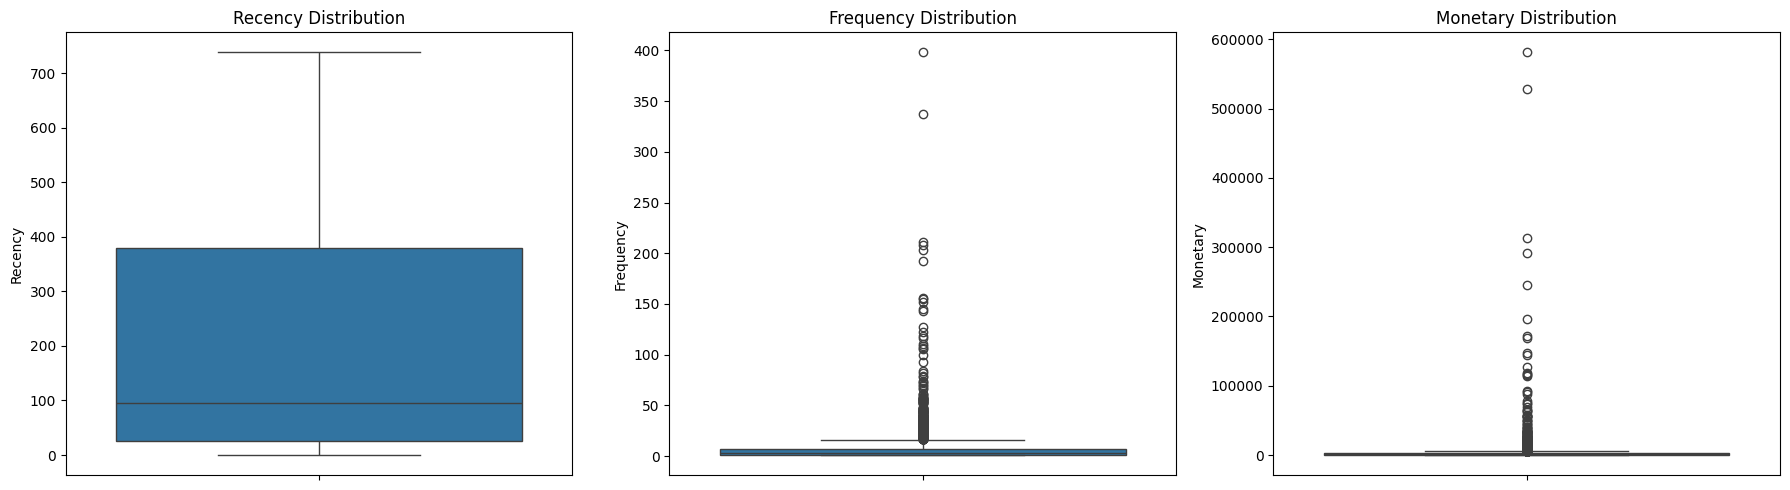

In [167]:
outlier_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, outlier_features):
    sns.boxplot(
        y=customer_segments_final[column],
        ax=ax
    )

    ax.set_title(f"{column} Distribution")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

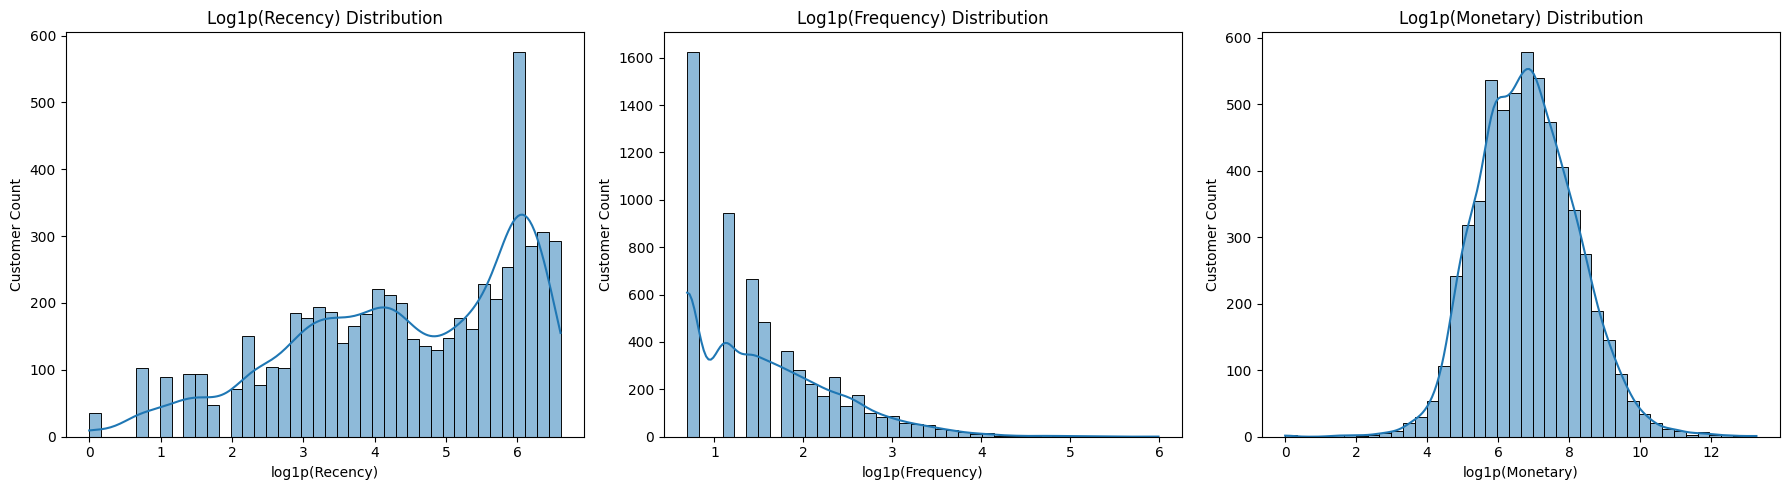

In [168]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(
    axes,
    ["Recency", "Frequency", "Monetary"]
):
    transformed_values = np.log1p(
        customer_segments_final[column]
    )

    sns.histplot(
        transformed_values,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Log1p({column}) Distribution")
    ax.set_xlabel(f"log1p({column})")
    ax.set_ylabel("Customer Count")

plt.tight_layout()
plt.show()

In [169]:
skewness_comparison = []

for column in ["Recency", "Frequency", "Monetary"]:

    original_skewness = customer_segments_final[column].skew()

    transformed_skewness = np.log1p(
        customer_segments_final[column]
    ).skew()

    skewness_comparison.append({
        "Feature": column,
        "Original_Skewness": original_skewness,
        "Log_Transformed_Skewness": transformed_skewness
    })

skewness_comparison_df = pd.DataFrame(skewness_comparison)

display(skewness_comparison_df.round(3))

,Feature,Original_Skewness,Log_Transformed_Skewness
0,Recency,0.887,-0.552
1,Frequency,12.654,1.002
2,Monetary,25.054,0.209


### 7.2 RFM Feature Preparation and Baseline K-Means

Transform skewed features, compare scaling approaches, and evaluate candidate K-Means cluster counts.

In [170]:
ml_features_candidate = customer_segments_final[
    ["Recency", "Frequency", "Monetary"]
].copy()

ml_features_candidate["Frequency"] = np.log1p(
    ml_features_candidate["Frequency"]
)

ml_features_candidate["Monetary"] = np.log1p(
    ml_features_candidate["Monetary"]
)

candidate_summary = ml_features_candidate.describe().T

candidate_summary["Skewness"] = (
    ml_features_candidate.skew()
)

display(candidate_summary.round(3))

,count,mean,std,min,25%,50%,75%,max,Skewness
Recency,5881.0,200.993,209.490,0.000,25.000,95.000,379.000,738.000,0.887
Frequency,5881.0,1.549,0.809,0.693,0.693,1.386,2.079,5.989,1.002
Monetary,5881.0,6.819,1.393,0.000,5.844,6.768,7.722,13.272,0.209


In [171]:
scaling_assessment = ml_features_candidate.agg(
    ["min", "max", "mean", "std"]
).T

scaling_assessment["Range"] = (
    scaling_assessment["max"]
    - scaling_assessment["min"]
)

display(scaling_assessment.round(3))

,min,max,mean,std,Range
Recency,0.000,738.000,200.993,209.490,738.000
Frequency,0.693,5.989,1.549,0.809,5.296
Monetary,0.000,13.272,6.819,1.393,13.272


In [172]:
standard_scaler = StandardScaler()

standard_scaled = pd.DataFrame(
    standard_scaler.fit_transform(ml_features_candidate),
    columns=ml_features_candidate.columns,
    index=ml_features_candidate.index
)

robust_scaler = RobustScaler()

robust_scaled = pd.DataFrame(
    robust_scaler.fit_transform(ml_features_candidate),
    columns=ml_features_candidate.columns,
    index=ml_features_candidate.index
)

scaling_comparison = pd.concat({
    "StandardScaler": standard_scaled.agg(["mean", "std", "min", "max"]).T,
    "RobustScaler": robust_scaled.agg(["median", "std", "min", "max"]).T
}, axis=1)

display(scaling_comparison.round(3))

StandardScaler                    RobustScaler                     
                    mean  std    min    max       median    std    min    max
Recency              0.0  1.0 -0.960  2.564          0.0  0.592 -0.268  1.816
Frequency            0.0  1.0 -1.058  5.485          0.0  0.584 -0.500  3.320
Monetary             0.0  1.0 -4.897  4.634          0.0  0.741 -3.602  3.462

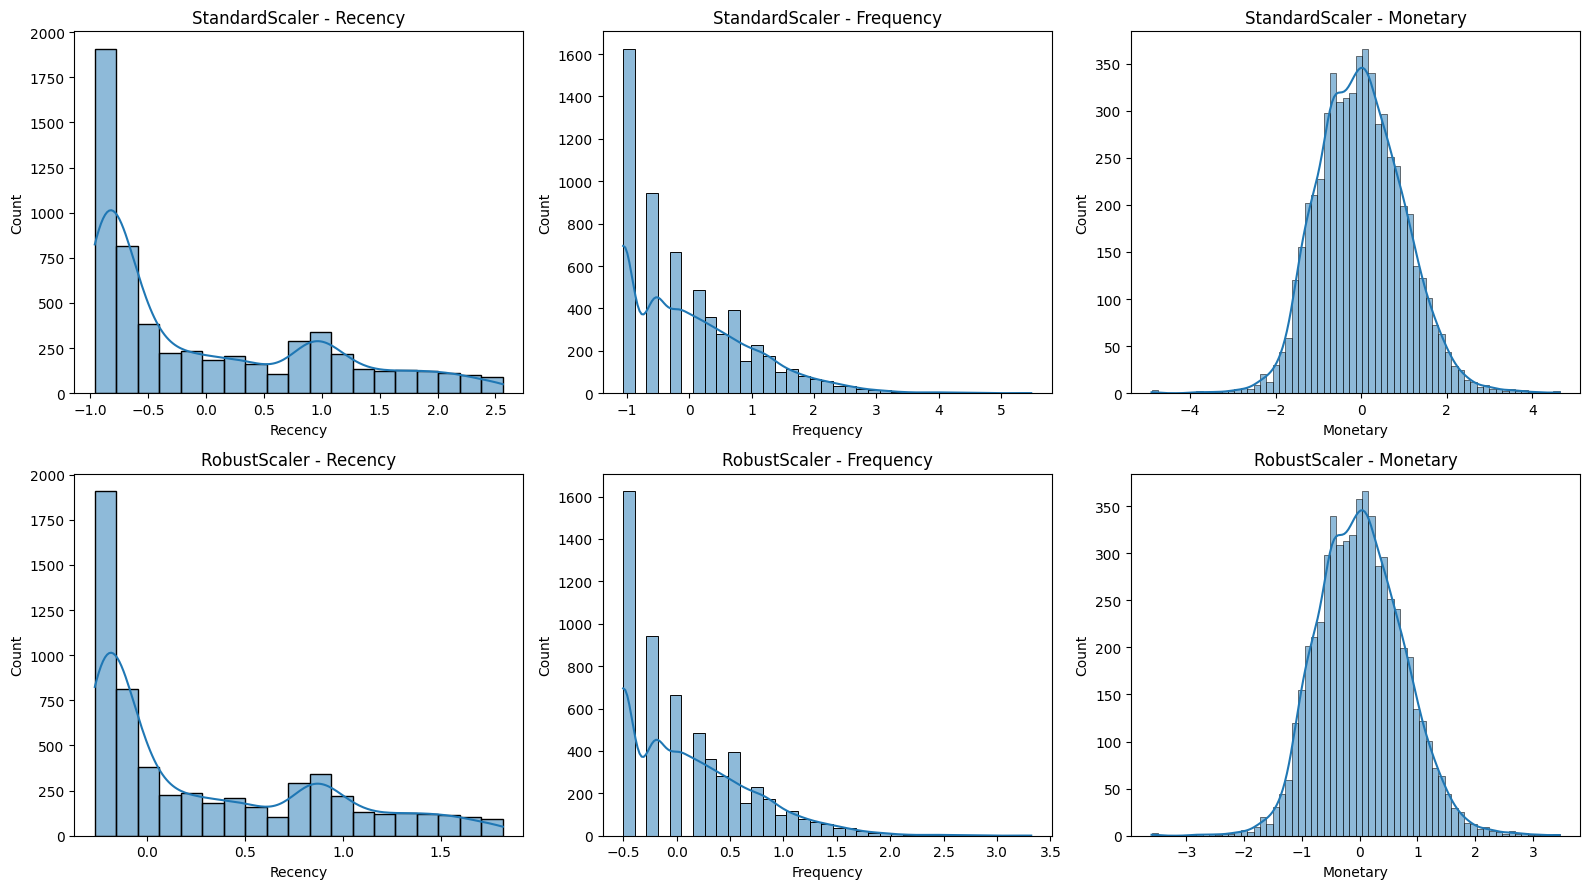

In [173]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, feature in enumerate(ml_features_candidate.columns):
    sns.histplot(
        standard_scaled[feature],
        kde=True,
        ax=axes[0, i]
    )
    axes[0, i].set_title(f"StandardScaler - {feature}")

    sns.histplot(
        robust_scaled[feature],
        kde=True,
        ax=axes[1, i]
    )
    axes[1, i].set_title(f"RobustScaler - {feature}")

plt.tight_layout()
plt.show()

In [174]:
clustering_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

clustering_data = ml_features_candidate[
    clustering_features
].copy()

print("Clustering dataset shape:", clustering_data.shape)

print("\nMissing values:")
display(clustering_data.isna().sum().to_frame("MissingValues"))

print("\nFeature statistics:")
display(
    clustering_data.describe().T.round(3)
)

print("\nFeature skewness:")
display(
    clustering_data.skew().to_frame("Skewness").round(3)
)

Clustering dataset shape: (5881, 3)

Missing values:


,MissingValues
Recency,0
Frequency,0
Monetary,0



Feature statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,5881.0,200.993,209.490,0.000,25.000,95.000,379.000,738.000
Frequency,5881.0,1.549,0.809,0.693,0.693,1.386,2.079,5.989
Monetary,5881.0,6.819,1.393,0.000,5.844,6.768,7.722,13.272



Feature skewness:


,Skewness
Recency,0.887
Frequency,1.002
Monetary,0.209


In [175]:
final_scaler = RobustScaler()

clustering_scaled = pd.DataFrame(
    final_scaler.fit_transform(clustering_data),
    columns=clustering_data.columns,
    index=clustering_data.index
)

print("Scaled dataset shape:", clustering_scaled.shape)

print("\nScaled feature statistics:")
display(
    clustering_scaled.describe().T.round(3)
)

print("\nScaled feature medians:")
display(
    clustering_scaled.median().to_frame("Median").round(3)
)

Scaled dataset shape: (5881, 3)

Scaled feature statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,5881.0,0.299,0.592,-0.268,-0.198,0.0,0.802,1.816
Frequency,5881.0,0.117,0.584,-0.500,-0.500,0.0,0.500,3.320
Monetary,5881.0,0.027,0.741,-3.602,-0.492,0.0,0.508,3.462



Scaled feature medians:


,Median
Recency,0.0
Frequency,0.0
Monetary,0.0


In [176]:
cluster_evaluation = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(clustering_scaled)

    cluster_evaluation.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette_Score": silhouette_score(
            clustering_scaled,
            labels
        )
    })

cluster_evaluation_df = pd.DataFrame(cluster_evaluation)

display(
    cluster_evaluation_df.round(4)
)

,K,Inertia,Silhouette_Score
0,2,3609.2305,0.4234
1,3,2462.6007,0.3821
2,4,1910.1713,0.3528
3,5,1545.9844,0.3648
4,6,1300.5109,0.3488
5,7,1183.1938,0.3352
6,8,1067.1765,0.3080
7,9,971.4681,0.3162
8,10,902.3002,0.3044


In [177]:
cluster_size_results = []

for k in [2, 3, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(clustering_scaled)

    cluster_counts = pd.Series(labels).value_counts().sort_index()

    for cluster_id, count in cluster_counts.items():

        cluster_size_results.append({
            "K": k,
            "Cluster": cluster_id,
            "Customer_Count": count,
            "Customer_Percentage": (
                count / len(clustering_scaled)
            ) * 100
        })

cluster_size_df = pd.DataFrame(cluster_size_results)

display(cluster_size_df.round(2))

,K,Cluster,Customer_Count,Customer_Percentage
0,2,0,2684,45.64
1,2,1,3197,54.36
2,3,0,1717,29.20
3,3,1,1701,28.92
4,3,2,2463,41.88
5,5,0,1707,29.03
6,5,1,1025,17.43
7,5,2,947,16.10
8,5,3,915,15.56
9,5,4,1287,21.88


In [178]:
cluster_profile_results = []

for k in [2, 3, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(clustering_scaled)

    profile_data = customer_segments_final[
        ["Recency", "Frequency", "Monetary"]
    ].copy()

    profile_data["Cluster"] = labels

    profile = profile_data.groupby("Cluster").agg(
        Customer_Count=("Recency", "size"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Recency=("Recency", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary=("Monetary", "mean")
    ).reset_index()

    profile["K"] = k

    cluster_profile_results.append(profile)

cluster_profiles_df = pd.concat(
    cluster_profile_results,
    ignore_index=True
)

display(
    cluster_profiles_df.round(2)
)

,Cluster,Customer_Count,Median_Recency,Median_Frequency,Median_Monetary,Mean_Recency,Mean_Frequency,Mean_Monetary,K
0,0,2684,31.0,7.0,2499.83,71.12,11.57,5924.62,2
1,1,3197,323.0,1.0,372.80,310.03,1.85,478.54,2
2,0,1717,448.0,1.0,298.00,472.84,1.56,430.78,3
3,1,1701,26.0,11.0,3946.03,61.52,15.72,8550.64,3
4,2,2463,64.0,3.0,774.90,107.81,3.07,871.81,3
5,0,1707,42.0,5.0,1603.99,65.12,5.62,1838.78,5
6,1,1025,515.0,1.0,205.17,519.32,1.18,220.58,5
7,2,947,18.0,15.0,6370.15,44.36,22.24,13190.28,5
8,3,915,396.0,3.0,866.05,405.19,3.10,1173.84,5
9,4,1287,66.0,2.0,356.85,97.77,1.77,389.59,5


In [179]:
comparison_data = customer_segments_final[
    ["Segment"]
].copy()

for k in [2, 3, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(clustering_scaled)

    comparison_data[f"Cluster_K{k}"] = labels


# Compare K=3 with RFM segments
print("RFM Segment Distribution within K=3 Clusters (%)")

k3_comparison = pd.crosstab(
    comparison_data["Cluster_K3"],
    comparison_data["Segment"],
    normalize="index"
) * 100

display(k3_comparison.round(1))


# Compare K=5 with RFM segments
print("\nRFM Segment Distribution within K=5 Clusters (%)")

k5_comparison = pd.crosstab(
    comparison_data["Cluster_K5"],
    comparison_data["Segment"],
    normalize="index"
) * 100

display(k5_comparison.round(1))

RFM Segment Distribution within K=3 Clusters (%)


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Cluster_K3,,,,,,,,,,,
0,10.9,0.0,1.5,74.8,4.3,8.4,0.0,0.2,0.0,0.0,0.0
1,0.0,69.3,0.1,0.0,8.2,0.0,19.9,0.0,0.0,1.1,1.5
2,8.3,3.8,24.2,3.5,7.2,2.4,9.9,9.5,22.3,3.4,5.6



RFM Segment Distribution within K=5 Clusters (%)


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Cluster_K5,,,,,,,,,,,
0,2.0,30.2,9.0,0.0,5.1,0.0,26.1,0.2,12.2,5.9,9.3
1,1.7,0.0,0.0,98.0,0.0,0.3,0.0,0.0,0.0,0.0,0.0
2,0.0,79.9,0.0,0.0,5.1,0.0,14.5,0.0,0.0,0.1,0.4
3,35.0,0.0,0.0,16.8,28.1,20.1,0.0,0.0,0.0,0.0,0.0
4,1.6,0.0,36.4,16.3,0.0,1.2,0.0,18.2,26.4,0.0,0.0


### 7.3 Alternative Customer-Value Features

Add Average Order Value (AOV) to create a second feature perspective and evaluate whether it provides a useful alternative to basic RFM features.

In [180]:
customer_value_features = customer_segments_final[
    ["Customer ID", "Frequency", "Monetary"]
].copy()

customer_value_features["AOV"] = (
    customer_value_features["Monetary"] /
    customer_value_features["Frequency"]
)

print("Customer Value Features Shape:")
print(customer_value_features.shape)

print("\nAOV Descriptive Statistics:")

display(
    customer_value_features[
        ["Frequency", "Monetary", "AOV"]
    ].describe().round(2)
)

print("\nAOV Skewness:")
display(
    customer_value_features[
        ["Frequency", "Monetary", "AOV"]
    ].skew().round(3)
)

print("\nZero Values:")
display(
    customer_value_features[
        ["Frequency", "Monetary", "AOV"]
    ].eq(0).sum()
)

Customer Value Features Shape:
(5881, 4)

AOV Descriptive Statistics:


,Frequency,Monetary,AOV
count,5881.00,5881.00,5881.00
mean,6.29,2964.05,386.67
std,13.01,14443.05,1214.06
min,1.00,0.00,0.00
25%,1.00,344.00,178.27
50%,3.00,868.77,280.91
75%,7.00,2257.32,415.95
max,398.00,580987.04,84236.25



AOV Skewness:


Frequency    12.654
Monetary     25.054
AOV          57.132
dtype: float64


Zero Values:


Frequency    0
Monetary     3
AOV          3
dtype: int64

In [181]:
aov_q1 = customer_value_features["AOV"].quantile(0.25)
aov_q3 = customer_value_features["AOV"].quantile(0.75)

aov_iqr = aov_q3 - aov_q1

aov_lower_bound = aov_q1 - 1.5 * aov_iqr
aov_upper_bound = aov_q3 + 1.5 * aov_iqr

aov_outliers = customer_value_features[
    (customer_value_features["AOV"] < aov_lower_bound) |
    (customer_value_features["AOV"] > aov_upper_bound)
]

aov_outlier_summary = pd.DataFrame({
    "Metric": [
        "Q1",
        "Q3",
        "IQR",
        "Lower_Bound",
        "Upper_Bound",
        "Outlier_Count",
        "Outlier_Percentage"
    ],
    "Value": [
        aov_q1,
        aov_q3,
        aov_iqr,
        aov_lower_bound,
        aov_upper_bound,
        len(aov_outliers),
        len(aov_outliers) / len(customer_value_features) * 100
    ]
})

display(aov_outlier_summary.round(2))

,Metric,Value
0,Q1,178.27
1,Q3,415.95
2,IQR,237.68
3,Lower_Bound,-178.25
4,Upper_Bound,772.46
5,Outlier_Count,389.00
6,Outlier_Percentage,6.61


In [182]:
features_to_transform = [
    "Frequency",
    "Monetary",
    "AOV"
]

log_transformation_results = []

for feature in features_to_transform:

    original_skewness = customer_value_features[feature].skew()

    log_skewness = np.log1p(
        customer_value_features[feature]
    ).skew()

    log_transformation_results.append({
        "Feature": feature,
        "Original_Skewness": original_skewness,
        "Log_Transformed_Skewness": log_skewness
    })

log_transformation_comparison = pd.DataFrame(
    log_transformation_results
)

display(log_transformation_comparison.round(3))

,Feature,Original_Skewness,Log_Transformed_Skewness
0,Frequency,12.654,1.002
1,Monetary,25.054,0.209
2,AOV,57.132,-0.155


In [183]:
alternative_features = [
    "Frequency",
    "Monetary",
    "AOV"
]

alternative_clustering_data = customer_value_features[
    alternative_features
].copy()

alternative_clustering_data = np.log1p(
    alternative_clustering_data
)

print("Alternative Clustering Dataset Shape:")
print(alternative_clustering_data.shape)

print("\nMissing Values:")
display(alternative_clustering_data.isnull().sum())

print("\nFeature Statistics:")
display(alternative_clustering_data.describe().round(3))

print("\nFeature Skewness:")
display(alternative_clustering_data.skew().round(3))

Alternative Clustering Dataset Shape:
(5881, 3)

Missing Values:


Frequency    0
Monetary     0
AOV          0
dtype: int64


Feature Statistics:


,Frequency,Monetary,AOV
count,5881.000,5881.000,5881.000
mean,1.549,6.819,5.620
std,0.809,1.393,0.746
min,0.693,0.000,0.000
25%,0.693,5.844,5.189
50%,1.386,6.768,5.642
75%,2.079,7.722,6.033
max,5.989,13.272,11.341



Feature Skewness:


Frequency    1.002
Monetary     0.209
AOV         -0.155
dtype: float64

In [184]:
alternative_standard_scaler = StandardScaler()
alternative_robust_scaler = RobustScaler()

alternative_standard_scaled = alternative_standard_scaler.fit_transform(
    alternative_clustering_data
)

alternative_robust_scaled = alternative_robust_scaler.fit_transform(
    alternative_clustering_data
)

alternative_scaling_comparison = pd.DataFrame({
    "Feature": alternative_features,
    "Standard_Mean": alternative_standard_scaled.mean(axis=0),
    "Standard_Std": alternative_standard_scaled.std(axis=0),
    "Robust_Median": np.median(alternative_robust_scaled, axis=0),
    "Robust_IQR": (
        np.percentile(alternative_robust_scaled, 75, axis=0) -
        np.percentile(alternative_robust_scaled, 25, axis=0)
    )
})

display(alternative_scaling_comparison.round(3))

,Feature,Standard_Mean,Standard_Std,Robust_Median,Robust_IQR
0,Frequency,0.0,1.0,0.0,1.0
1,Monetary,0.0,1.0,0.0,1.0
2,AOV,-0.0,1.0,0.0,1.0


In [185]:
alternative_final_scaler = RobustScaler()

alternative_clustering_scaled = alternative_final_scaler.fit_transform(
    alternative_clustering_data
)

alternative_kmeans_results = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(
        alternative_clustering_scaled
    )

    silhouette = silhouette_score(
        alternative_clustering_scaled,
        cluster_labels
    )

    alternative_kmeans_results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette
    })

alternative_cluster_evaluation_df = pd.DataFrame(
    alternative_kmeans_results
)

display(alternative_cluster_evaluation_df.round(4))

,K,Inertia,Silhouette
0,2,5523.7363,0.3898
1,3,4101.8597,0.3431
2,4,3289.9059,0.3501
3,5,2702.0336,0.3463
4,6,2286.1619,0.3481
5,7,2003.2308,0.3524
6,8,1771.7895,0.3437
7,9,1598.7709,0.3379
8,10,1437.7260,0.3435


In [186]:
selected_k_values = [3, 5]

alternative_cluster_profiles = []

for k in selected_k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        alternative_clustering_scaled
    )

    profile_data = customer_value_features.copy()
    profile_data["Cluster"] = labels

    profile = profile_data.groupby("Cluster").agg(
        Customer_Count=("Customer ID", "count"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Median_AOV=("AOV", "median"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary=("Monetary", "mean"),
        Mean_AOV=("AOV", "mean")
    ).reset_index()

    profile["K"] = k
    profile["Customer_Share"] = (
        profile["Customer_Count"] /
        len(profile_data) * 100
    )

    alternative_cluster_profiles.append(profile)

alternative_cluster_profiles_df = pd.concat(
    alternative_cluster_profiles,
    ignore_index=True
)

display(
    alternative_cluster_profiles_df.round(2)
)

,Cluster,Customer_Count,Median_Frequency,Median_Monetary,Median_AOV,Mean_Frequency,Mean_Monetary,Mean_AOV,K,Customer_Share
0,0,2844,3.0,864.36,308.16,3.32,967.87,352.62,3,48.36
1,1,1523,1.0,193.15,133.21,2.04,245.13,133.08,3,25.90
2,2,1514,11.0,4402.04,433.68,16.13,9448.88,705.73,3,25.74
3,0,739,17.0,7451.13,454.77,24.27,15294.06,583.47,5,12.57
4,1,1733,2.0,445.15,291.88,1.75,508.24,300.39,5,29.47
5,2,1108,1.0,157.83,117.54,1.86,200.19,112.91,5,18.84
6,3,1499,6.0,1624.05,246.42,7.63,1835.81,252.11,5,25.49
7,4,802,3.0,1800.62,641.31,3.14,2836.38,1021.48,5,13.64


In [187]:
alternative_rfm_comparisons = {}

for k in [3, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        alternative_clustering_scaled
    )

    comparison_data = pd.DataFrame({
        "Cluster": labels,
        "Segment": customer_segments_final["Segment"].values
    })

    cluster_segment_counts = pd.crosstab(
        comparison_data["Cluster"],
        comparison_data["Segment"]
    )

    cluster_segment_percentages = (
        pd.crosstab(
            comparison_data["Cluster"],
            comparison_data["Segment"],
            normalize="index"
        ) * 100
    )

    alternative_rfm_comparisons[k] = {
        "Counts": cluster_segment_counts,
        "Percentages": cluster_segment_percentages
    }

    print(f"\n{'=' * 60}")
    print(f"RFM Segment Distribution - K={k} (Counts)")
    print(f"{'=' * 60}")

    display(cluster_segment_counts)

    print(f"\nRFM Segment Distribution - K={k} (%)")

    display(cluster_segment_percentages.round(1))


RFM Segment Distribution - K=3 (Counts)


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Cluster,,,,,,,,,,,
0,270,278,362,554,218,202,277,116,381,67,119
1,121,2,249,815,0,0,49,119,168,0,0
2,0,992,11,0,174,0,257,3,0,34,43



RFM Segment Distribution - K=3 (%)


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Cluster,,,,,,,,,,,
0,9.5,9.8,12.7,19.5,7.7,7.1,9.7,4.1,13.4,2.4,4.2
1,7.9,0.1,16.3,53.5,0.0,0.0,3.2,7.8,11.0,0.0,0.0
2,0.0,65.5,0.7,0.0,11.5,0.0,17.0,0.2,0.0,2.2,2.8



RFM Segment Distribution - K=5 (Counts)


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Cluster,,,,,,,,,,,
0,0,592,0,0,40,0,107,0,0,0,0
1,146,0,310,738,0,97,0,128,312,0,2
2,91,0,193,613,0,0,7,81,123,0,0
3,154,580,51,0,153,0,413,0,88,19,41
4,0,100,68,18,199,105,56,29,26,82,119



RFM Segment Distribution - K=5 (%)


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Cluster,,,,,,,,,,,
0,0.0,80.1,0.0,0.0,5.4,0.0,14.5,0.0,0.0,0.0,0.0
1,8.4,0.0,17.9,42.6,0.0,5.6,0.0,7.4,18.0,0.0,0.1
2,8.2,0.0,17.4,55.3,0.0,0.0,0.6,7.3,11.1,0.0,0.0
3,10.3,38.7,3.4,0.0,10.2,0.0,27.6,0.0,5.9,1.3,2.7
4,0.0,12.5,8.5,2.2,24.8,13.1,7.0,3.6,3.2,10.2,14.8


In [188]:
agreement_results = []

for k in [3, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    alternative_labels = kmeans.fit_predict(
        alternative_clustering_scaled
    )

    rfm_labels = customer_segments_final["Segment"].values

    ari = adjusted_rand_score(
        rfm_labels,
        alternative_labels
    )

    nmi = normalized_mutual_info_score(
        rfm_labels,
        alternative_labels
    )

    agreement_results.append({
        "K": k,
        "ARI": ari,
        "NMI": nmi
    })

alternative_agreement_df = pd.DataFrame(
    agreement_results
)

display(alternative_agreement_df.round(4))

,K,ARI,NMI
0,3,0.1392,0.2541
1,5,0.2199,0.3543


## 8. Purchase-Timing Features

Derive customer-level purchase intervals from distinct purchase dates. Customers without enough purchase history are retained in the broader customer population and are handled explicitly in later coverage checks.

In [189]:
purchase_dates = (
    analysis_data[
        ["Customer ID", "InvoiceDate"]
    ]
    .dropna()
    .drop_duplicates()
    .sort_values(["Customer ID", "InvoiceDate"])
    .copy()
)

purchase_date_summary = (
    purchase_dates
    .groupby("Customer ID")
    .agg(
        Purchase_Date_Count=("InvoiceDate", "nunique"),
        First_Purchase_Date=("InvoiceDate", "min"),
        Last_Purchase_Date=("InvoiceDate", "max")
    )
    .reset_index()
)

print("Purchase Date Summary Shape:")
print(purchase_date_summary.shape)

print("\nPurchase Date Count Distribution:")

display(
    purchase_date_summary[
        "Purchase_Date_Count"
    ].describe().round(2)
)

print("\nCustomers by Number of Purchase Dates:")

display(
    purchase_date_summary[
        "Purchase_Date_Count"
    ].value_counts()
    .sort_index()
    .head(15)
)

Purchase Date Summary Shape:
(5942, 4)

Purchase Date Count Distribution:


count    5942.00
mean        7.51
std        15.84
min         1.00
25%         2.00
50%         4.00
75%         8.00
max       508.00
Name: Purchase_Date_Count, dtype: float64


Customers by Number of Purchase Dates:


Purchase_Date_Count
1     1460
2      875
3      624
4      485
5      389
6      286
7      249
8      176
9      165
10     128
11     107
12     105
13      94
14      94
15      62
Name: count, dtype: int64

In [190]:
rfm_customer_ids = set(
    customer_segments_final["Customer ID"]
)

transaction_customer_ids = set(
    purchase_date_summary["Customer ID"]
)

extra_customers = transaction_customer_ids - rfm_customer_ids
missing_customers = rfm_customer_ids - transaction_customer_ids

print("RFM Customers:", len(rfm_customer_ids))
print("Transaction Customers:", len(transaction_customer_ids))
print("Customers in Transactions but not RFM:", len(extra_customers))
print("Customers in RFM but not Transactions:", len(missing_customers))

purchase_date_summary_rfm = purchase_date_summary[
    purchase_date_summary["Customer ID"].isin(rfm_customer_ids)
].copy()

print("\nAligned Purchase Date Summary Shape:")
print(purchase_date_summary_rfm.shape)

print("\nPurchase Date Count Distribution - RFM Customers:")

display(
    purchase_date_summary_rfm[
        "Purchase_Date_Count"
    ].describe().round(2)
)

print("\nCustomers with One Purchase Date:")
print(
    (purchase_date_summary_rfm["Purchase_Date_Count"] == 1).sum()
)

print("\nCustomers with at Least Two Purchase Dates:")
print(
    (purchase_date_summary_rfm["Purchase_Date_Count"] >= 2).sum()
)

RFM Customers: 5881
Transaction Customers: 5942
Customers in Transactions but not RFM: 61
Customers in RFM but not Transactions: 0

Aligned Purchase Date Summary Shape:
(5881, 4)

Purchase Date Count Distribution - RFM Customers:


count    5881.00
mean        7.58
std        15.90
min         1.00
25%         2.00
50%         4.00
75%         8.00
max       508.00
Name: Purchase_Date_Count, dtype: float64


Customers with One Purchase Date:
1403

Customers with at Least Two Purchase Dates:
4478


In [191]:
daily_purchase_dates = (
    analysis_data[["Customer ID", "InvoiceDate"]]
    .dropna()
    .assign(PurchaseDate=lambda data: data["InvoiceDate"].dt.normalize())
    [["Customer ID", "PurchaseDate"]]
    .drop_duplicates()
    .sort_values(["Customer ID", "PurchaseDate"])
    .reset_index(drop=True)
)

daily_purchase_dates["Interpurchase_Days"] = (
    daily_purchase_dates
    .groupby("Customer ID")["PurchaseDate"]
    .diff()
    .dt.days
)

daily_purchase_dates = daily_purchase_dates.loc[
    daily_purchase_dates["Customer ID"].isin(rfm_customer_ids)
].copy()

print("Daily purchase-date rows:", len(daily_purchase_dates))
print("Customers:", daily_purchase_dates["Customer ID"].nunique())
print("Interpurchase intervals:", daily_purchase_dates["Interpurchase_Days"].notna().sum())

Daily purchase-date rows: 38439
Customers: 5881
Interpurchase intervals: 32558


In [192]:
interpurchase_intervals = daily_purchase_dates[
    "Interpurchase_Days"
].dropna()

print("Interpurchase Interval Statistics:")
display(
    interpurchase_intervals.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\nInterval Distribution:")

interval_groups = pd.cut(
    interpurchase_intervals,
    bins=[0, 7, 30, 60, 90, 180, 365, float("inf")],
    labels=[
        "1-7 days",
        "8-30 days",
        "31-60 days",
        "61-90 days",
        "91-180 days",
        "181-365 days",
        "Over 365 days"
    ]
)

display(
    interval_groups.value_counts()
    .sort_index()
    .rename("Interval_Count")
    .to_frame()
)

print("\nZero-Day Intervals:")
print((interpurchase_intervals == 0).sum())

print("\nNegative Intervals:")
print((interpurchase_intervals < 0).sum())

Interpurchase Interval Statistics:


count    32558.00
mean        50.33
std         73.75
min          1.00
25%          8.00
50%         23.00
75%         58.00
90%        130.00
95%        201.00
99%        364.43
max        701.00
Name: Interpurchase_Days, dtype: float64


Interval Distribution:


,Interval_Count
Interpurchase_Days,
1-7 days,7756
8-30 days,10986
31-60 days,5975
61-90 days,2638
91-180 days,3247
181-365 days,1639
Over 365 days,317



Zero-Day Intervals:
0

Negative Intervals:
0


In [193]:
customer_timing_features = (
    daily_purchase_dates
    .groupby("Customer ID")
    .agg(
        Average_Interpurchase_Days=(
            "Interpurchase_Days", "mean"
        ),
        Interpurchase_Std_Days=(
            "Interpurchase_Days", "std"
        ),
        Interpurchase_Interval_Count=(
            "Interpurchase_Days", "count"
        )
    )
    .reset_index()
)

customer_timing_features["Purchase_Regularity_CV"] = (
    customer_timing_features["Interpurchase_Std_Days"] /
    customer_timing_features["Average_Interpurchase_Days"]
)

print("Customer Timing Features Shape:")
print(customer_timing_features.shape)

print("\nFeature Statistics:")
display(
    customer_timing_features[
        [
            "Average_Interpurchase_Days",
            "Interpurchase_Std_Days",
            "Purchase_Regularity_CV"
        ]
    ].describe().round(3)
)

print("\nFeature Availability:")
print(
    customer_timing_features[
        [
            "Average_Interpurchase_Days",
            "Interpurchase_Std_Days",
            "Purchase_Regularity_CV"
        ]
    ].notna().sum()
)

print("\nCustomers with Missing Regularity:")
print(
    customer_timing_features[
        "Purchase_Regularity_CV"
    ].isna().sum()
)

print("\nCustomers with Available Regularity:")
print(
    customer_timing_features[
        "Purchase_Regularity_CV"
    ].notna().sum()
)

Customer Timing Features Shape:
(5881, 5)

Feature Statistics:


,Average_Interpurchase_Days,Interpurchase_Std_Days,Purchase_Regularity_CV
count,4396.000,3459.000,3459.000
mean,94.419,68.769,0.889
std,94.589,61.130,0.378
min,1.000,0.000,0.000
25%,33.814,26.630,0.643
50%,64.174,51.876,0.867
75%,120.233,90.237,1.120
max,691.000,483.661,3.249



Feature Availability:
Average_Interpurchase_Days    4396
Interpurchase_Std_Days        3459
Purchase_Regularity_CV        3459
dtype: int64

Customers with Missing Regularity:
2422

Customers with Available Regularity:
3459


In [194]:
interval_count_distribution = (
    customer_timing_features[
        "Interpurchase_Interval_Count"
    ]
    .value_counts()
    .sort_index()
    .rename("Customer_Count")
    .to_frame()
)

interval_count_distribution["Customer_Share_%"] = (
    interval_count_distribution["Customer_Count"]
    / len(customer_timing_features)
    * 100
)

print("Interpurchase Interval Count Distribution:")
display(interval_count_distribution.round(2))

print("\nCustomers by Feature Availability:")

print(
    "No intervals:",
    (
        customer_timing_features["Interpurchase_Interval_Count"] == 0
    ).sum()
)

print(
    "Exactly one interval:",
    (
        customer_timing_features["Interpurchase_Interval_Count"] == 1
    ).sum()
)

print(
    "At least two intervals:",
    (
        customer_timing_features["Interpurchase_Interval_Count"] >= 2
    ).sum()
)

print(
    "Total customers:",
    len(customer_timing_features)
)

Interpurchase Interval Count Distribution:


,Customer_Count,Customer_Share_%
Interpurchase_Interval_Count,,
0,1485,25.25
1,937,15.93
2,636,10.81
3,477,8.11
4,400,6.80
...,...,...
181,1,0.02
193,1,0.02
201,1,0.02



Customers by Feature Availability:
No intervals: 1485
Exactly one interval: 937
At least two intervals: 3459
Total customers: 5881


In [195]:
customer_timing_analysis = customer_segments_final[
    ["Customer ID", "Recency", "Frequency", "Monetary", "Segment"]
].merge(
    customer_timing_features[
        [
            "Customer ID",
            "Interpurchase_Interval_Count",
            "Average_Interpurchase_Days",
            "Purchase_Regularity_CV"
        ]
    ],
    on="Customer ID",
    how="left"
)

customer_timing_analysis["Regularity_Available"] = (
    customer_timing_analysis["Purchase_Regularity_CV"].notna()
)

availability_comparison = (
    customer_timing_analysis
    .groupby("Regularity_Available")
    .agg(
        Customer_Count=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median")
    )
)

availability_comparison["Customer_Share_%"] = (
    availability_comparison["Customer_Count"]
    / len(customer_timing_analysis)
    * 100
)

print("RFM Comparison by Regularity Availability:")
display(availability_comparison.round(2))

print("\nRegularity Availability by RFM Segment:")

display(
    pd.crosstab(
        customer_timing_analysis["Segment"],
        customer_timing_analysis["Regularity_Available"],
        normalize="index"
    ).mul(100).round(2)
)

RFM Comparison by Regularity Availability:


,Customer_Count,Median_Recency,Median_Frequency,Median_Monetary,Customer_Share_%
Regularity_Available,,,,,
False,2422,332.0,1.0,309.27,41.18
True,3459,50.0,6.0,1801.33,58.82



Regularity Availability by RFM Segment:


Regularity_Available,False,True
Segment,,
At Risk,10.74,89.26
Champions,0.16,99.84
Developing Customers,61.90,38.10
Hibernating,93.57,6.43
High-Value At Risk,17.09,82.91
Low-Frequency At Risk,78.22,21.78
Loyal Customers,0.17,99.83
New Customers,99.58,0.42
Potential Loyalists,40.26,59.74


In [196]:
average_interpurchase = (
    customer_timing_features[
        "Average_Interpurchase_Days"
    ].dropna()
)

print("Average Interpurchase Days Statistics:")

display(
    average_interpurchase.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\nSkewness Comparison:")

print(
    "Original:",
    round(average_interpurchase.skew(), 3)
)

print(
    "Log1p:",
    round(np.log1p(average_interpurchase).skew(), 3)
)

print("\nMissing Values:")
print(
    customer_timing_features[
        "Average_Interpurchase_Days"
    ].isna().sum()
)

Average Interpurchase Days Statistics:


count    4396.00
mean       94.42
std        94.59
min         1.00
25%        33.81
50%        64.17
75%       120.23
90%       206.00
95%       297.50
99%       455.10
max       691.00
Name: Average_Interpurchase_Days, dtype: float64


Skewness Comparison:
Original: 2.31
Log1p: -0.413

Missing Values:
1485


### 8.1 Temporal Clustering

Prepare a temporal feature space using Recency and average interpurchase time, then evaluate candidate cluster counts and compare the resulting groups with the RFM segments.

In [197]:
temporal_clustering_data = customer_timing_analysis[
    [
        "Customer ID",
        "Recency",
        "Average_Interpurchase_Days"
    ]
].copy()

temporal_clustering_data["Average_Interpurchase_Days"] = (
    np.log1p(
        temporal_clustering_data["Average_Interpurchase_Days"]
    )
)

print("Temporal Clustering Dataset Shape:")
print(temporal_clustering_data.shape)

print("\nMissing Values:")
display(
    temporal_clustering_data.isna().sum().to_frame(
        name="Missing_Count"
    )
)

print("\nFeature Statistics:")
display(
    temporal_clustering_data[
        ["Recency", "Average_Interpurchase_Days"]
    ].describe().round(3)
)

print("\nCustomers with Complete Temporal Features:")
print(
    temporal_clustering_data[
        ["Recency", "Average_Interpurchase_Days"]
    ].notna().all(axis=1).sum()
)

print("\nCustomers with Missing Temporal Features:")
print(
    temporal_clustering_data[
        ["Recency", "Average_Interpurchase_Days"]
    ].isna().any(axis=1).sum()
)

Temporal Clustering Dataset Shape:
(5881, 3)

Missing Values:


,Missing_Count
Customer ID,0
Recency,0
Average_Interpurchase_Days,1485



Feature Statistics:


,Recency,Average_Interpurchase_Days
count,5881.000,4396.000
mean,200.993,4.134
std,209.490,0.975
min,0.000,0.693
25%,25.000,3.550
50%,95.000,4.177
75%,379.000,4.798
max,738.000,6.540



Customers with Complete Temporal Features:
4396

Customers with Missing Temporal Features:
1485


In [198]:
temporal_clustering_complete = (
    temporal_clustering_data
    .dropna(
        subset=[
            "Recency",
            "Average_Interpurchase_Days"
        ]
    )
    .copy()
)

temporal_clustering_features = [
    "Recency",
    "Average_Interpurchase_Days"
]

temporal_clustering_input = (
    temporal_clustering_complete[
        temporal_clustering_features
    ].copy()
)

temporal_final_scaler = RobustScaler()

temporal_clustering_scaled = (
    temporal_final_scaler.fit_transform(
        temporal_clustering_input
    )
)

print("Complete Dataset Shape:")
print(temporal_clustering_complete.shape)

print("\nScaled Dataset Shape:")
print(temporal_clustering_scaled.shape)

print("\nMissing Values After Preparation:")
print(
    temporal_clustering_input.isna().sum()
)

print("\nScaled Feature Statistics:")

display(
    pd.DataFrame(
        temporal_clustering_scaled,
        columns=temporal_clustering_features
    ).describe().round(3)
)

Complete Dataset Shape:
(4396, 3)

Scaled Dataset Shape:
(4396, 2)

Missing Values After Preparation:
Recency                       0
Average_Interpurchase_Days    0
dtype: int64

Scaled Feature Statistics:


,Recency,Average_Interpurchase_Days
count,4396.000,4396.000
mean,0.386,-0.034
std,0.781,0.781
min,-0.283,-2.792
25%,-0.197,-0.503
50%,0.000,0.000
75%,0.803,0.497
max,3.018,1.893


In [199]:
temporal_kmeans_results = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(
        temporal_clustering_scaled
    )

    silhouette = silhouette_score(
        temporal_clustering_scaled,
        cluster_labels
    )

    temporal_kmeans_results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette
    })

temporal_kmeans_evaluation = pd.DataFrame(
    temporal_kmeans_results
)

print("Temporal Clustering Evaluation:")
display(
    temporal_kmeans_evaluation.round(4)
)

print("\nBest K by Silhouette:")
display(
    temporal_kmeans_evaluation.loc[
        temporal_kmeans_evaluation["Silhouette"].idxmax()
    ]
)

Temporal Clustering Evaluation:


,K,Inertia,Silhouette
0,2,3175.8754,0.4805
1,3,1951.5895,0.4214
2,4,1473.2996,0.4238
3,5,1127.4042,0.4025
4,6,966.6708,0.3953
5,7,837.7805,0.3633
6,8,723.8413,0.3896
7,9,647.3187,0.3910
8,10,577.1614,0.3773



Best K by Silhouette:


K                2.000000
Inertia       3175.875425
Silhouette       0.480485
Name: 0, dtype: float64

In [200]:
temporal_cluster_profiles = {}

for k in [2, 4]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        temporal_clustering_scaled
    )

    cluster_data = temporal_clustering_complete.copy()
    cluster_data["Cluster"] = labels

    profile = (
        cluster_data
        .groupby("Cluster")
        .agg(
            Customer_Count=("Customer ID", "count"),
            Median_Recency=("Recency", "median"),
            Mean_Recency=("Recency", "mean"),
            Median_Interpurchase_Days=(
                "Average_Interpurchase_Days",
                lambda x: np.expm1(x.median())
            ),
            Mean_Interpurchase_Days=(
                "Average_Interpurchase_Days",
                lambda x: np.expm1(x.mean())
            )
        )
    )

    profile["Customer_Share_%"] = (
        profile["Customer_Count"]
        / len(cluster_data)
        * 100
    )

    temporal_cluster_profiles[k] = profile

    print(f"\nTemporal Cluster Profiles - K={k}")
    display(profile.round(2))


Temporal Cluster Profiles - K=2


,Customer_Count,Median_Recency,Mean_Recency,Median_Interpurchase_Days,Mean_Interpurchase_Days,Customer_Share_%
Cluster,,,,,,
0,1065,408.0,424.09,57.0,48.44,24.23
1,3331,35.0,61.10,66.0,66.29,75.77



Temporal Cluster Profiles - K=4


,Customer_Count,Median_Recency,Mean_Recency,Median_Interpurchase_Days,Mean_Interpurchase_Days,Customer_Share_%
Cluster,,,,,,
0,1665,22.0,42.20,36.10,31.26,37.88
1,1586,52.0,71.41,123.12,137.74,36.08
2,739,383.0,385.50,95.00,102.34,16.81
3,406,438.0,460.05,20.00,15.57,9.24


In [201]:
temporal_rfm_comparison = (
    temporal_clustering_complete[
        ["Customer ID"]
    ]
    .merge(
        customer_segments_final[
            ["Customer ID", "Segment"]
        ],
        on="Customer ID",
        how="left"
    )
)

temporal_comparison_results = []

for k in [2, 4]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        temporal_clustering_scaled
    )

    comparison_data = temporal_rfm_comparison.copy()
    comparison_data["Temporal_Cluster"] = labels

    cross_tab = pd.crosstab(
        comparison_data["Temporal_Cluster"],
        comparison_data["Segment"],
        normalize="index"
    ) * 100

    ari = adjusted_rand_score(
        comparison_data["Segment"],
        comparison_data["Temporal_Cluster"]
    )

    nmi = normalized_mutual_info_score(
        comparison_data["Segment"],
        comparison_data["Temporal_Cluster"]
    )

    temporal_comparison_results.append({
        "K": k,
        "ARI": ari,
        "NMI": nmi
    })

    print(f"\nRFM Segment Distribution - Temporal K={k}")
    display(cross_tab.round(1))

temporal_rfm_agreement = pd.DataFrame(
    temporal_comparison_results
)

print("\nAgreement with RFM Segmentation:")
display(temporal_rfm_agreement.round(4))


RFM Segment Distribution - Temporal K=2


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Temporal_Cluster,,,,,,,,,,,
0,27.9,0.0,0.4,33.4,27.0,11.3,0.0,0.0,0.0,0.0,0.0
1,2.7,38.2,11.9,1.7,2.5,0.7,17.5,0.6,16.3,3.0,4.8



RFM Segment Distribution - Temporal K=4


Segment,At Risk,Champions,Developing Customers,Hibernating,High-Value At Risk,Low-Frequency At Risk,Loyal Customers,New Customers,Potential Loyalists,Promising Customers,Recent High-Value Customers
Temporal_Cluster,,,,,,,,,,,
0,1.0,56.1,7.1,0.5,1.9,0.2,14.5,1.3,12.3,1.0,4.1
1,2.3,21.3,17.5,2.0,2.0,0.8,21.6,0.0,21.3,5.3,5.8
2,34.0,0.0,0.0,28.8,26.5,10.7,0.0,0.0,0.0,0.0,0.0
3,20.7,0.0,1.2,38.9,27.3,11.8,0.0,0.0,0.0,0.0,0.0



Agreement with RFM Segmentation:


,K,ARI,NMI
0,2,0.1614,0.3054
1,4,0.2037,0.3073


In [202]:
assert len(clustering_data) == len(customer_segments_final)
assert len(alternative_clustering_data) == len(customer_value_features)

assert clustering_data.index.equals(customer_segments_final.index)
assert alternative_clustering_data.index.equals(customer_value_features.index)

# 2. Reattach actual Customer IDs
rfm_data = clustering_data.copy()
rfm_data.insert(
    0,
    "Customer ID",
    customer_segments_final["Customer ID"].to_numpy()
)

value_data = alternative_clustering_data.copy()
value_data.insert(
    0,
    "Customer ID",
    customer_value_features["Customer ID"].to_numpy()
)

temporal_data = temporal_clustering_complete.copy()

for df in [rfm_data, value_data, temporal_data]:
    df["Customer ID"] = pd.to_numeric(
        df["Customer ID"],
        errors="raise"
    )

common_customer_ids = sorted(
    set(rfm_data["Customer ID"])
    .intersection(value_data["Customer ID"])
    .intersection(temporal_data["Customer ID"])
)

common_rfm_data = (
    rfm_data[rfm_data["Customer ID"].isin(common_customer_ids)]
    .sort_values("Customer ID")
    .reset_index(drop=True)
)

common_value_data = (
    value_data[value_data["Customer ID"].isin(common_customer_ids)]
    .sort_values("Customer ID")
    .reset_index(drop=True)
)

common_temporal_data = (
    temporal_data[
        temporal_data["Customer ID"].isin(common_customer_ids)
    ]
    .sort_values("Customer ID")
    .reset_index(drop=True)
)

print("Common Customer Count:", len(common_customer_ids))

print("\nDataset Shapes:")
print("RFM:", common_rfm_data.shape)
print("Value:", common_value_data.shape)
print("Temporal:", common_temporal_data.shape)

print("\nCustomer ID Alignment:")
print(
    "RFM vs Value:",
    common_rfm_data["Customer ID"].equals(
        common_value_data["Customer ID"]
    )
)
print(
    "RFM vs Temporal:",
    common_rfm_data["Customer ID"].equals(
        common_temporal_data["Customer ID"]
    )
)

print("\nMissing Values:")
print("RFM:", common_rfm_data.isna().sum().to_dict())
print("Value:", common_value_data.isna().sum().to_dict())
print("Temporal:", common_temporal_data.isna().sum().to_dict())

assert len(common_customer_ids) == 4396
assert common_rfm_data["Customer ID"].equals(
    common_value_data["Customer ID"]
)
assert common_rfm_data["Customer ID"].equals(
    common_temporal_data["Customer ID"]
)

print("\nAll datasets successfully aligned.")

Common Customer Count: 4396

Dataset Shapes:
RFM: (4396, 4)
Value: (4396, 4)
Temporal: (4396, 3)

Customer ID Alignment:
RFM vs Value: True
RFM vs Temporal: True

Missing Values:
RFM: {'Customer ID': 0, 'Recency': 0, 'Frequency': 0, 'Monetary': 0}
Value: {'Customer ID': 0, 'Frequency': 0, 'Monetary': 0, 'AOV': 0}
Temporal: {'Customer ID': 0, 'Recency': 0, 'Average_Interpurchase_Days': 0}

All datasets successfully aligned.


## 9. Purchase-Behavior Features

Create customer-level behavioral features such as average units per invoice, product diversity, and average unit price. Investigate extreme prices and special stock codes before using these variables for clustering.

In [203]:
required_columns = [
    "Customer ID",
    "Invoice",
    "StockCode",
    "Quantity",
    "Price"
]

print("Dataset Shape:", analysis_data.shape)

print("\nAvailable Required Columns:")
for col in required_columns:
    print(f"{col}: {col in analysis_data.columns}")

print("\nData Types:")
print(analysis_data[required_columns].dtypes)

print("\nMissing Values:")
print(analysis_data[required_columns].isna().sum())

print("\nSample Data:")
print(analysis_data[required_columns].head(10).to_string(index=False))

print("\nQuantity Statistics:")
print(analysis_data["Quantity"].describe())

print("\nPrice Statistics:")
print(analysis_data["Price"].describe())

print("\nUnique Customers:", analysis_data["Customer ID"].nunique())
print("Unique Invoices:", analysis_data["Invoice"].nunique())
print("Unique Products:", analysis_data["StockCode"].nunique())

Dataset Shape: (1044848, 11)

Available Required Columns:
Customer ID: True
Invoice: True
StockCode: True
Quantity: True
Price: True

Data Types:
Customer ID    float64
Invoice         object
StockCode       object
Quantity         int64
Price          float64
dtype: object

Missing Values:
Customer ID    235287
Invoice             0
StockCode           0
Quantity            0
Price               0
dtype: int64

Sample Data:
 Customer ID Invoice StockCode  Quantity  Price
     13085.0  489434     85048        12   6.95
     13085.0  489434    79323P        12   6.75
     13085.0  489434    79323W        12   6.75
     13085.0  489434     22041        48   2.10
     13085.0  489434     21232        24   1.25
     13085.0  489434     22064        24   1.65
     13085.0  489434     21871        24   1.25
     13085.0  489434     21523        10   5.95
     13085.0  489435     22350        12   2.55
     13085.0  489435     22349        12   3.75

Quantity Statistics:
count    1.044848e+06

In [204]:
missing_customer = analysis_data["Customer ID"].isna()

cancelled_invoice = (
    analysis_data["Invoice"]
    .astype(str)
    .str.upper()
    .str.startswith("C")
)

negative_quantity = analysis_data["Quantity"] < 0
zero_quantity = analysis_data["Quantity"] == 0

negative_price = analysis_data["Price"] < 0
zero_price = analysis_data["Price"] == 0

positive_purchase = (
    (analysis_data["Quantity"] > 0) &
    (analysis_data["Price"] > 0)
)

quality_summary = pd.DataFrame({
    "Condition": [
        "Missing Customer ID",
        "Cancelled Invoice",
        "Negative Quantity",
        "Zero Quantity",
        "Negative Price",
        "Zero Price",
        "Positive Quantity and Price"
    ],
    "Rows": [
        missing_customer.sum(),
        cancelled_invoice.sum(),
        negative_quantity.sum(),
        zero_quantity.sum(),
        negative_price.sum(),
        zero_price.sum(),
        positive_purchase.sum()
    ]
})

quality_summary["Percentage"] = (
    quality_summary["Rows"] / len(analysis_data) * 100
)

print("Transaction Quality Summary:")
print(quality_summary.round(2).to_string(index=False))


print("\nCancelled Invoice Examples:")
print(
    analysis_data.loc[
        cancelled_invoice,
        ["Invoice", "Customer ID", "StockCode", "Quantity", "Price"]
    ].head(10).to_string(index=False)
)


print("\nNegative Quantity Examples:")
print(
    analysis_data.loc[
        negative_quantity,
        ["Invoice", "Customer ID", "StockCode", "Quantity", "Price"]
    ].head(10).to_string(index=False)
)


# 7. Check overlap between cancellation and negative quantity
print("\nCancellation and Negative Quantity Overlap:")
print(
    "Both conditions:",
    (cancelled_invoice & negative_quantity).sum()
)

print(
    "Negative quantity without C invoice:",
    ((~cancelled_invoice) & negative_quantity).sum()
)


valid_customer_purchase = (
    analysis_data["Customer ID"].notna() &
    (~cancelled_invoice) &
    positive_purchase
)

print("\nValid Customer Purchase Rows:", valid_customer_purchase.sum())

print(
    "Customers with valid purchase rows:",
    analysis_data.loc[
        valid_customer_purchase,
        "Customer ID"
    ].nunique()
)

Transaction Quality Summary:
                  Condition    Rows  Percentage
        Missing Customer ID  235287       22.52
          Cancelled Invoice   19165        1.83
          Negative Quantity   22557        2.16
              Zero Quantity       0        0.00
             Negative Price       5        0.00
                 Zero Price    6024        0.58
Positive Quantity and Price 1019655       97.59

Cancelled Invoice Examples:
Invoice  Customer ID StockCode  Quantity  Price
C489449      16321.0     22087       -12   2.95
C489449      16321.0    85206A        -6   1.65
C489449      16321.0     21895        -4   4.25
C489449      16321.0     21896        -6   2.10
C489449      16321.0     22083       -12   2.95
C489449      16321.0     21871       -12   1.25
C489449      16321.0     84946       -12   1.25
C489449      16321.0    84970S       -24   0.85
C489449      16321.0     22090       -12   2.95
C489459      17592.0    90200A        -3   4.25

Negative Quantity Examples:
I

In [205]:
purchase_data = analysis_data.loc[
    analysis_data["Customer ID"].notna()
    & (~cancelled_invoice)
    & (analysis_data["Quantity"] > 0)
    & (analysis_data["Price"] > 0)
].copy()

purchase_data = purchase_data[
    purchase_data["Customer ID"].isin(common_customer_ids)
].copy()

invoice_features = (
    purchase_data
    .groupby(["Customer ID", "Invoice"])
    .agg(
        Items_Per_Invoice=("Quantity", "sum")
    )
    .reset_index()
)

average_items = (
    invoice_features
    .groupby("Customer ID")
    .agg(
        Average_Items_Per_Invoice=("Items_Per_Invoice", "mean")
    )
)

product_diversity = (
    purchase_data
    .groupby("Customer ID")
    .agg(
        Product_Diversity=("StockCode", "nunique")
    )
)

purchase_data["Line_Revenue"] = (
    purchase_data["Quantity"] * purchase_data["Price"]
)

unit_price_features = (
    purchase_data
    .groupby("Customer ID")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Line_Revenue", "sum")
    )
)

unit_price_features["Average_Unit_Price"] = (
    unit_price_features["Total_Revenue"] /
    unit_price_features["Total_Quantity"]
)

customer_behavior_features = (
    average_items
    .join(product_diversity)
    .join(unit_price_features[["Average_Unit_Price"]])
    .reset_index()
)

customer_behavior_features = (
    pd.DataFrame({"Customer ID": common_customer_ids})
    .merge(
        customer_behavior_features,
        on="Customer ID",
        how="left"
    )
)

print("Customer Behavior Features Shape:",
      customer_behavior_features.shape)

print("\nMissing Values:")
print(customer_behavior_features.isna().sum())

print("\nFeature Statistics:")
print(
    customer_behavior_features[
        [
            "Average_Items_Per_Invoice",
            "Product_Diversity",
            "Average_Unit_Price"
        ]
    ].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2)
)

print("\nSample:")
print(customer_behavior_features.head(10).to_string(index=False))

print("\nCustomer ID Alignment:")
print(
    customer_behavior_features["Customer ID"].equals(
        common_rfm_data["Customer ID"]
    )
)

Customer Behavior Features Shape: (4396, 4)

Missing Values:
Customer ID                  0
Average_Items_Per_Invoice    0
Product_Diversity            0
Average_Unit_Price           0
dtype: int64

Feature Statistics:
       Average_Items_Per_Invoice  Product_Diversity  Average_Unit_Price
count                    4396.00            4396.00             4396.00
mean                      247.74             102.54                2.91
std                       952.41             127.75               33.46
min                         1.00               1.00                0.12
25%                       102.10              31.00                1.45
50%                       165.87              64.00                1.82
75%                       268.00             129.00                2.28
90%                       409.18             232.00                2.95
95%                       549.28             320.25                3.63
99%                      1316.59             549.60          

In [206]:
behavior_features = [
    "Average_Items_Per_Invoice",
    "Product_Diversity",
    "Average_Unit_Price"
]

distribution_summary = customer_behavior_features[
    behavior_features
].agg(["mean", "median", "std", "min", "max"]).T

distribution_summary["Skewness"] = (
    customer_behavior_features[behavior_features].skew()
)

distribution_summary["P95"] = (
    customer_behavior_features[behavior_features].quantile(0.95)
)

distribution_summary["P99"] = (
    customer_behavior_features[behavior_features].quantile(0.99)
)

distribution_summary["Above_P99"] = [
    (
        customer_behavior_features[col] >
        customer_behavior_features[col].quantile(0.99)
    ).sum()
    for col in behavior_features
]

print("Feature Distribution Summary:")
print(distribution_summary.round(3).to_string())



print("\nSkewness Before and After Log1p:")

for col in behavior_features:

    original_skew = customer_behavior_features[col].skew()

    transformed_skew = np.log1p(
        customer_behavior_features[col]
    ).skew()

    print(
        f"{col}: Original={original_skew:.3f} | "
        f"Log1p={transformed_skew:.3f}"
    )



for col in behavior_features:

    print(f"\nTop 10 Customers by {col}:")

    print(
        customer_behavior_features[
            ["Customer ID", col]
        ]
        .sort_values(col, ascending=False)
        .head(10)
        .to_string(index=False)
    )

Feature Distribution Summary:
                              mean   median      std    min        max  Skewness      P95       P99  Above_P99
Average_Items_Per_Invoice  247.736  165.868  952.409  1.000  44120.000    39.900  549.278  1316.586         44
Product_Diversity          102.537   64.000  127.750  1.000   2550.000     5.869  320.250   549.600         44
Average_Unit_Price           2.907    1.821   33.463  0.117   2000.497    51.748    3.626     5.947         44

Skewness Before and After Log1p:
Average_Items_Per_Invoice: Original=39.900 | Log1p=-0.197
Product_Diversity: Original=5.869 | Log1p=-0.391
Average_Unit_Price: Original=51.748 | Log1p=5.794

Top 10 Customers by Average_Items_Per_Invoice:
 Customer ID  Average_Items_Per_Invoice
     13902.0               44120.000000
     16446.0               40498.500000
     14277.0                9979.333333
     12346.0                6190.416667
     15749.0                6009.333333
     17940.0                5348.750000
     18

In [207]:
top_price_customers = (
    customer_behavior_features
    .nlargest(10, "Average_Unit_Price")
    ["Customer ID"]
    .tolist()
)

customer_price_investigation = (
    purchase_data[
        purchase_data["Customer ID"].isin(top_price_customers)
    ]
    .groupby("Customer ID")
    .agg(
        Invoice_Count=("Invoice", "nunique"),
        Transaction_Rows=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Products=("StockCode", "nunique"),
        Min_Unit_Price=("Price", "min"),
        Median_Unit_Price=("Price", "median"),
        Max_Unit_Price=("Price", "max")
    )
    .reset_index()
    .merge(
        customer_behavior_features[
            ["Customer ID", "Average_Unit_Price"]
        ],
        on="Customer ID"
    )
    .sort_values("Average_Unit_Price", ascending=False)
)

print("Top Customers - Purchase Summary:")
print(
    customer_price_investigation.round(2).to_string(index=False)
)

top_price_transactions = (
    purchase_data[
        purchase_data["Customer ID"].isin(top_price_customers)
    ]
    .sort_values(
        ["Customer ID", "Price"],
        ascending=[True, False]
    )
    .groupby("Customer ID")
    .head(5)
    .copy()
)

top_price_transactions["Line_Revenue"] = (
    top_price_transactions["Quantity"] *
    top_price_transactions["Price"]
)

print("\nTop 5 Highest-Priced Transaction Lines per Customer:")
print(
    top_price_transactions[
        [
            "Customer ID",
            "Invoice",
            "StockCode",
            "Quantity",
            "Price",
            "Line_Revenue"
        ]
    ].round(2).to_string(index=False)
)

Top Customers - Purchase Summary:
 Customer ID  Invoice_Count  Transaction_Rows  Total_Quantity  Unique_Products  Min_Unit_Price  Median_Unit_Price  Max_Unit_Price  Average_Unit_Price
     15202.0              3                 3               3                1         1108.44            2225.17         2667.88             2000.50
     14802.0              2                 2               2                1          159.54             751.49         1343.44              751.49
     14328.0              1                 1               1                1          445.05             445.05          445.05              445.05
     13776.0              2                 2               2                1          311.99             311.99          311.99              311.99
     13290.0              1                 1               1                1          208.63             208.63          208.63              208.63
     13452.0              3                 3               6     

In [208]:
median_price_features = (
    purchase_data
    .groupby("Customer ID")
    .agg(
        Median_Unit_Price=("Price", "median"),
        Unit_Price_Observation_Count=("Price", "count")
    )
    .reset_index()
)

customer_behavior_features = (
    customer_behavior_features
    .drop(columns=["Median_Unit_Price", "Unit_Price_Observation_Count"],
          errors="ignore")
    .merge(
        median_price_features,
        on="Customer ID",
        how="left"
    )
)

print("Median Unit Price Summary:")

print(
    customer_behavior_features[
        [
            "Median_Unit_Price",
            "Unit_Price_Observation_Count"
        ]
    ]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(2)
)

print("\nSkewness Comparison:")

print(
    "Average Unit Price:",
    round(
        customer_behavior_features["Average_Unit_Price"].skew(),
        3
    )
)

print(
    "Median Unit Price:",
    round(
        customer_behavior_features["Median_Unit_Price"].skew(),
        3
    )
)

print("\nTop 10 Customers by Median Unit Price:")

print(
    customer_behavior_features[
        ["Customer ID", "Median_Unit_Price",
         "Unit_Price_Observation_Count"]
    ]
    .sort_values("Median_Unit_Price", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nMissing Values:")
print(
    customer_behavior_features[
        ["Median_Unit_Price", "Unit_Price_Observation_Count"]
    ].isna().sum()
)

Median Unit Price Summary:
       Median_Unit_Price  Unit_Price_Observation_Count
count            4396.00                       4396.00
mean                3.27                        172.52
std                36.81                        394.09
min                 0.15                          1.00
25%                 1.65                         37.00
50%                 1.95                         81.00
75%                 2.55                        188.00
90%                 3.68                        376.00
95%                 4.25                        583.50
99%                 6.95                       1236.10
max              2225.17                      12704.00

Skewness Comparison:
Average Unit Price: 51.748
Median Unit Price: 52.675

Top 10 Customers by Median Unit Price:
 Customer ID  Median_Unit_Price  Unit_Price_Observation_Count
     15202.0            2225.17                             3
     14802.0             751.49                             2
     14328.0

In [209]:
price_features = [
    "Average_Unit_Price",
    "Median_Unit_Price"
]

print("Skewness Before and After Log1p:")

for col in price_features:

    original_skew = customer_behavior_features[col].skew()

    transformed_skew = np.log1p(
        customer_behavior_features[col]
    ).skew()

    print(
        f"{col}: Original={original_skew:.3f} | "
        f"Log1p={transformed_skew:.3f}"
    )


print("\nPrice Feature Quantiles After Log1p:")

for col in price_features:

    transformed = np.log1p(customer_behavior_features[col])

    print(f"\n{col}:")

    print(
        transformed.describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
        ).round(3)
    )


customer_behavior_features["Observation_Group"] = pd.cut(
    customer_behavior_features["Unit_Price_Observation_Count"],
    bins=[0, 4, 9, 49, 199, np.inf],
    labels=["1-4", "5-9", "10-49", "50-199", "200+"]
)

observation_analysis = (
    customer_behavior_features
    .groupby("Observation_Group", observed=False)
    .agg(
        Customer_Count=("Customer ID", "count"),
        Median_Observations=("Unit_Price_Observation_Count", "median"),
        Median_Average_Price=("Average_Unit_Price", "median"),
        Median_Median_Price=("Median_Unit_Price", "median"),
        Max_Average_Price=("Average_Unit_Price", "max"),
        Max_Median_Price=("Median_Unit_Price", "max")
    )
)

print("\nPrice Statistics by Observation Count:")
print(observation_analysis.round(2).to_string())

Skewness Before and After Log1p:
Average_Unit_Price: Original=51.748 | Log1p=5.794
Median_Unit_Price: Original=52.675 | Log1p=5.230

Price Feature Quantiles After Log1p:

Average_Unit_Price:
count    4396.000
mean        1.064
std         0.338
min         0.111
25%         0.898
50%         1.037
75%         1.188
90%         1.373
95%         1.532
99%         1.938
max         7.602
Name: Average_Unit_Price, dtype: float64

Median_Unit_Price:
count    4396.000
mean        1.138
std         0.359
min         0.140
25%         0.975
50%         1.082
75%         1.267
90%         1.542
95%         1.658
99%         2.073
max         7.708
Name: Median_Unit_Price, dtype: float64

Price Statistics by Observation Count:
                   Customer_Count  Median_Observations  Median_Average_Price  Median_Median_Price  Max_Average_Price  Max_Median_Price
Observation_Group                                                                                                                     
1-

### 9.1 Purchase-Behavior Clustering

Build and scale behavioral features, then inspect candidate K-Means solutions and their customer profiles.

In [210]:
behavior_clustering_data = customer_behavior_features[
    [
        "Customer ID",
        "Average_Items_Per_Invoice",
        "Product_Diversity",
        "Average_Unit_Price"
    ]
].copy()

behavior_clustering_data = behavior_clustering_data.rename(
    columns={
        "Average_Items_Per_Invoice": "Average_Units_Per_Invoice"
    }
)

behavior_features = [
    "Average_Units_Per_Invoice",
    "Product_Diversity",
    "Average_Unit_Price"
]

assert behavior_clustering_data["Customer ID"].is_unique
assert behavior_clustering_data[behavior_features].notna().all().all()
assert (behavior_clustering_data[behavior_features] >= 0).all().all()

assert (
    behavior_clustering_data["Customer ID"].tolist()
    == common_rfm_data["Customer ID"].tolist()
), "Customer ID alignment mismatch."

behavior_clustering_input = np.log1p(
    behavior_clustering_data[behavior_features]
)

print("Skewness After Log1p:")
print(behavior_clustering_input.skew().round(3))

behavior_scaler = RobustScaler()

behavior_clustering_scaled = behavior_scaler.fit_transform(
    behavior_clustering_input
)

print("\nScaled Data Shape:", behavior_clustering_scaled.shape)

behavior_kmeans_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(behavior_clustering_scaled)

    behavior_kmeans_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(
            behavior_clustering_scaled,
            labels
        )
    })

behavior_kmeans_results = pd.DataFrame(behavior_kmeans_results)

print("\nPurchase Behavior K-Means Evaluation:")
print(behavior_kmeans_results.round(4).to_string(index=False))

Skewness After Log1p:
Average_Units_Per_Invoice   -0.197
Product_Diversity           -0.391
Average_Unit_Price           5.794
dtype: float64

Scaled Data Shape: (4396, 3)

Purchase Behavior K-Means Evaluation:
 K   Inertia  Silhouette
 2 8247.8730      0.3464
 3 6274.4628      0.3251
 4 5154.3625      0.2578
 5 4300.6189      0.2570
 6 3802.4129      0.2449
 7 3447.6861      0.2378
 8 3175.7400      0.2292
 9 2963.3125      0.2272
10 2768.1245      0.2290


In [211]:
behavior_profile_data = (
    behavior_clustering_data
    .merge(
        customer_segments_final[["Customer ID", "Segment"]],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

assert behavior_profile_data["Segment"].notna().all()
assert len(behavior_profile_data) == 4396

cluster_solutions = {}

for k in [2, 3, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(behavior_clustering_scaled)

    result = behavior_profile_data.copy()
    result["Cluster"] = labels

    cluster_solutions[k] = {
        "model": model,
        "data": result
    }

    print("\n" + "=" * 65)
    print(f"PURCHASE BEHAVIOR CLUSTER PROFILES - K={k}")
    print("=" * 65)

    cluster_sizes = (
        result.groupby("Cluster")
        .agg(
            Customer_Count=("Customer ID", "count"),
            Customer_Share=("Customer ID", "count")
        )
    )

    cluster_sizes["Customer_Share"] = (
        cluster_sizes["Customer_Share"] / len(result) * 100
    )

    print("\nCluster Sizes:")
    print(cluster_sizes.round(2).to_string())

    median_profiles = (
        result.groupby("Cluster")[behavior_features]
        .median()
    )

    print("\nCluster Median Profiles:")
    print(median_profiles.round(2).to_string())

    mean_profiles = (
        result.groupby("Cluster")[behavior_features]
        .mean()
    )

    print("\nCluster Mean Profiles:")
    print(mean_profiles.round(2).to_string())

    rfm_distribution = pd.crosstab(
        result["Cluster"],
        result["Segment"],
        normalize="index"
    ) * 100

    print("\nRFM Segment Distribution within Clusters (%):")
    print(rfm_distribution.round(1).to_string())


PURCHASE BEHAVIOR CLUSTER PROFILES - K=2

Cluster Sizes:
         Customer_Count  Customer_Share
Cluster                                
0                  3075           69.95
1                  1321           30.05

Cluster Median Profiles:
         Average_Units_Per_Invoice  Product_Diversity  Average_Unit_Price
Cluster                                                                  
0                            214.0               85.0                1.61
1                             81.0               31.0                2.55

Cluster Mean Profiles:
         Average_Units_Per_Invoice  Product_Diversity  Average_Unit_Price
Cluster                                                                  
0                           316.11             126.71                1.61
1                            88.58              46.26                5.93

RFM Segment Distribution within Clusters (%):
Segment  At Risk  Champions  Developing Customers  Hibernating  High-Value At Risk  Low-Frequ

In [212]:
outlier_cluster = cluster_solutions[3]["data"].copy()

outlier_customers = outlier_cluster.loc[
    outlier_cluster["Cluster"] == 0,
    "Customer ID"
].tolist()

print("=" * 75)
print("INVESTIGATION OF THE 9-CUSTOMER CLUSTER")
print("=" * 75)

print("\nNumber of customers:", len(outlier_customers))
print("Customer IDs:", outlier_customers)

customer_columns = [
    col for col in [
        "Customer ID",
        "Average_Units_Per_Invoice",
        "Product_Diversity",
        "Average_Unit_Price",
        "Median_Unit_Price",
        "Unit_Price_Observation_Count",
        "Observation_Group"
    ]
    if col in customer_behavior_features.columns
]

customer_details = (
    customer_behavior_features.loc[
        customer_behavior_features["Customer ID"].isin(outlier_customers),
        customer_columns
    ]
    .merge(
        customer_segments_final[["Customer ID", "Segment"]],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
    .sort_values("Average_Unit_Price", ascending=False)
)

print("\nCustomer-Level Details:")
print(customer_details.round(3).to_string(index=False))

outlier_transactions = purchase_data.loc[
    purchase_data["Customer ID"].isin(outlier_customers)
].copy()

print("\nTransaction Data Shape:", outlier_transactions.shape)
print("Available Columns:", outlier_transactions.columns.tolist())

stockcode_summary = (
    outlier_transactions
    .groupby("StockCode", dropna=False)
    .agg(
        Transaction_Rows=("Customer ID", "size"),
        Customer_Count=("Customer ID", "nunique"),
        Invoice_Count=("Invoice", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Median_Unit_Price=("Price", "median"),
        Max_Unit_Price=("Price", "max")
    )
    .sort_values("Max_Unit_Price", ascending=False)
)

if "Description" in outlier_transactions.columns:
    descriptions = (
        outlier_transactions
        .groupby("StockCode")["Description"]
        .agg(lambda x: x.dropna().mode().iloc[0]
             if not x.dropna().mode().empty else None)
    )
    stockcode_summary.insert(
        0, "Description", descriptions
    )

print("\nStockCode Summary:")
print(stockcode_summary.head(30).round(2).to_string())

transaction_columns = [
    col for col in [
        "Customer ID",
        "Invoice",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "Price"
    ]
    if col in outlier_transactions.columns
]

top_transactions = (
    outlier_transactions[transaction_columns]
    .sort_values("Price", ascending=False)
    .head(30)
)

print("\nTop 30 Highest-Price Transaction Rows:")
print(top_transactions.to_string(index=False))

print("\nPrice Distribution by Customer:")
for customer_id in outlier_customers:

    customer_rows = outlier_transactions.loc[
        outlier_transactions["Customer ID"] == customer_id
    ]

    print(
        f"\nCustomer {customer_id} | "
        f"Rows={len(customer_rows)} | "
        f"Unique StockCodes={customer_rows['StockCode'].nunique()} | "
        f"Price Min={customer_rows['Price'].min():.2f} | "
        f"Price Median={customer_rows['Price'].median():.2f} | "
        f"Price Max={customer_rows['Price'].max():.2f}"
    )

INVESTIGATION OF THE 9-CUSTOMER CLUSTER

Number of customers: 9
Customer IDs: [13290.0, 13452.0, 13776.0, 14328.0, 14380.0, 14802.0, 15202.0, 15354.0, 17500.0]

Customer-Level Details:
 Customer ID  Product_Diversity  Average_Unit_Price  Median_Unit_Price  Unit_Price_Observation_Count Observation_Group               Segment
     15202.0                  1            2000.497            2225.17                             3               1-4    High-Value At Risk
     14802.0                  1             751.490             751.49                             2               1-4    High-Value At Risk
     14328.0                  1             445.050             445.05                             1               1-4           Hibernating
     13776.0                  1             311.990             311.99                             2               1-4 Low-Frequency At Risk
     13290.0                  1             208.630             208.63                             1          

### 9.2 Sensitivity Analysis for Special Stock Codes

Compare average unit-price features with and without selected special stock codes to understand how those observations affect the behavioral clustering experiment.

In [213]:
sensitivity_transactions = purchase_data.copy()

sensitivity_transactions["StockCode_Clean"] = (
    sensitivity_transactions["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

excluded_codes = ["M", "ADJUST"]

standard_transactions = sensitivity_transactions.loc[
    ~sensitivity_transactions["StockCode_Clean"].isin(excluded_codes)
].copy()

standard_transactions["Weighted_Revenue"] = (
    standard_transactions["Quantity"] *
    standard_transactions["Price"]
)

standard_price_features = (
    standard_transactions
    .groupby("Customer ID")
    .agg(
        Standard_Total_Revenue=("Weighted_Revenue", "sum"),
        Standard_Total_Quantity=("Quantity", "sum"),
        Standard_Price_Observation_Count=("Price", "count")
    )
    .reset_index()
)

standard_price_features["Average_Unit_Price_Excl_Special"] = (
    standard_price_features["Standard_Total_Revenue"] /
    standard_price_features["Standard_Total_Quantity"]
)



behavior_sensitivity_data = (
    behavior_clustering_data
    .drop(columns=["Average_Unit_Price"])
    .merge(
        standard_price_features[
            [
                "Customer ID",
                "Average_Unit_Price_Excl_Special",
                "Standard_Price_Observation_Count"
            ]
        ],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

valid_sensitivity_data = behavior_sensitivity_data.loc[
    behavior_sensitivity_data[
        "Average_Unit_Price_Excl_Special"
    ].notna()
].copy()

print("=" * 70)
print("EXPERIMENT 4 - PRICE SENSITIVITY ANALYSIS")
print("=" * 70)

print("\nOriginal customer count:",
      len(behavior_clustering_data))

print("Customers with valid standard prices:",
      len(valid_sensitivity_data))

print("Customers without standard-price observations:",
      behavior_sensitivity_data[
          "Average_Unit_Price_Excl_Special"
      ].isna().sum())

print("\nOriginal vs. Excluded-Special Price Statistics:")

price_comparison = pd.DataFrame({
    "Original_Average_Unit_Price":
        behavior_clustering_data["Average_Unit_Price"].describe(),
    "Excl_Special_Average_Unit_Price":
        valid_sensitivity_data[
            "Average_Unit_Price_Excl_Special"
        ].describe()
})

print(price_comparison.round(3).to_string())


sensitivity_features = [
    "Average_Units_Per_Invoice",
    "Product_Diversity",
    "Average_Unit_Price_Excl_Special"
]

sensitivity_input = np.log1p(
    valid_sensitivity_data[sensitivity_features]
)

sensitivity_scaler = RobustScaler()

sensitivity_scaled = sensitivity_scaler.fit_transform(
    sensitivity_input
)

print("\nSensitivity Dataset Shape:", sensitivity_scaled.shape)

print("\nSkewness After Log1p:")
print(sensitivity_input.skew().round(3).to_string())



sensitivity_results = []

for k in [2, 3, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    new_labels = model.fit_predict(sensitivity_scaled)

    result = valid_sensitivity_data[
        ["Customer ID"] + sensitivity_features
    ].copy()

    result["Cluster"] = new_labels

    original_labels = (
        cluster_solutions[k]["data"]
        [["Customer ID", "Cluster"]]
        .rename(columns={"Cluster": "Original_Cluster"})
    )

    comparison = result[
        ["Customer ID", "Cluster"]
    ].merge(
        original_labels,
        on="Customer ID",
        how="inner",
        validate="one_to_one"
    )

    ari = adjusted_rand_score(
        comparison["Original_Cluster"],
        comparison["Cluster"]
    )

    nmi = normalized_mutual_info_score(
        comparison["Original_Cluster"],
        comparison["Cluster"]
    )

    sensitivity_results.append({
        "K": k,
        "Customers": len(result),
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(
            sensitivity_scaled,
            new_labels
        ),
        "ARI_vs_Original": ari,
        "NMI_vs_Original": nmi
    })

    print("\n" + "=" * 65)
    print(f"SENSITIVITY CLUSTER PROFILES - K={k}")
    print("=" * 65)

    print("\nCluster Sizes:")
    print(
        result.groupby("Cluster")
        .agg(
            Customer_Count=("Customer ID", "count")
        )
        .assign(
            Customer_Share=lambda x:
                x["Customer_Count"] / len(result) * 100
        )
        .round(2)
        .to_string()
    )

    print("\nCluster Median Profiles:")
    print(
        result.groupby("Cluster")[sensitivity_features]
        .median()
        .round(2)
        .to_string()
    )

    rfm_comparison = result[
        ["Customer ID", "Cluster"]
    ].merge(
        customer_segments_final[
            ["Customer ID", "Segment"]
        ],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )

    print("\nRFM Segment Distribution within Clusters (%):")
    print(
        pd.crosstab(
            rfm_comparison["Cluster"],
            rfm_comparison["Segment"],
            normalize="index"
        ).mul(100).round(1).to_string()
    )

sensitivity_results = pd.DataFrame(sensitivity_results)

print("\n" + "=" * 70)
print("SENSITIVITY ANALYSIS SUMMARY")
print("=" * 70)
print(sensitivity_results.round(4).to_string(index=False))

EXPERIMENT 4 - PRICE SENSITIVITY ANALYSIS

Original customer count: 4396
Customers with valid standard prices: 4389
Customers without standard-price observations: 7

Original vs. Excluded-Special Price Statistics:
       Original_Average_Unit_Price  Excl_Special_Average_Unit_Price
count                     4396.000                         4389.000
mean                         2.907                            2.024
std                         33.463                            2.301
min                          0.117                            0.117
25%                          1.454                            1.452
50%                          1.821                            1.814
75%                          2.280                            2.273
max                       2000.497                          121.633

Sensitivity Dataset Shape: (4389, 3)

Skewness After Log1p:
Average_Units_Per_Invoice          0.032
Product_Diversity                 -0.364
Average_Unit_Price_Excl_Special

In [214]:
missing_standard_price = behavior_sensitivity_data.loc[
    behavior_sensitivity_data[
        "Average_Unit_Price_Excl_Special"
    ].isna(),
    "Customer ID"
].tolist()

print("=" * 75)
print("INVESTIGATION OF 7 CUSTOMERS WITHOUT STANDARD-PRICE OBSERVATIONS")
print("=" * 75)

print("\nCustomer IDs:", missing_standard_price)
print("Number of customers:", len(missing_standard_price))

customer_check = (
    behavior_clustering_data.loc[
        behavior_clustering_data["Customer ID"].isin(
            missing_standard_price
        )
    ]
    .merge(
        customer_behavior_features[
            [
                "Customer ID",
                "Unit_Price_Observation_Count",
                "Observation_Group"
            ]
        ],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
    .merge(
        customer_segments_final[
            ["Customer ID", "Segment"]
        ],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

print("\nOriginal Customer Features:")
print(customer_check.round(3).to_string(index=False))

missing_customer_transactions = purchase_data.loc[
    purchase_data["Customer ID"].isin(
        missing_standard_price
    )
].copy()

print("\nTransaction Shape:",
      missing_customer_transactions.shape)

missing_stockcode_summary = (
    missing_customer_transactions
    .groupby(
        ["Customer ID", "StockCode"],
        dropna=False
    )
    .agg(
        Description=("Description", "first"),
        Rows=("Invoice", "size"),
        Invoice_Count=("Invoice", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Median_Price=("Price", "median"),
        Min_Price=("Price", "min"),
        Max_Price=("Price", "max")
    )
    .reset_index()
    .sort_values(["Customer ID", "Max_Price"], ascending=[True, False])
)

print("\nStockCode Details:")
print(missing_stockcode_summary.round(2).to_string(index=False))

missing_customer_transactions["StockCode_Clean"] = (
    missing_customer_transactions["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

missing_customer_transactions["Is_Special_Code"] = (
    missing_customer_transactions["StockCode_Clean"]
    .isin(["M", "ADJUST"])
)

customer_special_check = (
    missing_customer_transactions
    .groupby("Customer ID")
    .agg(
        Total_Rows=("StockCode", "size"),
        Special_Code_Rows=("Is_Special_Code", "sum"),
        Standard_Code_Rows=("Is_Special_Code", lambda x: (~x).sum()),
        Unique_StockCodes=("StockCode", "nunique")
    )
)

print("\nSpecial vs Standard Transaction Counts:")
print(customer_special_check.to_string())

assert (
    customer_special_check["Standard_Code_Rows"] == 0
).all(), "At least one customer has standard-code rows. Investigate filtering logic."

INVESTIGATION OF 7 CUSTOMERS WITHOUT STANDARD-PRICE OBSERVATIONS

Customer IDs: [13290.0, 13776.0, 14328.0, 14380.0, 14802.0, 15202.0, 15354.0]
Number of customers: 7

Original Customer Features:
 Customer ID  Average_Units_Per_Invoice  Product_Diversity  Average_Unit_Price  Unit_Price_Observation_Count Observation_Group               Segment
     13290.0                        1.0                  1             208.630                             1               1-4           Hibernating
     13776.0                        1.0                  1             311.990                             2               1-4 Low-Frequency At Risk
     14328.0                        1.0                  1             445.050                             1               1-4           Hibernating
     14380.0                        1.0                  1              48.960                             1               1-4           Hibernating
     14802.0                        1.0                  1 

## 10. Fair Comparison Across Customer Perspectives

Align the RFM, Customer Value, Purchase Timing, and Purchase Behavior datasets to the same customer population and consistent ordering before comparing clustering results.

In [215]:
datasets_to_check = {
    "RFM": common_rfm_data,
    "Customer Value": common_value_data,
    "Purchase Timing": common_temporal_data,
    "Purchase Behavior": behavior_clustering_data
}

print("=" * 75)
print("FAIR COMPARISON - DATASET VALIDATION")
print("=" * 75)

for name, data in datasets_to_check.items():

    print(f"\n{name}")
    print("-" * 50)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Dtypes:")
    print(data.dtypes.to_string())
    print("Missing values:")
    print(data.isna().sum().to_dict())
    print("Unique Customer IDs:", data["Customer ID"].nunique())
    print("Duplicate Customer IDs:", data["Customer ID"].duplicated().sum())

    assert len(data) == 4396, f"{name}: unexpected row count"
    assert data["Customer ID"].is_unique, f"{name}: duplicate Customer IDs"
    assert data["Customer ID"].notna().all(), f"{name}: missing Customer IDs"

reference_ids = common_rfm_data["Customer ID"].tolist()

for name, data in datasets_to_check.items():

    assert (
        data["Customer ID"].tolist() == reference_ids
    ), f"{name}: Customer ID order mismatch"

print("\n" + "=" * 75)
print("VALIDATION PASSED")
print("All four datasets contain the same 4,396 customers in identical order.")
print("=" * 75)

FAIR COMPARISON - DATASET VALIDATION

RFM
--------------------------------------------------
Shape: (4396, 4)
Columns: ['Customer ID', 'Recency', 'Frequency', 'Monetary']
Dtypes:
Customer ID    float64
Recency        float64
Frequency      float64
Monetary       float64
Missing values:
{'Customer ID': 0, 'Recency': 0, 'Frequency': 0, 'Monetary': 0}
Unique Customer IDs: 4396
Duplicate Customer IDs: 0

Customer Value
--------------------------------------------------
Shape: (4396, 4)
Columns: ['Customer ID', 'Frequency', 'Monetary', 'AOV']
Dtypes:
Customer ID    float64
Frequency      float64
Monetary       float64
AOV            float64
Missing values:
{'Customer ID': 0, 'Frequency': 0, 'Monetary': 0, 'AOV': 0}
Unique Customer IDs: 4396
Duplicate Customer IDs: 0

Purchase Timing
--------------------------------------------------
Shape: (4396, 3)
Columns: ['Customer ID', 'Recency', 'Average_Interpurchase_Days']
Dtypes:
Customer ID                   float64
Recency                       f

In [216]:
print("=" * 75)
print("RAW RFM DATA VALIDATION")
print("=" * 75)

print("\nColumns:")
print(rfm_tie_preserved.columns.tolist())

print("\nShape:")
print(rfm_tie_preserved.shape)

print("\nMonetary Statistics:")
print(
    rfm_tie_preserved["Monetary"]
    .describe()
    .round(2)
    .to_string()
)

print("\nSample Raw Monetary Values:")
print(
    rfm_tie_preserved[
        ["Customer ID", "Monetary"]
    ].head(10).to_string(index=False)
)

assert "Customer ID" in rfm_tie_preserved.columns
assert "Monetary" in rfm_tie_preserved.columns

print("\nRaw Monetary source validated.")

RAW RFM DATA VALIDATION

Columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score']

Shape:
(5881, 8)

Monetary Statistics:
count      5881.00
mean       2964.05
std       14443.05
min           0.00
25%         344.00
50%         868.77
75%        2257.32
max      580987.04

Sample Raw Monetary Values:
 Customer ID  Monetary
     12346.0  77556.46
     12347.0   4921.53
     12348.0   2019.40
     12349.0   4428.69
     12350.0    334.40
     12351.0    300.93
     12352.0   2849.84
     12353.0    406.76
     12354.0   1079.40
     12355.0    947.61

Raw Monetary source validated.


### 10.1 Four-Experiment K-Means Comparison

Fit each feature perspective on the shared customer population using a consistent scaling and clustering protocol. Review internal clustering scores together with business-facing cluster profiles.

In [217]:
common_ids = common_temporal_data["Customer ID"].copy()

raw_rfm = (
    rfm_tie_preserved[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ]
    .merge(
        common_ids.to_frame(),
        on="Customer ID",
        how="inner",
        validate="one_to_one"
    )
)

raw_value = raw_rfm.copy()
raw_value["AOV"] = (
    raw_value["Monetary"] /
    raw_value["Frequency"].replace(0, np.nan)
)

raw_value = raw_value.dropna(
    subset=["Frequency", "Monetary", "AOV"]
).copy()


timing_data = common_temporal_data[
    ["Customer ID", "Recency", "Average_Interpurchase_Days"]
].copy()


behavior_data = behavior_clustering_data[
    [
        "Customer ID",
        "Average_Units_Per_Invoice",
        "Product_Diversity",
        "Average_Unit_Price"
    ]
].copy()


common_ids_sorted = sorted(common_ids.tolist())

raw_rfm = (
    raw_rfm.set_index("Customer ID")
    .loc[common_ids_sorted]
    .reset_index()
)

raw_value = (
    raw_value.set_index("Customer ID")
    .loc[common_ids_sorted]
    .reset_index()
)

timing_data = (
    timing_data.set_index("Customer ID")
    .loc[common_ids_sorted]
    .reset_index()
)

behavior_data = (
    behavior_data.set_index("Customer ID")
    .loc[common_ids_sorted]
    .reset_index()
)



print("=" * 85)
print("VALIDATION - RAW INPUT FEATURES")
print("=" * 85)

for name, data, features in [
    ("RFM", raw_rfm, ["Recency", "Frequency", "Monetary"]),
    ("Customer Value", raw_value, ["Frequency", "Monetary", "AOV"]),
    ("Purchase Timing", timing_data, ["Recency", "Average_Interpurchase_Days"]),
    ("Purchase Behavior", behavior_data, [
        "Average_Units_Per_Invoice",
        "Product_Diversity",
        "Average_Unit_Price"
    ])
]:
    print(f"\n{name}")
    print("Shape:", data.shape)
    print(data[features].median().round(3).to_string())
    print("Missing values:", int(data[features].isna().sum().sum()))

    assert len(data) == 4396
    assert data["Customer ID"].is_unique
    assert data[features].notna().all().all()



experiment_configs = {

    "RFM": {
        "data": raw_rfm,
        "features": ["Recency", "Frequency", "Monetary"],
        "log_features": ["Frequency", "Monetary"]
    },

    "Customer Value": {
        "data": raw_value,
        "features": ["Frequency", "Monetary", "AOV"],
        "log_features": ["Frequency", "Monetary", "AOV"]
    },

    "Purchase Timing": {
        "data": timing_data,
        "features": ["Recency", "Average_Interpurchase_Days"],
        "log_features": []
    },

    "Purchase Behavior": {
        "data": behavior_data,
        "features": [
            "Average_Units_Per_Invoice",
            "Product_Diversity",
            "Average_Unit_Price"
        ],
        "log_features": [
            "Average_Units_Per_Invoice",
            "Product_Diversity",
            "Average_Unit_Price"
        ]
    }
}




common_fair_solutions = {}
fair_comparison_results = []

k_values = [2, 3, 5]

print("\n" + "=" * 85)
print("CORRECTED FAIR COMPARISON")
print("Four experiments | 4,396 common customers")
print("=" * 85)


for experiment_name, config in experiment_configs.items():

    data = config["data"].copy()
    features = config["features"]
    log_features = config["log_features"]

    X = data[features].copy()

    if log_features:
        X[log_features] = np.log1p(X[log_features])

    scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)

    experiment_solutions = {
        "scaler": scaler,
        "features": features,
        "models": {},
        "data": {}
    }

    print("\n" + "=" * 85)
    print(f"EXPERIMENT: {experiment_name}")
    print("=" * 85)

    for k in k_values:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(X_scaled)

        silhouette = silhouette_score(
            X_scaled,
            labels
        )

        result = data[
            ["Customer ID"] + features
        ].copy()

        result["Cluster"] = labels

        experiment_solutions["models"][k] = model
        experiment_solutions["data"][k] = result

        fair_comparison_results.append({
            "Experiment": experiment_name,
            "K": k,
            "Customers": len(data),
            "Inertia": model.inertia_,
            "Silhouette": silhouette
        })

        print(f"\nK = {k}")

        cluster_sizes = (
            result.groupby("Cluster")
            .agg(Customer_Count=("Customer ID", "count"))
        )

        cluster_sizes["Customer_Share_%"] = (
            cluster_sizes["Customer_Count"] /
            len(result) * 100
        )

        print("\nCluster Sizes:")
        print(cluster_sizes.round(2).to_string())

        profiles = result.groupby("Cluster")[features].median()

        if experiment_name == "Purchase Timing":
            profiles["Average_Interpurchase_Days"] = np.expm1(
                profiles["Average_Interpurchase_Days"]
            )

        print("\nCluster Median Profiles:")
        print(profiles.round(2).to_string())

        print(f"Inertia: {model.inertia_:.4f}")
        print(f"Silhouette: {silhouette:.4f}")

    common_fair_solutions[experiment_name] = experiment_solutions




fair_comparison_results = pd.DataFrame(
    fair_comparison_results
)

print("\n" + "=" * 85)
print("CORRECTED FAIR COMPARISON SUMMARY")
print("=" * 85)

print(
    fair_comparison_results
    .sort_values(
        ["K", "Silhouette"],
        ascending=[True, False]
    )
    .round(4)
    .to_string(index=False)
)




assert len(fair_comparison_results) == 12

for experiment_name in experiment_configs:
    for k in k_values:

        result = common_fair_solutions[
            experiment_name
        ]["data"][k]

        assert len(result) == 4396
        assert result["Customer ID"].is_unique
        assert result["Cluster"].notna().all()

print("\n" + "=" * 85)
print("CORRECTED FAIR COMPARISON COMPLETED")
print("4 experiments | 3 K values | 4,396 common customers")
print("RFM and Customer Value transformations corrected.")
print("=" * 85)

VALIDATION - RAW INPUT FEATURES

RFM
Shape: (4396, 4)
Recency        63.000
Frequency       4.000
Monetary     1314.745
Missing values: 0

Customer Value
Shape: (4396, 5)
Frequency       4.000
Monetary     1314.745
AOV           298.933
Missing values: 0

Purchase Timing
Shape: (4396, 3)
Recency                       63.000
Average_Interpurchase_Days     4.177
Missing values: 0

Purchase Behavior
Shape: (4396, 4)
Average_Units_Per_Invoice    165.868
Product_Diversity             64.000
Average_Unit_Price             1.821
Missing values: 0

CORRECTED FAIR COMPARISON
Four experiments | 4,396 common customers

EXPERIMENT: RFM

K = 2

Cluster Sizes:
         Customer_Count  Customer_Share_%
Cluster                                  
0                  2647             60.21
1                  1749             39.79

Cluster Median Profiles:
         Recency  Frequency  Monetary
Cluster                              
0          164.0        3.0    772.66
1           24.0       10.0   3772.99

In [218]:
print("=" * 90)
print("CORRECTED BUSINESS INTERPRETATION")
print("Using RAW Monetary and Frequency")
print("=" * 90)

# Raw RFM reference
rfm_reference = (
    rfm_tie_preserved[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ]
    .merge(
        customer_segments_final[
            ["Customer ID", "Segment"]
        ],
        on="Customer ID",
        how="inner",
        validate="one_to_one"
    )
)

common_ids = common_temporal_data["Customer ID"]

rfm_reference = rfm_reference[
    rfm_reference["Customer ID"].isin(common_ids)
].copy()

assert len(rfm_reference) == 4396
assert rfm_reference["Customer ID"].is_unique
assert rfm_reference["Monetary"].ge(0).all()

business_cluster_results = []

for experiment_name, experiment in common_fair_solutions.items():

    for k in [2, 3, 5]:

        labels = experiment["data"][k][
            ["Customer ID", "Cluster"]
        ]

        comparison = labels.merge(
            rfm_reference,
            on="Customer ID",
            how="left",
            validate="one_to_one"
        )

        assert len(comparison) == 4396
        assert comparison["Monetary"].notna().all()
        assert comparison["Segment"].notna().all()

        print("\n" + "=" * 90)
        print(f"{experiment_name} | K={k}")
        print("=" * 90)

        cluster_profile = (
            comparison
            .groupby("Cluster")
            .agg(
                Customers=("Customer ID", "count"),
                Median_Recency=("Recency", "median"),
                Median_Frequency=("Frequency", "median"),
                Median_Monetary=("Monetary", "median"),
                Total_Revenue=("Monetary", "sum")
            )
        )

        cluster_profile["Customer_Share_%"] = (
            cluster_profile["Customers"] /
            len(comparison) * 100
        )

        cluster_profile["Revenue_Share_%"] = (
            cluster_profile["Total_Revenue"] /
            comparison["Monetary"].sum() * 100
        )

        print("\nRFM Business Profile:")
        print(
            cluster_profile[
                [
                    "Customers",
                    "Customer_Share_%",
                    "Median_Recency",
                    "Median_Frequency",
                    "Median_Monetary",
                    "Revenue_Share_%"
                ]
            ].round(2).to_string()
        )

        print("\nRFM Segment Distribution within Clusters (%):")

        segment_distribution = pd.crosstab(
            comparison["Cluster"],
            comparison["Segment"],
            normalize="index"
        ).mul(100)

        print(segment_distribution.round(1).to_string())

        for cluster_id, row in cluster_profile.iterrows():

            business_cluster_results.append({
                "Experiment": experiment_name,
                "K": k,
                "Cluster": cluster_id,
                "Customers": row["Customers"],
                "Customer_Share_%": row["Customer_Share_%"],
                "Median_Recency": row["Median_Recency"],
                "Median_Frequency": row["Median_Frequency"],
                "Median_Monetary": row["Median_Monetary"],
                "Revenue_Share_%": row["Revenue_Share_%"]
            })


business_cluster_results = pd.DataFrame(
    business_cluster_results
)

print("\n" + "=" * 90)
print("CONSOLIDATED BUSINESS PROFILE SUMMARY")
print("=" * 90)

print(
    business_cluster_results
    .round(2)
    .to_string(index=False)
)

print("\n" + "=" * 90)
print("BUSINESS INTERPRETATION COMPLETED")
print("=" * 90)

CORRECTED BUSINESS INTERPRETATION
Using RAW Monetary and Frequency

RFM | K=2

RFM Business Profile:
         Customers  Customer_Share_%  Median_Recency  Median_Frequency  Median_Monetary  Revenue_Share_%
Cluster                                                                                                 
0             2647             60.21           164.0               3.0           772.66            14.58
1             1749             39.79            24.0              10.0          3772.99            85.42

RFM Segment Distribution within Clusters (%):
Segment  At Risk  Champions  Developing Customers  Hibernating  High-Value At Risk  Low-Frequency At Risk  Loyal Customers  New Customers  Potential Loyalists  Promising Customers  Recent High-Value Customers
Cluster                                                                                                                                                                                                         
0           14

In [219]:
print("=" * 90)
print("PURCHASE TIMING COVERAGE & MISSINGNESS ANALYSIS")
print("=" * 90)

timing_customer_ids = set(
    common_temporal_data["Customer ID"]
)

population = (
    rfm_tie_preserved[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ]
    .merge(
        customer_segments_final[
            ["Customer ID", "Segment"]
        ],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

population["Timing_Status"] = np.where(
    population["Customer ID"].isin(timing_customer_ids),
    "Included",
    "Excluded"
)

assert len(population) == 5881
assert population["Customer ID"].is_unique
assert population["Segment"].notna().all()

# Population coverage
print("\n" + "=" * 90)
print("1. POPULATION COVERAGE")
print("=" * 90)

coverage = (
    population["Timing_Status"]
    .value_counts()
    .rename_axis("Timing_Status")
    .to_frame("Customers")
)

coverage["Customer_Share_%"] = (
    coverage["Customers"] / len(population) * 100
)

print(coverage.round(2).to_string())


print("\n" + "=" * 90)
print("2. RFM PROFILE: INCLUDED VS EXCLUDED")
print("=" * 90)

population_profile = (
    population
    .groupby("Timing_Status")
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Total_Revenue=("Monetary", "sum")
    )
)

population_profile["Customer_Share_%"] = (
    population_profile["Customers"] /
    len(population) * 100
)

population_profile["Revenue_Share_%"] = (
    population_profile["Total_Revenue"] /
    population["Monetary"].sum() * 100
)

print(
    population_profile[
        [
            "Customers",
            "Customer_Share_%",
            "Median_Recency",
            "Median_Frequency",
            "Median_Monetary",
            "Revenue_Share_%"
        ]
    ].round(2).to_string()
)


print("\n" + "=" * 90)
print("3. RFM SEGMENT DISTRIBUTION")
print("=" * 90)

segment_distribution = pd.crosstab(
    population["Timing_Status"],
    population["Segment"],
    normalize="index"
).mul(100)

print(segment_distribution.round(1).to_string())


print("\n" + "=" * 90)
print("4. TIMING FEATURE AVAILABILITY BY RFM SEGMENT")
print("=" * 90)

segment_coverage = (
    population
    .groupby(["Segment", "Timing_Status"])
    .size()
    .unstack(fill_value=0)
)

segment_coverage["Total"] = (
    segment_coverage["Included"] +
    segment_coverage["Excluded"]
)

segment_coverage["Included_%"] = (
    segment_coverage["Included"] /
    segment_coverage["Total"] * 100
)

print(
    segment_coverage
    .sort_values("Included_%")
    .round(2)
    .to_string()
)


print("\n" + "=" * 90)
print("VALIDATION")
print("=" * 90)

print("Total RFM customers:", len(population))
print("Included:", (population["Timing_Status"] == "Included").sum())
print("Excluded:", (population["Timing_Status"] == "Excluded").sum())

assert (
    population_profile["Customers"].sum() == 5881
)

print("\nCoverage analysis completed successfully.")

PURCHASE TIMING COVERAGE & MISSINGNESS ANALYSIS

1. POPULATION COVERAGE
               Customers  Customer_Share_%
Timing_Status                             
Included            4396             74.75
Excluded            1485             25.25

2. RFM PROFILE: INCLUDED VS EXCLUDED
               Customers  Customer_Share_%  Median_Recency  Median_Frequency  Median_Monetary  Revenue_Share_%
Timing_Status                                                                                                 
Excluded            1485             25.25           387.0               1.0           220.62             3.22
Included            4396             74.75            63.0               4.0          1314.74            96.78

3. RFM SEGMENT DISTRIBUTION
Segment        At Risk  Champions  Developing Customers  Hibernating  High-Value At Risk  Low-Frequency At Risk  Loyal Customers  New Customers  Potential Loyalists  Promising Customers  Recent High-Value Customers
Timing_Status                 

In [220]:
print("=" * 90)
print("K-MEANS MODEL DETAILS")
print("=" * 90)

for experiment_name in ["RFM", "Purchase Timing"]:

    experiment = common_fair_solutions[experiment_name]

    print(f"\n{'=' * 90}")
    print(f"EXPERIMENT: {experiment_name}")
    print(f"{'=' * 90}")

    print("Features:", experiment["features"])

    for k in [3]:

        model = experiment["models"][k]
        data = experiment["data"][k]

        print(f"\nK = {k}")
        print("Model type:", type(model).__name__)
        print("Model parameters:")
        print({
            "n_clusters": model.n_clusters,
            "random_state": model.random_state,
            "n_init": model.n_init,
            "max_iter": model.max_iter
        })

        print("Data shape:", data.shape)
        print("Data columns:", data.columns.tolist())

        print("Model feature count:", model.n_features_in_)
        print("Cluster centers shape:", model.cluster_centers_.shape)

print("\nModel inspection completed.")

K-MEANS MODEL DETAILS

EXPERIMENT: RFM
Features: ['Recency', 'Frequency', 'Monetary']

K = 3
Model type: KMeans
Model parameters:
{'n_clusters': 3, 'random_state': 42, 'n_init': 20, 'max_iter': 300}
Data shape: (4396, 5)
Data columns: ['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Cluster']
Model feature count: 3
Cluster centers shape: (3, 3)

EXPERIMENT: Purchase Timing
Features: ['Recency', 'Average_Interpurchase_Days']

K = 3
Model type: KMeans
Model parameters:
{'n_clusters': 3, 'random_state': 42, 'n_init': 20, 'max_iter': 300}
Data shape: (4396, 4)
Data columns: ['Customer ID', 'Recency', 'Average_Interpurchase_Days', 'Cluster']
Model feature count: 2
Cluster centers shape: (3, 2)

Model inspection completed.


### 10.2 Cluster Stability

Test how consistently the reference K-Means solutions are recovered under different random seeds.

In [221]:
print("=" * 90)
print("K-MEANS CLUSTERING STABILITY ANALYSIS")
print("=" * 90)

random_states = [0, 10, 21, 30, 42, 50, 100, 123, 2024, 2025]

stability_results = []

for experiment_name in ["RFM", "Purchase Timing"]:

    experiment = common_fair_solutions[experiment_name]

    reference_model = experiment["models"][3]

    raw_data = experiment["data"][3]

    feature_names = experiment["features"]

    if experiment_name == "RFM":

        raw_features = raw_rfm[
            ["Customer ID"] + feature_names
        ].copy()

        raw_features[["Frequency", "Monetary"]] = np.log1p(
            raw_features[["Frequency", "Monetary"]]
        )

    else:

        raw_features = timing_data[
            ["Customer ID"] + feature_names
        ].copy()

    scaled_features = experiment["scaler"].transform(
        raw_features[feature_names]
    )

    reference_labels = reference_model.labels_

    assert len(scaled_features) == len(reference_labels)
    assert len(raw_features) == len(raw_data)

    print(f"\n{'=' * 90}")
    print(f"Experiment: {experiment_name}")
    print(f"{'=' * 90}")

    for seed in random_states:

        model = KMeans(
            n_clusters=3,
            random_state=seed,
            n_init=20,
            max_iter=300
        )

        new_labels = model.fit_predict(scaled_features)

        ari = adjusted_rand_score(
            reference_labels,
            new_labels
        )

        stability_results.append({
            "Experiment": experiment_name,
            "Random_State": seed,
            "ARI_vs_Reference": ari
        })

        print(f"Random State {seed:>4} | ARI = {ari:.4f}")


stability_results = pd.DataFrame(stability_results)

print("\n" + "=" * 90)
print("STABILITY SUMMARY")
print("=" * 90)

stability_summary = (
    stability_results
    .groupby("Experiment")["ARI_vs_Reference"]
    .agg(
        Mean_ARI="mean",
        Std_ARI="std",
        Min_ARI="min",
        Median_ARI="median",
        Max_ARI="max"
    )
)

print(stability_summary.round(4).to_string())

print("\nStability analysis completed successfully.")

K-MEANS CLUSTERING STABILITY ANALYSIS

Experiment: RFM
Random State    0 | ARI = 1.0000
Random State   10 | ARI = 0.9978
Random State   21 | ARI = 1.0000
Random State   30 | ARI = 0.9978
Random State   42 | ARI = 1.0000
Random State   50 | ARI = 1.0000
Random State  100 | ARI = 0.9993
Random State  123 | ARI = 0.9993
Random State 2024 | ARI = 0.9978
Random State 2025 | ARI = 0.9978

Experiment: Purchase Timing
Random State    0 | ARI = 1.0000
Random State   10 | ARI = 1.0000
Random State   21 | ARI = 1.0000
Random State   30 | ARI = 1.0000
Random State   42 | ARI = 1.0000
Random State   50 | ARI = 1.0000
Random State  100 | ARI = 1.0000
Random State  123 | ARI = 1.0000
Random State 2024 | ARI = 1.0000
Random State 2025 | ARI = 1.0000

STABILITY SUMMARY
                 Mean_ARI  Std_ARI  Min_ARI  Median_ARI  Max_ARI
Experiment                                                      
Purchase Timing     1.000    0.000   1.0000      1.0000      1.0
RFM                 0.999    0.001   0.997

### 10.3 RFM and Purchase-Timing Complementarity

Compare RFM clusters with purchase-timing clusters to examine whether the two perspectives provide similar or complementary customer groupings.

In [222]:
print("=" * 90)
print("RFM VS PURCHASE TIMING: COMPLEMENTARITY ANALYSIS")
print("=" * 90)

rfm_labels = (
    common_fair_solutions["RFM"]["data"][3]
    [["Customer ID", "Cluster"]]
    .rename(columns={"Cluster": "RFM_Cluster"})
)

timing_labels = (
    common_fair_solutions["Purchase Timing"]["data"][3]
    [["Customer ID", "Cluster"]]
    .rename(columns={"Cluster": "Timing_Cluster"})
)

cluster_comparison = rfm_labels.merge(
    timing_labels,
    on="Customer ID",
    how="inner",
    validate="one_to_one"
)

assert len(cluster_comparison) == 4396
assert cluster_comparison["Customer ID"].is_unique

ari = adjusted_rand_score(
    cluster_comparison["RFM_Cluster"],
    cluster_comparison["Timing_Cluster"]
)

nmi = normalized_mutual_info_score(
    cluster_comparison["RFM_Cluster"],
    cluster_comparison["Timing_Cluster"]
)

print("\n1. OVERALL CLUSTER AGREEMENT")
print("-" * 90)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

print("\n2. CUSTOMER COUNTS: RFM VS TIMING")
print("-" * 90)

cross_counts = pd.crosstab(
    cluster_comparison["RFM_Cluster"],
    cluster_comparison["Timing_Cluster"]
)

print(cross_counts.to_string())

print("\n3. TIMING CLUSTER DISTRIBUTION WITHIN EACH RFM CLUSTER (%)")
print("-" * 90)

timing_within_rfm = pd.crosstab(
    cluster_comparison["RFM_Cluster"],
    cluster_comparison["Timing_Cluster"],
    normalize="index"
).mul(100)

print(timing_within_rfm.round(2).to_string())

print("\n4. RFM CLUSTER DISTRIBUTION WITHIN EACH TIMING CLUSTER (%)")
print("-" * 90)

rfm_within_timing = pd.crosstab(
    cluster_comparison["Timing_Cluster"],
    cluster_comparison["RFM_Cluster"],
    normalize="index"
).mul(100)

print(rfm_within_timing.round(2).to_string())

print("\n" + "=" * 90)
print("COMPLEMENTARITY ANALYSIS COMPLETED")
print("=" * 90)

RFM VS PURCHASE TIMING: COMPLEMENTARITY ANALYSIS

1. OVERALL CLUSTER AGREEMENT
------------------------------------------------------------------------------------------
Adjusted Rand Index (ARI): 0.3841
Normalized Mutual Information (NMI): 0.4240

2. CUSTOMER COUNTS: RFM VS TIMING
------------------------------------------------------------------------------------------
Timing_Cluster    0     1    2
RFM_Cluster                   
0               988   276   40
1               674  1358   17
2                19   125  899

3. TIMING CLUSTER DISTRIBUTION WITHIN EACH RFM CLUSTER (%)
------------------------------------------------------------------------------------------
Timing_Cluster      0      1      2
RFM_Cluster                        
0               75.77  21.17   3.07
1               32.89  66.28   0.83
2                1.82  11.98  86.19

4. RFM CLUSTER DISTRIBUTION WITHIN EACH TIMING CLUSTER (%)
--------------------------------------------------------------------------------

In [223]:
print("=" * 100)
print("BUSINESS VALUE OF PURCHASE TIMING WITHIN RFM CLUSTERS")
print("=" * 100)

raw_customer_metrics = rfm_tie_preserved[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].copy()

raw_timing_metrics = customer_timing_features[
    ["Customer ID", "Average_Interpurchase_Days"]
].copy()

timing_business_analysis = (
    cluster_comparison
    .merge(
        raw_customer_metrics,
        on="Customer ID",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        raw_timing_metrics,
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

assert len(timing_business_analysis) == 4396
assert timing_business_analysis["Average_Interpurchase_Days"].notna().all()
assert timing_business_analysis["Monetary"].notna().all()

timing_business_profile = (
    timing_business_analysis
    .groupby(["RFM_Cluster", "Timing_Cluster"])
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Median_Interpurchase_Days=(
            "Average_Interpurchase_Days", "median"
        ),
        Total_Revenue=("Monetary", "sum")
    )
    .reset_index()
)

timing_business_profile["Share_Within_RFM_%"] = (
    timing_business_profile["Customers"] /
    timing_business_profile
    .groupby("RFM_Cluster")["Customers"]
    .transform("sum") * 100
)

timing_business_profile["Revenue_Share_Within_RFM_%"] = (
    timing_business_profile["Total_Revenue"] /
    timing_business_profile
    .groupby("RFM_Cluster")["Total_Revenue"]
    .transform("sum") * 100
)

print("\nBUSINESS PROFILE BY RFM AND TIMING CLUSTERS")
print("-" * 100)

print(
    timing_business_profile[
        [
            "RFM_Cluster",
            "Timing_Cluster",
            "Customers",
            "Share_Within_RFM_%",
            "Median_Recency",
            "Median_Frequency",
            "Median_Monetary",
            "Median_Interpurchase_Days",
            "Revenue_Share_Within_RFM_%"
        ]
    ].round(2).to_string(index=False)
)

print("\n" + "=" * 100)
print("VALIDATION")
print("=" * 100)

print("Customers analyzed:", len(timing_business_analysis))
print(
    "Unique customers:",
    timing_business_analysis["Customer ID"].nunique()
)

print(
    "Missing timing intervals:",
    timing_business_analysis["Average_Interpurchase_Days"].isna().sum()
)

print("\nBusiness complementarity analysis completed.")

BUSINESS VALUE OF PURCHASE TIMING WITHIN RFM CLUSTERS

BUSINESS PROFILE BY RFM AND TIMING CLUSTERS
----------------------------------------------------------------------------------------------------
 RFM_Cluster  Timing_Cluster  Customers  Share_Within_RFM_%  Median_Recency  Median_Frequency  Median_Monetary  Median_Interpurchase_Days  Revenue_Share_Within_RFM_%
           0               0        988               75.77            16.5              15.0          5403.48                      37.24                       85.73
           0               1        276               21.17            35.0               9.0          3641.50                      81.96                       11.05
           0               2         40                3.07           325.5              12.0          4563.04                      33.45                        3.22
           1               0        674               32.89            30.5               3.0           999.92                      33.0

## 11. Business Interpretation of Purchase Timing

Combine RFM metrics with purchase-timing clusters and calculate overdue ratios relative to each customer's typical purchase interval.

In [224]:
print("=" * 100)
print("CUSTOMER PURCHASE OVERDUE ANALYSIS")
print("=" * 100)

overdue_analysis = timing_business_analysis.copy()

overdue_analysis["Overdue_Ratio"] = (
    overdue_analysis["Recency"] /
    overdue_analysis["Average_Interpurchase_Days"]
)

assert np.isfinite(overdue_analysis["Overdue_Ratio"]).all()
assert overdue_analysis["Average_Interpurchase_Days"].gt(0).all()

overdue_analysis["Overdue_Status"] = pd.cut(
    overdue_analysis["Overdue_Ratio"],
    bins=[-np.inf, 1, 2, np.inf],
    labels=[
        "Within Typical Cycle",
        "1x-2x Typical Cycle",
        "More Than 2x Typical Cycle"
    ],
    right=True
)

print("\n1. OVERDUE PROFILE BY RFM AND TIMING CLUSTERS")
print("-" * 100)

overdue_profile = (
    overdue_analysis
    .groupby(["RFM_Cluster", "Timing_Cluster"], observed=True)
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Interval=("Average_Interpurchase_Days", "median"),
        Median_Overdue_Ratio=("Overdue_Ratio", "median"),
        Overdue_Above_1x=(
            "Overdue_Ratio",
            lambda x: (x > 1).mean() * 100
        ),
        Overdue_Above_2x=(
            "Overdue_Ratio",
            lambda x: (x > 2).mean() * 100
        )
    )
    .reset_index()
)

print(
    overdue_profile.round(2).to_string(index=False)
)

print("\n2. OVERDUE STATUS DISTRIBUTION")
print("-" * 100)

overdue_distribution = pd.crosstab(
    [
        overdue_analysis["RFM_Cluster"],
        overdue_analysis["Timing_Cluster"]
    ],
    overdue_analysis["Overdue_Status"],
    normalize="index"
).mul(100)

print(overdue_distribution.round(2).to_string())

print("\n" + "=" * 100)
print("VALIDATION")
print("=" * 100)

print("Customers analyzed:", len(overdue_analysis))
print("Missing overdue ratios:", overdue_analysis["Overdue_Ratio"].isna().sum())
print("Infinite overdue ratios:", np.isinf(overdue_analysis["Overdue_Ratio"]).sum())

print("\nOverdue analysis completed successfully.")

CUSTOMER PURCHASE OVERDUE ANALYSIS

1. OVERDUE PROFILE BY RFM AND TIMING CLUSTERS
----------------------------------------------------------------------------------------------------
 RFM_Cluster  Timing_Cluster  Customers  Median_Recency  Median_Interval  Median_Overdue_Ratio  Overdue_Above_1x  Overdue_Above_2x
           0               0        988            16.5            37.24                  0.46             26.52             11.23
           0               1        276            35.0            81.96                  0.42             18.84              5.07
           0               2         40           325.5            33.45                 11.00            100.00            100.00
           1               0        674            30.5            33.00                  0.98             49.26             33.23
           1               1       1358            60.0           134.45                  0.39             22.53              7.81
           1               2   

In [225]:
print("=" * 100)
print("ROBUSTNESS TEST: OVERDUE ANALYSIS WITH AT LEAST 2 PURCHASE INTERVALS")
print("=" * 100)

robust_overdue = overdue_analysis.merge(
    customer_timing_features[
        ["Customer ID", "Interpurchase_Interval_Count"]
    ],
    on="Customer ID",
    how="left",
    validate="one_to_one"
)

robust_overdue = robust_overdue[
    robust_overdue["Interpurchase_Interval_Count"] >= 2
].copy()

assert robust_overdue["Customer ID"].is_unique
assert robust_overdue["Overdue_Ratio"].notna().all()

print("\n1. SAMPLE COVERAGE")
print("-" * 100)

print(f"Original customers: {len(overdue_analysis):,}")
print(f"Robust sample customers: {len(robust_overdue):,}")
print(
    f"Retained percentage: "
    f"{len(robust_overdue) / len(overdue_analysis) * 100:.2f}%"
)

print("\n2. OVERDUE PROFILE IN ROBUST SAMPLE")
print("-" * 100)

robust_profile = (
    robust_overdue
    .groupby(["RFM_Cluster", "Timing_Cluster"])
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Interval=("Average_Interpurchase_Days", "median"),
        Median_Overdue_Ratio=("Overdue_Ratio", "median"),
        Overdue_Above_1x=(
            "Overdue_Ratio",
            lambda x: (x > 1).mean() * 100
        ),
        Overdue_Above_2x=(
            "Overdue_Ratio",
            lambda x: (x > 2).mean() * 100
        )
    )
    .reset_index()
)

print(robust_profile.round(2).to_string(index=False))

print("\n3. ROBUST SAMPLE: OVERDUE STATUS DISTRIBUTION")
print("-" * 100)

robust_distribution = pd.crosstab(
    [
        robust_overdue["RFM_Cluster"],
        robust_overdue["Timing_Cluster"]
    ],
    robust_overdue["Overdue_Status"],
    normalize="index"
).mul(100)

print(robust_distribution.round(2).to_string())

print("\n4. COMPARISON WITH ORIGINAL SAMPLE")
print("-" * 100)

original_rates = (
    overdue_analysis
    .groupby(["RFM_Cluster", "Timing_Cluster"])
    .agg(
        Original_Customers=("Customer ID", "count"),
        Original_Above_2x=(
            "Overdue_Ratio",
            lambda x: (x > 2).mean() * 100
        )
    )
)

robust_rates = (
    robust_overdue
    .groupby(["RFM_Cluster", "Timing_Cluster"])
    .agg(
        Robust_Customers=("Customer ID", "count"),
        Robust_Above_2x=(
            "Overdue_Ratio",
            lambda x: (x > 2).mean() * 100
        )
    )
)

robust_comparison = original_rates.join(robust_rates)

robust_comparison["Rate_Difference_PP"] = (
    robust_comparison["Robust_Above_2x"] -
    robust_comparison["Original_Above_2x"]
)

print(robust_comparison.round(2).to_string())

print("\n" + "=" * 100)
print("ROBUSTNESS TEST COMPLETED")
print("=" * 100)

ROBUSTNESS TEST: OVERDUE ANALYSIS WITH AT LEAST 2 PURCHASE INTERVALS

1. SAMPLE COVERAGE
----------------------------------------------------------------------------------------------------
Original customers: 4,396
Robust sample customers: 3,459
Retained percentage: 78.69%

2. OVERDUE PROFILE IN ROBUST SAMPLE
----------------------------------------------------------------------------------------------------
 RFM_Cluster  Timing_Cluster  Customers  Median_Recency  Median_Interval  Median_Overdue_Ratio  Overdue_Above_1x  Overdue_Above_2x
           0               0        987            16.0            37.29                  0.46             26.44             11.14
           0               1        274            35.0            81.67                  0.42             18.61              4.74
           0               2         40           325.5            33.45                 11.00            100.00            100.00
           1               0        480            26.0        

## 12. Full Customer Coverage and Final Master Table

Reintegrate customers with limited or unavailable timing history so the final customer table retains the full RFM population.

In [226]:
print("=" * 110)
print("FULL CUSTOMER COVERAGE: TIMING HISTORY & BUSINESS PROFILE")
print("=" * 110)



full_customer_analysis = (
    rfm_tie_preserved[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ]
    .merge(
        customer_timing_features[
            [
                "Customer ID",
                "Average_Interpurchase_Days",
                "Interpurchase_Interval_Count"
            ]
        ],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
    .merge(
        customer_segments_final[
            ["Customer ID", "Segment"]
        ],
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

assert len(full_customer_analysis) == 5881
assert full_customer_analysis["Customer ID"].is_unique
assert full_customer_analysis["Segment"].notna().all()



full_customer_analysis["Timing_History_Group"] = np.select(
    [
        full_customer_analysis["Interpurchase_Interval_Count"].ge(2),
        full_customer_analysis["Interpurchase_Interval_Count"].eq(1),
        full_customer_analysis["Interpurchase_Interval_Count"].eq(0)
    ],
    [
        "Reliable Timing History",
        "Limited Timing History",
        "No Timing History"
    ],
    default="Unclassified"
)

assert not full_customer_analysis["Timing_History_Group"].eq(
    "Unclassified"
).any()



coverage_summary = (
    full_customer_analysis
    .groupby("Timing_History_Group")
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Total_Revenue=("Monetary", "sum")
    )
    .reset_index()
)

coverage_summary["Customer_Share_%"] = (
    coverage_summary["Customers"] /
    len(full_customer_analysis) * 100
)

coverage_summary["Revenue_Share_%"] = (
    coverage_summary["Total_Revenue"] /
    full_customer_analysis["Monetary"].sum() * 100
)

print("\n1. TIMING HISTORY COVERAGE")
print("-" * 110)

print(
    coverage_summary[
        [
            "Timing_History_Group",
            "Customers",
            "Customer_Share_%",
            "Median_Recency",
            "Median_Frequency",
            "Median_Monetary",
            "Revenue_Share_%"
        ]
    ].round(2).to_string(index=False)
)



segment_distribution = pd.crosstab(
    full_customer_analysis["Timing_History_Group"],
    full_customer_analysis["Segment"],
    normalize="index"
).mul(100)

print("\n2. RFM SEGMENT DISTRIBUTION WITHIN EACH TIMING HISTORY GROUP (%)")
print("-" * 110)

print(segment_distribution.round(2).to_string())



print("\n" + "=" * 110)
print("VALIDATION")
print("=" * 110)

print("Total RFM customers:", len(full_customer_analysis))
print("Unique Customer IDs:", full_customer_analysis["Customer ID"].nunique())
print(
    "Missing timing interval counts:",
    full_customer_analysis["Interpurchase_Interval_Count"].isna().sum()
)
print(
    "Missing average intervals:",
    full_customer_analysis["Average_Interpurchase_Days"].isna().sum()
)
print(
    "Customers by timing history group:",
    full_customer_analysis["Timing_History_Group"].value_counts().to_dict()
)
print(
    "Customer share total:",
    round(coverage_summary["Customer_Share_%"].sum(), 2)
)
print(
    "Revenue share total:",
    round(coverage_summary["Revenue_Share_%"].sum(), 2)
)

print("\nFull customer coverage analysis completed successfully.")

FULL CUSTOMER COVERAGE: TIMING HISTORY & BUSINESS PROFILE

1. TIMING HISTORY COVERAGE
--------------------------------------------------------------------------------------------------------------
   Timing_History_Group  Customers  Customer_Share_%  Median_Recency  Median_Frequency  Median_Monetary  Revenue_Share_%
 Limited Timing History        937             15.93           225.0               2.0           472.39             3.85
      No Timing History       1485             25.25           387.0               1.0           220.62             3.22
Reliable Timing History       3459             58.82            50.0               6.0          1801.33            92.93

2. RFM SEGMENT DISTRIBUTION WITHIN EACH TIMING HISTORY GROUP (%)
--------------------------------------------------------------------------------------------------------------
Segment                  At Risk  Champions  Developing Customers  Hibernating  High-Value At Risk  Low-Frequency At Risk  Loyal Customers  Ne

In [227]:
print("=" * 105)
print("LOW-HISTORY CUSTOMER COMPARISON")
print("=" * 105)

low_history = full_customer_analysis[
    full_customer_analysis["Timing_History_Group"].isin(
        ["Limited Timing History", "No Timing History"]
    )
].copy()


low_history_profile = (
    low_history
    .groupby("Timing_History_Group")
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Mean_Recency=("Recency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
)

low_history_profile["Customer_Share_%"] = (
    low_history_profile["Customers"] /
    len(low_history) * 100
)

low_history_profile["Revenue_Share_%"] = (
    low_history_profile["Total_Revenue"] /
    low_history["Monetary"].sum() * 100
)

print("\n1. BUSINESS PROFILE")
print("-" * 105)
print(low_history_profile.round(2).to_string())



print("\n2. RFM SEGMENT DISTRIBUTION (%)")
print("-" * 105)

low_history_segment_mix = pd.crosstab(
    low_history["Timing_History_Group"],
    low_history["Segment"],
    normalize="index"
).mul(100)

print(low_history_segment_mix.round(2).to_string())


print("\n3. DISTRIBUTION COMPARISON")
print("-" * 105)

distribution_comparison = (
    low_history
    .groupby("Timing_History_Group")
    .agg(
        Recency_P25=("Recency", lambda x: x.quantile(0.25)),
        Recency_Median=("Recency", "median"),
        Recency_P75=("Recency", lambda x: x.quantile(0.75)),
        Monetary_P25=("Monetary", lambda x: x.quantile(0.25)),
        Monetary_Median=("Monetary", "median"),
        Monetary_P75=("Monetary", lambda x: x.quantile(0.75))
    )
)

print(distribution_comparison.round(2).to_string())


print("\n" + "=" * 105)
print("VALIDATION")
print("=" * 105)

print("Low-history customers:", len(low_history))
print(
    "Unique customers:",
    low_history["Customer ID"].nunique()
)
print(
    "Total customer coverage:",
    round(
        len(low_history) / len(full_customer_analysis) * 100,
        2
    ),
    "%"
)

print("\nLow-history comparison completed successfully.")

LOW-HISTORY CUSTOMER COMPARISON

1. BUSINESS PROFILE
---------------------------------------------------------------------------------------------------------
                        Customers  Median_Recency  Mean_Recency  Median_Frequency  Median_Monetary  Mean_Monetary  Total_Revenue  Customer_Share_%  Revenue_Share_%
Timing_History_Group                                                                                                                                               
Limited Timing History        937           225.0        254.72               2.0           472.39         716.08      670963.44             38.69            54.45
No Timing History            1485           387.0        354.79               1.0           220.62         377.98      561306.26             61.31            45.55

2. RFM SEGMENT DISTRIBUTION (%)
---------------------------------------------------------------------------------------------------------
Segment                 At Risk  Champions  De

### 12.1 Assemble and Validate the Customer Master Table

Merge the final RFM scores, purchase-timing labels, and overdue metrics, then validate key uniqueness, coverage, and missing-value logic.

In [228]:
print("=" * 105)
print("FINAL CUSTOMER MASTER TABLE")
print("=" * 105)


final_customer_table = full_customer_analysis.copy()


rfm_scores = rfm_tie_preserved[
    [
        "Customer ID",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Score"
    ]
].copy()

final_customer_table = final_customer_table.merge(
    rfm_scores,
    on="Customer ID",
    how="left",
    validate="one_to_one"
)


timing_labels = (
    common_fair_solutions["Purchase Timing"]["data"][3]
    [["Customer ID", "Cluster"]]
    .rename(columns={"Cluster": "Purchase_Timing_Cluster"})
)

final_customer_table = final_customer_table.merge(
    timing_labels,
    on="Customer ID",
    how="left",
    validate="one_to_one"
)


overdue_columns = overdue_analysis[
    [
        "Customer ID",
        "RFM_Cluster",
        "Overdue_Ratio",
        "Overdue_Status"
    ]
].copy()

final_customer_table = final_customer_table.merge(
    overdue_columns,
    on="Customer ID",
    how="left",
    validate="one_to_one"
)


assert len(final_customer_table) == 5881
assert final_customer_table["Customer ID"].is_unique
assert final_customer_table["Segment"].notna().all()

assert (
    final_customer_table["Purchase_Timing_Cluster"].notna().sum()
    == 4396
)

assert (
    final_customer_table["RFM_Cluster"].notna().sum()
    == 4396
)

assert (
    final_customer_table["Overdue_Ratio"].notna().sum()
    == 4396
)


timing_check = final_customer_table[
    final_customer_table["Purchase_Timing_Cluster"].notna()
]

assert (
    timing_check["Purchase_Timing_Cluster"]
    .equals(timing_check["Purchase_Timing_Cluster"])
)

assert (
    timing_check["RFM_Cluster"].notna().all()
)


print("\n1. FINAL TABLE SHAPE")
print("-" * 105)
print("Rows:", final_customer_table.shape[0])
print("Columns:", final_customer_table.shape[1])

print("\n2. FINAL COLUMNS")
print("-" * 105)
print(final_customer_table.columns.tolist())

print("\n3. CLUSTER COVERAGE")
print("-" * 105)
print(
    "RFM Cluster assigned:",
    final_customer_table["RFM_Cluster"].notna().sum()
)
print(
    "Purchase Timing Cluster assigned:",
    final_customer_table["Purchase_Timing_Cluster"].notna().sum()
)
print(
    "Customers without Timing Cluster:",
    final_customer_table["Purchase_Timing_Cluster"].isna().sum()
)

print("\n4. MISSING VALUES")
print("-" * 105)
print(
    final_customer_table[
        [
            "Purchase_Timing_Cluster",
            "RFM_Cluster",
            "Average_Interpurchase_Days",
            "Overdue_Ratio",
            "Overdue_Status"
        ]
    ].isna().sum().to_string()
)

print("\n5. SAMPLE RECORDS")
print("-" * 105)
print(final_customer_table.head(10).to_string(index=False))

print("\n" + "=" * 105)
print("FINAL CUSTOMER MASTER TABLE CREATED SUCCESSFULLY")
print("=" * 105)

FINAL CUSTOMER MASTER TABLE

1. FINAL TABLE SHAPE
---------------------------------------------------------------------------------------------------------
Rows: 5881
Columns: 16

2. FINAL COLUMNS
---------------------------------------------------------------------------------------------------------
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Average_Interpurchase_Days', 'Interpurchase_Interval_Count', 'Segment', 'Timing_History_Group', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Purchase_Timing_Cluster', 'RFM_Cluster', 'Overdue_Ratio', 'Overdue_Status']

3. CLUSTER COVERAGE
---------------------------------------------------------------------------------------------------------
RFM Cluster assigned: 4396
Purchase Timing Cluster assigned: 4396
Customers without Timing Cluster: 1485

4. MISSING VALUES
---------------------------------------------------------------------------------------------------------
Purchase_Timing_Cluster       1485
RFM_Cluster                   148

In [229]:
print("=" * 105)
print("FINAL CUSTOMER TABLE - INTEGRITY & CONSISTENCY CHECK")
print("=" * 105)


assert len(final_customer_table) == 5881
assert final_customer_table["Customer ID"].is_unique
assert final_customer_table["Customer ID"].notna().all()

print("\n1. BASIC INTEGRITY")
print("-" * 105)
print("Rows:", len(final_customer_table))
print("Unique customers:", final_customer_table["Customer ID"].nunique())
print("Duplicate IDs:", final_customer_table["Customer ID"].duplicated().sum())


rfm_validation = final_customer_table.merge(
    rfm_tie_preserved[
        ["Customer ID", "R_Score", "F_Score", "M_Score", "RFM_Score"]
    ],
    on="Customer ID",
    how="left",
    suffixes=("_final", "_source"),
    validate="one_to_one"
)

for col in ["R_Score", "F_Score", "M_Score", "RFM_Score"]:
    assert (
        rfm_validation[f"{col}_final"]
        .equals(rfm_validation[f"{col}_source"])
    )

print("\n2. RFM SCORE CONSISTENCY")
print("-" * 105)
print("All RFM scores match the original source.")


timing_source = (
    common_fair_solutions["Purchase Timing"]["data"][3]
    [["Customer ID", "Cluster"]]
    .rename(columns={"Cluster": "Timing_Cluster_Source"})
)

cluster_source = overdue_analysis[
    ["Customer ID", "RFM_Cluster"]
].copy()

cluster_validation = (
    final_customer_table
    .merge(
        timing_source,
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
    .merge(
        cluster_source,
        on="Customer ID",
        how="left",
        suffixes=("_final", "_source"),
        validate="one_to_one"
    )
)

assert (
    cluster_validation["Purchase_Timing_Cluster"]
    .equals(cluster_validation["Timing_Cluster_Source"])
)

assert (
    cluster_validation["RFM_Cluster_final"]
    .equals(cluster_validation["RFM_Cluster_source"])
)

print("\n3. CLUSTER LABEL CONSISTENCY")
print("-" * 105)
print("Purchase Timing labels match source.")
print("RFM Cluster labels match source.")


valid_overdue = final_customer_table["Overdue_Ratio"].notna()

expected_ratio = (
    final_customer_table.loc[valid_overdue, "Recency"]
    / final_customer_table.loc[valid_overdue, "Average_Interpurchase_Days"]
)

ratio_difference = (
    final_customer_table.loc[valid_overdue, "Overdue_Ratio"]
    - expected_ratio
).abs()

assert ratio_difference.max() < 1e-10

print("\n4. OVERDUE RATIO VALIDATION")
print("-" * 105)
print("Customers with overdue ratio:", valid_overdue.sum())
print("Maximum absolute calculation difference:", ratio_difference.max())


no_history = final_customer_table["Timing_History_Group"].eq(
    "No Timing History"
)

timing_columns = [
    "Purchase_Timing_Cluster",
    "RFM_Cluster",
    "Average_Interpurchase_Days",
    "Overdue_Ratio",
    "Overdue_Status"
]

for col in timing_columns:
    assert (
        final_customer_table[col].isna() == no_history
    ).all()

print("\n5. MISSING VALUE LOGIC")
print("-" * 105)
print("Customers without timing history:", no_history.sum())
print("All timing-related missing values are correctly assigned.")


print("\n6. FINAL CUSTOMER DISTRIBUTIONS")
print("-" * 105)

print("\nTiming History Groups:")
print(
    final_customer_table["Timing_History_Group"]
    .value_counts()
    .to_string()
)

print("\nPurchase Timing Clusters:")
print(
    final_customer_table["Purchase_Timing_Cluster"]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\nOverdue Status:")
print(
    final_customer_table["Overdue_Status"]
    .value_counts(dropna=False)
    .to_string()
)


print("\n" + "=" * 105)
print("ALL FINAL TABLE INTEGRITY CHECKS PASSED")
print("=" * 105)

FINAL CUSTOMER TABLE - INTEGRITY & CONSISTENCY CHECK

1. BASIC INTEGRITY
---------------------------------------------------------------------------------------------------------
Rows: 5881
Unique customers: 5881
Duplicate IDs: 0

2. RFM SCORE CONSISTENCY
---------------------------------------------------------------------------------------------------------
All RFM scores match the original source.

3. CLUSTER LABEL CONSISTENCY
---------------------------------------------------------------------------------------------------------
Purchase Timing labels match source.
RFM Cluster labels match source.

4. OVERDUE RATIO VALIDATION
---------------------------------------------------------------------------------------------------------
Customers with overdue ratio: 4396
Maximum absolute calculation difference: 0.0

5. MISSING VALUE LOGIC
---------------------------------------------------------------------------------------------------------
Customers without timing history: 1485
All ti

### 12.2 Export the Final Customer Master Table

Save the validated customer-level output in CSV and Pickle formats under the repository's `retail_final_outputs/` directory.

In [230]:
print("=" * 85)
print("EXPORTING THE FINAL CUSTOMER MASTER TABLE")
print("=" * 85)

final_customer_export = final_customer_table.copy()
final_customer_export["Customer ID"] = final_customer_export["Customer ID"].astype("Int64")

for column in ["RFM_Cluster", "Purchase_Timing_Cluster"]:
    final_customer_export[column] = final_customer_export[column].astype("Int64")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
csv_path = OUTPUT_DIR / "final_customer_master_table.csv"
pickle_path = OUTPUT_DIR / "final_customer_master_table.pkl"

final_customer_export.to_csv(csv_path, index=False, encoding="utf-8-sig")
final_customer_export.to_pickle(pickle_path)

# Reload both exports to verify that the files were written correctly.
csv_check = pd.read_csv(csv_path)
pickle_check = pd.read_pickle(pickle_path)

assert len(csv_check) == len(final_customer_export)
assert csv_check["Customer ID"].nunique() == final_customer_export["Customer ID"].nunique()
assert pickle_check["Customer ID"].is_unique
assert csv_check["Purchase_Timing_Cluster"].isna().sum() == final_customer_export["Purchase_Timing_Cluster"].isna().sum()
assert pickle_check["Purchase_Timing_Cluster"].isna().sum() == final_customer_export["Purchase_Timing_Cluster"].isna().sum()

print("CSV:", csv_path.relative_to(PROJECT_ROOT))
print("Pickle:", pickle_path.relative_to(PROJECT_ROOT))
print("Rows:", len(final_customer_export))
print("Unique customers:", final_customer_export["Customer ID"].nunique())
print("Customers without timing clusters:", final_customer_export["Purchase_Timing_Cluster"].isna().sum())
print("Both exports passed reload validation.")

EXPORTING THE FINAL CUSTOMER MASTER TABLE
CSV: retail_final_outputs\final_customer_master_table.csv
Pickle: retail_final_outputs\final_customer_master_table.pkl
Rows: 5881
Unique customers: 5881
Customers without timing clusters: 1485
Both exports passed reload validation.


## 13. Final Clustering Diagnostics

Recreate the preprocessing used during model fitting and calculate several internal clustering metrics for the K=3 solutions.

In [231]:
log_features = {
    "RFM": ["Frequency", "Monetary"],
    "Customer Value": ["Frequency", "Monetary", "AOV"],
    "Purchase Timing": [],
    "Purchase Behavior": [
        "Average_Units_Per_Invoice",
        "Product_Diversity",
        "Average_Unit_Price"
    ]
}

diagnostics = []

for model_name in [
    "RFM",
    "Customer Value",
    "Purchase Timing",
    "Purchase Behavior"
]:

    model_data = common_fair_solutions[model_name]

    features = model_data["features"]
    scaler = model_data["scaler"]
    model = model_data["models"][3]

    cluster_data = model_data["data"][3].copy()

    X_raw = cluster_data[features].copy()

    for col in log_features[model_name]:
        X_raw[col] = np.log1p(X_raw[col])

    X_scaled = scaler.transform(X_raw)

    saved_labels = cluster_data["Cluster"].values
    predicted_labels = model.predict(X_scaled)

    diagnostics.append({
        "Model": model_name,
        "Customers": len(cluster_data),
        "Clusters": len(np.unique(saved_labels)),
        "Label Match": round(
            np.mean(saved_labels == predicted_labels), 4
        ),
        "Silhouette": silhouette_score(X_scaled, saved_labels),
        "Calinski_Harabasz": calinski_harabasz_score(
            X_scaled, saved_labels
        ),
        "Davies_Bouldin": davies_bouldin_score(
            X_scaled, saved_labels
        )
    })

diagnostics_df = pd.DataFrame(diagnostics)

display(diagnostics_df.round(4))

,Model,Customers,Clusters,Label Match,Silhouette,Calinski_Harabasz,Davies_Bouldin
0,RFM,4396,3,1.0,0.4164,4295.3354,0.8354
1,Customer Value,4396,3,1.0,0.3340,2973.0126,0.9854
2,Purchase Timing,4396,3,1.0,0.4214,3840.0487,0.7846
3,Purchase Behavior,4396,3,1.0,0.3251,1926.1316,0.8796


## 14. Export Cluster Scatter Data

Prepare a long-form customer-level file with X/Y plotting values and cluster labels for visual exploration in Power BI or another visualization tool.

In [232]:
scatter_parts = []

for model_name in [
    "RFM",
    "Customer Value",
    "Purchase Timing",
    "Purchase Behavior"
]:

    df = common_fair_solutions[model_name]["data"][3].copy()

    features = common_fair_solutions[model_name]["features"]

    # فقط مشتری‌هایی که Cluster معتبر دارند
    df = df[df["Cluster"].notna()].copy()

    if model_name == "RFM":
        temp = df[
            ["Customer ID", "Recency", "Monetary", "Cluster"]
        ].copy()
        temp["X Value"] = temp["Recency"]
        temp["Y Value"] = temp["Monetary"]
        temp["X Label"] = "Recency"
        temp["Y Label"] = "Monetary"

    elif model_name == "Customer Value":
        temp = df[
            ["Customer ID", "Frequency", "Monetary", "Cluster"]
        ].copy()
        temp["X Value"] = temp["Frequency"]
        temp["Y Value"] = temp["Monetary"]
        temp["X Label"] = "Frequency"
        temp["Y Label"] = "Monetary"

    elif model_name == "Purchase Timing":
        temp = df[
            [
                "Customer ID",
                "Recency",
                "Average_Interpurchase_Days",
                "Cluster"
            ]
        ].copy()
        temp["X Value"] = temp["Recency"]
        temp["Y Value"] = temp["Average_Interpurchase_Days"]
        temp["X Label"] = "Recency"
        temp["Y Label"] = "Average Interpurchase Days"

    elif model_name == "Purchase Behavior":
        temp = df[
            [
                "Customer ID",
                "Product_Diversity",
                "Average_Units_Per_Invoice",
                "Cluster"
            ]
        ].copy()
        temp["X Value"] = temp["Product_Diversity"]
        temp["Y Value"] = temp["Average_Units_Per_Invoice"]
        temp["X Label"] = "Product Diversity"
        temp["Y Label"] = "Average Units per Invoice"

    temp["Model"] = model_name

    temp = temp[
        [
            "Customer ID",
            "Model",
            "X Value",
            "Y Value",
            "Cluster",
            "X Label",
            "Y Label"
        ]
    ]

    scatter_parts.append(temp)


cluster_scatter_data = pd.concat(
    scatter_parts,
    ignore_index=True
)

print("Rows:", len(cluster_scatter_data))
display(cluster_scatter_data.head())

print("\nRows by model:")
display(
    cluster_scatter_data.groupby("Model").size()
)

print("\nMissing values:")
display(
    cluster_scatter_data.isna().sum()
)

Rows: 17584


,Customer ID,Model,X Value,Y Value,Cluster,X Label,Y Label
0,12346.0,RFM,325.0,77556.46,0,Recency,Monetary
1,12347.0,RFM,2.0,4921.53,0,Recency,Monetary
2,12348.0,RFM,75.0,2019.40,1,Recency,Monetary
3,12349.0,RFM,18.0,4428.69,1,Recency,Monetary
4,12352.0,RFM,36.0,2849.84,0,Recency,Monetary



Rows by model:


Model
Customer Value       4396
Purchase Behavior    4396
Purchase Timing      4396
RFM                  4396
dtype: int64


Missing values:


Customer ID    0
Model          0
X Value        0
Y Value        0
Cluster        0
X Label        0
Y Label        0
dtype: int64

In [233]:
scatter_path = OUTPUT_DIR / "cluster_scatter_data.csv"
cluster_scatter_data.to_csv(scatter_path, index=False, encoding="utf-8-sig")

print("Saved:", scatter_path.relative_to(PROJECT_ROOT))
print("Rows:", len(cluster_scatter_data))

Saved: retail_final_outputs\cluster_scatter_data.csv
Rows: 17584


## 15. Segment-Level Value Summary

Summarize customer counts, monetary value, average frequency, average recency, and each segment's share of customers and value.

In [234]:
segment_value = (
    final_customer_export
    .groupby('Segment')
    .agg(
        Customer_Count=('Customer ID', 'nunique'),
        Total_Monetary=('Monetary', 'sum'),
        Avg_Monetary=('Monetary', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Recency=('Recency', 'mean')
    )
    .reset_index()
)

segment_value['Customer_Share_%'] = (
    segment_value['Customer_Count']
    / segment_value['Customer_Count'].sum() * 100
).round(2)

segment_value['Revenue_Share_%'] = (
    segment_value['Total_Monetary']
    / segment_value['Total_Monetary'].sum() * 100
).round(2)

segment_value = segment_value.sort_values(
    'Customer_Count', ascending=False
).reset_index(drop=True)

display(segment_value)

,Segment,Customer_Count,Total_Monetary,Avg_Monetary,Avg_Frequency,Avg_Recency,Customer_Share_%,Revenue_Share_%
0,Hibernating,1369,3.573174e+05,261.006159,1.235939,463.105186,23.28,2.05
1,Champions,1272,1.183148e+07,9301.481175,17.340409,19.103774,21.63,67.87
2,Developing Customers,622,3.647879e+05,586.475728,2.176849,107.390675,10.58,2.09
3,Loyal Customers,583,1.776976e+06,3047.985480,8.449400,86.500858,9.91,10.19
4,Potential Loyalists,549,3.548858e+05,646.422224,2.755920,25.160291,9.34,2.04
5,High-Value At Risk,392,1.430919e+06,3650.303298,6.234694,365.272959,6.67,8.21
6,At Risk,391,2.972942e+05,760.343197,3.895141,367.434783,6.65,1.71
7,New Customers,238,8.099241e+04,340.304244,1.000000,29.403361,4.05,0.46
8,Low-Frequency At Risk,202,1.704379e+05,843.751931,1.653465,415.826733,3.43,0.98
9,Recent High-Value Customers,162,5.174253e+05,3193.983457,3.320988,23.913580,2.75,2.97


## 16. Outputs and Interpretation Notes

The notebook creates the following files in `retail_final_outputs/`:

- `final_customer_master_table.csv` — validated customer-level master table.
- `final_customer_master_table.pkl` — the same table in Pickle format for Python workflows.
- `cluster_scatter_data.csv` — long-form cluster coordinates for visual exploration.

The final master table is designed to preserve the complete RFM customer population. Purchase-timing and related cluster fields are not expected to be populated for customers without sufficient purchase history; those customers remain in the master table and are identified through the timing-history fields.

K-Means cluster identifiers are nominal labels, not rankings. Interpret each cluster through its feature profile, customer coverage, and business context rather than by the numeric cluster ID alone.